<a href="https://colab.research.google.com/github/Papespitia/Proyecto-Machine-Learning-UdeA-Sapiencia-/blob/main/PAPE_MODELO_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MODELO FINAL
Paula Andrea Pérez Espitia / cc 43.619.863 / papespitia@gmail.com

Proyecto individual: Predicción del nivel de riesgo de la violencia intrafamiliar con enfoque en la región de Antioquia a partir del modelamiento en Machine Learning de registros comprendidos en una ventana de observación de 10 años (2015 a 2024).

Fuente primaria:
https://www.datos.gov.co/Justicia-y-Derecho/Violencia-intrafamiliar-Colombia-a-os-2015-a-2024-/ers2-kerr/about_data

Columnas de los datasets (VIF):
https://docs.google.com/spreadsheets/d/1xJ7cCC-e2gMO5zNjeztvzvLsezN9Bn0v89SsgBR4Zmk/edit?usp=sharing



#Importación de las librerías de Python

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.ticker import ScalarFormatter
from matplotlib.colors import LogNorm
from matplotlib.lines import Line2D
import seaborn as sns
import unicodedata
!pip install unidecode
from unidecode import unidecode
from scipy import stats
from scipy.stats import zscore
!pip install geopandas
import geopandas as gpd
import requests
import zipfile
import io
import os
from IPython.display import display

# Carga del archivo *.csv al Dataframe de Pandas como df

In [ ]:
# Carga del archivo CSV en un DataFrame de Pandas.
file_id = '1HXNjMc44oOoHRomp1hYIgopqIwdPo9Gu'
file_path = '/content/drive/MyDrive/Proyecto-Violencia Intrafamiliar/DataSet/Archivo en CSV/Violencia_intrafamiliar._Colombia,_años_2015_a_2024._Cifras_definitivas_20251105.csv'
!pip install gdown
import gdown
file_id = '1HXNjMc44oOoHRomp1hYIgopqIwdPo9Gu'
output_file_name = 'Violencia_intrafamiliar_new.csv'
gdown.download(f'https://drive.google.com/uc?id={file_id}', output_file_name, quiet=False)
df = pd.read_csv(output_file_name)
display(df.head())

Downloading...
From (original): https://drive.google.com/uc?id=1HXNjMc44oOoHRomp1hYIgopqIwdPo9Gu
From (redirected): https://drive.google.com/uc?id=1HXNjMc44oOoHRomp1hYIgopqIwdPo9Gu&confirm=t&uuid=d2d84ac5-c668-4fd4-8109-a9eb95314a40
To: /content/Violencia_intrafamiliar_new.csv
100%|██████████| 164M/164M [00:01<00:00, 83.6MB/s]


,id,ano_del_hecho,sexo_de_la_victima,grupo_de_edad_quinquenal,grupo_mayor_menor_de_edad,grupo_de_edad_judicial,ciclo_vital,pais_de_nacimiento,escolaridad,estado_civil,...,mecanismo_causal_de_la_lesion_no_fatal,diagnostico_topografico_de_la_lesion_no_fatal,sexo_del_agresor,presunto_agresor_detallado,factor_desencadenante_de_la_agresion,dias_de_incapacidad_medicolegal,pueblo_indigena,mes_num,dia_num,fecha_hecho
0,1.0,2015,hombre,(10 a 14),a) menor de edad (<18 anos),(10 a 13),(12 a 17) adolescencia,colombia,basica primaria,soltero (a),...,abrasivo,trauma de miembros,hombre,padre,"intolerancia, machismo",1 a 30,no habia sido implementada,12,2,2015-12-02
1,2.0,2015,hombre,(00 a 04),a) menor de edad (<18 anos),(00 a 04),(00 a 05) primera infancia,colombia,no aplica,no aplica,...,contundente,trauma de miembros,mujer,madre,"intolerancia, machismo",1 a 30,no habia sido implementada,3,3,2015-03-03
2,3.0,2015,hombre,(00 a 04),a) menor de edad (<18 anos),(00 a 04),(00 a 05) primera infancia,colombia,no aplica,no aplica,...,por determinar,sin informacion,mujer,otros familiares civiles o consanguineos,"intolerancia, machismo",sin informacion,no habia sido implementada,6,4,2015-06-04
3,4.0,2015,hombre,(00 a 04),a) menor de edad (<18 anos),(00 a 04),(00 a 05) primera infancia,colombia,no aplica,no aplica,...,contundente,trauma facial,mujer,abuelo (a),"intolerancia, machismo",1 a 30,no habia sido implementada,1,6,2015-01-06
4,5.0,2015,hombre,(25 a 29),b) mayor de edad (>18 anos),(25 a 28),(18 a 28) juventud,colombia,sin informacion,union libre,...,contundente,trauma facial,hombre,hermano (a),"intolerancia, machismo",1 a 30,no habia sido implementada,5,2,2015-05-02


In [ ]:
df.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

Las tres últimas columnas fueron creadas a partir de las columnas existentes y no hacen parte del dataset original. Fueron creadas con el propósito de ser usada para el entrenamiento del modelo.      

#Configuración base para todos los gráficos

In [ ]:
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "font.size": 12,  # Tamaño de la fuente
    "axes.titleweight": "bold", # Títulos en negrita
    "axes.titlesize": 14,
    "axes.labelweight": "normal", # Las etiquetas de los ejes (X, Y) quedan normales
    "figure.autolayout": True # Ayuda a que nada se corte
})

# Función maestra para formato numérico en español (punto para miles, coma para decimales)
Con el fin de facilitar la visualización de los datos en cientos de miles.

In [ ]:
def formato_esp(x, p):
    if x == 0: return '0'
    if x.is_integer():
        return f'{int(x):,.0f}'.replace(',', '.')
    else:
        return f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

# Exploración de los valores

In [ ]:
#Identificación y conteo de valores duplicadas del df
df.duplicated().sum()

np.int64(0)

El df no tiene valores duplicados

In [ ]:
#Valores duplicados de cada columna del df
df[df.duplicated()].sum()

,0
id,0.0
ano_del_hecho,0
sexo_de_la_victima,0
grupo_de_edad_quinquenal,0
grupo_mayor_menor_de_edad,0
grupo_de_edad_judicial,0
ciclo_vital,0
pais_de_nacimiento,0
escolaridad,0
estado_civil,0


In [ ]:
#Conteo de valores nulos en cada columna del df
df.isnull().sum()
#El df no contiene valores nulos

,0
id,0
ano_del_hecho,0
sexo_de_la_victima,0
grupo_de_edad_quinquenal,0
grupo_mayor_menor_de_edad,0
grupo_de_edad_judicial,0
ciclo_vital,0
pais_de_nacimiento,0
escolaridad,0
estado_civil,0


El df no tiene valores nulos

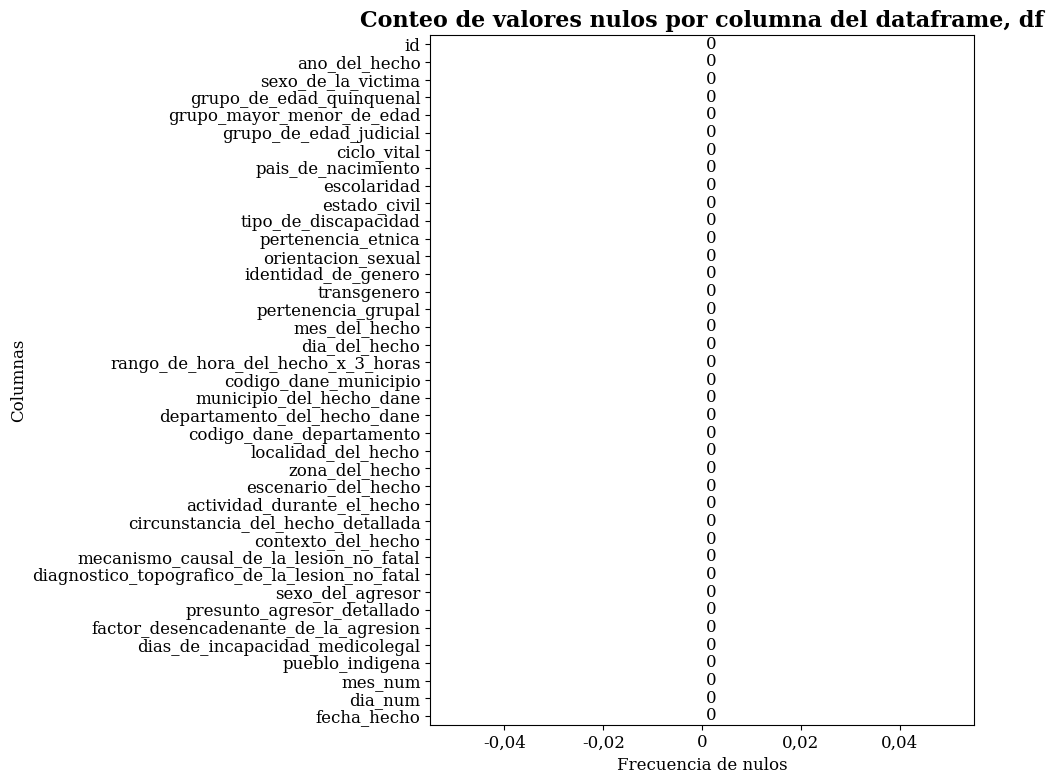

In [ ]:
# Gráfico del Conteo de valores nulos por columna
nulos = df.isnull().sum()

# Crear el gráfico de barras horizontales
ax = nulos.plot(kind='barh', figsize=(10, 8), color='#424345')

# 1. DEFINIR FUNCIÓN INTELIGENTE
def formato_espanol_inteligente(x, p):
    if x == 0:
        return '0'
    if x.is_integer():
        return f'{int(x):,.0f}'.replace(',', '.')
    else:
        return f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

# 2. APLICAR AL EJE X
ax.xaxis.set_major_formatter(ticker.FuncFormatter(formato_espanol_inteligente))

# 3. APLICAR A LAS ETIQUETAS DE LAS BARRAS
etiquetas_ajustadas = []
for valor in nulos.values:
    if valor % 1 == 0:
        # Si es entero (como tus ceros actuales), se ve "0"
        etiquetas_ajustadas.append(f'{int(valor):,.0f}'.replace(',', '.'))
    else:
        # Si tiene decimales, se ve con coma (ej. "1.250,50")
        etiquetas_ajustadas.append(f'{valor:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))

ax.bar_label(ax.containers[0], labels=etiquetas_ajustadas, padding=3)

# 4. TÍTULOS Y AJUSTES FINALES
plt.title('Conteo de valores nulos por columna del dataframe, df', fontsize=16)
plt.xlabel('Frecuencia de nulos', fontsize=12)
plt.ylabel('Columnas', fontsize=12)

plt.gca().invert_yaxis()
plt.tight_layout()

# Guardar el gráfico con alta resolución(300 ppp) y recortar los bordes blancos sobrantes
# Uso del bbox_inches='tight' asegura que los nombres de los ejes y el título no se queden "por fuera" del marco

#Muestra el gráfico
plt.show()

#Introducción
Con respecto al análisis exploratorio realizado, tanto desde la segunda entrega (14 de Diciembre de 2025) (véase el cuaderno de Colab:
https://colab.research.google.com/drive/1QOZDOqX_APQuJCgNV0a3Dt4JaUlYfdSl?usp=sharing
así como, las diferentes recomendaciones realizadas en las asesorías con la Profesora Jimena Muñoz Gómez, se han deducido varias conclusiones que han permito tomar decisiones para la extración de datos y columnas que van a ser relevantes para el entrenamiento del modelo.
Las tres primeras conclusiones relevantes, son presentadas a continuación, con el fin de validar porque la parte del análisis exploratorio presentado aquí, va a la par con el dataset de todos los datos de Colombia (df), así como el regional, correspondiente a Antioquia (df_antioquia).
Asi mismo, en este análisis se evidencia la codificación de limpieza para todas las variables que la hayan requerido.      

#Primera conclusión del análisis exploratorio macro a partir del descenso del 2020 asociado a la Pandemia del COVID-019. (Columna 0. ano_del_hecho)
La aparente disminución en la frecuencia de incidentes observada durante el periodo 2020-2021 no debe interpretarse como una reducción efectiva de la violencia intrafamiliar (VIF), sino que talvez, o podría atribuise, presuntamente, a un sesgo de subregistro derivado de las medidas de confinamiento. Durante este periodo, las barreras institucionales para la denuncia y el control social ejercido por los agresores dentro de los hogares limitaron drásticamente la capacidad de registro del sistema. Esta distorsión en la serie temporal confirma que, la fuente de datos es sensible a los cambios en la movilidad y el control territorial, lo que subraya la importancia de interpretar las series históricas de VIF no solo como hechos ocurridos, sino como eventos reportados bajo condiciones institucionales variables.


: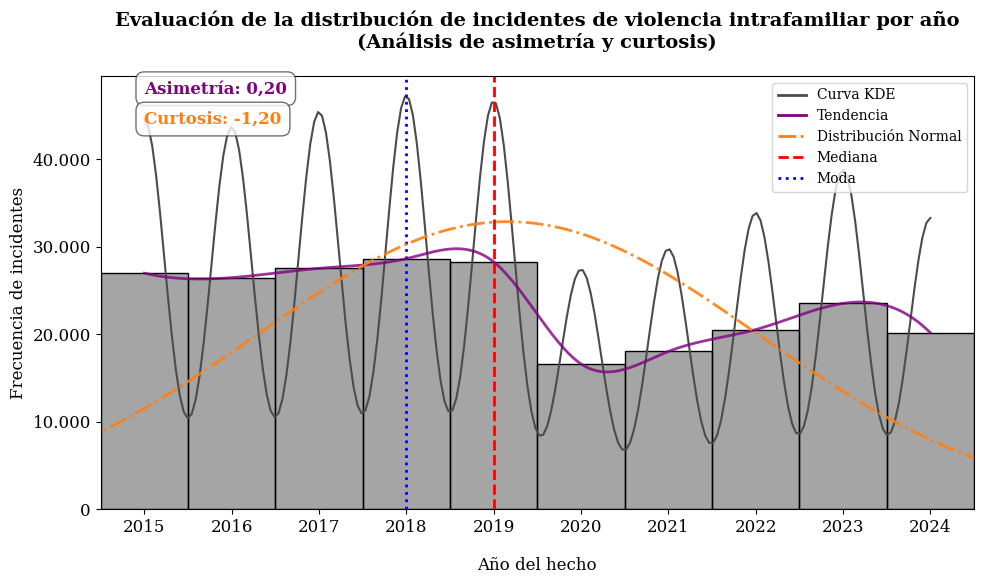

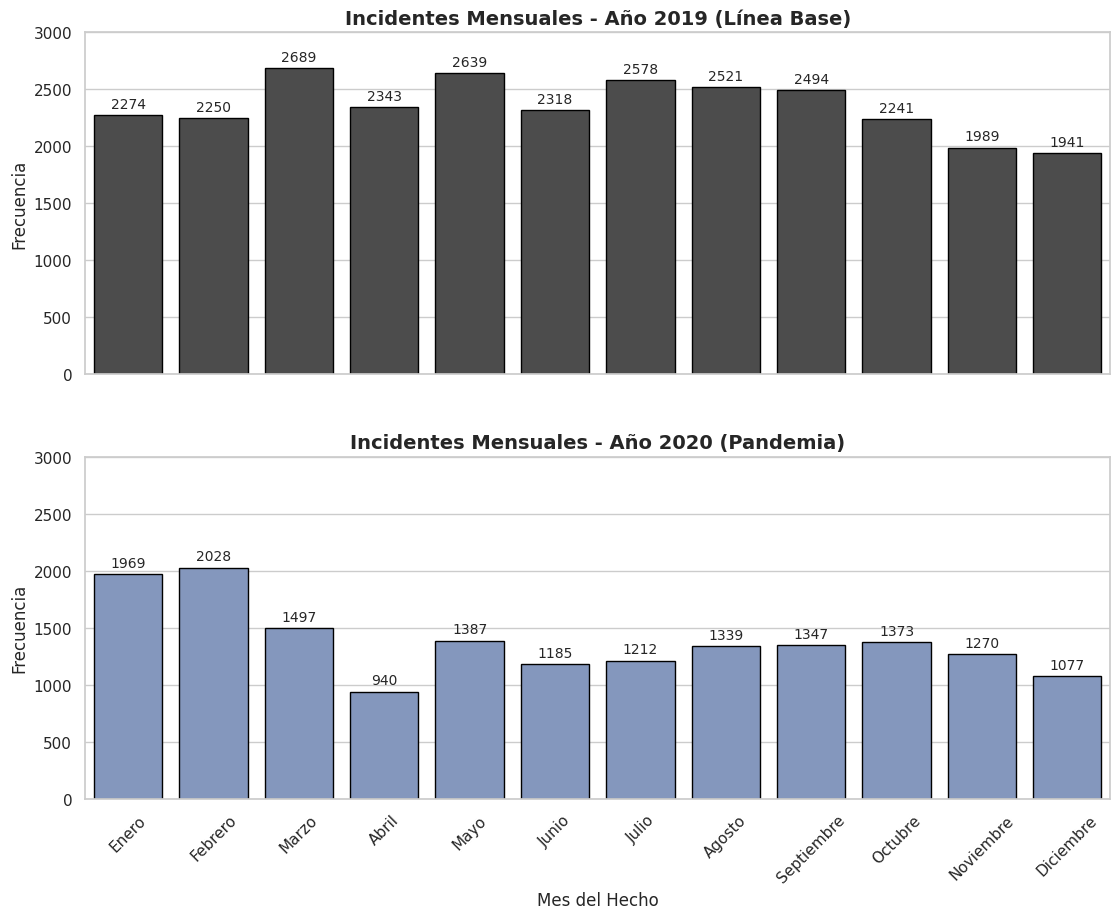

#Segunda conclusión que conlleva al cambio de metodología para no abordar todo el problema de Colombia, sino Regional.

Inicialmente, la propuesta corespondía a presentar, en uno de los objetivos, cuáles de los departamentos presentaban mayor nivel de riesgo a la VIF, bajo un modelo de clasificación multiclase, de tasa indexada de violencia (TIV)  ( bajo (menor a 33% ), medio (34%-66%) y alto (33% superior)). En el estado del arte, esta tasa indexada es presentada como la cantidad de incidentes por cada 100.000 habitantes, pero dado que la ventana de observación es de 10 años, el volumen poblacional es completamente cambiante. A su vez, la premisa de que los departamentos/Municipios que presentan mayor cantidad de incidentes de VIF, son los "más violentos" por decirlo así, es errónea, ya que su alto volumen está asoiado a su respectiva alta densidad poblacional. Por ende, la predicción de la variable objetivo, correspondiente al nivel de riesgo, va a estar limitada a que pueda considerar la injerencia de las otras variables. Por lo tanto, la propuesta para abordar el problema es replanteada para seleccionar una región en específico.

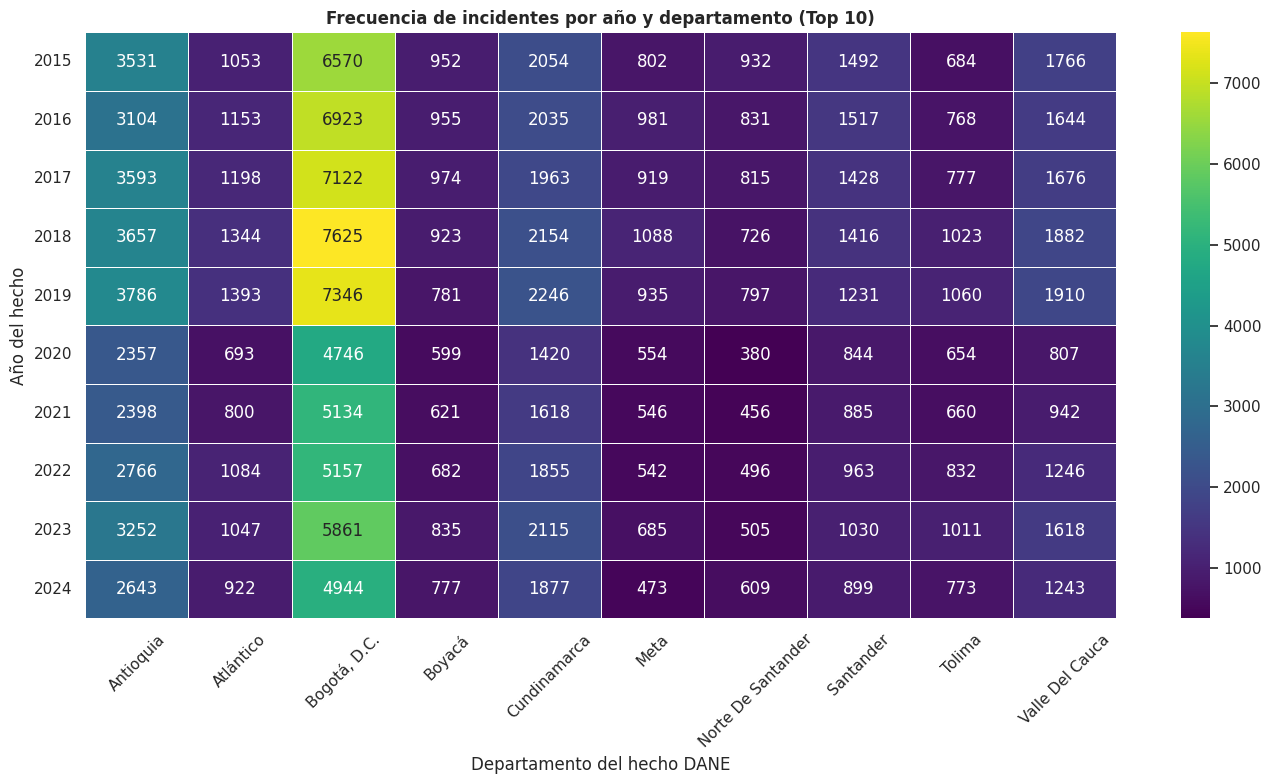

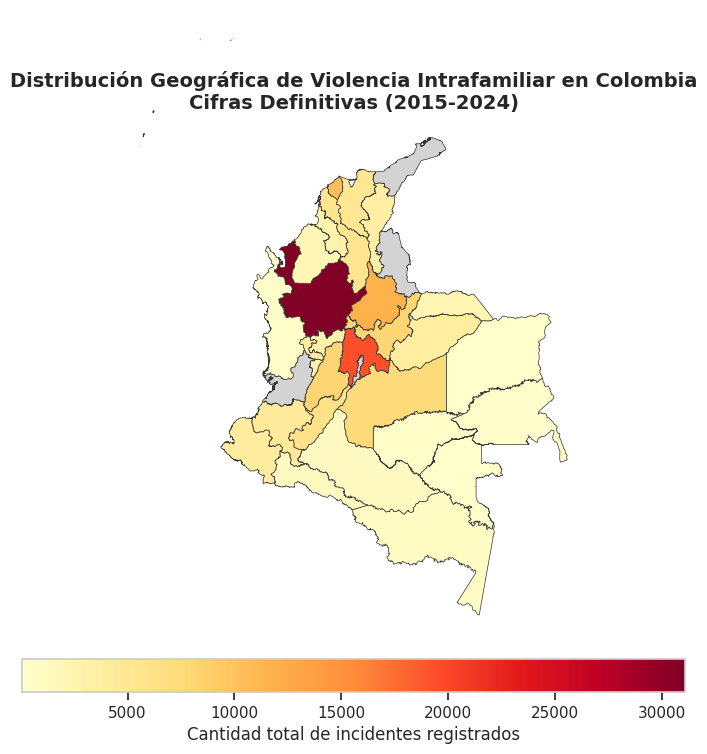

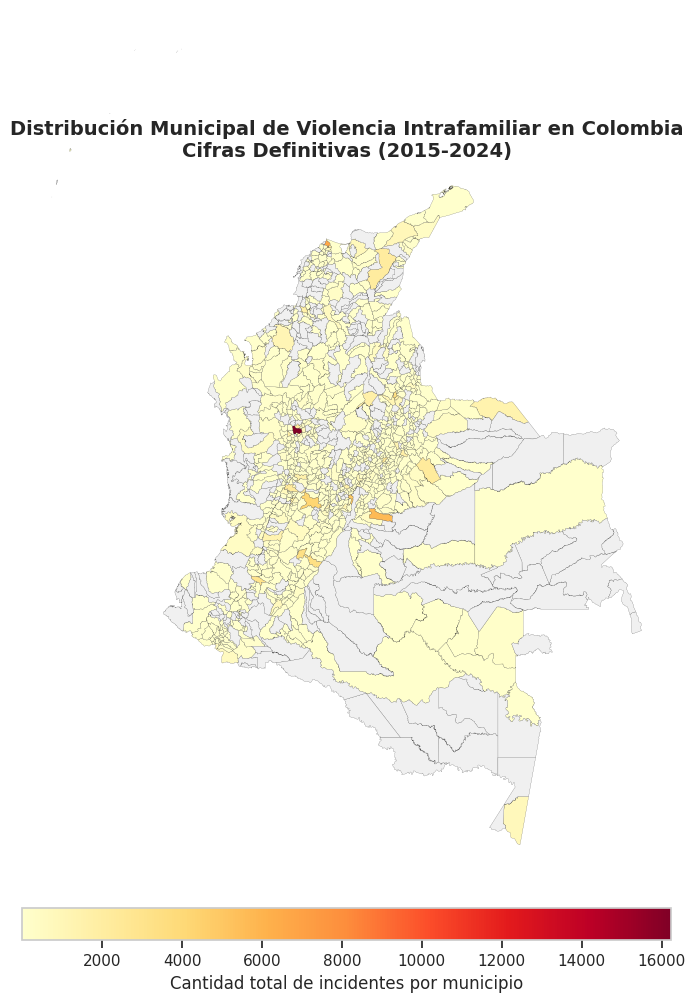

#Tercera conclusión a partir de los gráficos del análisis exploratorio macro que conlleva a la selección del dataset df_antioquia

Inicialmente, es necesario resaltar que, a partir del análisis exploratorio presentado en la segunda entrega (14 de Diciembre de 2025)  la mayor cantidad de registros están asociados a Bogotá, D.C. y a Antioquia. Es por ello que, se han tomado estas regiones en consideración para abordar el problema. Ahora bien, en la exploración de la variable (Columna (24) zona_del_hecho, puede observarse que, al contrastar la distribución de incidentes por zona del hecho entre Antioquia y Bogotá D.C., se evidencia una disparidad estructural en la composición del territorio. Mientras que la capital del país presenta una concentración urbana casi absoluta, Antioquia conserva una proporción significativa de incidentes en zonas rurales.

Por lo tanto, he decidido considerar esta "riqueza" de los datos, para escoger la región de Antioquia. Además, como es la segunda región con mayor cantidad de registros, sigue cumpliendo con una de las consideraciones de este proyecto y es el alto volumen de datos para un modelo Machine Learning (31087 registros para Antioquia).

A su vez, esta diferencia empírica valida la necesidad de aislar el departamento de Antioquia para el entrenamiento del modelo, garantizando que el algoritmo (Random Forest) logre capturar y aprender de las dinámicas de violencia intrafamiliar propias de la ruralidad antioqueña, las cuales quedarían invisibilizadas o sesgadas en un modelo generalizado a nivel nacional.

  


  

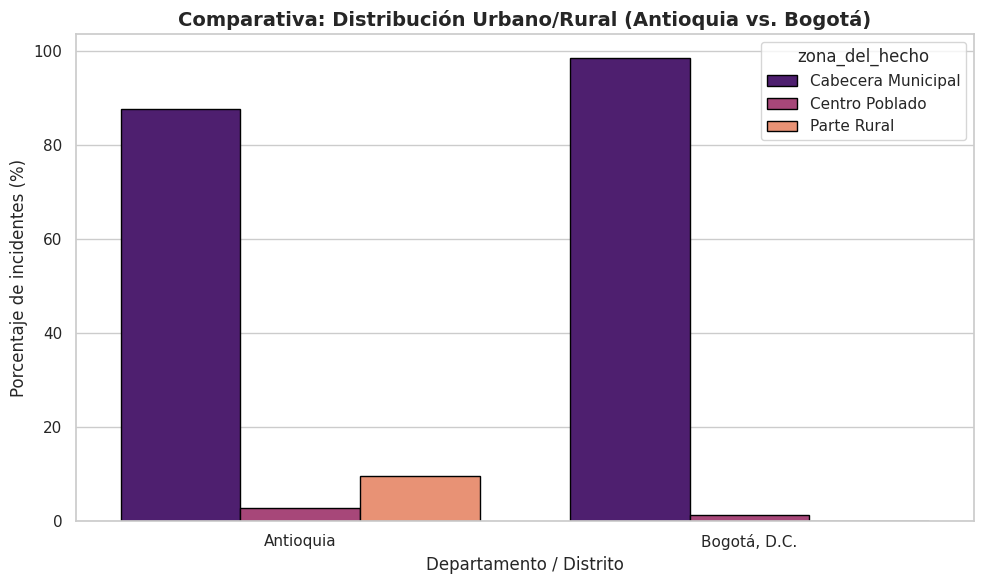

#Carga del Dataframe df_Antioquia

In [ ]:
# Filtramos el DataFrame original para quedarnos exclusivamente con los registros de Antioquia
df_antioquia = df[df['departamento_del_hecho_dane'] == 'antioquia'].copy()

# Verificamos la extracción
print(f"Número de registros para Antioquia: {df_antioquia.shape[0]}")
print(f"Valores únicos en la columna de departamento: {df_antioquia['departamento_del_hecho_dane'].unique()}")

Número de registros para Antioquia: 31087
Valores únicos en la columna de departamento: ['antioquia']


In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

# Limpieza y análisis de los datasets de Colombia (df) y  Antioquia (df_antioquia)

In [ ]:
##Columna (1) 'ano_del_hecho'

# 1. Calculamos los conteos
conteo_colombia = df['ano_del_hecho'].value_counts().rename('Total_Colombia')
conteo_antioquia = df_antioquia['ano_del_hecho'].value_counts().rename('Total_Antioquia')

# 2. Unimos, rellenamos vacíos y ordenamos cronológicamente
tabla_comparativa = pd.concat([conteo_colombia, conteo_antioquia], axis=1)
tabla_comparativa = tabla_comparativa.fillna(0).astype(int)
tabla_comparativa = tabla_comparativa.sort_index()

# 3. NUEVO: Calculamos el porcentaje (Casos Antioquia / Casos Colombia * 100)
tabla_comparativa['%_Antioquia_vs_Colombia'] = (tabla_comparativa['Total_Antioquia'] / tabla_comparativa['Total_Colombia']) * 100

# 4. Mostramos la tabla con un formato elegante (miles separados por comas y % con 2 decimales)
tabla_comparativa.style.format({
    'Total_Colombia': '{:,}',
    'Total_Antioquia': '{:,}',
    '%_Antioquia_vs_Colombia': '{:.2f}%'
})

,Total_Colombia,Total_Antioquia,%_Antioquia_vs_Colombia
ano_del_hecho,,,
2015,"26,985","3,531",13.09%
2016,"26,473","3,104",11.73%
2017,"27,538","3,593",13.05%
2018,"28,645","3,657",12.77%
2019,"28,277","3,786",13.39%
2020,"16,624","2,357",14.18%
2021,"18,043","2,398",13.29%
2022,"20,541","2,766",13.47%
2023,"23,529","3,252",13.82%


In [ ]:
##Columna (1) 'ano_del_hecho'
#Resumen estadístico de la columna (1) ano_del_hecho con formato
import pandas as pd

# 1. Calcular el resumen estadístico original para ambos DataFrames
desc_col = df['ano_del_hecho'].describe()
desc_ant = df_antioquia['ano_del_hecho'].describe()

# 2. Aplicar tu formato a los datos de Colombia y nombrarlo
formato_colombia = pd.Series({
    'count': int(desc_col['count']),
    'mean': round(desc_col['mean'], 2),
    'std': round(desc_col['std'], 2),
    'min': int(desc_col['min']),
    '25%': int(desc_col['25%']),
    '50%': int(desc_col['50%']),
    '75%': int(desc_col['75%']),
    'max': int(desc_col['max'])
}, name='Total_Colombia')

# 3. Aplicar tu formato a los datos de Antioquia y nombrarlo
formato_antioquia = pd.Series({
    'count': int(desc_ant['count']),
    'mean': round(desc_ant['mean'], 2),
    'std': round(desc_ant['std'], 2),
    'min': int(desc_ant['min']),
    '25%': int(desc_ant['25%']),
    '50%': int(desc_ant['50%']),
    '75%': int(desc_ant['75%']),
    'max': int(desc_ant['max'])
}, name='Total_Antioquia')

# 4. Unir ambas series en una sola tabla comparativa
tabla_estadisticas = pd.concat([formato_colombia, formato_antioquia], axis=1)

# 5. Mostrar la tabla final
tabla_estadisticas

,Total_Colombia,Total_Antioquia
count,236840.00,31087.00
mean,2019.16,2019.24
std,2.87,2.87
min,2015.00,2015.00
25%,2017.00,2017.00
50%,2019.00,2019.00
75%,2022.00,2022.00
max,2024.00,2024.00


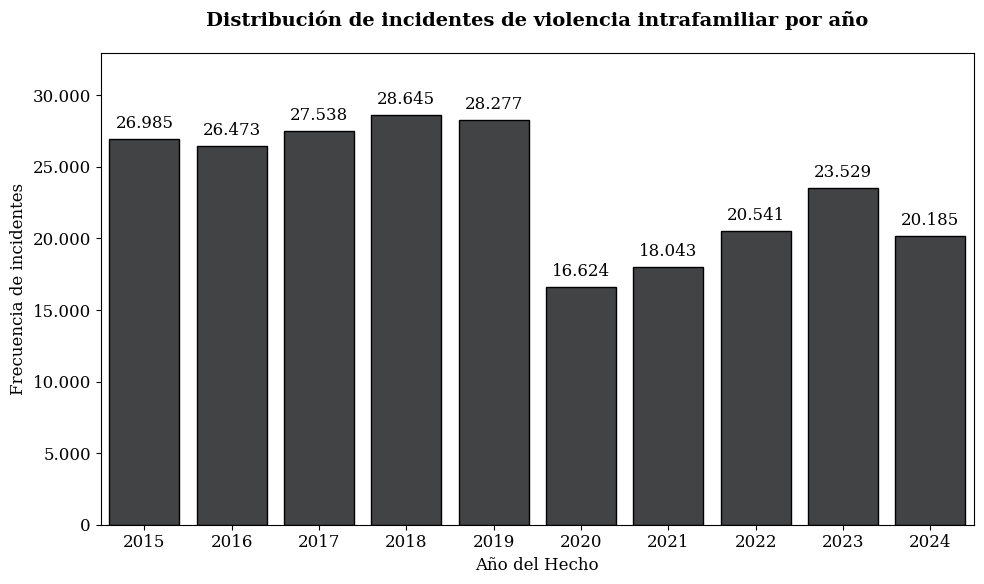

In [ ]:
##Columna (1) 'ano_del_hecho'
#Gráfico de frecuencia de incidentes de la columna (1) ano_del_hecho
#Tamaño del gráfico
plt.figure(figsize=(10, 6))

conteo_anos = df['ano_del_hecho'].value_counts().sort_index()

ax = sns.barplot(x=conteo_anos.index, y=conteo_anos.values, color="#424345", edgecolor='black')

# Formateo único de etiquetas
etiquetas_formateadas = [f'{v:,.0f}'.replace(',', '.') for v in conteo_anos.values]
ax.bar_label(ax.containers[0], labels=etiquetas_formateadas, padding=5, fontweight='normal')

# Ajustes de ejes
ax.set_ylim(0, conteo_anos.max() * 1.15)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{int(x):,.0f}'.replace(',', '.')))

# Títulos y etiquetas
plt.title('Distribución de incidentes de violencia intrafamiliar por año', pad=20, fontsize=14)
plt.xlabel('Año del Hecho', fontsize=12)
plt.ylabel('Frecuencia de incidentes', fontsize=12)

plt.tight_layout() # Recomendado para evitar que el título se corte
plt.show()

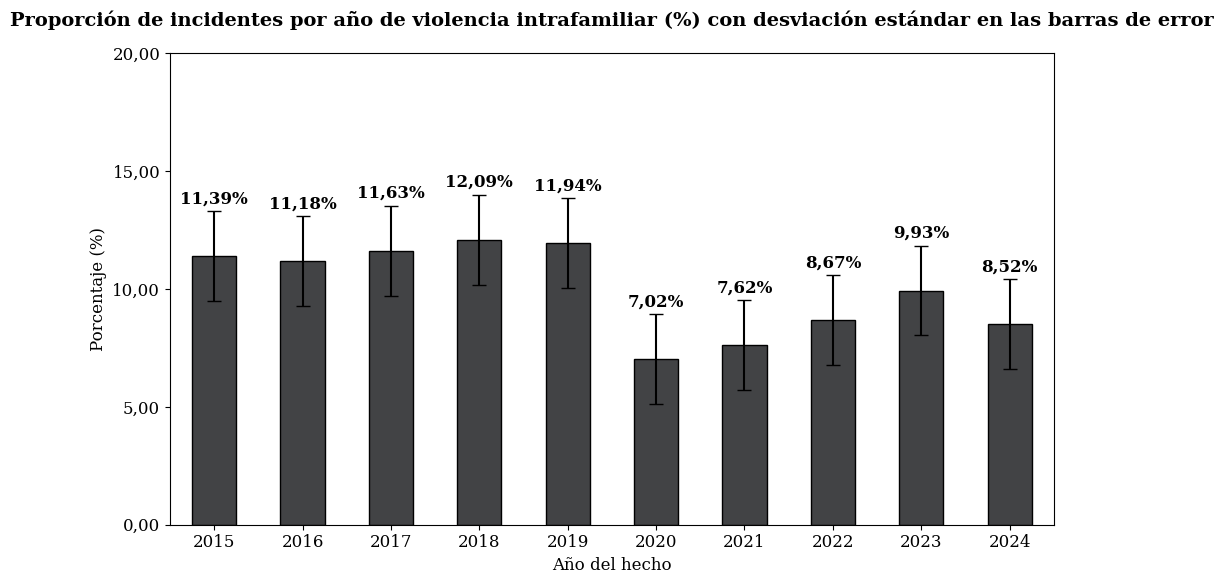

In [ ]:
##Columna (1) 'ano_del_hecho'
# Proporciones en % de valores únicos de la columna (1) ano_del_hecho
#Proporciones es igual la frecuencia del valor dividido por el total de registros, multiplicado por 100 para obtener el %

# 1. Preparación de datos
proporciones = df['ano_del_hecho'].value_counts(normalize=True).sort_index() * 100
std_proporciones = proporciones.std()

fig, ax = plt.subplots(figsize=(10, 6))

# Inserción de barras
proporciones.plot(kind='bar', color="#424345", ax=ax, edgecolor='black')

# Barras de error con yerr
ax.errorbar(x=range(len(proporciones)),
            y=proporciones,
            yerr=std_proporciones,
            fmt='none',
            ecolor='black',
            capsize=5,
            linewidth=1.5)

# Formato del eje y
# En el formato decimal, para que la coma sea visible en el eje Y
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:.2f}'.replace('.', ',')))

# Etiquetas sobre las barras
etiquetas_porcent = [f'{v:.2f}%'.replace('.', ',') for v in proporciones.values]
ax.bar_label(ax.containers[0], labels=etiquetas_porcent, padding=35, fontweight='bold')

# 4. Títulos y ajustes finales
plt.title('Proporción de incidentes por año de violencia intrafamiliar (%) con desviación estándar en las barras de error', fontsize=14, pad=20)
plt.xlabel('Año del hecho', fontsize=12)
plt.ylabel('Porcentaje (%)', fontsize=12)

# Ajuste de límites y marcas
plt.ylim(0, proporciones.max() + std_proporciones + 5)
plt.yticks([0, 5, 10, 15, 20]) # Los números aquí son floats internamente
plt.xticks(rotation=0)

# Guardar el gráfico con alta resolución(300 ppp) y recortar los bordes blancos sobrantes
# Uso del bbox_inches='tight' asegura que los nombres de los ejes y el título no se queden "por fuera" del marco

#Muestra el gráfico
plt.show()

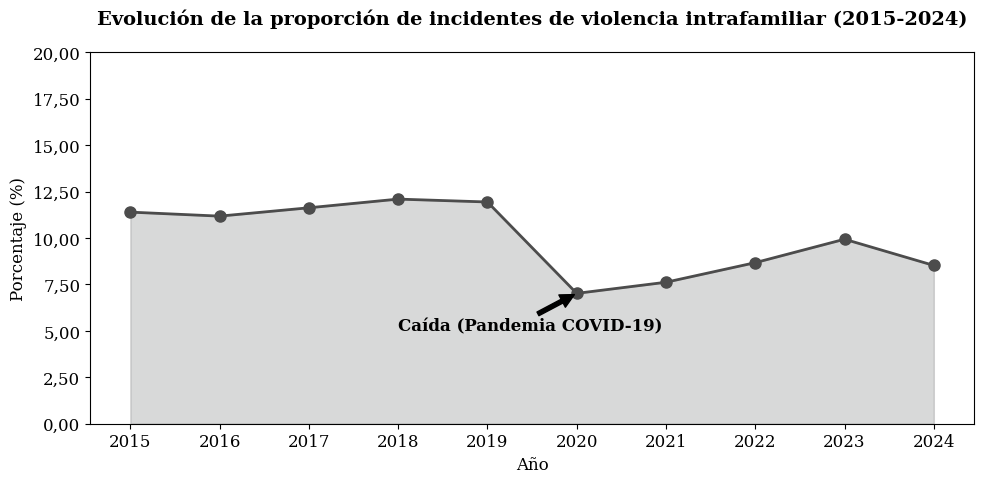

In [ ]:
##Columna (1) 'ano_del_hecho'
#Gráfico de Evolución de la proporción de incidentes por año (2015-2024)
# Preparación de los datos (ordenados cronológicamente)
proporciones = df['ano_del_hecho'].value_counts(normalize=True).sort_index() * 100

# Configuración del gráfico de líneas
plt.figure(figsize=(10, 5))

# Inserción de la línea con marcadores en cada año
plt.plot(proporciones.index, proporciones.values,
         marker='o', linestyle='-', color='#4c4c4c', linewidth=2, markersize=8)

# Relleno del área por debajo de la línea
plt.fill_between(proporciones.index, proporciones.values, color="#404143", alpha=0.2)

# Formato Ejes
ax = plt.gca()
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:.2f}'.replace('.', ',')))
ax.set_yticks([0, 2.5, 5, 7.5, 10, 12.5, 15, 17.5, 20])

# Formato del texto y de la flecha en la anotación
plt.annotate('Caída (Pandemia COVID-19)',
             xy=(2020, proporciones[2020]),
             xytext=(2018, 5),
             fontsize=12,
             fontweight='bold',
             arrowprops=dict(
                 facecolor='black',
                 edgecolor='black',
                 shrink=0.05,
                 width=3,
                 headwidth=10,
                 headlength=10
            ))

# Títulos y ajustes finales
plt.title('Evolución de la proporción de incidentes de violencia intrafamiliar (2015-2024)', fontsize=14, pad=20)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xlabel('Año', fontsize=12)
plt.ylim(0, 20)
plt.xticks(proporciones.index) # Asegura que salgan todos los años

plt.tight_layout()

# Guardar el gráfico con alta resolución(300 ppp) y recortar los bordes blancos sobrantes
# Uso del bbox_inches='tight' asegura que los nombres de los ejes y el título no se queden "por fuera" del marco

#Muestra el gráfico
plt.show()

In [ ]:
##Columna (1) 'ano_del_hecho'
# Otros estadísticos para la columna (1) ano_del_hecho
# Calcular y mostrar la mediana
median_year = df['ano_del_hecho'].median()
print(f"Mediana de la columna 'ano_del_hecho': {int(median_year)}")

# Calcular y mostrar la moda (puede haber más de una si tienen la misma frecuencia)
mode_year = df['ano_del_hecho'].mode()
print(f"Moda de la columna 'ano_del_hecho': {mode_year.tolist()}")

# Calcular y mostrar la asimetría
# Mide el grado de inclinación o asimetría de la distribución de los datos.
 # Una asimetría positiva indica una cola más larga hacia la derecha
 # (más incidentes en años más recientes), y una asimetría negativa
 # indica una cola más larga hacia la izquierda (más incidentes en años más antiguos).
skewness_year = df['ano_del_hecho'].skew()
print(f"Asimetría de la columna 'ano_del_hecho': {skewness_year:.2f}")

# Calcular y mostrar la curtosis
#Curtosis (Kurtosis): Mide qué tan pronunciada es la forma de la distribución,
  # es decir, qué tan "picuda" o "plana" es la distribución en comparación con una
  # distribución normal. Un valor alto podría indicar más valores extremos
  # (años con picos o valles muy marcados de incidentes).

kurtosis_year = df['ano_del_hecho'].kurt()
print(f"Curtosis de la columna 'ano_del_hecho': {kurtosis_year:.2f}")

Mediana de la columna 'ano_del_hecho': 2019
Moda de la columna 'ano_del_hecho': [2018]
Asimetría de la columna 'ano_del_hecho': 0.20
Curtosis de la columna 'ano_del_hecho': -1.20


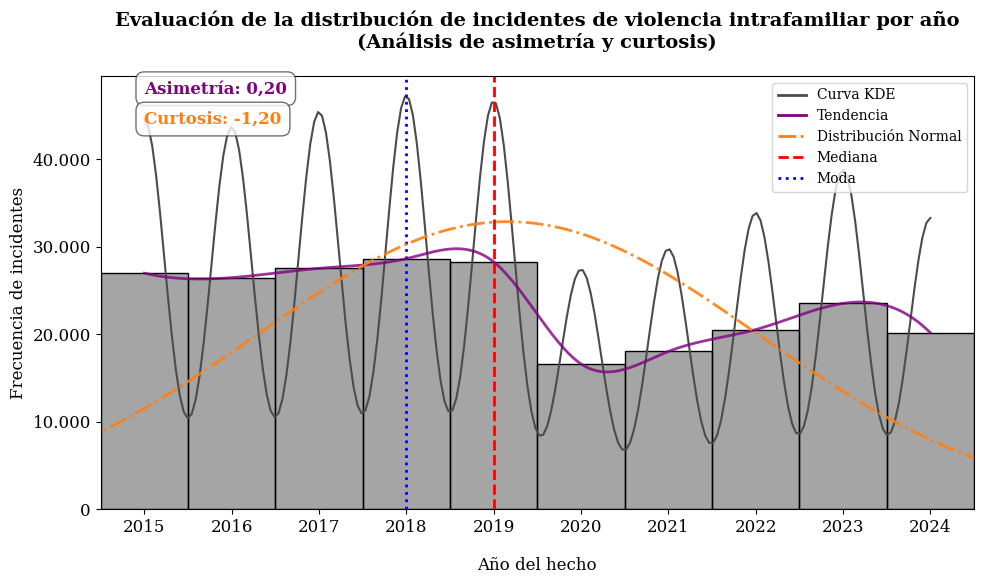

In [ ]:
##Columna (1) 'ano_del_hecho'
#Histograma con curva de densidad, KDE; para la columna (1) ano_del_hecho
plt.figure(figsize=(10, 6))

# Histograma con curva de función de densidad de probabilidad (Kernel Density Estimation, KDE) para la columna 'ano_del_hecho'
# Con discrete=True, Seaborn trata la variable año_del_hecho como una categoría individual (DATOS DISCRETOS) y no como una escala continua
# lo que ayuda mucho a que el centrado de la etiqueta de cada año sea automático
ax = sns.histplot(df['ano_del_hecho'],
                  kde=True,
                  discrete=True,
                  color="#4c4c4c",
                  edgecolor='black',
                  bins=len(df['ano_del_hecho'].unique()),
                  )

# Añadir líneas verticales para Mediana y Moda
plt.axvline(median_year, color='red', linestyle='--', linewidth=2)
plt.axvline(mode_year[0], color='blue', linestyle=':', linewidth=2)

# Formato de ejes (Coma decimal)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))
# Si el eje X necesita decimales (aunque sean años), usaríamos:
# ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:g}'.replace('.', ',')))

# Cuadro de texto con los estadísticos (Asimetría y Curtosis)
texto_asimetria = f'Asimetría: {skewness_year:.2f}'.replace('.', ',')
texto_curtosis = f'Curtosis: {kurtosis_year:.2f}'.replace('.', ',')

# Formato de línea del cuadro de texto
props = dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8, edgecolor='#4c4c4c')

# Línea de Asimetría (Morada)
plt.text(0.05, 0.99, texto_asimetria, transform=ax.transAxes, fontsize=12,
         color='purple', fontweight='bold', fontfamily='serif',
         verticalalignment='top', bbox=props)

# Línea de Curtosis (Naranja) - La bajamos un poco (0.92) para que no se superpongan
plt.text(0.05, 0.92, texto_curtosis, transform=ax.transAxes, fontsize=12,
         color='#ff7f0e', fontweight='bold', fontfamily='serif', # Naranja estándar de Matplotlib
         verticalalignment='top', bbox=props)

# Definición de los años de forma cronológica
años = sorted(df['ano_del_hecho'].unique())

# La línea envolvente (tendencia) es una INTERPOLACIÓN
#Obtención de los puntos máximos de la KDE para la línea envolvente
from scipy.interpolate import make_interp_spline
frecuencias = [len(df[df['ano_del_hecho'] == a]) for a in años]
# Suavizado de la curva (Interpolación Spline)
# Esto crea una curva suave que pasa por los puntos máximos
x_new = np.linspace(min(años), max(años), 300)
spl = make_interp_spline(años, frecuencias, k=3)
y_smooth = spl(x_new)

# Dibujar la envolvente de color morado
plt.plot(x_new, y_smooth, color='purple', linewidth=2, label='Tendencia de picos', alpha=0.8)

#Creación de la curva de distribución normal para reforzar la explicación de la curtosis
from scipy.stats import norm
# Parámetros para la curva normal teórica (media y desviación estándar de tus datos)
mu = df['ano_del_hecho'].mean()
sigma = df['ano_del_hecho'].std()

# Creación de los puntos para la curva normal
x_norm = np.linspace(min(años) - 1, max(años) + 1, 300)
y_norm = norm.pdf(x_norm, mu, sigma)

# Escalar la curva normal para que coincida con la escala de frecuencia de tu histograma
# Multiplicamos por el número total de registros para que las alturas sean comparables
y_norm_scaled = y_norm * len(df['ano_del_hecho']) * 1.0 # El factor 1.0 es el ancho de barra

# Dibujar la curva normal en naranja
plt.plot(x_norm, y_norm_scaled, color='#ff7f0e', linestyle='-.', linewidth=2,
         label='Distribución Normal', alpha=0.9)

# Creación de objetos visuales personalizados para la leyenda
# importación de Line2D para la línea envolvente
from matplotlib.lines import Line2D
leyenda_elementos = [
    Line2D([0], [0], color='#4c4c4c', lw=2, label='Curva KDE'), # Línea negra para KDE
    Line2D([0], [0], color='purple', lw=2, label='Tendencia'), # Línea evolvente morada
    Line2D([0], [0], color='#ff7f0e', lw=2, linestyle='-.', label='Distribución Normal'), # Línea de distribución normal en naranja
    Line2D([0], [0], color='red', lw=2, linestyle='--', label=f'Mediana'), # Línea de la mediana en rojo
    Line2D([0], [0], color='blue', lw=2, linestyle=':', label=f'Moda') # Línea de la moda en azul
]

# Configuramos las marcas y las etiquetas
ax.set_xticks(años)
ax.set_xticklabels(años, fontfamily='serif', fontsize=12)

# Opcional: Si quieres que el eje X no tenga decimales (por si acaso Matplotlib intenta introducirlos)
ax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))

# Títulos y etiquetas
plt.title('Evaluación de la distribución de incidentes de violencia intrafamiliar por año\n(Análisis de asimetría y curtosis)', fontsize=14, pad=20)
plt.xlabel('Año del hecho', fontsize=12, labelpad=15)
plt.xlim(min(años) - 0.5, max(años) + 0.5)
plt.xticks(rotation=0)
plt.ylabel('Frecuencia de incidentes', fontsize=12)
plt.legend(handles=leyenda_elementos, loc='upper right', frameon=True, fontsize=10)

# Guardar y mostrar
plt.savefig('05_distribucion_asimetria_curtosis.png', dpi=300, bbox_inches='tight')
plt.show()

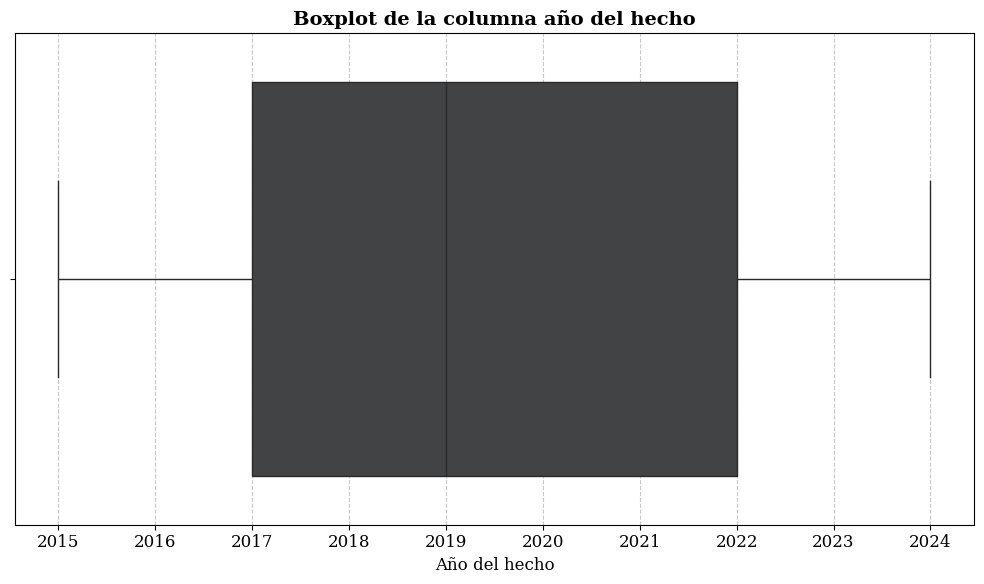

In [ ]:
##Boxplot para la columna (1) ano_del_hecho
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['ano_del_hecho'], color="#424345")
plt.title('Boxplot de la columna año del hecho')
plt.xlabel('Año del hecho')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.xticks(sorted(df['ano_del_hecho'].unique().astype(int)), rotation=0)

# Guardar el gráfico con alta resolución(300 ppp) y recortar los bordes blancos sobrantes
# Uso del bbox_inches='tight' asegura que los nombres de los ejes y el título no se queden "por fuera" del marco
plt.savefig('06_boxplot_ano_hecho.png', dpi=300, bbox_inches='tight')

#Muestra el gráfico
plt.show()

In [ ]:
##Rango Intercuartílico (IQR): Detecta valores fuera de (Q1-1.5 x IQR) y (Q3+1.5 x IQR) para la columna (1) año_del_hecho
Q1 = df['ano_del_hecho'].quantile(0.25)
Q3 = df['ano_del_hecho'].quantile(0.75)
IQR = Q3 - Q1
umbral_superior = Q3 + 1.5 * IQR
umbral_inferior = Q1 - 1.5 * IQR
outliers = df[(df['ano_del_hecho'] > umbral_superior) | (df['ano_del_hecho'] < umbral_inferior)]
display(outliers)

,id,ano_del_hecho,sexo_de_la_victima,grupo_de_edad_quinquenal,grupo_mayor_menor_de_edad,grupo_de_edad_judicial,ciclo_vital,pais_de_nacimiento,escolaridad,estado_civil,...,mecanismo_causal_de_la_lesion_no_fatal,diagnostico_topografico_de_la_lesion_no_fatal,sexo_del_agresor,presunto_agresor_detallado,factor_desencadenante_de_la_agresion,dias_de_incapacidad_medicolegal,pueblo_indigena,mes_num,dia_num,fecha_hecho


In [ ]:
##Columna (1) 'ano_del_hecho'
#Importación de la librería
from scipy.stats import zscore

# Z-Score Referencia (https://www.geeksforgeeks.org/machine-learning/z-score-for-outlier-detection-python/)
# "It helps us to identify if a data point is relatively higher or lower than the mean and how far it deviates from the average value"

df['Z-score'] = stats.zscore(df['ano_del_hecho'])
print(df['Z-score'])

0        -1.447637
1        -1.447637
2        -1.447637
3        -1.447637
4        -1.447637
            ...   
236835    1.683001
236836    1.683001
236837    1.683001
236838    1.683001
236839    1.683001
Name: Z-score, Length: 236840, dtype: float64


In [ ]:
##Columna (1) 'ano_del_hecho'
#Identifying Outliers Referencia (https://www.geeksforgeeks.org/machine-learning/z-score-for-outlier-detection-python/)
#Next, we'll identify the data points that have a Z-score greater than 3 or less than -3 which are commonly considered outliers
outliers = df[df['Z-score'].abs() > 3]
print(outliers)

Empty DataFrame
Columns: [id, ano_del_hecho, sexo_de_la_victima, grupo_de_edad_quinquenal, grupo_mayor_menor_de_edad, grupo_de_edad_judicial, ciclo_vital, pais_de_nacimiento, escolaridad, estado_civil, tipo_de_discapacidad, pertenencia_etnica, orientacion_sexual, identidad_de_genero, transgenero, pertenencia_grupal, mes_del_hecho, dia_del_hecho, rango_de_hora_del_hecho_x_3_horas, codigo_dane_municipio, municipio_del_hecho_dane, departamento_del_hecho_dane, codigo_dane_departamento, localidad_del_hecho, zona_del_hecho, escenario_del_hecho, actividad_durante_el_hecho, circunstancia_del_hecho_detallada, contexto_del_hecho, mecanismo_causal_de_la_lesion_no_fatal, diagnostico_topografico_de_la_lesion_no_fatal, sexo_del_agresor, presunto_agresor_detallado, factor_desencadenante_de_la_agresion, dias_de_incapacidad_medicolegal, pueblo_indigena, mes_num, dia_num, fecha_hecho, Z-score]
Index: []

[0 rows x 40 columns]


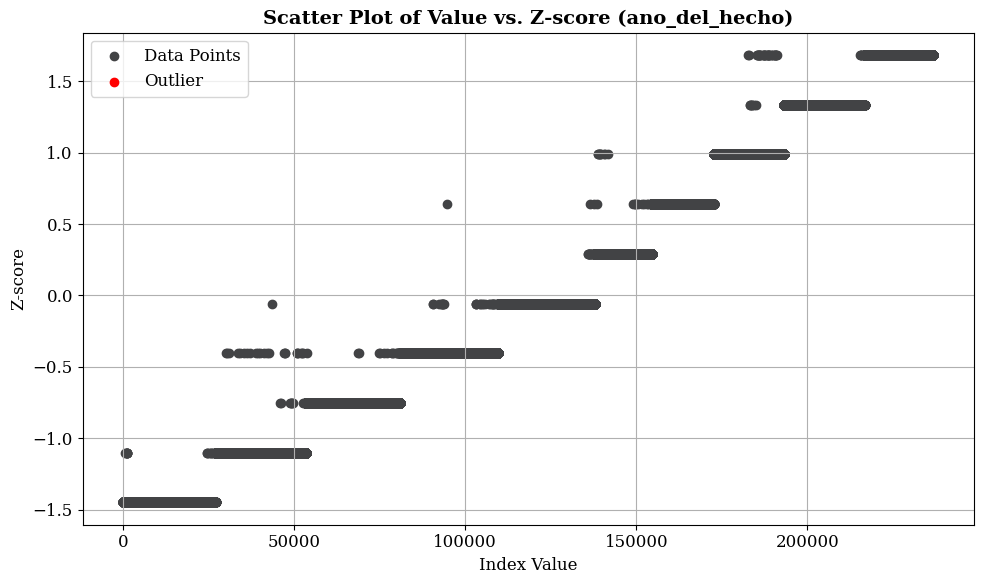

In [ ]:
##Columna (1) 'ano_del_hecho'
#To better understand the outliers, let’s create a scatter plot to visualize the dataset and highlight the outliers
# Referencia (https://www.geeksforgeeks.org/machine-learning/z-score-for-outlier-detection-python/)
plt.figure(figsize=(10, 6))
plt.scatter(df['ano_del_hecho'].index, df['Z-score'], color="#424345",label='Data Points')
plt.scatter(outliers['ano_del_hecho'].index, outliers['Z-score'], color='red', label='Outlier')
plt.xlabel('Index Value')
plt.ylabel('Z-score')
plt.title("Scatter Plot of Value vs. Z-score (ano_del_hecho)")
plt.legend()
plt.grid(True)

# Guardar el gráfico con alta resolución(300 ppp) y recortar los bordes blancos sobrantes
# Uso del bbox_inches='tight' asegura que los nombres de los ejes y el título no se queden "por fuera" del marco
plt.savefig('07_scatterplot_zscore.png', dpi=300, bbox_inches='tight')

#Muestra el gráfico
plt.show()

In [ ]:
##Columna (2) 'sexo_de_la_victima'

# Define la columna que quieres analizar para no repetir código
columna = 'sexo_de_la_victima'

# 1. Cálculos para Colombia (Conteos absolutos y Porcentajes relativos)
conteo_col = df[columna].value_counts().rename('Total_Colombia')
porc_col = (df[columna].value_counts(normalize=True) * 100).round(2).rename('%_Colombia')

# 2. Cálculos para Antioquia (Conteos absolutos y Porcentajes relativos)
conteo_ant = df_antioquia[columna].value_counts().rename('Total_Antioquia')
porc_ant = (df_antioquia[columna].value_counts(normalize=True) * 100).round(2).rename('%_Antioquia')

# 3. Unir todo en el orden exacto que queremos leerlo de izquierda a derecha
tabla_comparativa = pd.concat([conteo_col, porc_col, conteo_ant, porc_ant], axis=1)

# 4. Manejo de posibles nulos (si una categoría existe en un lado y en otro no)
tabla_comparativa = tabla_comparativa.fillna(0)

# 5. Restaurar el formato entero solo para las columnas de totales absolutos
tabla_comparativa['Total_Colombia'] = tabla_comparativa['Total_Colombia'].astype(int)
tabla_comparativa['Total_Antioquia'] = tabla_comparativa['Total_Antioquia'].astype(int)

# 6. Mostrar la tabla final
tabla_comparativa

,Total_Colombia,%_Colombia,Total_Antioquia,%_Antioquia
sexo_de_la_victima,,,,
mujer,140682,59.4,18893,60.77
hombre,96158,40.6,12194,39.23


/tmp/ipykernel_193/3186733201.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([label.get_text().capitalize() for label in ax.get_xticklabels()])


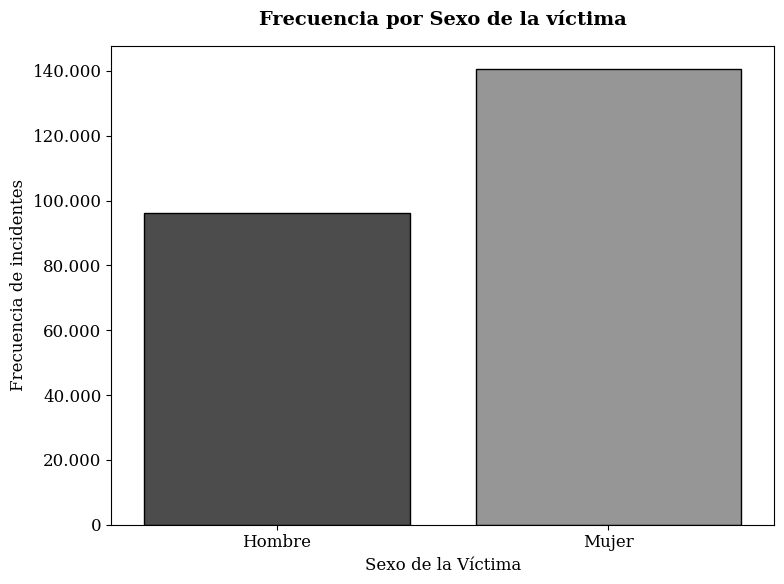

In [ ]:
##Columna (2) 'sexo_de_la_victima'
# Gráfico de la frecuencia de la columna columna (2) 'sexo_de_la_victima'

plt.figure(figsize=(8, 6))

# Paleta de grises
colores_gris = ["#4c4c4c", "#969696"]

#Creación del gráfico
ax=sns.countplot(x='sexo_de_la_victima', data=df, palette=colores_gris, hue='sexo_de_la_victima', legend=False, edgecolor="black")

#Capitalizar etiquetas del eje X
# Esto toma las etiquetas actuales ('hombre', 'mujer') y las pone como ('Hombre', 'Mujer')
ax.set_xticklabels([label.get_text().capitalize() for label in ax.get_xticklabels()])

# Formato del eje Y (Punto para los miles)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# Títulos y etiquetas
plt.title('Frecuencia por Sexo de la víctima', fontsize=14, pad=15)
plt.xlabel('Sexo de la Víctima', fontsize=12)
plt.ylabel('Frecuencia de incidentes', fontsize=12)

# Ajuste final y guardado
plt.tight_layout()
plt.show()

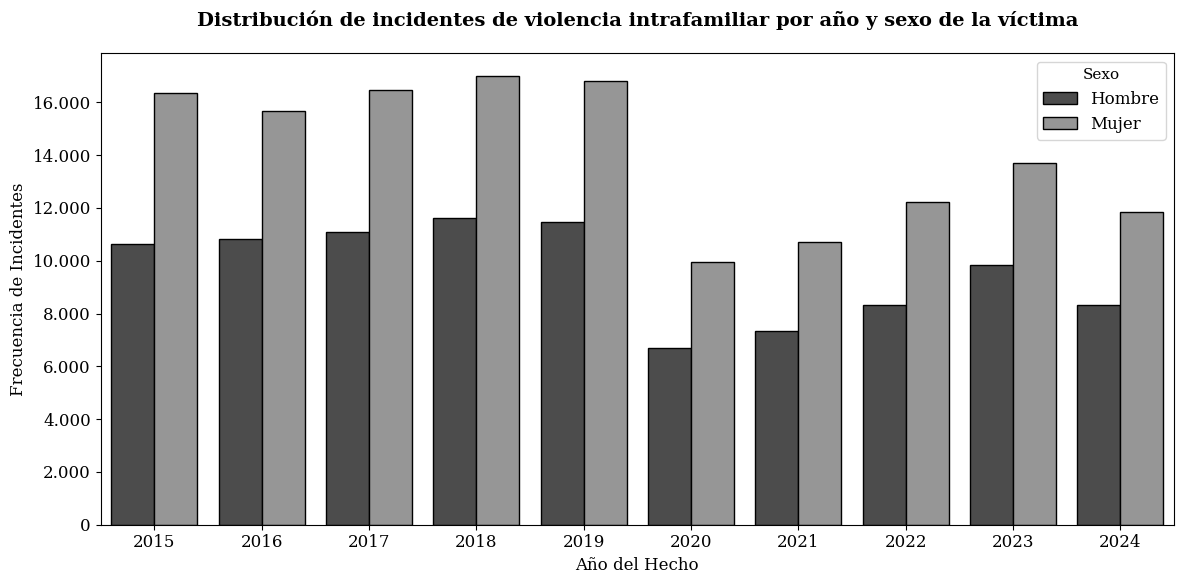

In [ ]:
##Columna (2) 'sexo_de_la_victima'
# Gráfico comparativo de la distribución anual de incidentes por sexo de la víctima
plt.figure(figsize=(12, 6))

# 2. Creación del gráfico agrupado
# 'hue' es la clave aquí: divide las barras por sexo dentro de cada año
ax = sns.countplot(data=df, x='ano_del_hecho', hue='sexo_de_la_victima',
                   palette=['#4c4c4c', '#969696'], edgecolor='black')

# 3. Formato del eje Y (Punto para los miles)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 4. Títulos y etiquetas
plt.title('Distribución de incidentes de violencia intrafamiliar por año y sexo de la víctima', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Año del Hecho', fontsize=12)
plt.ylabel('Frecuencia de Incidentes', fontsize=12)

# 5. Ajuste de la Leyenda
# Capitalizamos los textos de la leyenda manualmente
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [label.capitalize() for label in labels], title='Sexo', title_fontsize='11')

# 6. Ajuste final y guardado
plt.tight_layout()
plt.show()

In [ ]:
##Columna (2) 'sexo_de_la_victima'
#Resumen estadístico de la columna (2) 'sexo_de_la_victima'
display(df['sexo_de_la_victima'].describe())

,sexo_de_la_victima
count,236840
unique,2
top,mujer
freq,140682


In [ ]:
##Columna (3) 'grupo_de_edad_quinquenal'
display(df['grupo_de_edad_quinquenal'].value_counts(dropna=False))
df['grupo_de_edad_quinquenal'].value_counts()

,count
grupo_de_edad_quinquenal,
(10 a 14),29172
(20 a 24),21434
(05 a 09),20827
(15 a 17),19599
(25 a 29),19551
(30 a 34),16899
(35 a 39),14940
(40 a 44),13506
(50 a 54),13136


,count
grupo_de_edad_quinquenal,
(10 a 14),29172
(20 a 24),21434
(05 a 09),20827
(15 a 17),19599
(25 a 29),19551
(30 a 34),16899
(35 a 39),14940
(40 a 44),13506
(50 a 54),13136


/tmp/ipykernel_193/3368953309.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df,


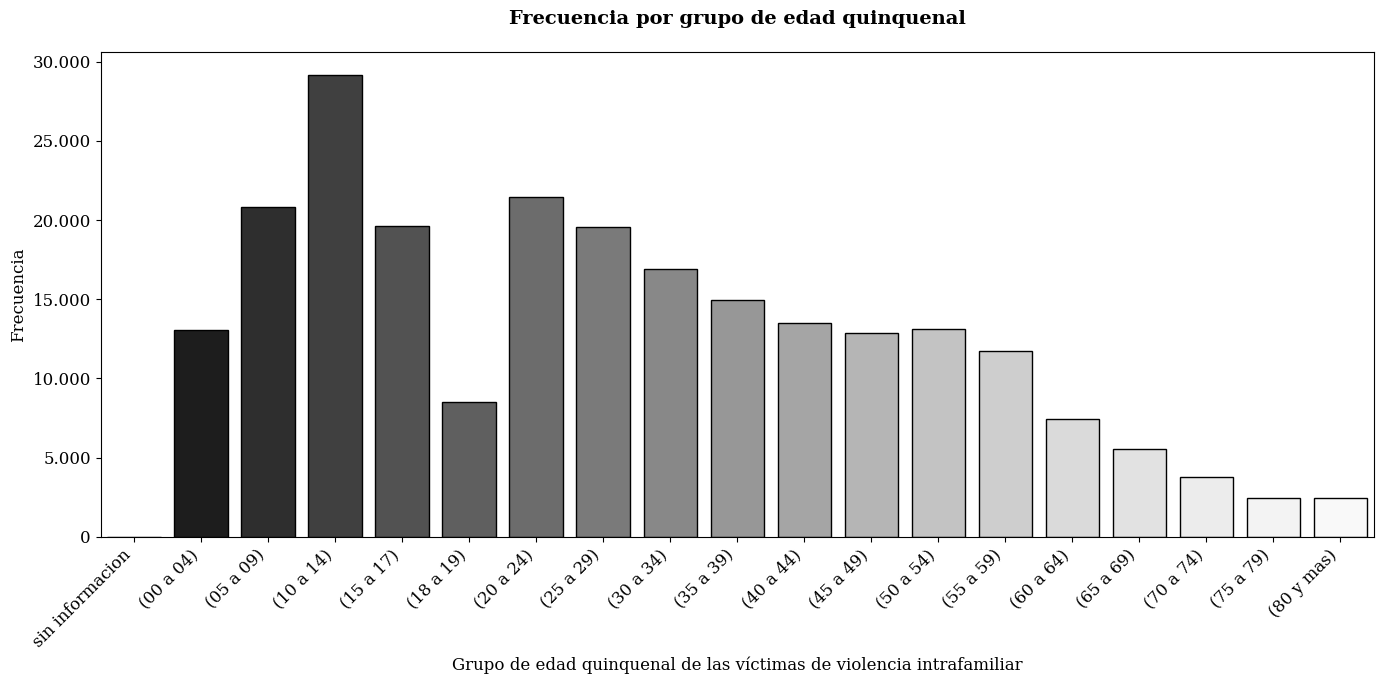

In [ ]:
##Columna (3) 'grupo_de_edad_quinquenal'
# Grafico en colores grises de la frecuencia de la columna (3) 'grupo_de_edad_quinquenal'

plt.figure(figsize=(14, 7)) # Un poco más ancho por la cantidad de barras

# Obtener los valores únicos de la columna
ordered_age_groups = df['grupo_de_edad_quinquenal'].dropna().unique()

# Función para extraer el valor numérico inicial del rango de edad para ordenar
def get_sort_key(age_group):
    if pd.isna(age_group):  # Handle NaN values if any remain
        return -1 # Or some other value that places NaNs appropriately
    # Extract the first number from the string (e.g., '10' from '(10 a 14)')
    # For '(80 y mas)', it will extract '80'
    try:
        return int(age_group.split(' ')[0].replace('(', ''))
    except ValueError:
        return -1 # Fallback for unexpected formats, or handle specifically

# Ordenar los grupos de edad usando la clave de ordenamiento
ordered_age_groups = sorted(ordered_age_groups, key=get_sort_key)

# Creación del gráfico con paleta secuencial de grises
#Usamos n_colors igual a la cantidad de categorías únicas en tu columna
n_categorias = df['grupo_de_edad_quinquenal'].nunique()
ax = sns.countplot(data=df,
                   x='grupo_de_edad_quinquenal',
                   palette=sns.color_palette("Greys_r", n_colors=n_categorias),
                   edgecolor='black',
                   order=ordered_age_groups)

# 3. Formato del eje Y (Punto para los miles)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 4. Rotar y alinear las etiquetas del eje X
# Las rotamos 45 grados para que no se amontonen como en la imagen original
plt.xticks(rotation=45, ha='right')

# 5. Títulos y etiquetas
plt.title('Frecuencia por grupo de edad quinquenal', fontsize=14, pad=20)
plt.xlabel('Grupo de edad quinquenal de las víctimas de violencia intrafamiliar', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

# 6. Ajuste final y guardado
plt.tight_layout()

plt.show()


In [ ]:
##Columna (3) 'grupo_de_edad_quinquenal'
# Valores únicos después de la limpieza en la columna (3) 'grupo_de_edad_quinquenal'
df['grupo_de_edad_quinquenal'].unique()

array(['(10 a 14)', '(00 a 04)', '(25 a 29)', '(05 a 09)', '(50 a 54)',
       '(70 a 74)', '(30 a 34)', '(45 a 49)', '(20 a 24)', '(35 a 39)',
       '(60 a 64)', '(15 a 17)', '(40 a 44)', '(65 a 69)', '(55 a 59)',
       '(80 y mas)', '(18 a 19)', '(75 a 79)', 'sin informacion'],
      dtype=object)

In [ ]:
#Columna (4) 'grupo_mayor_menor_de_edad'
df['grupo_mayor_menor_de_edad'].unique()

array(['a) menor de edad (<18 anos)', 'b) mayor de edad (>18 anos)',
       'b) mayores de edad (>18 anos)', 'c) sin informacion',
       'a) menores de edad (<18 anos)'], dtype=object)

In [ ]:
###Columna (4) 'grupo_mayor_menor_de_edad'
df['grupo_mayor_menor_de_edad'].value_counts()

,count
grupo_mayor_menor_de_edad,
b) mayores de edad (>18 anos),137614
a) menores de edad (<18 anos),72241
b) mayor de edad (>18 anos),16548
a) menor de edad (<18 anos),10432
c) sin informacion,5


In [ ]:
##Columna (4) 'grupo_mayor_menor_de_edad'
# Definición del diccionario de mapeo para la columna (4) 'grupo_mayor_menor_de_edad'
# Agrupamos todas las variantes en las tres categorías finales
mapeo_edades = {
    'b) mayores de edad (>18 anos)': 'Mayor de Edad',
    'b) mayor de edad (>18 anos)': 'Mayor de Edad',
    'a) menores de edad (<18 anos)': 'Menor de Edad',
    'a) menor de edad (<18 anos)': 'Menor de Edad',
    'c) sin informacion': 'Sin información'
}

# Aplicación del diccionario a la columna (4) 'grupo_mayor_menor_de_edad'
df['grupo_mayor_menor_de_edad'] = df['grupo_mayor_menor_de_edad'].map(mapeo_edades)


In [ ]:
# 3. Verificación del resultado
print(df['grupo_mayor_menor_de_edad'].value_counts())

grupo_mayor_menor_de_edad
Mayor de Edad      154162
Menor de Edad       82673
Sin información         5
Name: count, dtype: int64


In [ ]:
##Columna (4) 'grupo_mayor_menor_de_edad'
# Valores únicos después de la limpieza en la columna (4) 'grupo_mayor_menor_de_edad'
df['grupo_mayor_menor_de_edad'].unique()

array(['Menor de Edad', 'Mayor de Edad', 'Sin información'], dtype=object)

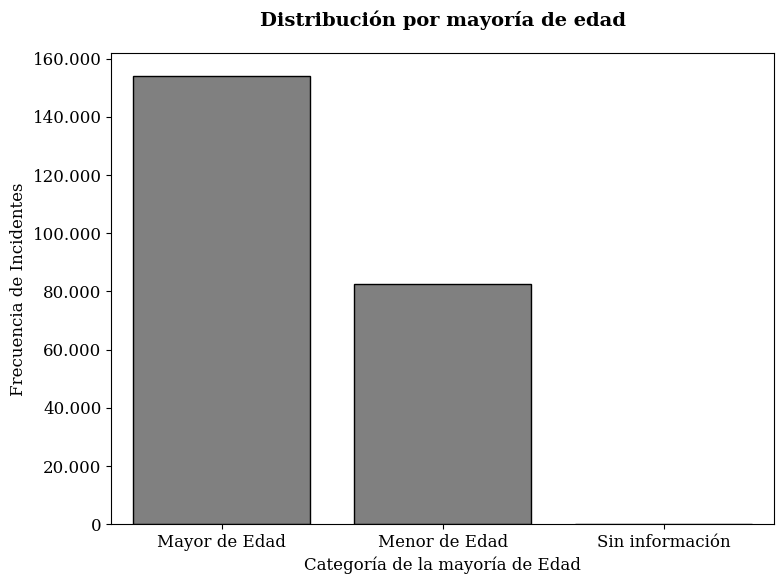

In [ ]:
##Columna (4) 'grupo_mayor_menor_de_edad'
# Gráfico de la frecuencia de la columna (4) 'grupo_mayor_menor_de_edad' en tonos de grises

plt.figure(figsize=(8, 6))

# 2. Creación del gráfico con los datos limpios
# Usamos una paleta de grises manual para resaltar la diferencia
ax = sns.countplot(
    data=df,
    x='grupo_mayor_menor_de_edad',
    color='gray',  # Gris
    order=['Mayor de Edad', 'Menor de Edad', 'Sin información'],
    edgecolor='black'
)

# 3. Formato del eje Y (Punto para los miles)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 4. Títulos y etiquetas
plt.title('Distribución por mayoría de edad', fontsize=14, pad=20)
plt.xlabel('Categoría de la mayoría de Edad', fontsize=12)
plt.ylabel('Frecuencia de Incidentes', fontsize=12)

# 5. Ajuste final y guardado
plt.tight_layout()

plt.show()

/tmp/ipykernel_193/1205092850.py:9: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:gray'` for the same effect.

  ax = sns.countplot(


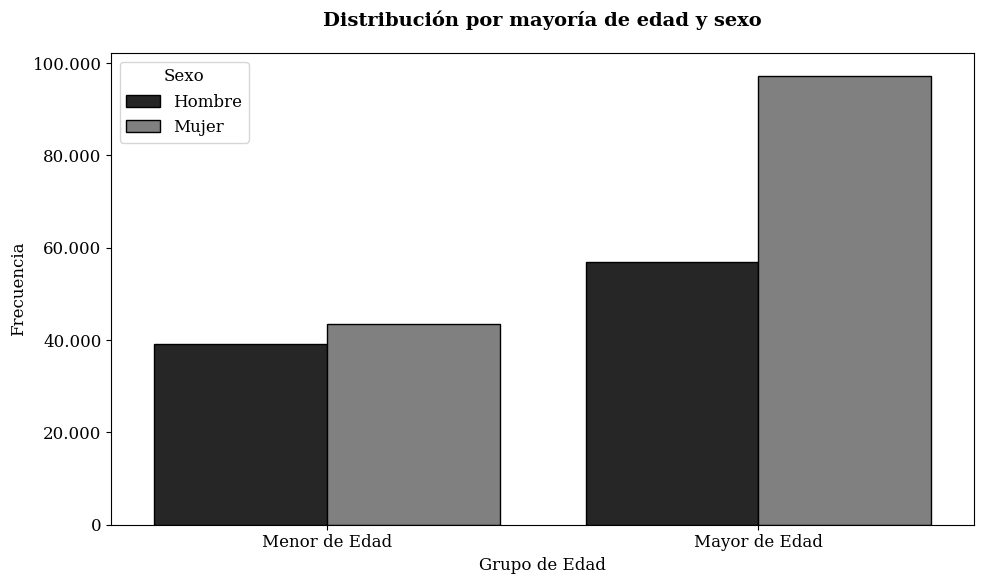

In [ ]:
##Combinación de las columnas (2) 'sexo_de_la_victima' y (4) 'grupo_mayor_menor_de_edad'
# 1. Filtrar los datos para excluir "Sin información"
df_filtrado = df[df['grupo_mayor_menor_de_edad'] != 'Sin información']

plt.figure(figsize=(10, 6))

# 2. Gráfico agrupado: x = Edad, hue = Sexo
# Usamos dos tonos de gris con buen contraste
ax = sns.countplot(
    data=df_filtrado,
    x='grupo_mayor_menor_de_edad',
    hue='sexo_de_la_victima',
    color='gray',
    order=['Menor de Edad', 'Mayor de Edad'],
    edgecolor='black'
)

# 3. Formato de miles con punto
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 4. Títulos y leyenda
plt.title('Distribución por mayoría de edad y sexo', fontsize=14, pad=20)
plt.xlabel('Grupo de Edad', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)

# Ajustar leyenda
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [label.capitalize() for label in labels], title='Sexo')

# 5. Ajuste final y guardado
plt.tight_layout()
plt.savefig('13_distribucion_mayoria_edad_sexo.png', dpi=300, bbox_inches='tight')
plt.show()


In [ ]:
#conteo de valores de la columna (5) grupo_de_edad_judicial
display(df['grupo_de_edad_judicial'].value_counts(dropna=False))
df['grupo_de_edad_judicial'].value_counts()

,count
grupo_de_edad_judicial,
(14 a 17),26644
(10 a 13),22127
(20 a 24),21434
(05 a 09),20829
(29 a 34),20466
(25 a 28),15984
(35 a 39),14940
(40 a 44),13506
(50 a 54),13136


,count
grupo_de_edad_judicial,
(14 a 17),26644
(10 a 13),22127
(20 a 24),21434
(05 a 09),20829
(29 a 34),20466
(25 a 28),15984
(35 a 39),14940
(40 a 44),13506
(50 a 54),13136


In [ ]:
##Columna (5) 'grupo_de_edad_judicial'
#conteo de valores de la columna (5) 'grupo_de_edad_judicial'
display(df['grupo_de_edad_judicial'].value_counts(dropna=False))
df['grupo_de_edad_judicial'].value_counts()

,count
grupo_de_edad_judicial,
(14 a 17),26644
(10 a 13),22127
(20 a 24),21434
(05 a 09),20829
(29 a 34),20466
(25 a 28),15984
(35 a 39),14940
(40 a 44),13506
(50 a 54),13136


,count
grupo_de_edad_judicial,
(14 a 17),26644
(10 a 13),22127
(20 a 24),21434
(05 a 09),20829
(29 a 34),20466
(25 a 28),15984
(35 a 39),14940
(40 a 44),13506
(50 a 54),13136


Muestra de conteos Hombre: [1, 7063, 11338]


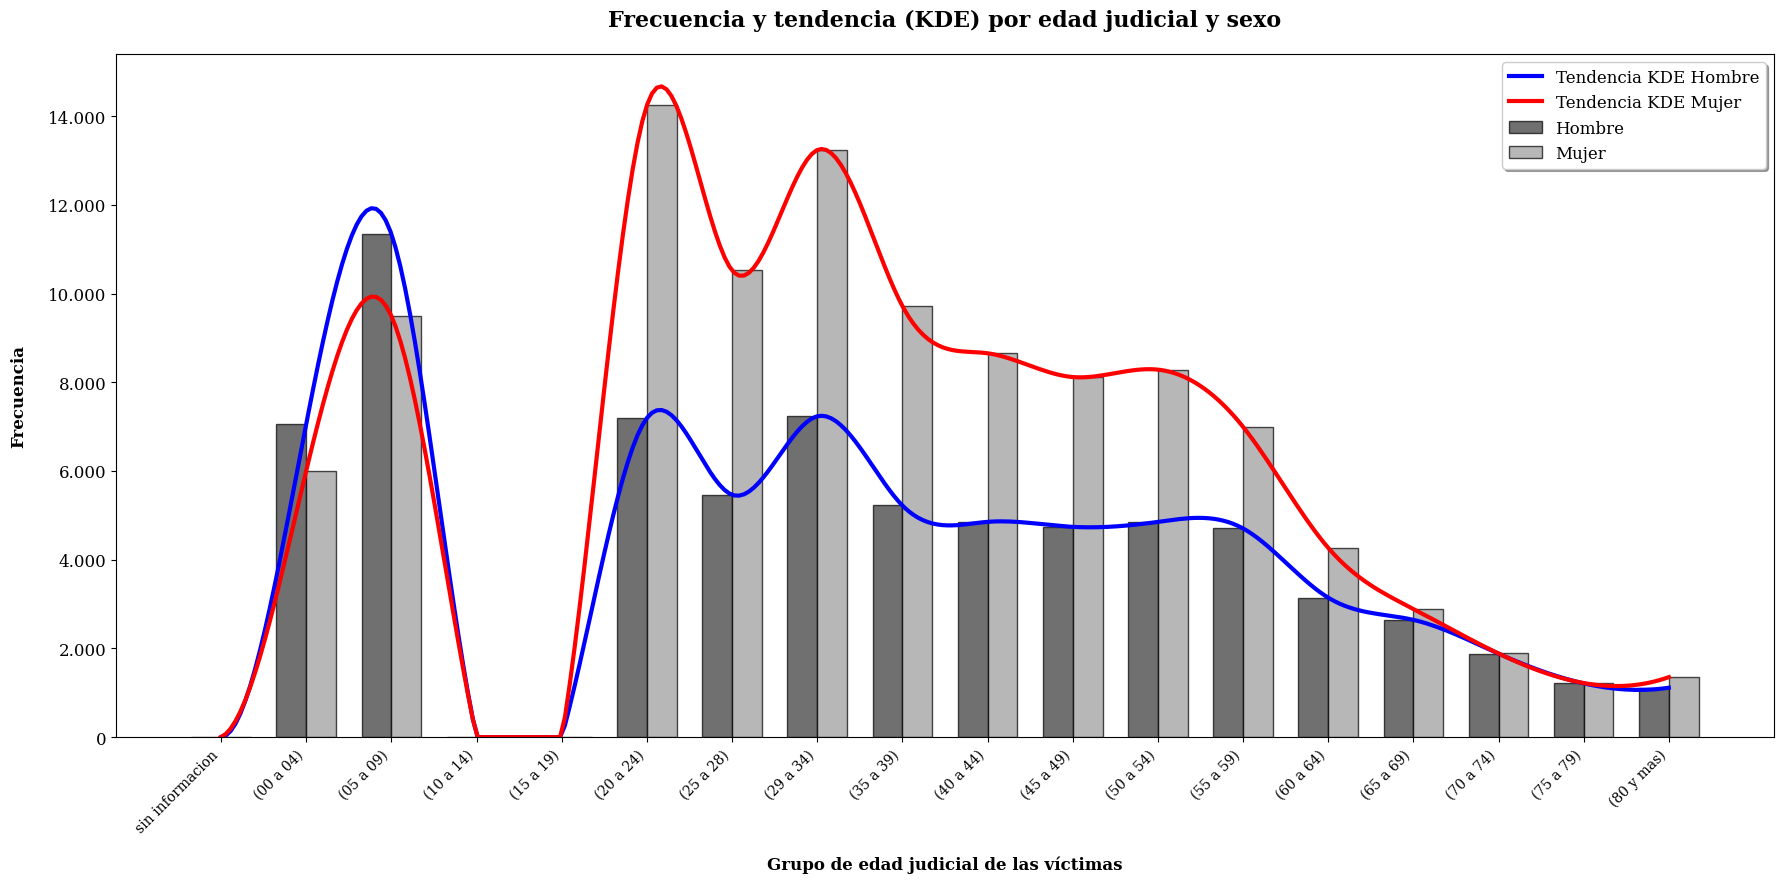

In [ ]:
from scipy.interpolate import make_interp_spline
ordered_age_judicial_groups = [
    'sin informacion', '(00 a 04)', '(05 a 09)', '(10 a 14)', '(15 a 19)', '(20 a 24)', '(25 a 28)','(29 a 34)','(35 a 39)','(40 a 44)',
    '(45 a 49)', '(50 a 54)', '(55 a 59)', '(60 a 64)', '(65 a 69)', '(70 a 74)', '(75 a 79)', '(80 y mas)'
]

# 1. LIMPIEZA AGRESIVA DE DATOS
# Convertimos todo a string, quitamos espacios y estandarizamos
df['grupo_limpio'] = df['grupo_de_edad_judicial'].astype(str).str.strip()
df['sexo_limpio'] = df['sexo_de_la_victima'].astype(str).str.strip().str.upper()

# Limpiamos también la lista de categorías que usaremos para el eje X
categorias_eje = [str(c).strip() for c in ordered_age_judicial_groups if str(c).strip() != 'nan']

# 2. CÁLCULO DE CONTEOS (Usando la nueva columna limpia)
counts_h = []
counts_m = []

for cat in categorias_eje:
    c_h = len(df[(df['grupo_limpio'] == cat) & (df['sexo_limpio'] == 'HOMBRE')])
    c_m = len(df[(df['grupo_limpio'] == cat) & (df['sexo_limpio'] == 'MUJER')])
    counts_h.append(c_h)
    counts_m.append(c_m)

# 3. VERIFICACIÓN (Si esto imprime ceros, el problema es el nombre de la columna)
print(f"Muestra de conteos Hombre: {counts_h[:3]}")

# 4. GRÁFICO
fig, ax = plt.subplots(figsize=(18, 9))

posiciones = np.arange(len(categorias_eje))
ancho = 0.35

# Barras
ax.bar(posiciones - ancho/2, counts_h, ancho, label='Hombre', color='#333333', edgecolor='black', alpha=0.7)
ax.bar(posiciones + ancho/2, counts_m, ancho, label='Mujer', color='#999999', edgecolor='black', alpha=0.7)

# Curvas de tendencia (Solo si hay datos > 0)
if sum(counts_h) > 0 and sum(counts_m) > 0:
    x_new = np.linspace(posiciones.min(), posiciones.max(), 300)

    # Tendencia Hombre
    spl_h = make_interp_spline(posiciones, counts_h, k=3)
    ax.plot(x_new, np.maximum(spl_h(x_new), 0), color='blue', linewidth=3, label='Tendencia KDE Hombre')

    # Tendencia Mujer
    spl_m = make_interp_spline(posiciones, counts_m, k=3)
    ax.plot(x_new, np.maximum(spl_m(x_new), 0), color='red', linewidth=3, label='Tendencia KDE Mujer')

# 5. FORMATOS
ax.set_xticks(posiciones)
ax.set_xticklabels(categorias_eje, rotation=45, ha='right', fontsize=10)

# Formato de miles con punto en el eje Y
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))


# Añadiendo las etiquetas que faltaban
ax.set_xlabel('Grupo de edad judicial de las víctimas', fontsize=12, fontweight='bold', labelpad=15)
ax.set_ylabel('Frecuencia', fontsize=12, fontweight='bold', labelpad=15)

#Título ajustado
plt.title('Frecuencia y tendencia (KDE) por edad judicial y sexo', fontsize=16, pad=20, fontweight='bold')

# Ajuste de la leyenda para que no tape los picos
ax.legend(loc='upper right', frameon=True, shadow=True)

#Ajuste final y guardado
plt.tight_layout()
plt.show()

In [ ]:
#Columna (6) 'ciclo_vital'
columna = 'ciclo_vital'

# 1. Cálculos para Colombia (Conteos absolutos y Porcentajes relativos)
conteo_col = df[columna].value_counts().rename('Total_Colombia')
porc_col = (df[columna].value_counts(normalize=True) * 100).round(2).rename('%_Colombia')

# 2. Cálculos para Antioquia (Conteos absolutos y Porcentajes relativos)
conteo_ant = df_antioquia[columna].value_counts().rename('Total_Antioquia')
porc_ant = (df_antioquia[columna].value_counts(normalize=True) * 100).round(2).rename('%_Antioquia')

# 3. Unir todo en el orden exacto de izquierda a derecha
tabla_comparativa_ciclo = pd.concat([conteo_col, porc_col, conteo_ant, porc_ant], axis=1)

# 4. Manejo de posibles nulos (si un ciclo vital no aparece en alguna región)
tabla_comparativa_ciclo = tabla_comparativa_ciclo.fillna(0)

# 5. Restaurar el formato entero solo para las columnas de totales absolutos
tabla_comparativa_ciclo['Total_Colombia'] = tabla_comparativa_ciclo['Total_Colombia'].astype(int)
tabla_comparativa_ciclo['Total_Antioquia'] = tabla_comparativa_ciclo['Total_Antioquia'].astype(int)

# 6. Mostrar la tabla final
tabla_comparativa_ciclo

,Total_Colombia,%_Colombia,Total_Antioquia,%_Antioquia
ciclo_vital,,,,
(29 a 59) adultez,86606,36.57,12450,40.05
(18 a 28) juventud,45939,19.40,6027,19.39
(12 a 17) adolescencia,38872,16.41,4509,14.50
(06 a 11) infancia,27226,11.50,2998,9.64
(mas de 60) adulto mayor,21617,9.13,3364,10.82
(00 a 05) primera infancia,16575,7.00,1738,5.59
sin informacion,5,0.00,1,0.00


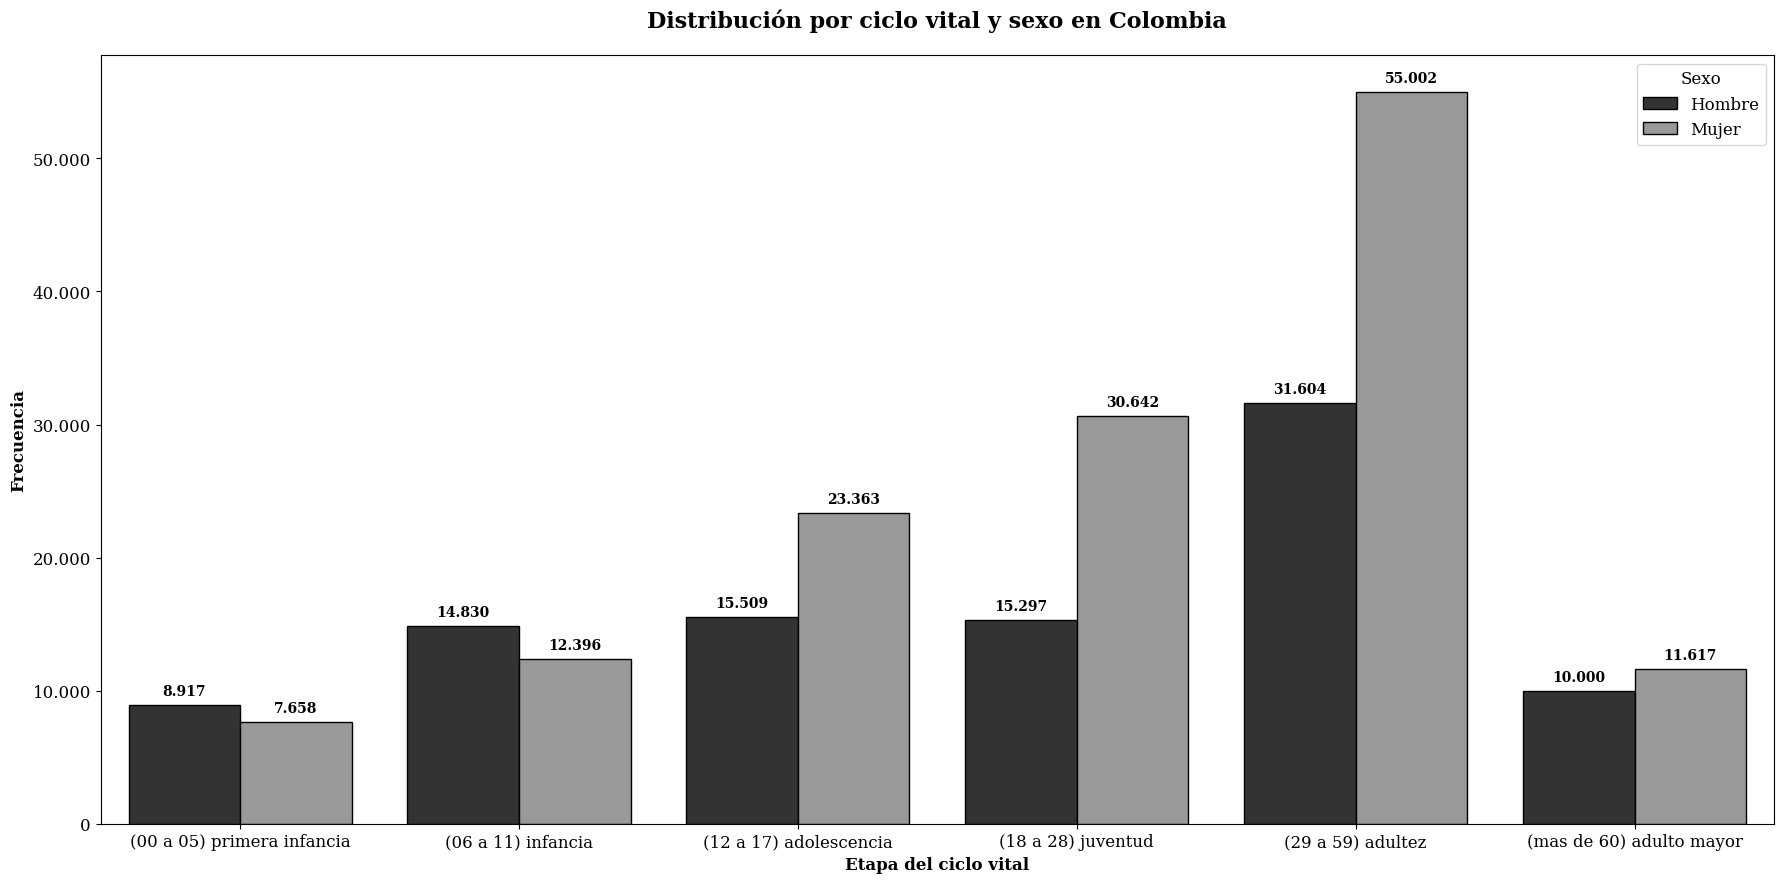

In [ ]:
##Columna (6) 'ciclo_vital' para Colombia

# Definir el orden cronológico lógico
orden_ciclo = [
    '(00 a 05) primera infancia', '(06 a 11) infancia',
    '(12 a 17) adolescencia', '(18 a 28) juventud',
    '(29 a 59) adultez', '(mas de 60) adulto mayor'
]

# Crear el gráfico de barras agrupado por sexo
fig, ax = plt.subplots(figsize=(18, 9))
ax = sns.countplot(
    data=df,  # Asegúrate de usar el DataFrame correcto
    x='ciclo_vital',
    hue='sexo_de_la_victima',
    order=orden_ciclo,
    palette=['#333333', '#999999'], # Gris oscuro, Gris medio
    edgecolor='black'
)

# Formatos de los ejes
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))
plt.title('Distribución por ciclo vital y sexo en Colombia', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Etapa del ciclo vital', fontsize=12, fontweight='bold')
plt.ylabel('Frecuencia', fontsize=12, fontweight='bold')

# Ajustar leyenda
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [label.capitalize() for label in labels], title='Sexo', loc='upper right')

# MEJORA: Agregar los valores exactos sobre cada barra
for container in ax.containers:
    # Traer el valor, ponerle formato de miles con punto y omitir si es 0
    etiquetas = [f'{v:,.0f}'.replace(',', '.') if v > 0 else "" for v in container.datavalues]
    ax.bar_label(container, labels=etiquetas, padding=5, fontsize=10, fontweight='bold')

# Ajuste final y guardado
plt.tight_layout()
plt.show()

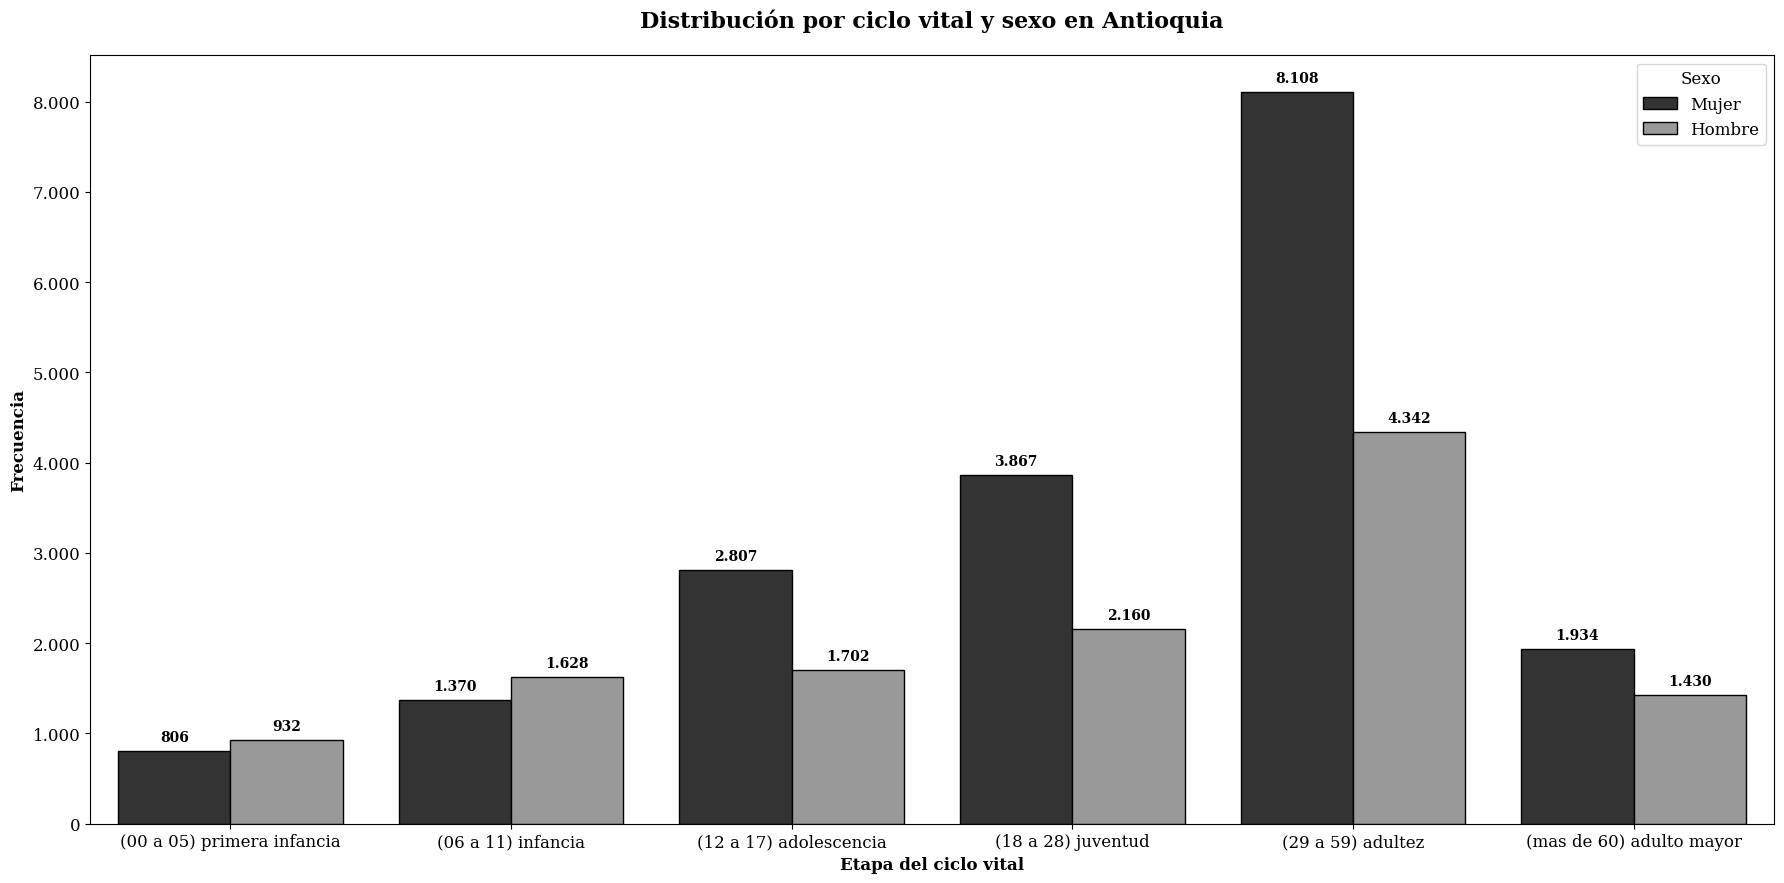

In [ ]:
#Columna (6) 'ciclo_vital' para Antioquia

# Definir el orden cronológico lógico
orden_ciclo = [
    '(00 a 05) primera infancia', '(06 a 11) infancia',
    '(12 a 17) adolescencia', '(18 a 28) juventud',
    '(29 a 59) adultez', '(mas de 60) adulto mayor'
]

# Crear el gráfico de barras agrupado por sexo
fig, ax = plt.subplots(figsize=(18, 9))
ax = sns.countplot(
    data=df_antioquia,  # Asegúrate de usar el DataFrame correcto
    x='ciclo_vital',
    hue='sexo_de_la_victima',
    order=orden_ciclo,
    palette=['#333333', '#999999'], # Gris oscuro, Gris medio
    edgecolor='black'
)

# Formatos de los ejes
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))
plt.title('Distribución por ciclo vital y sexo en Antioquia', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Etapa del ciclo vital', fontsize=12, fontweight='bold')
plt.ylabel('Frecuencia', fontsize=12, fontweight='bold')

# Ajustar leyenda
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [label.capitalize() for label in labels], title='Sexo', loc='upper right')

# MEJORA: Agregar los valores exactos sobre cada barra
for container in ax.containers:
    # Traer el valor, ponerle formato de miles con punto y omitir si es 0
    etiquetas = [f'{v:,.0f}'.replace(',', '.') if v > 0 else "" for v in container.datavalues]
    ax.bar_label(container, labels=etiquetas, padding=5, fontsize=10, fontweight='bold')

# Ajuste final y guardado
plt.tight_layout()
plt.show()

In [ ]:
#Verificación de los valores para el df_antioquia
df_antioquia['ciclo_vital'].value_counts()

,count
ciclo_vital,
(29 a 59) adultez,12450
(18 a 28) juventud,6027
(12 a 17) adolescencia,4509
(mas de 60) adulto mayor,3364
(06 a 11) infancia,2998
(00 a 05) primera infancia,1738
sin informacion,1


In [ ]:
#Columna (7) 'pais_de_nacimiento'
#Estandarización y conteo de valores de la columna (7) 'pais_de_nacimiento'
# Capitalizar la primera letra de cada palabra en la columna 'pais_de_nacimiento'

df['pais_de_nacimiento'] = df['pais_de_nacimiento'].str.title()
df_antioquia['pais_de_nacimiento'] = df_antioquia['pais_de_nacimiento'].str.title()

# Mostrar los valores únicos y su conteo después de la modificación
display(df['pais_de_nacimiento'].value_counts(dropna=False))

# Definir un diccionario de correcciones ortográficas para los países
country_corrections = {
    'Espana': 'España',
    'Republica Dominicana': 'República Dominicana',
    'Paises Bajos': 'Países Bajos',
    'Japon': 'Japón',
    'Corea Del Sur': 'Corea del Sur',
    'Paquistan': 'Pakistán',
    'Hungria': 'Hungría',
    'Haiti': 'Haití',
    'Canada': 'Canadá',
    'Mexico': 'México'
}

# Aplicar las correcciones a la columna 'pais_de_nacimiento' en ambos dfs
df['pais_de_nacimiento'] = df['pais_de_nacimiento'].replace(country_corrections)
df_antioquia['pais_de_nacimiento'] = df_antioquia['pais_de_nacimiento'].replace(country_corrections)

# Mostrar los valores únicos y su conteo después de la modificación
display(df['pais_de_nacimiento'].value_counts(dropna=False))

,count
pais_de_nacimiento,
Colombia,232845
Venezuela,3147
Sin Informacion,540
Ecuador,72
Estados Unidos,58
Espana,46
Peru,19
Panama,11
Mexico,10


,count
pais_de_nacimiento,
Colombia,232845
Venezuela,3147
Sin Informacion,540
Ecuador,72
Estados Unidos,58
España,46
Peru,19
Panama,11
México,10


/tmp/ipykernel_193/2826245633.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


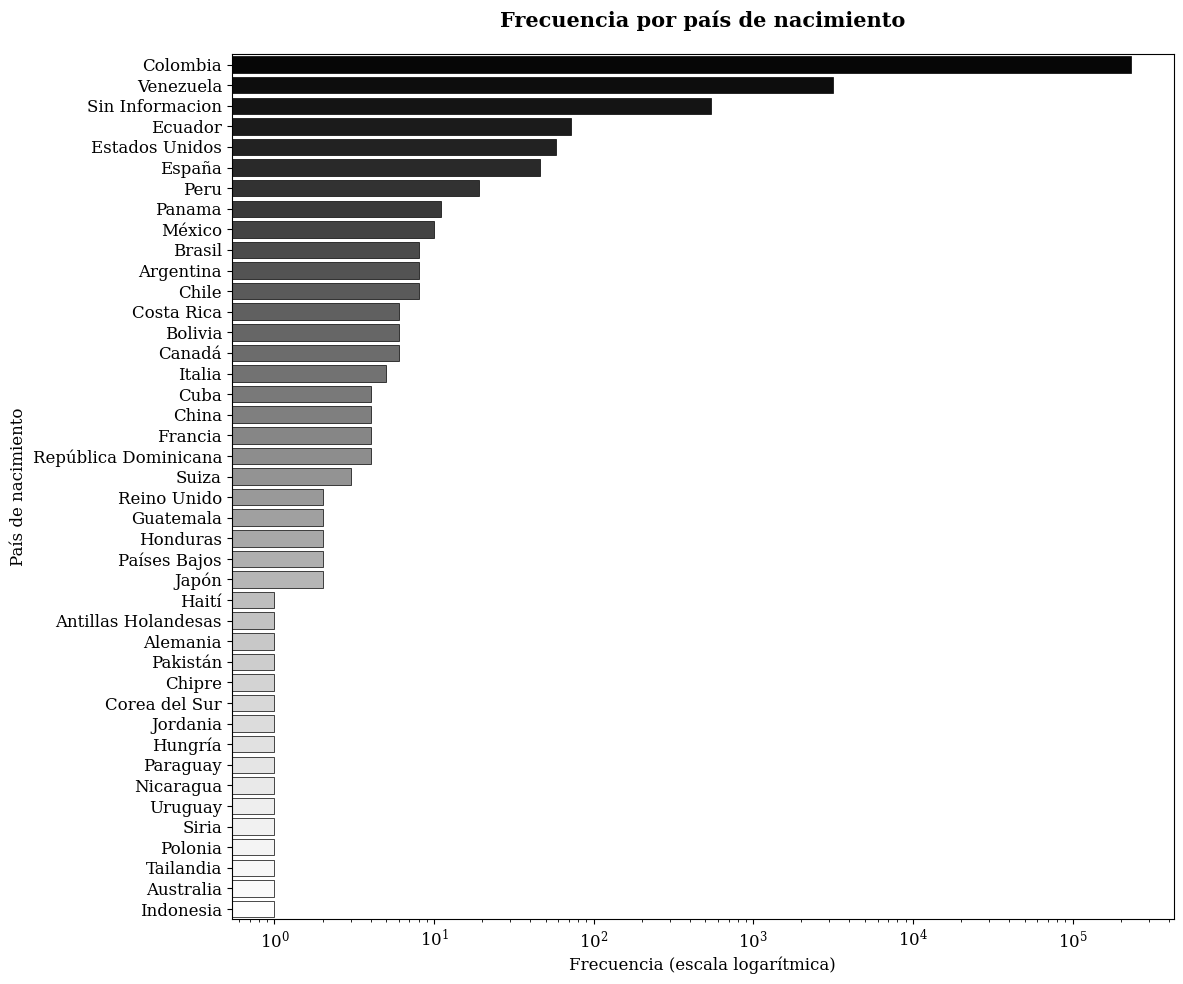

In [ ]:
# Frecuencia y gráfico de la columna (7) 'país_de_nacimiento' para Colombia

#1. Tamaño del gráfico
plt.figure(figsize=(12, 10)) # Ajustamos altura por la cantidad de países

# 2. Preparar los datos y la paleta de grises en degradé
# Contamos las categorías para generar la cantidad exacta de tonos de gris
paises_ordenados = df['pais_de_nacimiento'].value_counts().index
n_colores = len(paises_ordenados)
paleta_grises = sns.color_palette("Greys_r", n_colors=n_colores)

# 3. Crear el gráfico
ax = sns.countplot(
    data=df,
    y='pais_de_nacimiento',
    order=paises_ordenados,
    palette=paleta_grises,
    edgecolor='black',
    linewidth=0.5
)
# 4. Escala logarítmica para manejar la gran diferencia entre Colombia y el resto
ax.set_xscale("log")

# 5. Títulos y etiquetas
plt.title('Frecuencia por país de nacimiento', fontsize=15, pad=20)
plt.xlabel('Frecuencia (escala logarítmica)', fontsize=12)
plt.ylabel('País de nacimiento', fontsize=12)

# Ajuste final y guardado
plt.tight_layout()
plt.show()

/tmp/ipykernel_193/3323631116.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


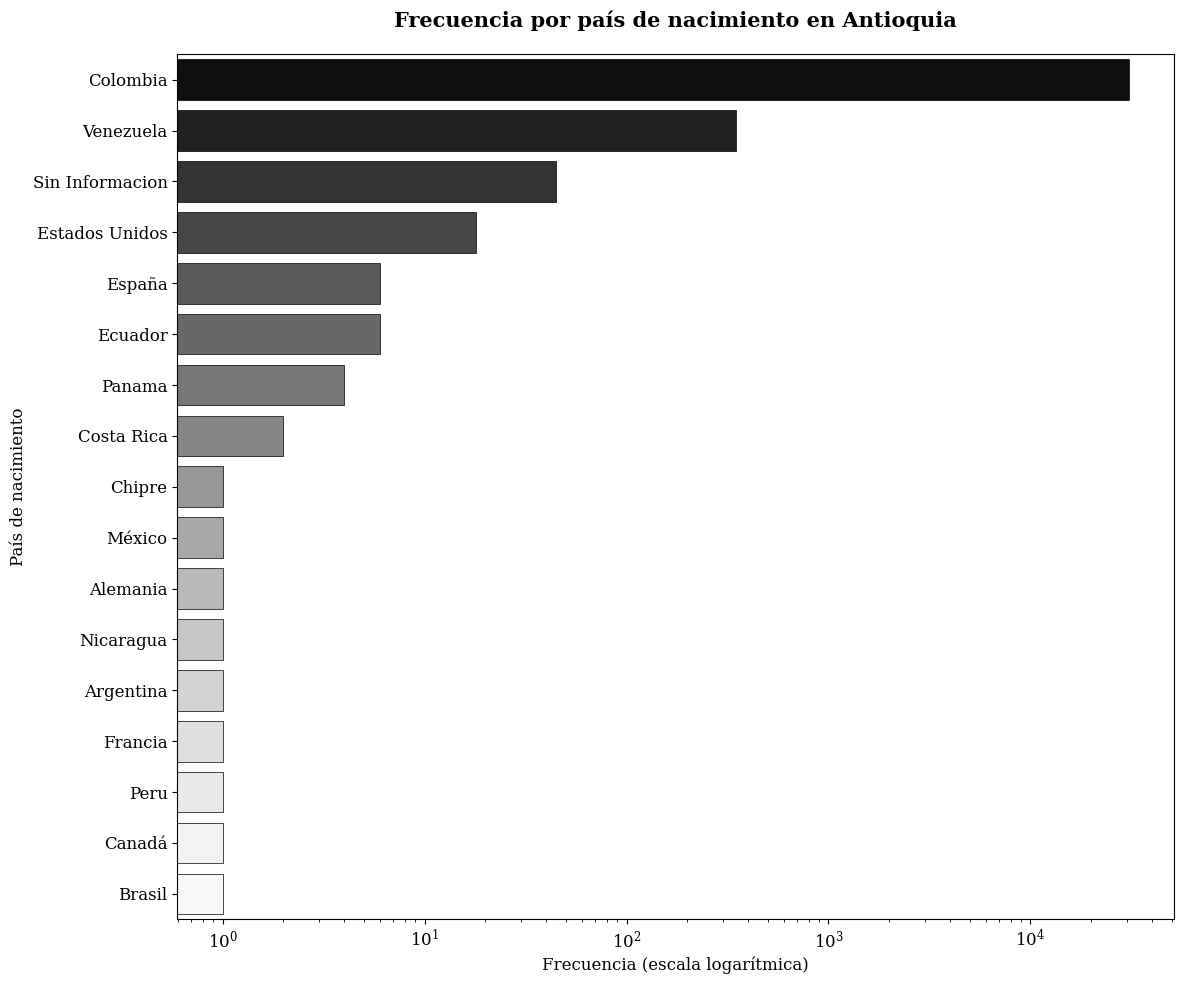

In [ ]:
# Frecuencia y gráfico de la columna (7) 'país_de_nacimiento' para Antioquia

#1. Tamaño del gráfico
plt.figure(figsize=(12, 10)) # Ajustamos altura por la cantidad de países

# 2. Preparar los datos y la paleta de grises en degradé
# Contamos las categorías para generar la cantidad exacta de tonos de gris
paises_ordenados = df_antioquia['pais_de_nacimiento'].value_counts().index
n_colores = len(paises_ordenados)
paleta_grises = sns.color_palette("Greys_r", n_colors=n_colores)

# 3. Crear el gráfico
ax = sns.countplot(
    data=df_antioquia,
    y='pais_de_nacimiento',
    order=paises_ordenados,
    palette=paleta_grises,
    edgecolor='black',
    linewidth=0.5
)
# 4. Escala logarítmica para manejar la gran diferencia entre Colombia y el resto
ax.set_xscale("log")

# 5. Títulos y etiquetas
plt.title('Frecuencia por país de nacimiento en Antioquia', fontsize=15, pad=20)
plt.xlabel('Frecuencia (escala logarítmica)', fontsize=12)
plt.ylabel('País de nacimiento', fontsize=12)

# Ajuste final y guardado
plt.tight_layout()
plt.show()

In [ ]:
# Valores únicos después de la limpieza en la columna (7) 'pais_de_nacimiento'
df['pais_de_nacimiento'].unique()

array(['Colombia', 'Bolivia', 'Italia', 'Peru', 'Reino Unido',
       'Estados Unidos', 'Venezuela', 'Ecuador', 'China', 'España',
       'Sin Informacion', 'Pakistán', 'Brasil', 'México', 'Chipre',
       'Corea del Sur', 'Jordania', 'Hungría', 'Japón',
       'República Dominicana', 'Panama', 'Costa Rica', 'Francia',
       'Alemania', 'Antillas Holandesas', 'Haití', 'Cuba', 'Paraguay',
       'Chile', 'Nicaragua', 'Suiza', 'Países Bajos', 'Guatemala',
       'Canadá', 'Siria', 'Argentina', 'Uruguay', 'Polonia', 'Tailandia',
       'Honduras', 'Australia', 'Indonesia'], dtype=object)

In [ ]:
# Valores únicos después de la limpieza en la columna (7) 'pais_de_nacimiento'
df['pais_de_nacimiento'].value_counts()

,count
pais_de_nacimiento,
Colombia,232845
Venezuela,3147
Sin Informacion,540
Ecuador,72
Estados Unidos,58
España,46
Peru,19
Panama,11
México,10


In [ ]:
#Verificación de los valores para el df_antioquia
df_antioquia['pais_de_nacimiento'].value_counts()

,count
pais_de_nacimiento,
Colombia,30647
Venezuela,350
Sin Informacion,45
Estados Unidos,18
España,6
Ecuador,6
Panama,4
Costa Rica,2
Chipre,1


In [ ]:
#Valores únicos de la columna (8) 'escolaridad'
df['escolaridad'].value_counts()

,count
escolaridad,
educacion basica primaria,61979
educacion basica secundaria o secundaria baja,38331
educacion inicial y educacion preescolar,37126
educacion media o secundaria alta,32493
educacion tecnica profesional y tecnologica,21259
sin escolaridad,13811
basica primaria,12782
preescolar,7928
sin informacion,5670


In [ ]:
#Verificación de los valores para el df_antioquia
df_antioquia['escolaridad'].value_counts()

,count
escolaridad,
educacion basica primaria,8334
educacion basica secundaria o secundaria baja,4800
educacion inicial y educacion preescolar,4609
educacion media o secundaria alta,4195
educacion tecnica profesional y tecnologica,3197
sin escolaridad,1567
basica primaria,1538
sin informacion,1228
preescolar,895


In [ ]:
# 1. Diccionario de estandarización para Escolaridad
# Agrupación de las categorías redundantes
mapeo_escolaridad = {
    'educacion basica primaria': 'Primaria',
    'educacion basica secundaria o secundaria baja': 'Secundaria',
    'educacion inicial y educación preescolar': 'Preescolar',
    'educacion media o secundaria alta': 'Secundaria',
    'educacion tecnica profesional y tecnologica': 'Técnica/Tecnólogica',
    'sin escolaridad': 'Ninguna',
    'basica primaria': 'Primaria',
    'preescolar': 'Preescolar',
    'basica secundaria': 'Secundaria',
    'sin informacion': 'Sin información',
    'basica secundaria': 'Secundaria',
    'no aplica': 'Sin información',
    'tecnologica': 'Técnica/Tecnólogica',
    'universitario': 'Profesional',
    'ninguna': 'Ninguna',
    'especializacion, maestria o equivalente': 'Especialización/Maestría',
    'doctorado o equivalente': 'Doctorado',
    'profesional': 'Profesional',
    'maestria': 'Especialización/Maestría',

}

# 2. Limpieza de datos para ambos dfs a partir del diccionario mapeo_escolaridad

df['escolaridad_limpia'] = df['escolaridad'].astype(str).str.strip().map(mapeo_escolaridad)
df_antioquia['escolaridad_limpia_antioquia'] = df_antioquia['escolaridad'].astype(str).str.strip().map(mapeo_escolaridad)

# 3. Filtrar para mostrar la jerarquía educativa (excluyendo "Sin información")
df_edu = df[df['escolaridad_limpia'] != 'Sin información']
orden_edu = ['Ninguna', 'Preescolar', 'Primaria', 'Secundaria',
             'Técnica/Tecnólogica', 'Profesional', 'Especialización/Maestría', 'Doctorado']

df_edu_antioquia = df_antioquia[df_antioquia['escolaridad_limpia_antioquia'] != 'Sin información']
orden_edu_antioquia = ['Ninguna', 'Preescolar', 'Primaria', 'Secundaria',
             'Técnica/Tecnólogica', 'Profesional', 'Especialización/Maestría', 'Doctorado']


/tmp/ipykernel_193/989741749.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


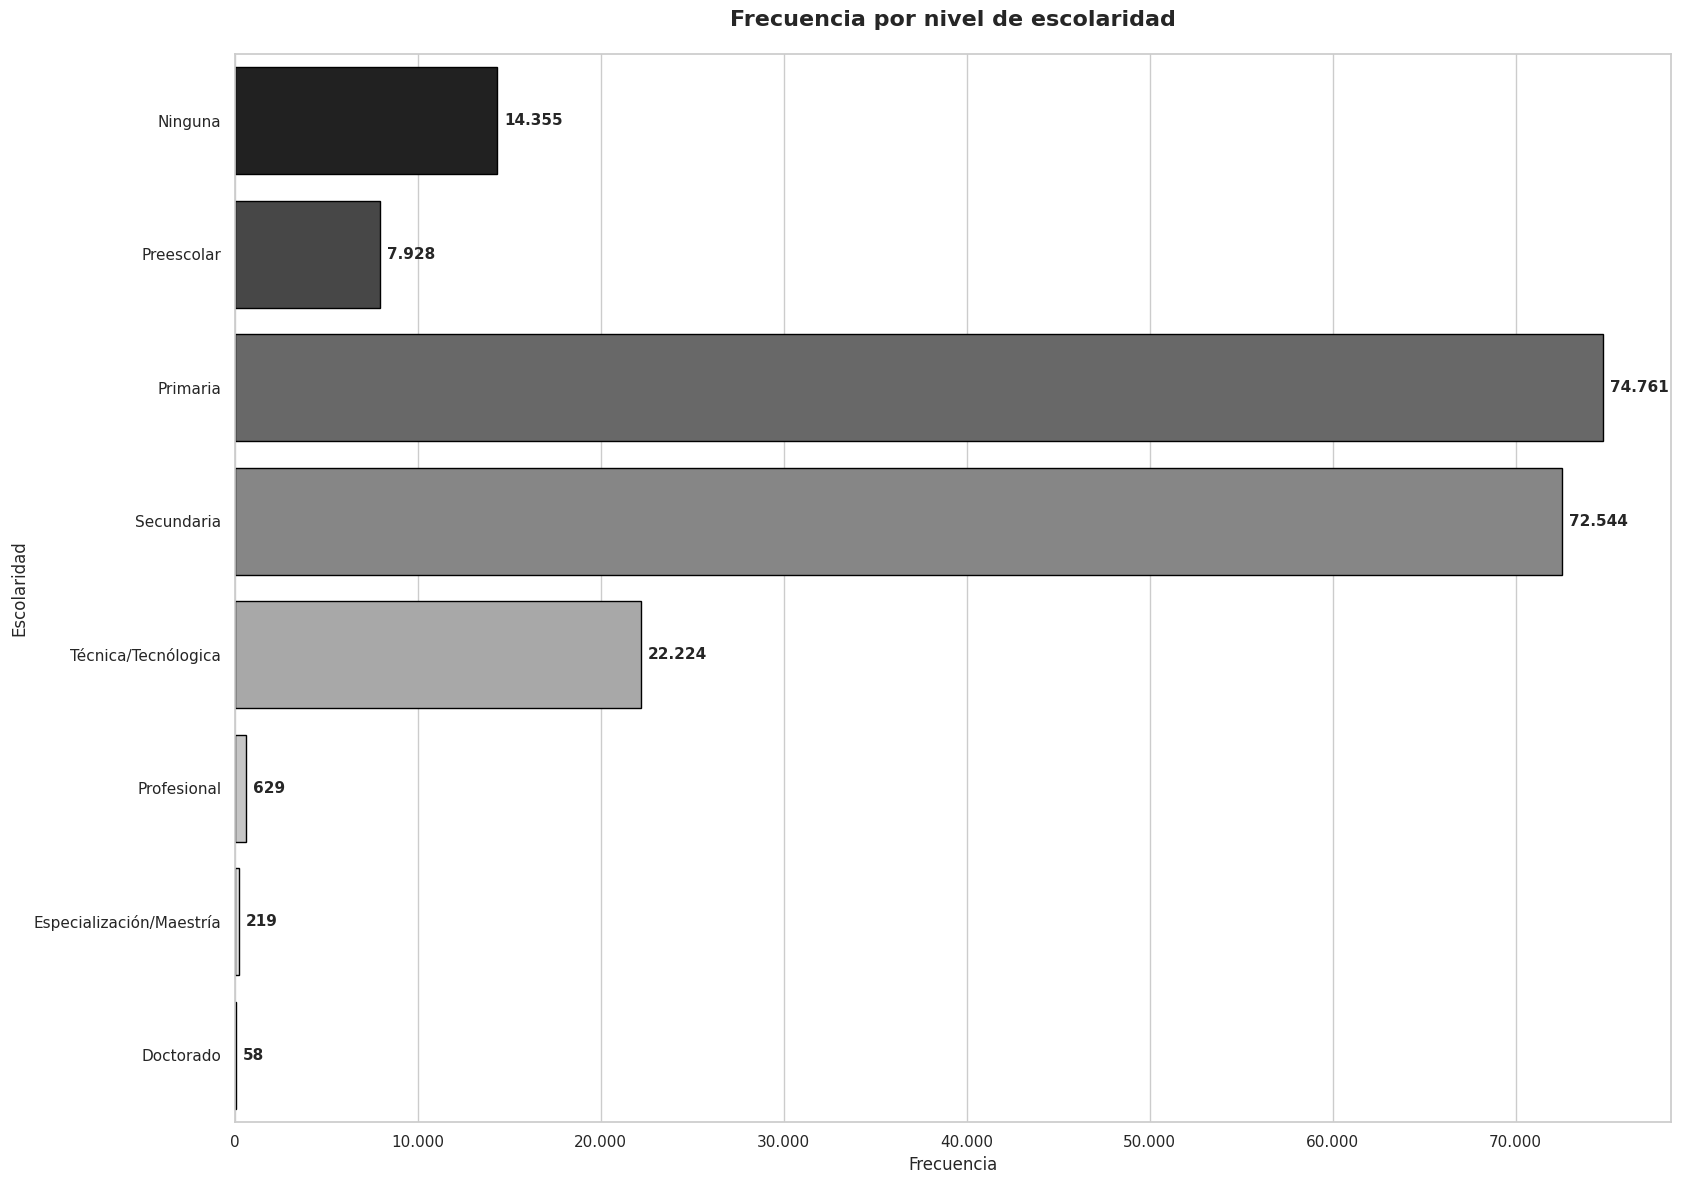

In [ ]:
#4. Tamaño del gráfico para Colombia
plt.figure(figsize=(17, 12))

# 5. Generar degradé de grises (más claro para niveles más altos)
n_niveles = len(orden_edu)
paleta_edu = sns.color_palette("Greys_r", n_colors=len(orden_edu)) # De oscuro a claro con _r en Greys

ax = sns.countplot(
    data=df_edu,
    y='escolaridad_limpia',
    order=orden_edu,
    palette=paleta_edu,
    edgecolor='black'
)

# 6. Etiquetas y formato
plt.title('Frecuencia por nivel de escolaridad', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Frecuencia', fontsize=12)
plt.ylabel('Escolaridad', fontsize=12)

# 7. SEPARACIÓN DE MILES EN EL EJE X (Con punto)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 8. Etiquetas de datos sobre las barras (También con punto)
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{int(width):,d}'.replace(',', '.'),
                    (width, p.get_y() + p.get_height()/2),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=11, fontweight='bold')

# 9. Ajuste final y guardado
plt.tight_layout()

plt.show()

/tmp/ipykernel_193/3677489130.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(


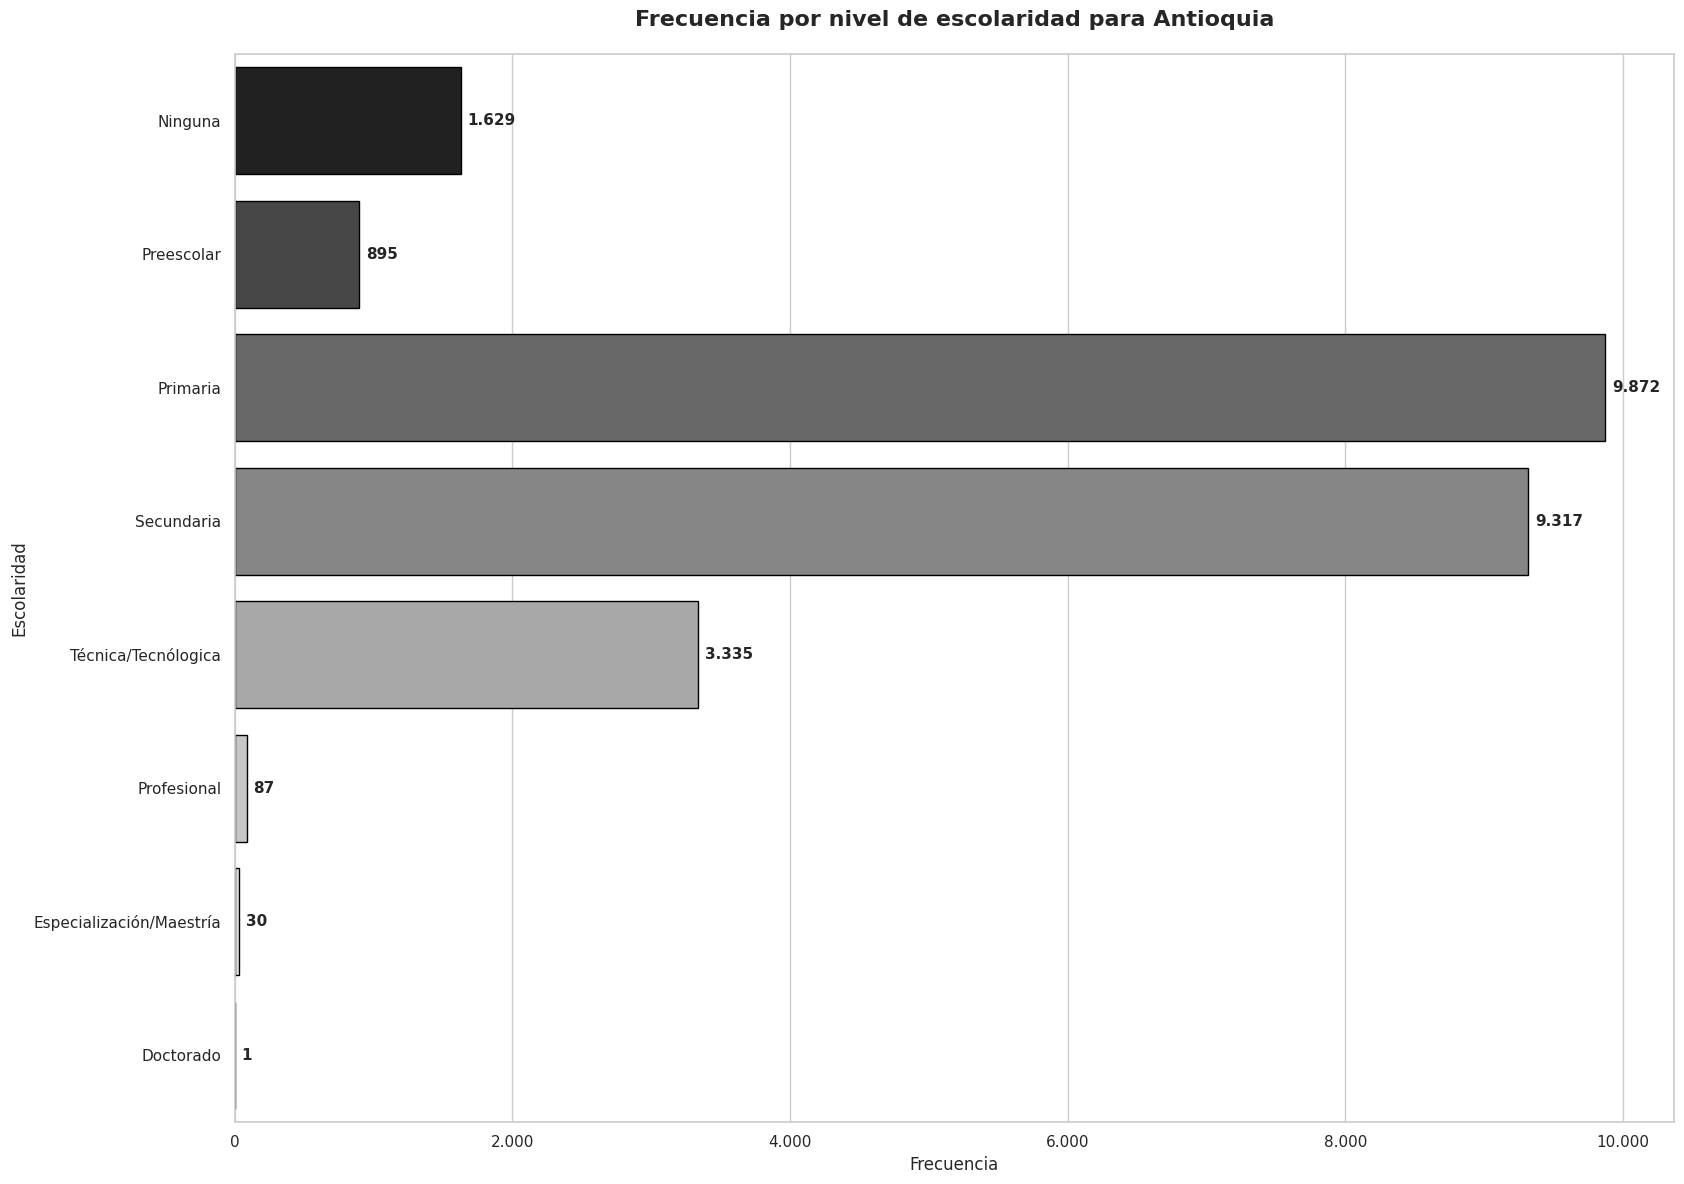

In [ ]:
#4. Tamaño del gráfico para Antioquia
plt.figure(figsize=(17, 12))

# 5. Generar degradé de grises (más claro para niveles más altos)
n_niveles = len(orden_edu_antioquia)
paleta_edu_antioquia = sns.color_palette("Greys_r", n_colors=len(orden_edu_antioquia)) # De oscuro a claro con _r en Greys

ax = sns.countplot(
    data=df_edu_antioquia,
    y='escolaridad_limpia_antioquia',
    order=orden_edu_antioquia,
    palette=paleta_edu_antioquia,
    edgecolor='black'
)

# 6. Etiquetas y formato
plt.title('Frecuencia por nivel de escolaridad para Antioquia', fontsize=16, pad=20, fontweight='bold')
plt.xlabel('Frecuencia', fontsize=12)
plt.ylabel('Escolaridad', fontsize=12)

# 7. SEPARACIÓN DE MILES EN EL EJE X (Con punto)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 8. Etiquetas de datos sobre las barras (También con punto)
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f'{int(width):,d}'.replace(',', '.'),
                    (width, p.get_y() + p.get_height()/2),
                    ha='left', va='center',
                    xytext=(5, 0), textcoords='offset points',
                    fontsize=11, fontweight='bold')

# 9. Ajuste final y guardado
plt.tight_layout()

plt.show()

In [ ]:
#Valores únicos de la columna (8) 'escolaridad' después de la limpieza
df['escolaridad_limpia'].value_counts()

,count
escolaridad_limpia,
Primaria,74761
Secundaria,72544
Técnica/Tecnólogica,22224
Ninguna,14355
Preescolar,7928
Sin información,6996
Profesional,629
Especialización/Maestría,219
Doctorado,58


In [ ]:
# 1. PASO A: Reescribir la columna original con los datos limpios
df['escolaridad'] = df['escolaridad_limpia']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df = df.drop(columns=['escolaridad_limpia'])

# 3. Verificación
print("La columna 'escolaridad' ahora tiene los datos limpios y es única.")

La columna 'escolaridad' ahora tiene los datos limpios y es única.


In [ ]:
#Verificación de los valores para el df
df['escolaridad'].value_counts()

,count
escolaridad,
Primaria,74761
Secundaria,72544
Técnica/Tecnólogica,22224
Ninguna,14355
Preescolar,7928
Sin información,6996
Profesional,629
Especialización/Maestría,219
Doctorado,58


In [ ]:
#Valores únicos de la columna (8) 'escolaridad' después de la limpieza en el df_antioquia
df_antioquia['escolaridad_limpia_antioquia'].value_counts()

,count
escolaridad_limpia_antioquia,
Primaria,9872
Secundaria,9317
Técnica/Tecnólogica,3335
Ninguna,1629
Sin información,1312
Preescolar,895
Profesional,87
Especialización/Maestría,30
Doctorado,1


In [ ]:
# 1. PASO A: Reescribir la columna original con los datos limpios
# Aquí estás diciendo: "Toma todo lo que está en 'escolaridad_limpia_antioquia'
# y ponlo dentro de la columna 'escolaridad'"
df_antioquia['escolaridad'] = df_antioquia['escolaridad_limpia_antioquia']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df_antioquia = df_antioquia.drop(columns=['escolaridad_limpia_antioquia'])

# 3. Verificación
print("La columna 'escolaridad' ahora tiene los datos limpios y es única.")

La columna 'escolaridad' ahora tiene los datos limpios y es única.


In [ ]:
display(df_antioquia['escolaridad'].value_counts())

,count
escolaridad,
Primaria,9872
Secundaria,9317
Técnica/Tecnólogica,3335
Ninguna,1629
Sin información,1312
Preescolar,895
Profesional,87
Especialización/Maestría,30
Doctorado,1


In [ ]:
#Tabla de tabulación cruzada entre 'ciclo_vital' y 'escolaridad' para Colombia
contingency_table_1 = pd.crosstab(df['ciclo_vital'], df['escolaridad'])

# Reindexar: index para las filas (ciclo) y columns para las columnas (escolaridad)
# Usamos drop=True para evitar errores si alguna categoría no tiene datos
contingency_table_1 = contingency_table_1.reindex(index=orden_ciclo, columns=orden_edu).fillna(0)

# Aplicar estilo
styler_final = contingency_table_1.style.background_gradient(cmap='Greys')\
                .format(precision=0, thousands=".", decimal=",")

# Mostrar con un estilo visual para resaltar los datos (opcional)
display(styler_final)

escolaridad,Ninguna,Preescolar,Primaria,Secundaria,Técnica/Tecnólogica,Profesional,Especialización/Maestría,Doctorado
ciclo_vital,,,,,,,,
(00 a 05) primera infancia,9.921,597,1,0,0,0,0,0
(06 a 11) infancia,434,2.843,5.307,0,0,0,0,0
(12 a 17) adolescencia,151,505,26.154,9.457,107,0,0,0
(18 a 28) juventud,249,499,10.612,25.286,7.443,80,25,10
(29 a 59) adultez,1.807,2.552,25.314,33.601,13.249,477,167,41
(mas de 60) adulto mayor,1.793,932,7.373,4.200,1.425,72,27,7


In [ ]:
#Tabla de tabulación cruzada entre 'ciclo_vital' y 'escolaridad' para Antioquia
contingency_table_1_antioquia = pd.crosstab(df_antioquia['ciclo_vital'], df_antioquia['escolaridad'])

# Reindexar: index para las filas (ciclo) y columns para las columnas (escolaridad)
# Usamos drop=True para evitar errores si alguna categoría no tiene datos
contingency_table_1_antioquia = contingency_table_1_antioquia.reindex(index=orden_ciclo, columns=orden_edu).fillna(0)

# Aplicar estilo
styler_final_antioquia = contingency_table_1_antioquia.style.background_gradient(cmap='Greys')\
                .format(precision=0, thousands=".", decimal=",")

# Mostrar con un estilo visual para resaltar los datos (opcional)
display(styler_final_antioquia)

escolaridad,Ninguna,Preescolar,Primaria,Secundaria,Técnica/Tecnólogica,Profesional,Especialización/Maestría,Doctorado
ciclo_vital,,,,,,,,
(00 a 05) primera infancia,1.074,40,0,0,0,0,0,0
(06 a 11) infancia,48,233,605,0,0,0,0,0
(12 a 17) adolescencia,18,48,3.022,1.017,14,0,0,0
(18 a 28) juventud,33,58,1.419,3.090,1.087,11,1,0
(29 a 59) adultez,250,362,3.563,4.650,2.006,63,27,1
(mas de 60) adulto mayor,206,154,1.263,560,228,13,2,0


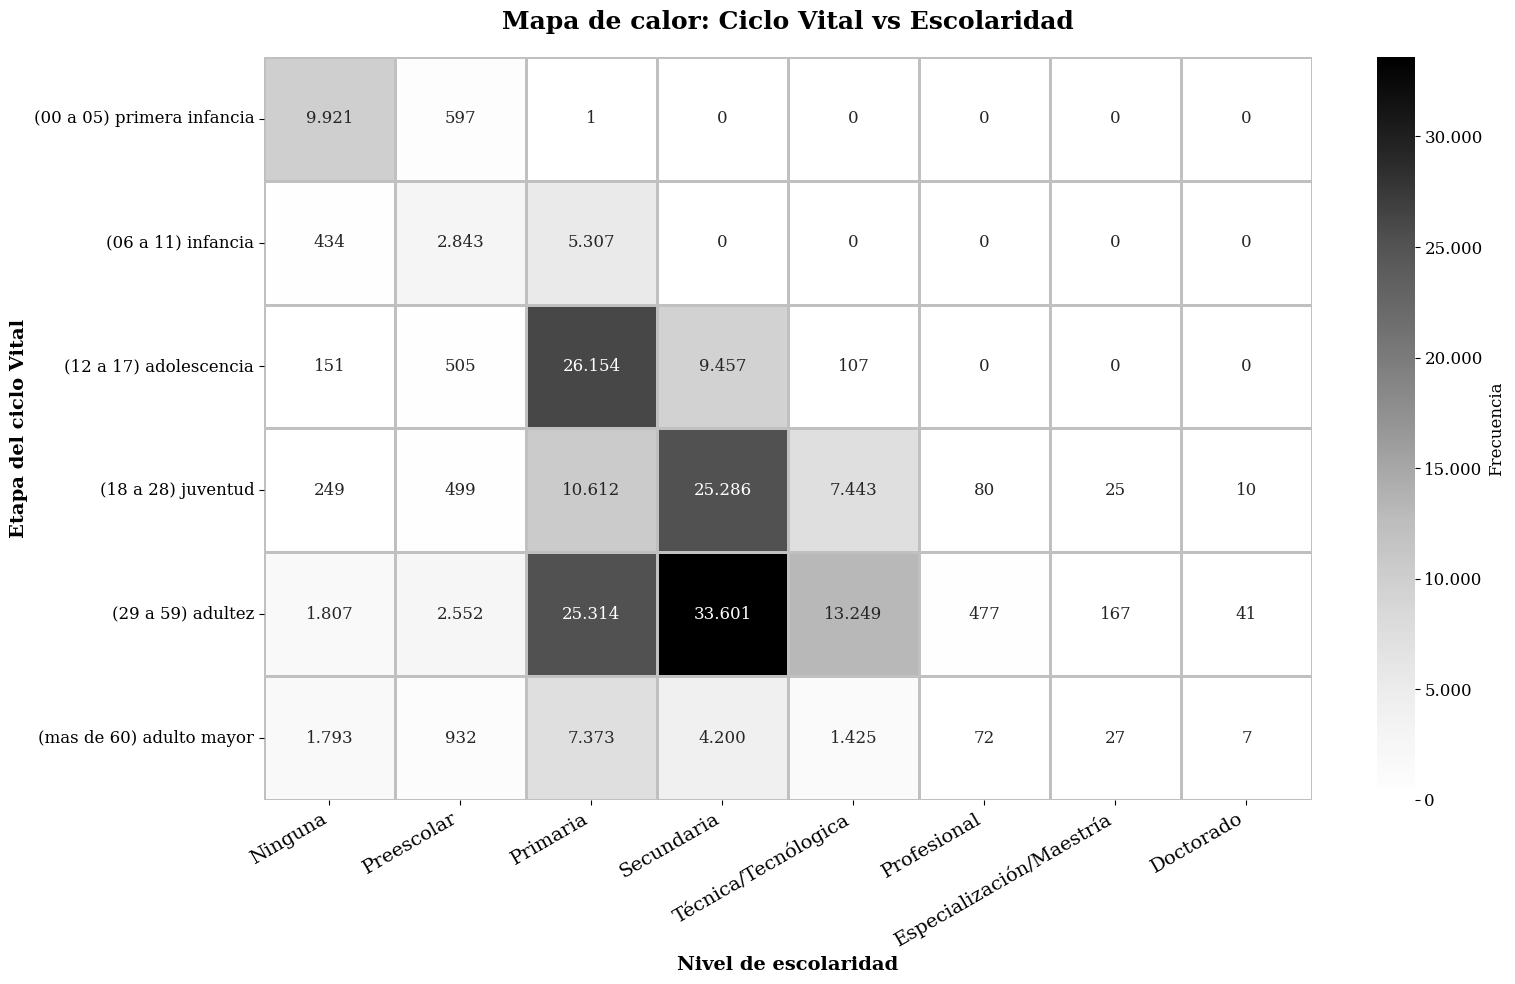

In [ ]:
#Creación de un mapa de calor a partir de la tabla de contingencia 1 (ciclo_vital vs escolaridad)
#1. Tamaño del gráfico
plt.figure(figsize=(16, 10))

# 2. Creación del mapa de calor
# Usamos el dataframe reordenado (contingency_table_1)
ax = sns.heatmap(
    contingency_table_1,
    annot=True,
    fmt=".0f", # Primero como flotante sin decimales para aplicar el separador después
    cmap='Greys',
    linewidths=.8,
    linecolor='silver',
    cbar_kws={'label': 'Frecuencia'}
)

# 3. Aplicar puntos de miles a las anotaciones dentro del mapa
for t in ax.texts:
    valor = float(t.get_text())
    t.set_text(f'{valor:,.0f}'.replace(',', '.'))

# 4. Formatear la barra de color (Leyenda lateral)
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 5. Títulos y etiquetas
plt.title('Mapa de calor: Ciclo Vital vs Escolaridad', fontsize=18, pad=20, fontweight='bold')
plt.xlabel('Nivel de escolaridad', fontsize=14, fontweight='bold')
plt.ylabel('Etapa del ciclo Vital', fontsize=14, fontweight='bold')

# Ajustar rotación para legibilidad
plt.xticks(rotation=30, ha='right', fontsize=14)
plt.yticks(rotation=0, fontsize=12)

#Ajustes finales y guardado
plt.tight_layout()

plt.show()

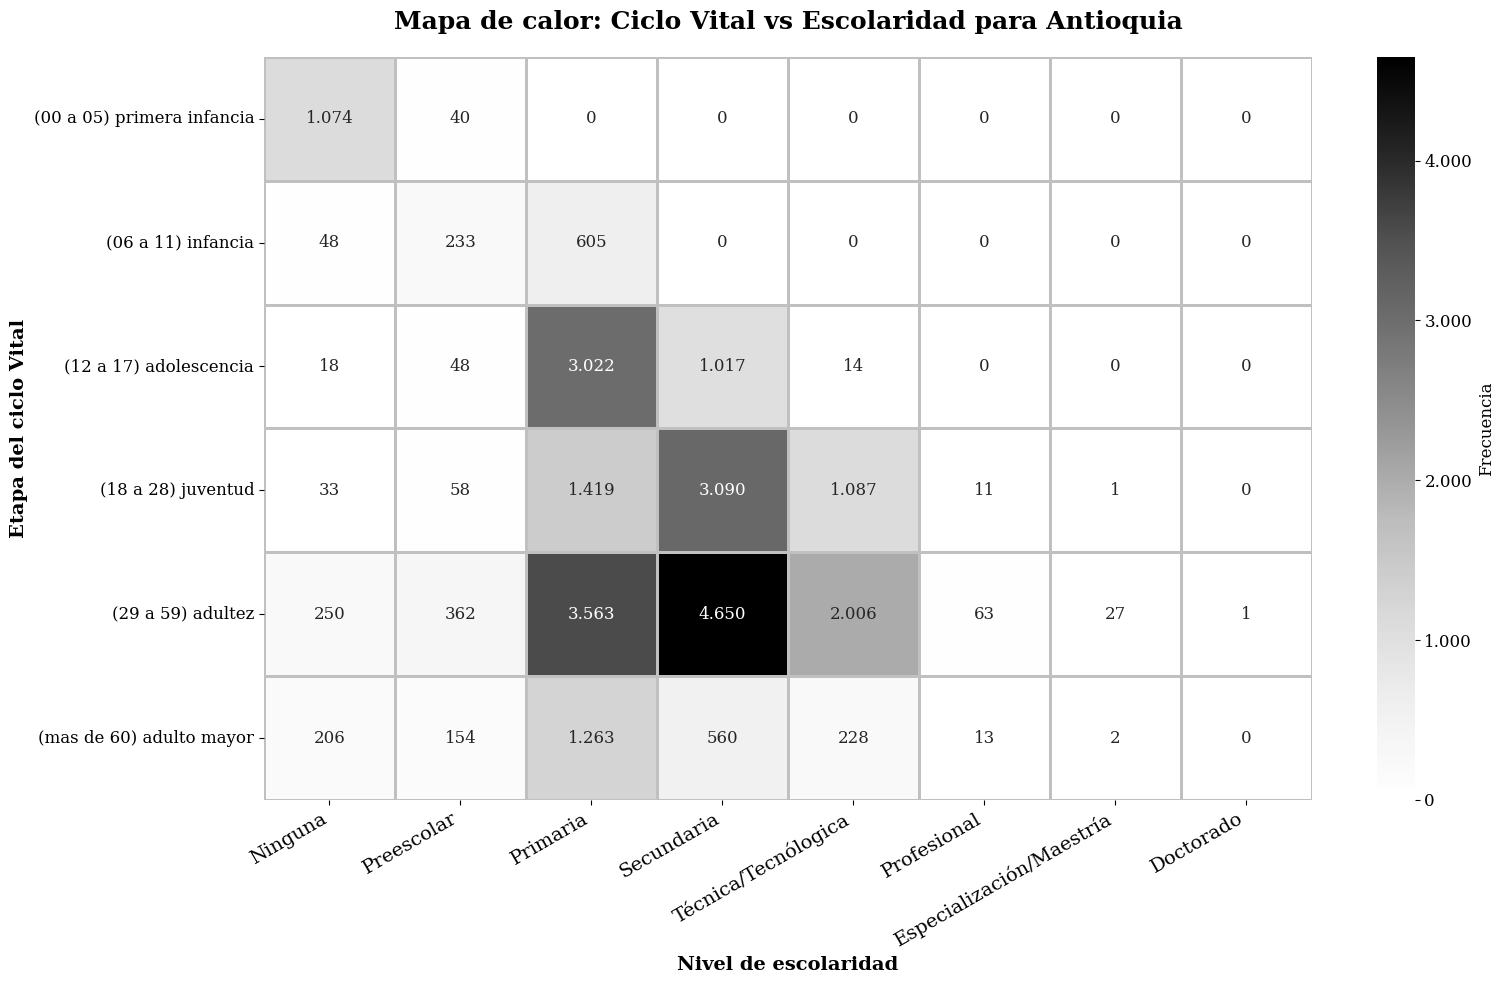

In [ ]:
#Creación de un mapa de calor a partir de la tabla de contingencia 1 Antioquia(ciclo_vital vs escolaridad)
#1. Tamaño del gráfico
plt.figure(figsize=(16, 10))

# 2. Creación del mapa de calor
# Usamos el dataframe reordenado (contingency_table_1)
ax = sns.heatmap(
    contingency_table_1_antioquia,
    annot=True,
    fmt=".0f", # Primero como flotante sin decimales para aplicar el separador después
    cmap='Greys',
    linewidths=.8,
    linecolor='silver',
    cbar_kws={'label': 'Frecuencia'}
)

# 3. Aplicar puntos de miles a las anotaciones dentro del mapa
for t in ax.texts:
    valor = float(t.get_text())
    t.set_text(f'{valor:,.0f}'.replace(',', '.'))

# 4. Formatear la barra de color (Leyenda lateral)
cbar = ax.collections[0].colorbar
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'{x:,.0f}'.replace(',', '.')))

# 5. Títulos y etiquetas
plt.title('Mapa de calor: Ciclo Vital vs Escolaridad para Antioquia', fontsize=18, pad=20, fontweight='bold')
plt.xlabel('Nivel de escolaridad', fontsize=14, fontweight='bold')
plt.ylabel('Etapa del ciclo Vital', fontsize=14, fontweight='bold')

# Ajustar rotación para legibilidad
plt.xticks(rotation=30, ha='right', fontsize=14)
plt.yticks(rotation=0, fontsize=12)

#Ajustes finales y guardado
plt.tight_layout()

plt.show()

In [ ]:
#Estandarización y conteo de valores de la columna (9) 'estado_civil'
df['estado_civil'] = df['estado_civil'].str.lower().replace(['sin informacion', 'no aplica'], np.nan)
display(df['estado_civil'].value_counts(dropna=False))
df['estado_civil'] = df['estado_civil'].str.capitalize()
df['estado_civil'].value_counts()

,count
estado_civil,
soltero (a),112118
union libre,49762
NaN,37189
casado (a),20726
"separado (a), divorciado (a)",10110
viudo (a),6935


,count
estado_civil,
Soltero (a),112118
Union libre,49762
Casado (a),20726
"Separado (a), divorciado (a)",10110
Viudo (a),6935


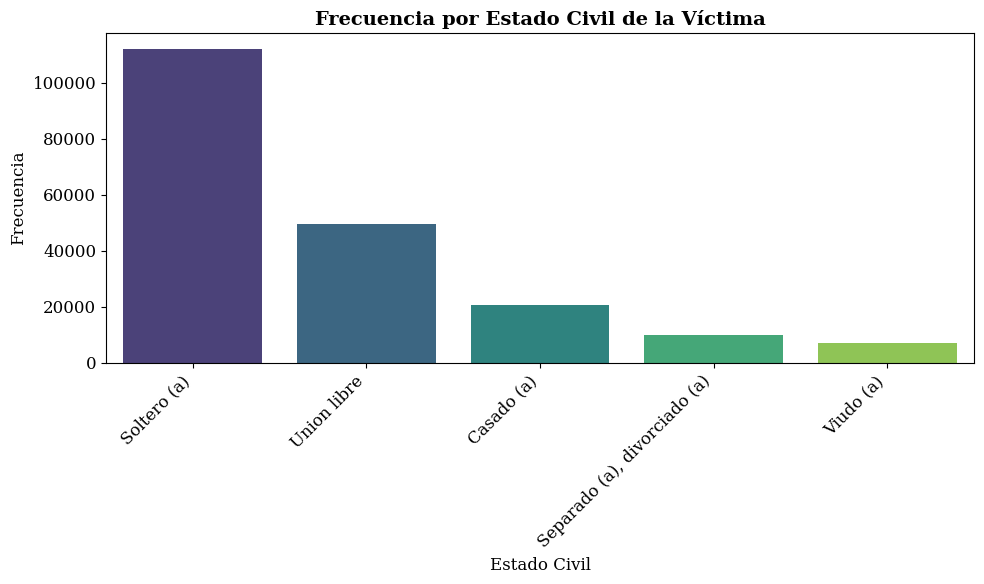

In [ ]:
#Gráfico de frecuencia de la columna (9) 'Estado Civil'
plt.figure(figsize=(10, 6))
sns.countplot(x='estado_civil', data=df, palette='viridis', hue='estado_civil', legend=False)
plt.title('Frecuencia por Estado Civil de la Víctima')
plt.xlabel('Estado Civil')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
#Conteo de valores de la columna (10) 'tipo_de_discapacidad'
df['tipo_de_discapacidad'].value_counts()

,count
tipo_de_discapacidad,
ninguna,235444
fisica,317
discapacidad multiple,290
auditiva,256
mental,219
visual,140
siquica,123
intelectual,38
psicosocial,13


In [ ]:
#Gráfico de frecuencia de la columna (10) 'tipo_de_discapacidad' (Colombia)
plt.figure(figsize=(12, 7))
ax = sns.countplot(x='tipo_de_discapacidad', data=df, palette='viridis', hue='tipo_de_discapacidad', legend=False)
plt.title('Frecuencia por tipo de discapacidad')
plt.xlabel('Tipo de discapacidad')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off

#Aplicación de escala logarítmica al gráfico ax
ax.set_yscale('log')
plt.show()

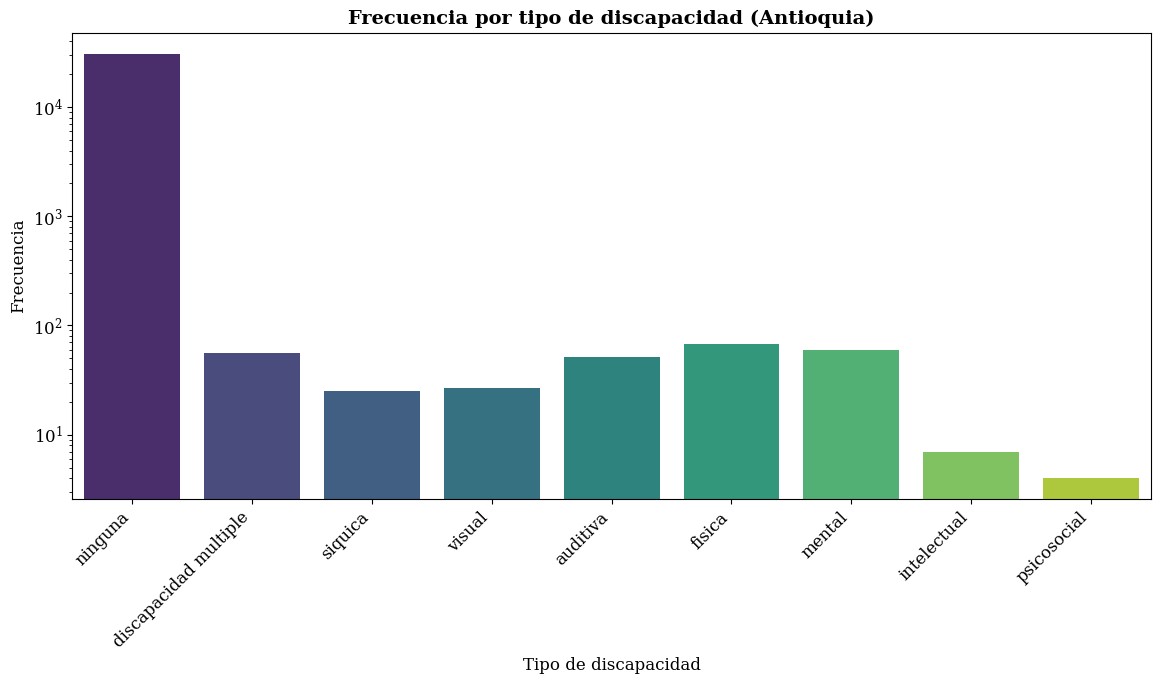

In [ ]:
#Gráfico de frecuencia de la columna 'tipo_de_discapacidad' (Antioquia)
plt.figure(figsize=(12, 7))
ax = sns.countplot(x='tipo_de_discapacidad', data=df_antioquia, palette='viridis', hue='tipo_de_discapacidad', legend=False)
plt.title('Frecuencia por tipo de discapacidad (Antioquia)')
plt.xlabel('Tipo de discapacidad')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off

#Aplicación de escala logarítmica al gráfico ax
ax.set_yscale('log')
plt.show()

In [ ]:
#Conteo de valores de la columna (11) 'pertenencia_etnica'
df['pertenencia_etnica'].value_counts()

,count
pertenencia_etnica,
sin pertenencia etnica,193470
sin informacion,35109
negro/afrodescendiente,5300
indigena,2312
raizal,596
palenquero,33
rom (gitano),20


In [ ]:
#Conteo de valores de la columna (11) 'pertenencia_etnica' (Antioquia)
df_antioquia['pertenencia_etnica'].value_counts()

,count
pertenencia_etnica,
sin pertenencia etnica,27514
sin informacion,3038
negro/afrodescendiente,488
indigena,41
raizal,6


In [ ]:
#LIMPIEZA DE LA COLUMNA (11) 'pertenencia_etnica'
# 1. Estandarización inicial (minúsculas y sin espacios)
df['pertenencia_etnica'] = df['pertenencia_etnica'].str.lower().str.strip()

# 2. Unificación de criterios
# Nota: 'sin informacion' pasa a ser NaN para limpieza técnica
reemplazos = {
    'sin información': np.nan,
    'rom (gitano)': 'rom (gitano)'
}
df['pertenencia_etnica'] = df['pertenencia_etnica'].replace(reemplazos)

# 3. Capitalizar el resultado
# Esto convertirá 'indígena' -> 'Indígena' y 'raizal' -> 'Raizal'
df['pertenencia_etnica'] = df['pertenencia_etnica'].str.capitalize()

# 4.Verificación
print(df['pertenencia_etnica'].value_counts(dropna=False))

pertenencia_etnica
Sin pertenencia etnica    193470
Sin informacion            35109
Negro/afrodescendiente      5300
Indigena                    2312
Raizal                       596
Palenquero                    33
Rom (gitano)                  20
Name: count, dtype: int64


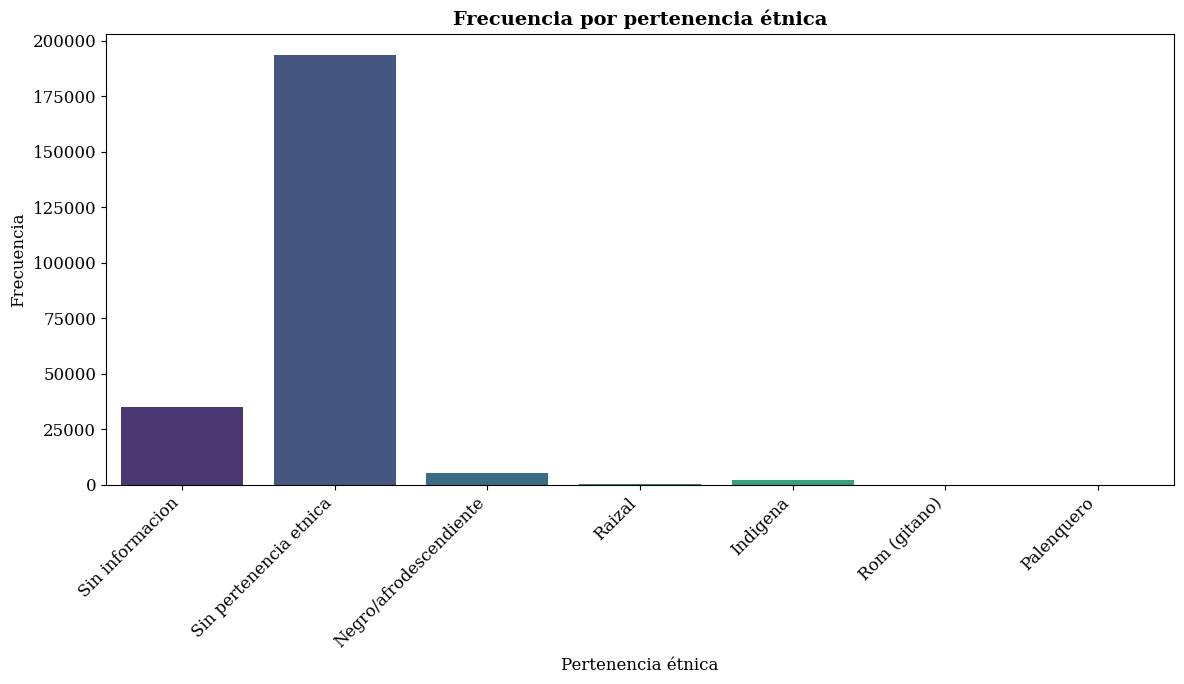

In [ ]:
# Frecuencia de la columna (11) 'pertenencia_étnica'
plt.figure(figsize=(12, 7))
sns.countplot(x='pertenencia_etnica', data=df, palette='viridis', hue='pertenencia_etnica', legend=False)
plt.title('Frecuencia por pertenencia étnica')
plt.xlabel('Pertenencia étnica')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
#Estandarización y conteo de valores de la columna (12) 'orientación_sexual'
df['orientacion_sexual'] = df['orientacion_sexual'].str.lower().replace(['no sabe / no informa', 'no aplica'], np.nan)
display(df['orientacion_sexual'].value_counts(dropna=False))
df['orientacion_sexual'] = df['orientacion_sexual'].str.capitalize()
df['orientacion_sexual'].value_counts()

,count
orientacion_sexual,
heterosexual,182877
NaN,52428
homosexual,1237
bisexual,254
asexual,44


,count
orientacion_sexual,
Heterosexual,182877
Homosexual,1237
Bisexual,254
Asexual,44


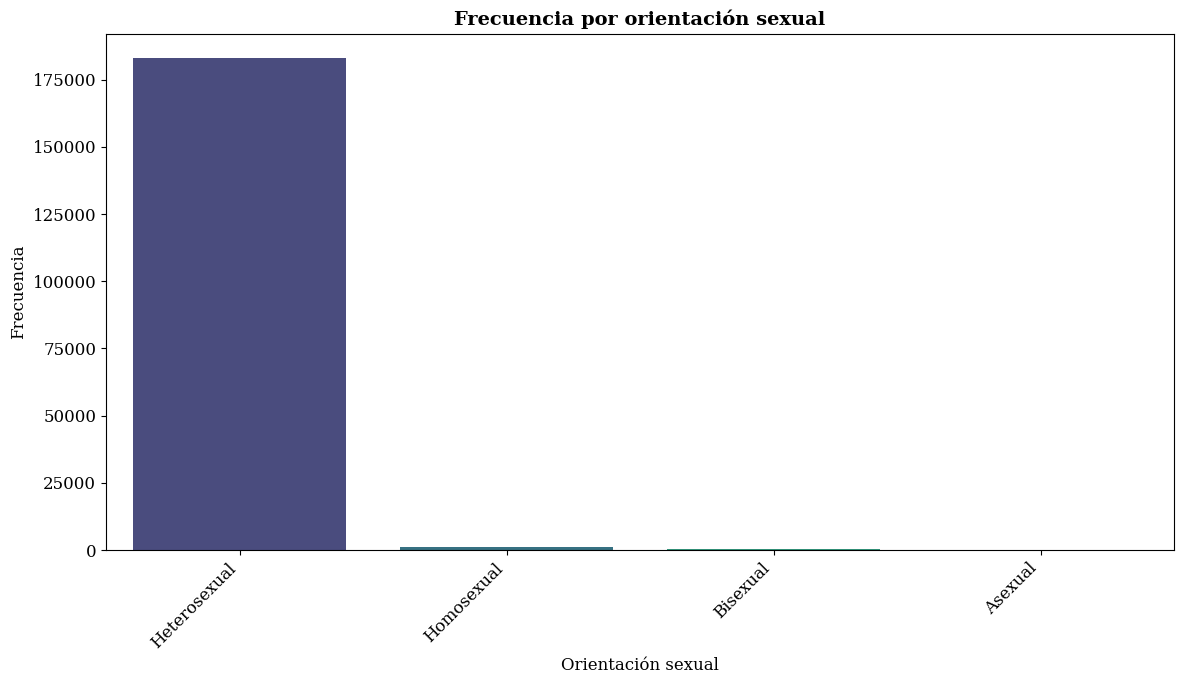

In [ ]:
#Gráfico de frecuencia de la columna 'orientacion_sexual'
plt.figure(figsize=(12, 7))
sns.countplot(x='orientacion_sexual', data=df, palette='viridis', hue='orientacion_sexual', legend=False)
plt.title('Frecuencia por orientación sexual')
plt.xlabel('Orientación sexual')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

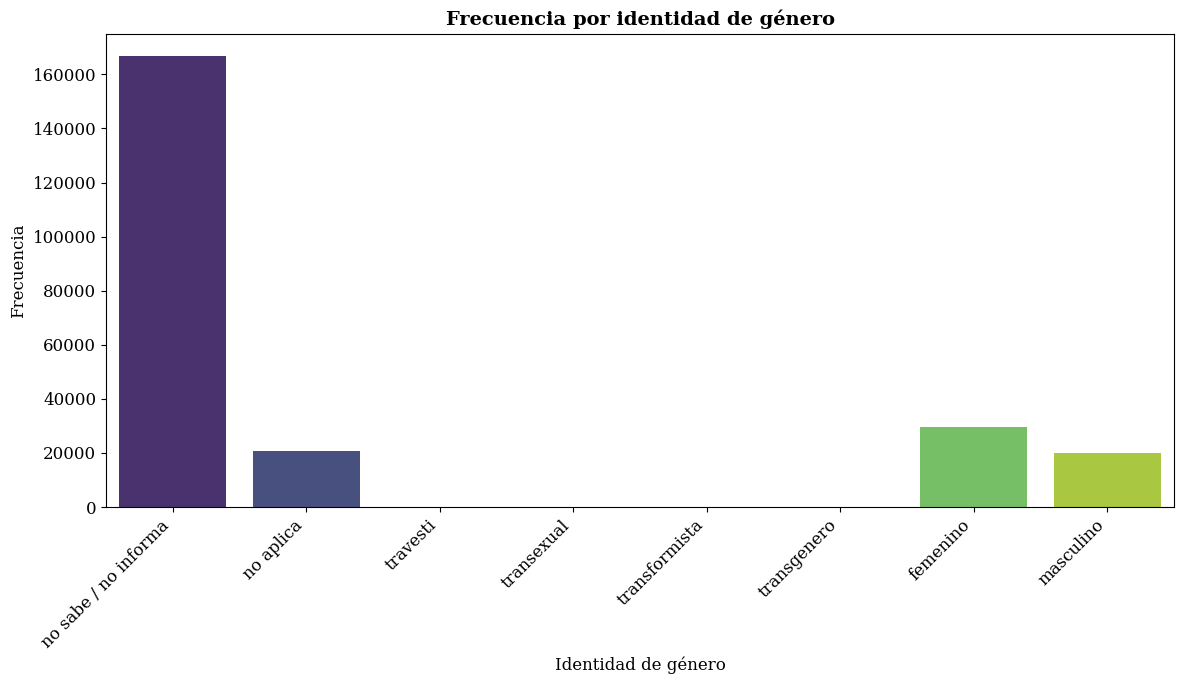

In [ ]:
#Gráfico de frecuencia de la columna (13) 'identidad_de_género'
plt.figure(figsize=(12, 7))
sns.countplot(x='identidad_de_genero', data=df, palette='viridis', hue='identidad_de_genero', legend=False)
plt.title('Frecuencia por identidad de género')
plt.xlabel('Identidad de género')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
#Tabla de tabulación cruzada entre 'sexo_de_la_víctima' y 'identidad_de_género'
contingency_table_2 = pd.crosstab(df['sexo_de_la_victima'], df['identidad_de_genero'], dropna=True)
display(contingency_table_2)

identidad_de_genero,femenino,masculino,no aplica,no sabe / no informa,transexual,transformista,transgenero,travesti
sexo_de_la_victima,,,,,,,,
hombre,238,19036,11099,65620,55,52,28,30
mujer,29219,772,9476,101043,54,73,39,6


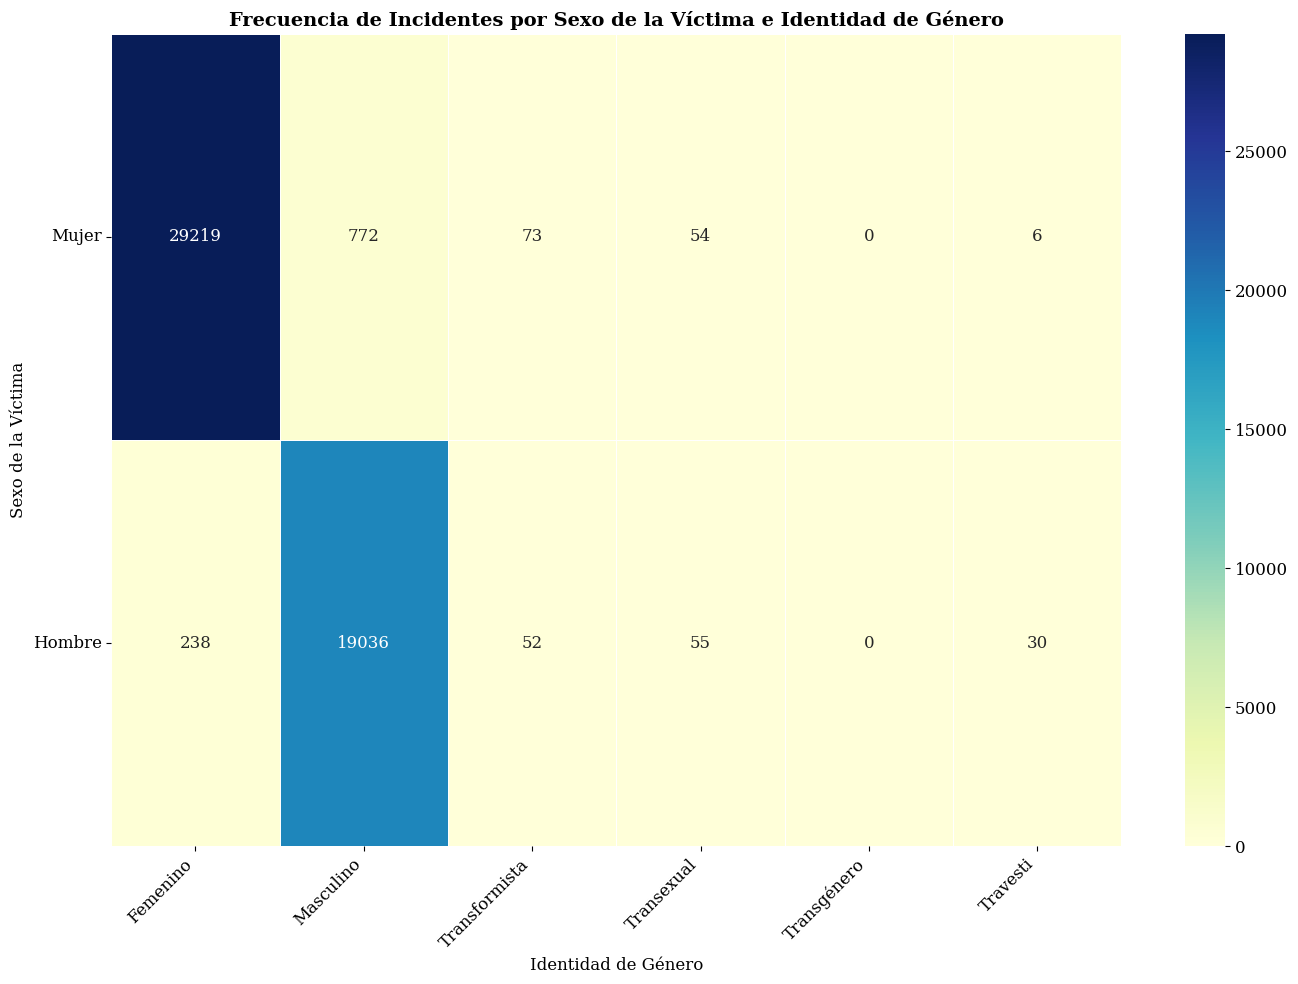

In [ ]:
# 1. Definir el orden del sexo y de la identidad de género
ordered_sex = ['mujer','hombre']
identitygen_order = ['femenino', 'masculino', 'transformista', 'transexual', 'transgénero', 'travesti']

# 1.1.(Opcional pero recomendado) Asegurar que en el DataFrame también tenga la tilde
# Esto corrige el valor antes de crear la tabla de contingencia
df['identidad_de_genero'] = df['identidad_de_genero'].str.lower().replace('transgenero', 'transgénero')

#Esto se incluye porque el mapa de calor estaba dando valores de cero a la categoría "transgénero" debido a que,
# en el DataFrame original no tenía la tilde, y al capitalizarlo para el gráfico, se creó una categoría
# nueva "Transgénero" que no coincidía con los datos originales. Al corregir el valor en el DataFrame antes de crear
# la tabla de contingencia, aseguramos que los datos se agrupen correctamente bajo la categoría "Transgénero" y se
# reflejen en el mapa de calor sin valores de cero inesperados.

#2. Capitalizar las listas para que se vean bien en el gráfico
ordered_sex = [s.capitalize() for s in ordered_sex]
identitygen_order = [i.capitalize() for i in identitygen_order]

# 3. Capitalizar los índices y columnas de la tabla ORIGINAL para que coincidan con las listas
contingency_table_2.index = contingency_table_2.index.str.capitalize()
contingency_table_2.columns = contingency_table_2.columns.str.capitalize()

# 4. Reindexar (Ahora que todo está capitalizado, coincidirán perfectamente)
contingency_table_ordered_2 = contingency_table_2.reindex(
    index=ordered_sex,
    columns=identitygen_order,
    fill_value=0
)
# 5. Crear el mapa de calor
plt.figure(figsize=(14, 10))

# Nota: si los valores son muy dispares, recuerda que puedes usar norm=LogNorm()
sns.heatmap(contingency_table_ordered_2, annot=True, fmt='d', cmap='YlGnBu', linewidths=.5)

plt.title('Frecuencia de Incidentes por Sexo de la Víctima e Identidad de Género')
plt.xlabel('Identidad de Género')
plt.ylabel('Sexo de la Víctima')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
#Conteo de valores únicos de la columna (14) 'transgenero'
df['transgenero'].value_counts()

,count
transgenero,
no sabe / no informa,216265
no aplica,20575


In [ ]:
# 1. Quitamos espacios invisibles y ponemos la primera letra en mayúscula
# Esto convierte tanto 'No aplica' como 'No Aplica' en 'No aplica'
df['transgenero'] = df['transgenero'].str.strip().str.capitalize()

# 2. (Opcional) Si prefieres que 'No sabe / no informa' conserve todas sus mayúsculas:
df['transgenero'] = df['transgenero'].replace('No sabe / no informa', 'No Sabe / No Informa')

# Verificación
print(df['transgenero'].value_counts())

transgenero
No Sabe / No Informa    216265
No aplica                20575
Name: count, dtype: int64


In [ ]:
#Conteo de valores de la columna (15) 'pertenencia_grupal'
df['pertenencia_grupal'].value_counts()

,count
pertenencia_grupal,
ninguno,181645
sin informacion,31020
persona adicta a una droga natural o sintetica,5965
"consumidores de sustancias psicoactivas (drogas, alcohol, etc.)",5130
grupos etnicos,2670
...,...
hopper,1
defensores de derechos humanos,1
personas que ejercen actividades de periodismo,1


In [ ]:
#Conteo de valores de la columna (16) 'mes_del_hecho'
df['mes_del_hecho'].value_counts()

,count
mes_del_hecho,
mayo,21435
septiembre,21070
agosto,21031
marzo,20942
febrero,20386
julio,20033
enero,19718
octubre,19509
abril,19038


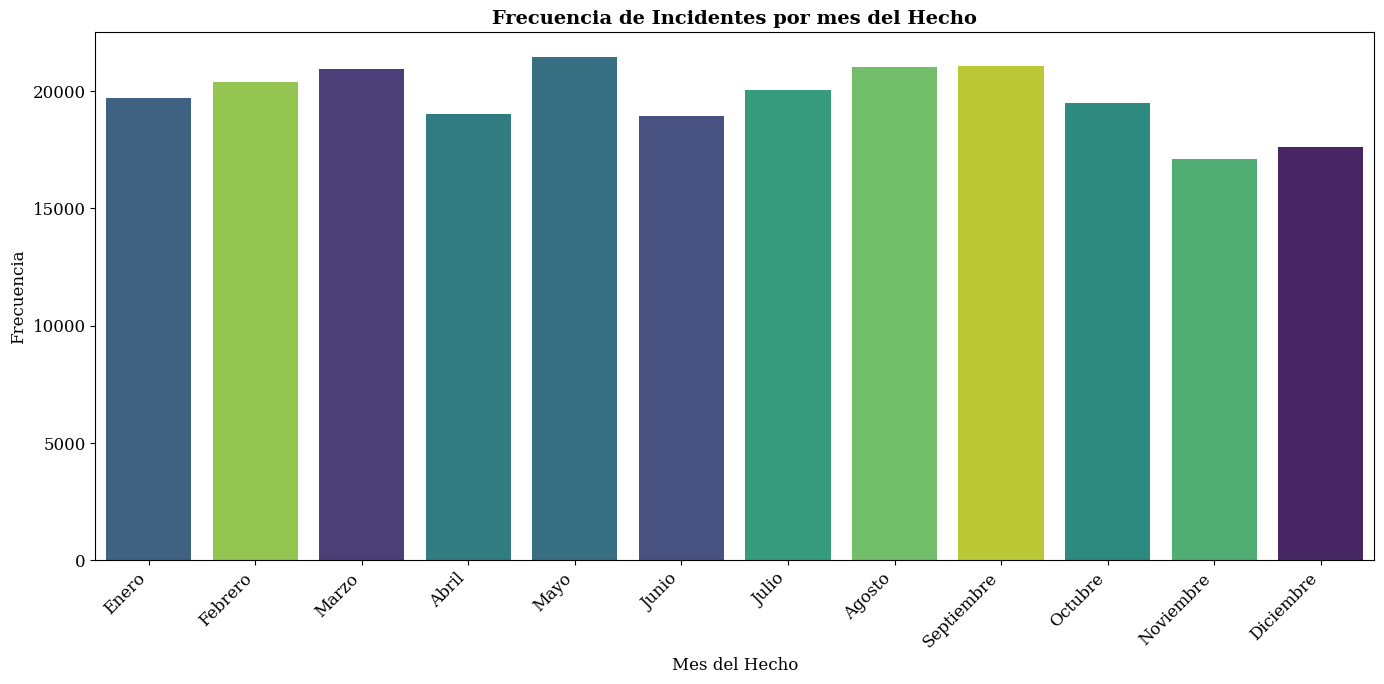

In [ ]:
# Definir el orden estricto de los meses del año (con capitalización para el gráfico)
orden_meses = [
    'Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
    'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
]

# Capitalizar los valores de la columna 'month_order' solo para la visualización en el gráfico
df['mes_del_hecho_capitalized'] = df['mes_del_hecho'].str.title()

##Gráfico de frecuencia de la columna (16) 'mes_del_hecho'
plt.figure(figsize=(14, 7))
sns.countplot(x='mes_del_hecho_capitalized', data=df, palette='viridis', hue='mes_del_hecho_capitalized', legend=False, order=orden_meses)
plt.title('Frecuencia de Incidentes por mes del Hecho')
plt.xlabel('Mes del Hecho')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()


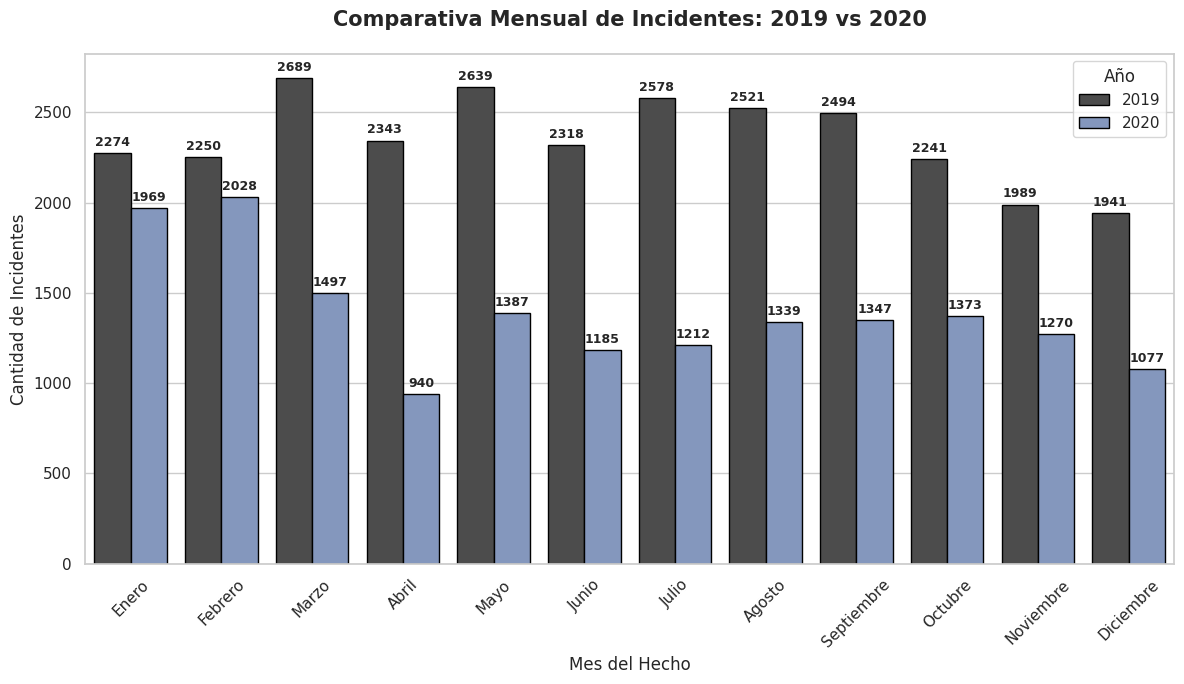

In [ ]:
# 1. Filtrar solo los dos años que nos interesan
df_comparativo = df[df['ano_del_hecho'].isin([2019, 2020])]

# 2. Configurar el gráfico
plt.figure(figsize=(12, 7))
sns.set_theme(style="whitegrid")

# 3. Usamos 'hue' para separar por año
ax = sns.countplot(data=df_comparativo,
                   x='mes_del_hecho_capitalized',
                   hue='ano_del_hecho',
                   order=orden_meses,
                   palette=['#4c4c4c', '#7a94c6'], # Gris para 2019, Azul para 2020
                   edgecolor='black')

# 4. Añadir etiquetas sobre las barras
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9, fontweight='bold')

# 5. Estética final
plt.title('Comparativa Mensual de Incidentes: 2019 vs 2020', fontsize=15, pad=20)
plt.xlabel('Mes del Hecho')
plt.ylabel('Cantidad de Incidentes')
plt.legend(title='Año', loc='upper right')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

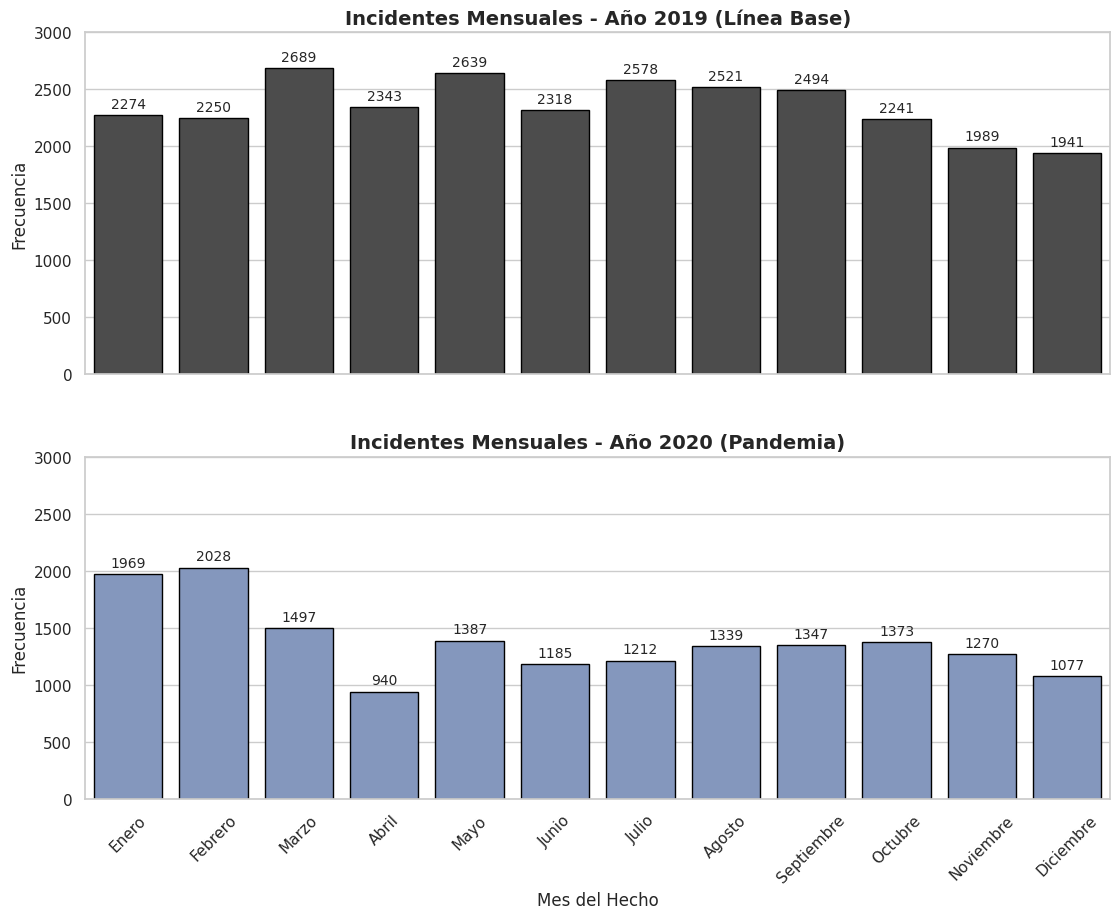

In [ ]:
#Creación de subplots para el 2019 y el 2020
# 2. Crear la figura con dos espacios (filas)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
sns.set_theme(style="whitegrid")

# --- Gráfico superior (2019) ---
df_2019 = df[df['ano_del_hecho'] == 2019]
sns.countplot(data=df_2019, x='mes_del_hecho_capitalized', order=orden_meses, color='#4c4c4c', ax=ax1, edgecolor='black')
ax1.set_title('Incidentes Mensuales - Año 2019 (Línea Base)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Frecuencia')
ax1.set_ylim(0, 3000) # <--- Escala fija
ax1.set_xlabel('') # Quitamos el nombre del eje X arriba para que no estorbe
ax1.bar_label(ax1.containers[0], padding=3, fontsize=10)

# --- Gráfico inferior (2020) ---
df_2020 = df[df['ano_del_hecho'] == 2020]
sns.countplot(data=df_2020, x='mes_del_hecho_capitalized', order=orden_meses, color='#7a94c6', ax=ax2, edgecolor='black')
ax2.set_title('Incidentes Mensuales - Año 2020 (Pandemia)', fontsize=14, fontweight='bold')
ax2.set_ylabel('Frecuencia')
ax2.set_xlabel('Mes del Hecho')
ax2.set_ylim(0, 3000) # <--- Escala fija
ax2.bar_label(ax2.containers[0], padding=3, fontsize=10)

# 3. Ajustes finales
plt.xticks(rotation=45) # Esto aplicará a las etiquetas de abajo gracias a sharex=True
plt.tight_layout(pad=3.0) # Añade espacio entre los dos gráficos para que no se pisen

plt.show()


In [ ]:
#Conteo de valores para la columna (17) 'día_del_hecho'
df['dia_del_hecho'].value_counts()

,count
dia_del_hecho,
domingo,46617
lunes,35112
martes,32748
miercoles,32337
sabado,31664
jueves,30464
viernes,27898


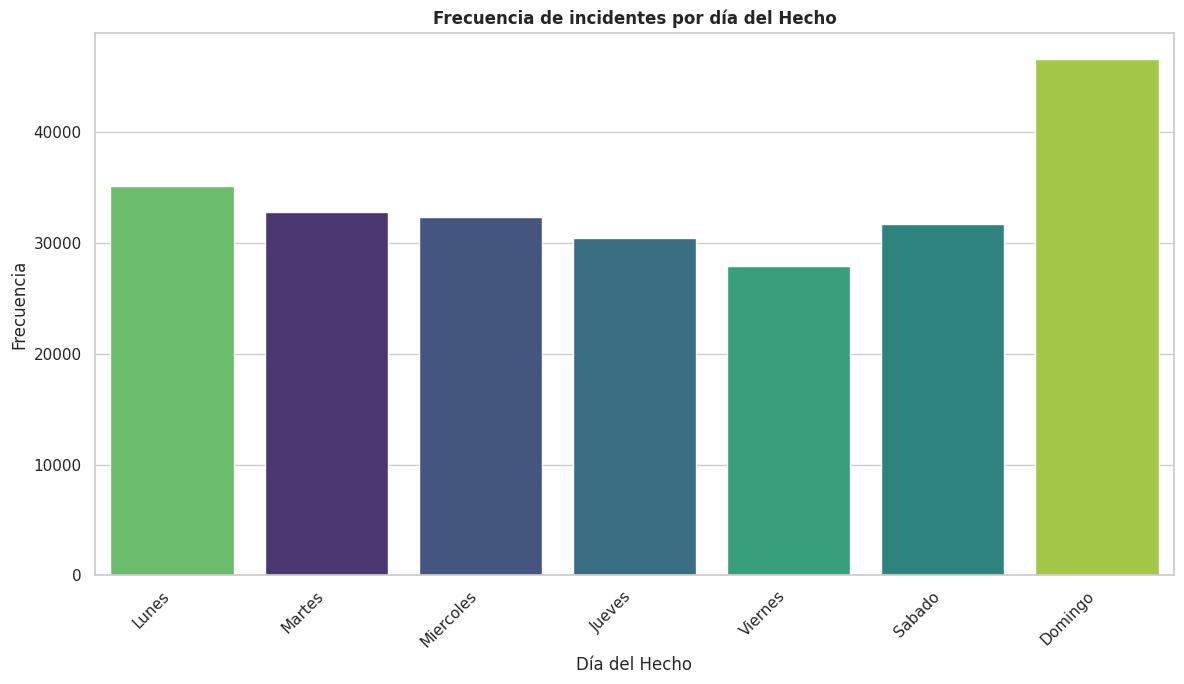

In [ ]:
# Definir el orden estricto de los días de la semana
day_order = [
    'Lunes', 'Martes', 'Miercoles', 'Jueves', 'Viernes', 'Sabado', 'Domingo'
]

# Capitalizar los valores de la columna 'day_order' solo para la visualización en el gráfico
df['dia_del_hecho_capitalized'] = df['dia_del_hecho'].str.title()

#Gráfico de frecuencia de la columna (17) 'día_del_hecho'
plt.figure(figsize=(12, 7))
sns.countplot(x='dia_del_hecho_capitalized', data=df, palette='viridis', hue='dia_del_hecho_capitalized', legend=False, order=day_order)
plt.title('Frecuencia de incidentes por día del Hecho')
plt.xlabel('Día del Hecho')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
#Conteo de valores para la columna (18) 'rango_de_hora_del_hecho_x_3_horas'
df['rango_de_hora_del_hecho_x_3_horas'].value_counts()

,count
rango_de_hora_del_hecho_x_3_horas,
(18:00 a 20:59),44689
(15:00 a 17:59),33811
(09:00 a 11:59),32298
sin informacion,31887
(12:00 a 14:59),31504
(21:00 a 23:59),28361
(06:00 a 08:59),18230
(00:00 a 02:59),8913
(03:00 a 05:59),7147


In [ ]:
#sin informacion = nan
df['rango_de_hora_del_hecho_x_3_horas'] = df['rango_de_hora_del_hecho_x_3_horas'].str.lower().replace(['sin informacion'], np.nan)
display(df['rango_de_hora_del_hecho_x_3_horas'].value_counts(dropna=False))

In [ ]:
# Definir el orden estricto de los rangos de hora
hour_range_order = [
    '(00:00 a 02:59)', '(03:00 a 05:59)', '(06:00 a 08:59)', '(09:00 a 11:59)',
    '(12:00 a 14:59)', '(15:00 a 17:59)', '(18:00 a 20:59)', '(21:00 a 23:59)'
]

#Gráfico de frecuencia de la columna (18) 'rango_de_hora_del_hecho_x_3_horas'
plt.figure(figsize=(12, 7))
sns.countplot(x='rango_de_hora_del_hecho_x_3_horas', data=df, palette='viridis', hue='rango_de_hora_del_hecho_x_3_horas', legend=False, order=hour_range_order)
plt.title('Frecuencia de incidentes por rango de hora (cada 3 horas)')
plt.xlabel('Rango de hora del hecho')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

In [ ]:
#Conteo de valores de la columna (19) 'codigo_dane_municipio'
df['codigo_dane_municipio'].value_counts()

,count
codigo_dane_municipio,
11001,61428
5001,16239
76001,8015
8001,6700
50001,5647
...,...
15090,1
15832,1
27075,1


In [ ]:
# Mostrar los valores únicos y su conteo antes de las correcciones
display(df['municipio_del_hecho_dane'].value_counts(dropna=False).head(20))

,count
municipio_del_hecho_dane,
"bogota, d.c.",61428
medellin,16239
cali,8015
barranquilla,6700
villavicencio,5647
soacha,4867
ibague,4230
cucuta,4182
cartagena de indias,3868


In [ ]:
# Definir un diccionario de correcciones ortográficas para los municipios
municipio_corrections = {
    'bogota, d.c.': 'Bogotá, D.C.',
    'medellin': 'Medellín',
    'cali': 'Cali',
    'barranquilla': 'Barranquilla',
    'villavicencio': 'Villavicencio',
    'cartagena': 'Cartagena',
    'cucuta': 'Cúcuta',
    'bucaramanga': 'Bucaramanga',
    'soacha': 'Soacha',
    'ibague': 'Ibagué',
    'soledad': 'Soledad',
    'pereira': 'Pereira',
    'monteria': 'Montería',
    'pasto': 'Pasto',
    'neiva': 'Neiva',
    'manizales': 'Manizales',
    'armenia': 'Armenia',
    'valledupar': 'Valledupar',
    'sincelejo': 'Sincelejo',
    'popayan': 'Popayán',
    'florencia': 'Florencia',
    'yopal': 'Yopal',
    'quibdo': 'Quibdó',
    'puerto carreño': 'Puerto Carreño',
    'mocoa': 'Mocoa',
    'arauca': 'Arauca',
    'san jose del guaviare': 'San José del Guaviare',
    'mitu': 'Mitú',
    'inirida': 'Inírida',
    'puerto colombia': 'Puerto Colombia'
}

# Aplicar las correcciones a la columna 'municipio_del_hecho_dane'
df['municipio_del_hecho_dane'] = df['municipio_del_hecho_dane'].replace(municipio_corrections)

# Mostrar los valores únicos y su conteo DESPUÉS de las correcciones
display(df['municipio_del_hecho_dane'].value_counts(dropna=False).head(20))

,count
municipio_del_hecho_dane,
"Bogotá, D.C.",61428
Medellín,16239
Cali,8015
Barranquilla,6700
Villavicencio,5647
Soacha,4867
Ibagué,4230
Cúcuta,4182
cartagena de indias,3868


In [ ]:
# Capitalizar la primera letra de cada palabra en la columna 'municipio_del_hecho_dane'
df['municipio_del_hecho_dane'] = df['municipio_del_hecho_dane'].str.title()

# Mostrar los valores únicos y su conteo después de la modificación
display(df['municipio_del_hecho_dane'].value_counts(dropna=False).head(20))

,count
municipio_del_hecho_dane,
"Bogotá, D.C.",61428
Medellín,16239
Cali,8015
Barranquilla,6700
Villavicencio,5647
Soacha,4867
Ibagué,4230
Cúcuta,4182
Cartagena De Indias,3868


In [ ]:
#lista de todos los municipios únicos en orden alfabético
municipios_sorted = sorted(df['municipio_del_hecho_dane'].dropna().unique())
display(municipios_sorted)

['Abejorral',
 'Abrego',
 'Acacias',
 'Acandi',
 'Acevedo',
 'Achi',
 'Agrado',
 'Agua De Dios',
 'Aguachica',
 'Aguada',
 'Aguadas',
 'Aguazul',
 'Agustin Codazzi',
 'Aipe',
 'Alban',
 'Albania',
 'Alcala',
 'Aldana',
 'Alejandria',
 'Algarrobo',
 'Algeciras',
 'Almaguer',
 'Almeida',
 'Alpujarra',
 'Altamira',
 'Altos Del Rosario',
 'Alvarado',
 'Amaga',
 'Amalfi',
 'Ambalema',
 'Anapoima',
 'Ancuya',
 'Andalucia',
 'Andes',
 'Angelopolis',
 'Angostura',
 'Anolaima',
 'Anori',
 'Anserma',
 'Ansermanuevo',
 'Anza',
 'Anzoategui',
 'Apartado',
 'Apia',
 'Apulo',
 'Aquitania',
 'Aracataca',
 'Aranzazu',
 'Aratoca',
 'Arauca',
 'Arauquita',
 'Arbelaez',
 'Arboleda',
 'Arboledas',
 'Arboletes',
 'Arcabuco',
 'Arenal',
 'Argelia',
 'Ariguani',
 'Arjona',
 'Armenia',
 'Armero Guayabal',
 'Arroyohondo',
 'Astrea',
 'Ataco',
 'Atrato',
 'Ayapel',
 'Bahia Solano',
 'Bajo Baudo',
 'Balboa',
 'Baranoa',
 'Baraya',
 'Barbacoas',
 'Barbosa',
 'Barichara',
 'Barranca De Upia',
 'Barrancabermeja',
 

In [ ]:
#Muestra para cada entrada que contenga un valor numérico en la columna 'municipio_del_hecho_dane', su respectivo código_dane_municipio.
#Por 'municipio_del_hecho_dane'
# Seleccionar las dos columnas de interés y eliminar duplicados para ver el mapeo único
municipio_dane_mapping = df[['codigo_dane_municipio', 'municipio_del_hecho_dane']].drop_duplicates()

# Ordenar por el nombre del municipio para una mejor visualización
municipio_dane_mapping = municipio_dane_mapping.sort_values(by='municipio_del_hecho_dane').reset_index(drop=True)

display(municipio_dane_mapping)

,codigo_dane_municipio,municipio_del_hecho_dane
0,5002,Abejorral
1,54003,Abrego
2,50006,Acacias
3,27006,Acandi
4,41006,Acevedo
...,...,...
1072,76895,Zarzal
1073,15897,Zetaquira
1074,25898,Zipacon
1075,25899,Zipaquira


In [ ]:
# Por 'código_dane_municipio',
# Seleccionar las dos columnas de interés y eliminar duplicados para ver el mapeo único
municipio_dane_mapping = df[['codigo_dane_municipio', 'municipio_del_hecho_dane']].drop_duplicates()

# Ordenar por el código DANE en orden numérico
municipio_dane_mapping = municipio_dane_mapping.sort_values(by='codigo_dane_municipio').reset_index(drop=True)

display(municipio_dane_mapping)

,codigo_dane_municipio,municipio_del_hecho_dane
0,999,Sin Informacion
1,5001,Medellín
2,5002,Abejorral
3,5021,Alejandria
4,5030,Amaga
...,...,...
1072,97511,Pacoa
1073,97666,Taraira
1074,99001,Puerto Carreno
1075,99524,La Primavera


In [ ]:
#sin informacion = nan
df['municipio_del_hecho_dane'] = df['municipio_del_hecho_dane'].replace(['sin informacion'], np.nan)
display(df['municipio_del_hecho_dane'].value_counts(dropna=False))
df['municipio_del_hecho_dane'].value_counts()

,count
municipio_del_hecho_dane,
"Bogotá, D.C.",61428
Medellín,16239
Cali,8015
Barranquilla,6700
Villavicencio,5647
...,...
El Cocuy,1
Chiscas,1
Jordan,1


,count
municipio_del_hecho_dane,
"Bogotá, D.C.",61428
Medellín,16239
Cali,8015
Barranquilla,6700
Villavicencio,5647
...,...
El Cocuy,1
Chiscas,1
Jordan,1


In [ ]:
# Mostrar los valores únicos y su conteo ANTES de la capitalización
display(df['departamento_del_hecho_dane'].value_counts(dropna=False).head(20))

,count
departamento_del_hecho_dane,
"bogota, d.c.",61428
antioquia,31087
cundinamarca,19337
valle del cauca,14734
santander,11705
atlantico,10687
tolima,8242
boyaca,8099
meta,7525


In [ ]:
# Capitalizar la primera letra de cada palabra en la columna 'departamento_del_hecho_dane'
df['departamento_del_hecho_dane'] = df['departamento_del_hecho_dane'].str.title()

# Mostrar los valores únicos y su conteo DESPUÉS de la capitalización
display(df['departamento_del_hecho_dane'].value_counts(dropna=False).head(20))

,count
departamento_del_hecho_dane,
"Bogota, D.C.",61428
Antioquia,31087
Cundinamarca,19337
Valle Del Cauca,14734
Santander,11705
Atlantico,10687
Tolima,8242
Boyaca,8099
Meta,7525


In [ ]:
#Listado de los Departamentos en orden alfabético (Valores únicos)
departamentos_sorted = sorted(df['departamento_del_hecho_dane'].dropna().unique())
display(departamentos_sorted)

['Amazonas',
 'Antioquia',
 'Arauca',
 'Archipielago De San Andres, Providencia Y Santa Catalina',
 'Atlantico',
 'Bogota, D.C.',
 'Bolivar',
 'Boyaca',
 'Caldas',
 'Caqueta',
 'Casanare',
 'Cauca',
 'Cesar',
 'Choco',
 'Cordoba',
 'Cundinamarca',
 'Guainia',
 'Guaviare',
 'Huila',
 'La Guajira',
 'Magdalena',
 'Meta',
 'Narino',
 'Norte De Santander',
 'Putumayo',
 'Quindio',
 'Risaralda',
 'Santander',
 'Sin Informacion',
 'Sucre',
 'Tolima',
 'Valle Del Cauca',
 'Vaupes',
 'Vichada']

In [ ]:
# Definir un diccionario de correcciones ortográficas para los departamentos específicos
specific_departamento_corrections = {
    'Archipielago De San Andres, Providencia Y Santa Catalina': 'Archipiélago de San Andrés, Providencia y Santa Catalina',
    'Atlantico': 'Atlántico',
    'Bogota, D.C.': 'Bogotá, D.C.',
    'Bolivar': 'Bolívar',
    'Boyaca': 'Boyacá',
    'Caqueta': 'Caquetá',
    'Choco': 'Chocó',
    'Cordoba': 'Córdoba',
    'Guainia': 'Guainía',
    'Narino': 'Nariño',
    'Quindio': 'Quindío',
    'Vaupes': 'Vaupés'
}

# Aplicar las correcciones a la columna 'departamento_del_hecho_dane'
df['departamento_del_hecho_dane'] = df['departamento_del_hecho_dane'].replace(specific_departamento_corrections)

In [ ]:
# Mostrar los valores únicos y su conteo después de las correcciones específicas por conteo de índices
display(df['departamento_del_hecho_dane'].value_counts(dropna=False).head(df['departamento_del_hecho_dane'].nunique()))

,count
departamento_del_hecho_dane,
"Bogotá, D.C.",61428
Antioquia,31087
Cundinamarca,19337
Valle Del Cauca,14734
Santander,11705
Atlántico,10687
Tolima,8242
Boyacá,8099
Meta,7525


In [ ]:
#Sin informacion por NaN en la columna 'departamento_del_hecho_dane'
df['departamento_del_hecho_dane'] = df['departamento_del_hecho_dane'].replace(['sin informacion'], np.nan)
display(df['departamento_del_hecho_dane'].value_counts(dropna=False))
df['departamento_del_hecho_dane'].value_counts()

,count
departamento_del_hecho_dane,
"Bogotá, D.C.",61428
Antioquia,31087
Cundinamarca,19337
Valle Del Cauca,14734
Santander,11705
Atlántico,10687
Tolima,8242
Boyacá,8099
Meta,7525


,count
departamento_del_hecho_dane,
"Bogotá, D.C.",61428
Antioquia,31087
Cundinamarca,19337
Valle Del Cauca,14734
Santander,11705
Atlántico,10687
Tolima,8242
Boyacá,8099
Meta,7525


In [ ]:
#Conteo de valores únicos de la columna'código_dane_departamento'
display(df['codigo_dane_departamento'].nunique())

34

In [ ]:
# Mostrar los valores únicos y su conteo después de las correcciones específicas, ordenados alfabéticamente
display(df['departamento_del_hecho_dane'].value_counts(dropna=False).sort_index())

,count
departamento_del_hecho_dane,
Amazonas,805
Antioquia,31087
Arauca,2415
"Archipiélago de San Andrés, Providencia y Santa Catalina",654
Atlántico,10687
"Bogotá, D.C.",61428
Bolívar,5626
Boyacá,8099
Caldas,2900


In [ ]:
#Muestra para cada entrada que contenga un valor numérico en la columna 'departamento_del_hecho_dane', su respectivo código_dane_departamento.
#Por 'departamento_del_hecho_dane'
# Seleccionar las dos columnas de interés y eliminar duplicados para ver el mapeo único
departamento_dane_mapping = df[['codigo_dane_departamento', 'departamento_del_hecho_dane']].drop_duplicates()

# Ordenar por el nombre del departamento para una mejor visualización
departamento_dane_mapping = departamento_dane_mapping.sort_values(by='departamento_del_hecho_dane').reset_index(drop=True)
display(departamento_dane_mapping)


,codigo_dane_departamento,departamento_del_hecho_dane
0,91,Amazonas
1,5,Antioquia
2,81,Arauca
3,88,"Archipiélago de San Andrés, Providencia y Sant..."
4,8,Atlántico
5,11,"Bogotá, D.C."
6,13,Bolívar
7,15,Boyacá
8,17,Caldas
9,18,Caquetá


In [ ]:
# Por 'código_dane_departamento',
# Seleccionar las dos columnas de interés y eliminar duplicados para ver el mapeo único
departamento_dane_mapping = df[['codigo_dane_departamento', 'departamento_del_hecho_dane']].drop_duplicates()

# Ordenar por el código DANE en orden numérico
departamento_dane_mapping = departamento_dane_mapping.sort_values(by='codigo_dane_departamento').reset_index(drop=True)

display(departamento_dane_mapping)

,codigo_dane_departamento,departamento_del_hecho_dane
0,5,Antioquia
1,8,Atlántico
2,11,"Bogotá, D.C."
3,13,Bolívar
4,15,Boyacá
5,17,Caldas
6,18,Caquetá
7,19,Cauca
8,20,Cesar
9,23,Córdoba


In [ ]:
#Visualización y conteo de valores únicos de la columna 'codigo_dane_departamento'
display(df['codigo_dane_departamento'].unique())
print("Total valores únicos de la columna 'codigo_dane_departamento':")
df['codigo_dane_departamento'].nunique()

array([ 11,  25,  54,  50,  41,   8,  20,  66,  70,  76,  23,  81,   5,
        44,  17,  85,  13,  52,  19,  63,  68,  88,  73,  91,  15,  47,
        94,  18,  27,  95,  86,  99,  97, 999])

Total valores únicos de la columna 'codigo_dane_departamento':


34

In [ ]:
# Frecuencia de la columna (21). Departamento del hecho DANE

frequency_departamento = df['departamento_del_hecho_dane'].value_counts()
display(frequency_departamento)

,count
departamento_del_hecho_dane,
"Bogotá, D.C.",61428
Antioquia,31087
Cundinamarca,19337
Valle Del Cauca,14734
Santander,11705
Atlántico,10687
Tolima,8242
Boyacá,8099
Meta,7525


In [ ]:
# 1. Identificar los 10 departamentos con mayor número de incidentes
top_departments = df['departamento_del_hecho_dane'].value_counts().nlargest(10).index

# 2. Filtrar el DataFrame para incluir solo estos departamentos
df_top_departments = df[df['departamento_del_hecho_dane'].isin(top_departments)]

# 3. Contar la frecuencia de incidentes por año y por departamento
relationship_data = df_top_departments.groupby(['ano_del_hecho', 'departamento_del_hecho_dane']).size().unstack(fill_value=0)

# 4. Mostrar la tabla de relación
display(relationship_data)

departamento_del_hecho_dane,Antioquia,Atlántico,"Bogotá, D.C.",Boyacá,Cundinamarca,Meta,Norte De Santander,Santander,Tolima,Valle Del Cauca
ano_del_hecho,,,,,,,,,,
2015,3531,1053,6570,952,2054,802,932,1492,684,1766
2016,3104,1153,6923,955,2035,981,831,1517,768,1644
2017,3593,1198,7122,974,1963,919,815,1428,777,1676
2018,3657,1344,7625,923,2154,1088,726,1416,1023,1882
2019,3786,1393,7346,781,2246,935,797,1231,1060,1910
2020,2357,693,4746,599,1420,554,380,844,654,807
2021,2398,800,5134,621,1618,546,456,885,660,942
2022,2766,1084,5157,682,1855,542,496,963,832,1246
2023,3252,1047,5861,835,2115,685,505,1030,1011,1618


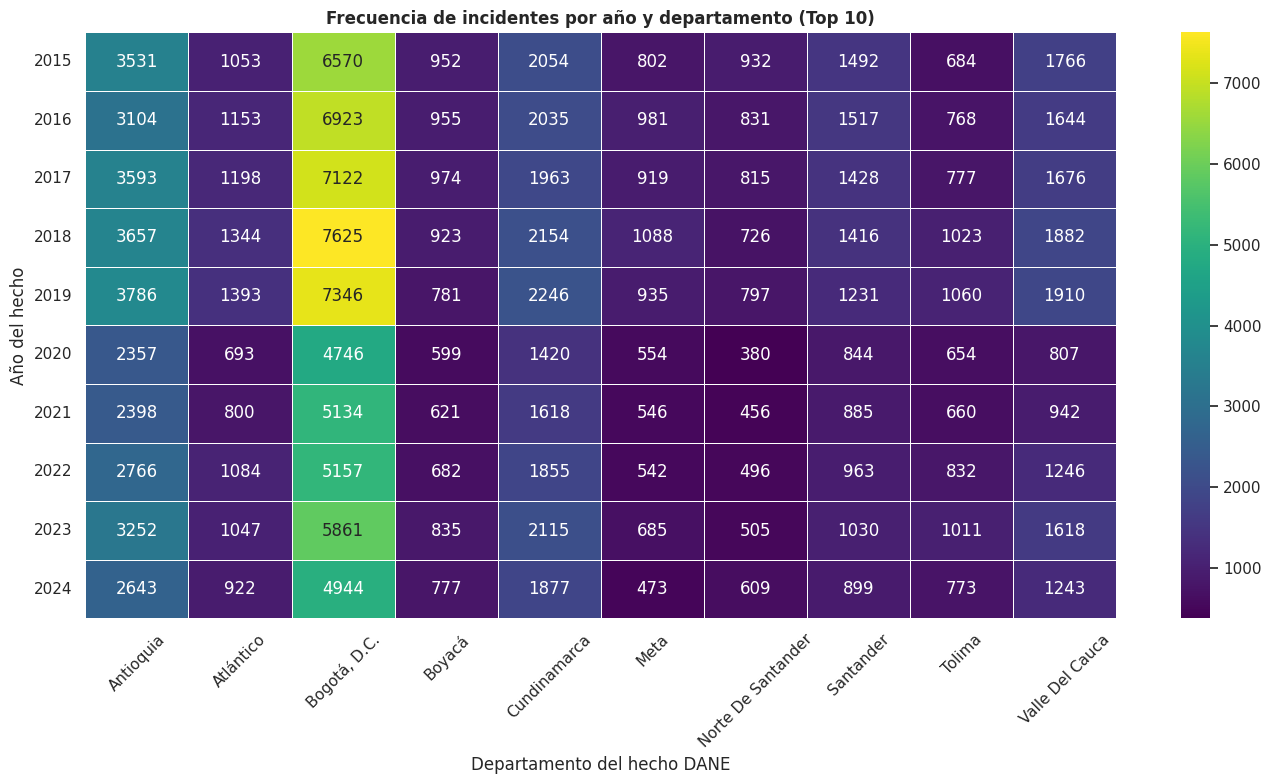

In [ ]:
#Mapa de calor para visualizar la relación de las columnas (1) 'ano_del_hecho' y (21) 'departamento_del_hecho_dane'
plt.figure(figsize=(14, 8))
sns.heatmap(relationship_data, cmap='viridis', annot=True, fmt='d', linewidths=.5)
plt.title('Frecuencia de incidentes por año y departamento (Top 10)')
plt.xlabel('Departamento del hecho DANE')
plt.ylabel('Año del hecho')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [ ]:
# 1. Identificar los 10 departamentos con mayor número de incidentes
top_departments_sexo = df['departamento_del_hecho_dane'].value_counts().nlargest(10).index

# 2. Filtrar el DataFrame para incluir solo estos departamentos
df_top_departments_sexo = df[df['departamento_del_hecho_dane'].isin(top_departments_sexo)].copy()

# 2.1 Capitalizar la columna 'sexo_de_la_victima'
# Usamos .str.capitalize() para que solo la primera letra sea mayúscula
df_top_departments_sexo['sexo_de_la_victima'] = df_top_departments_sexo['sexo_de_la_victima'].str.capitalize()

# 3. Contar la frecuencia de incidentes por sexo de la víctima y por departamento
relationship_data_sexo = df_top_departments_sexo.groupby(['sexo_de_la_victima', 'departamento_del_hecho_dane']).size().unstack(fill_value=0)

# 4. Mostrar la tabla de relación
display(relationship_data_sexo)

departamento_del_hecho_dane,Antioquia,Atlántico,"Bogotá, D.C.",Boyacá,Cundinamarca,Meta,Norte De Santander,Santander,Tolima,Valle Del Cauca
sexo_de_la_victima,,,,,,,,,,
Hombre,12194,4274,26319,3367,8151,3157,2590,4812,3340,5619
Mujer,18893,6413,35109,4732,11186,4368,3957,6893,4902,9115


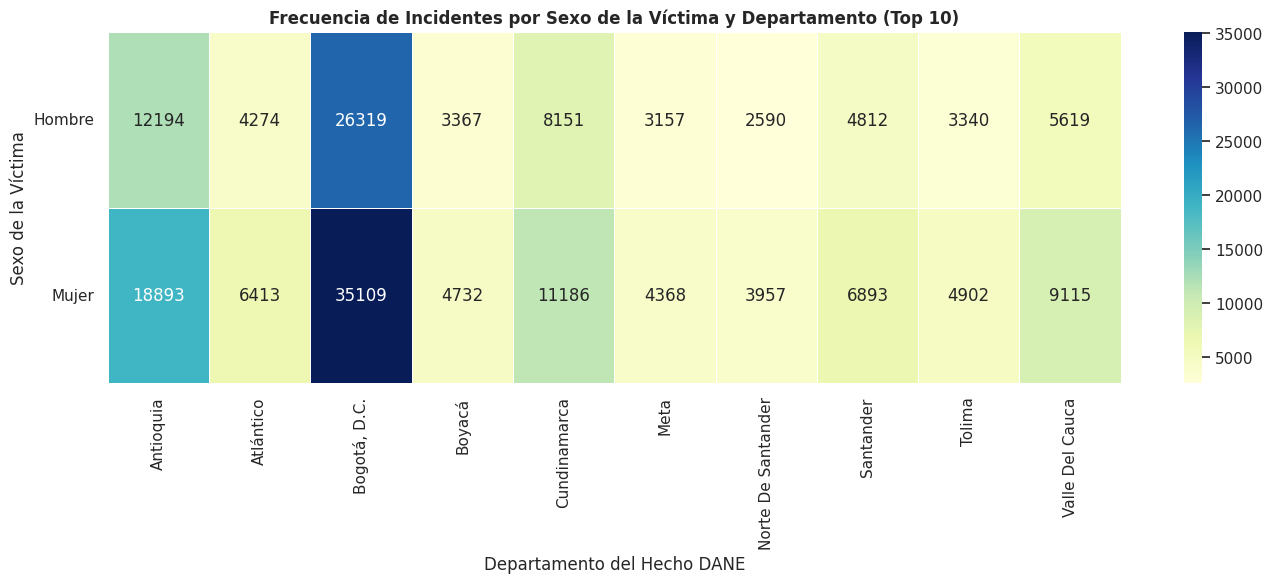

In [ ]:
#Generar un mapa de calor para visualizar la relación
plt.figure(figsize=(14, 6))
sns.heatmap(relationship_data_sexo, cmap='YlGnBu', annot=True, fmt='d', linewidths=.5)
plt.title('Frecuencia de Incidentes por Sexo de la Víctima y Departamento (Top 10)')
plt.xlabel('Departamento del Hecho DANE')
plt.ylabel('Sexo de la Víctima')
plt.yticks(rotation=0)
plt.show()

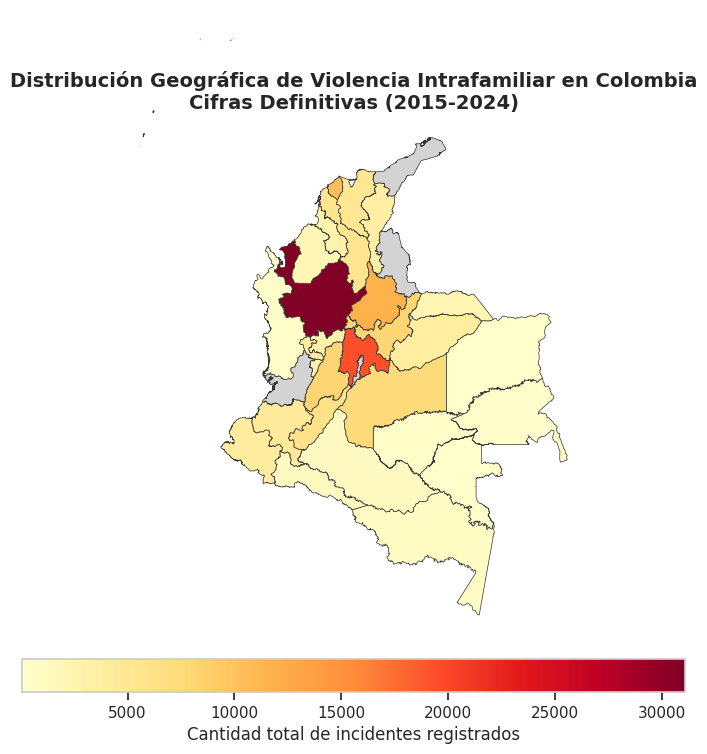

In [ ]:
#Gráfico Coroplético de Colombia por Departamentos
df_conteo_departamentos = df.groupby(['codigo_dane_departamento', 'departamento_del_hecho_dane']).size().reset_index(name='total_incidentes')
url_mapa = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_COL_1.json"
mapa_colombia = gpd.read_file(url_mapa)
df_conteo_deptos = df_conteo_departamentos
mapa_colombia['nombre_departamento_limpio'] = mapa_colombia['NAME_1'].str.lower().str.strip()
mapa_colombia['nombre_departamento_limpio'] = mapa_colombia['nombre_departamento_limpio'].apply(lambda x: unidecode(x) if isinstance(x, str) else x)
df_conteo_deptos['departamento_limpio'] = df_conteo_deptos['departamento_del_hecho_dane'].str.lower().str.strip()
df_conteo_deptos['departamento_limpio'] = df_conteo_deptos['departamento_limpio'].apply(lambda x: unidecode(x) if isinstance(x, str) else x)
name_corrections = {
    'bogota': 'bogota d.c.', # Example correction
    'archipielago de san andres, providencia y santa catalina': 'san andres, providencia y santa catalina'
}
mapa_colombia['nombre_departamento_limpio'] = mapa_colombia['nombre_departamento_limpio'].replace(name_corrections)
df_conteo_deptos['departamento_limpio'] = df_conteo_deptos['departamento_limpio'].replace(name_corrections)
name_to_dane_code_map = df_conteo_deptos.set_index('departamento_limpio')['codigo_dane_departamento'].to_dict()
mapa_colombia['codigo_dane_departamento'] = mapa_colombia['nombre_departamento_limpio'].map(name_to_dane_code_map)
df_conteo_deptos['codigo_dane_departamento'] = df_conteo_deptos['codigo_dane_departamento'].astype(int)
mapa_colombia = mapa_colombia.drop(columns=['nombre_departamento_limpio'])
df_conteo_deptos = df_conteo_deptos.drop(columns=['departamento_limpio'])
mapa_final = mapa_colombia.merge(df_conteo_deptos, on='codigo_dane_departamento', how='left')
fig, ax = plt.subplots(1, 1, figsize=(7, 8))
mapa_final.plot(
    column='total_incidentes',
    cmap='YlOrRd',          # Paleta secuencial (Amarillo-Naranja-Rojo) ideal para frecuencias
    linewidth=0.5,
    ax=ax,
    edgecolor='0.2',        # Líneas de frontera sutiles
    legend=True,
    legend_kwds={
        'label': "Cantidad total de incidentes registrados",
        'orientation': "horizontal",
        'pad': 0.02
    },
    missing_kwds={
        "color": "lightgrey", # Por si algún departamento no tiene registros
        "label": "Sin datos"
    }
)
ax.set_axis_off()
ax.set_title(
    'Distribución Geográfica de Violencia Intrafamiliar en Colombia\nCifras Definitivas (2015-2024)',
    fontsize=14,
    y=0.8,  # Baja el título manualmente para acercarlo al mapa
    fontweight='bold',
    pad=20
)
plt.tight_layout()
plt.show()

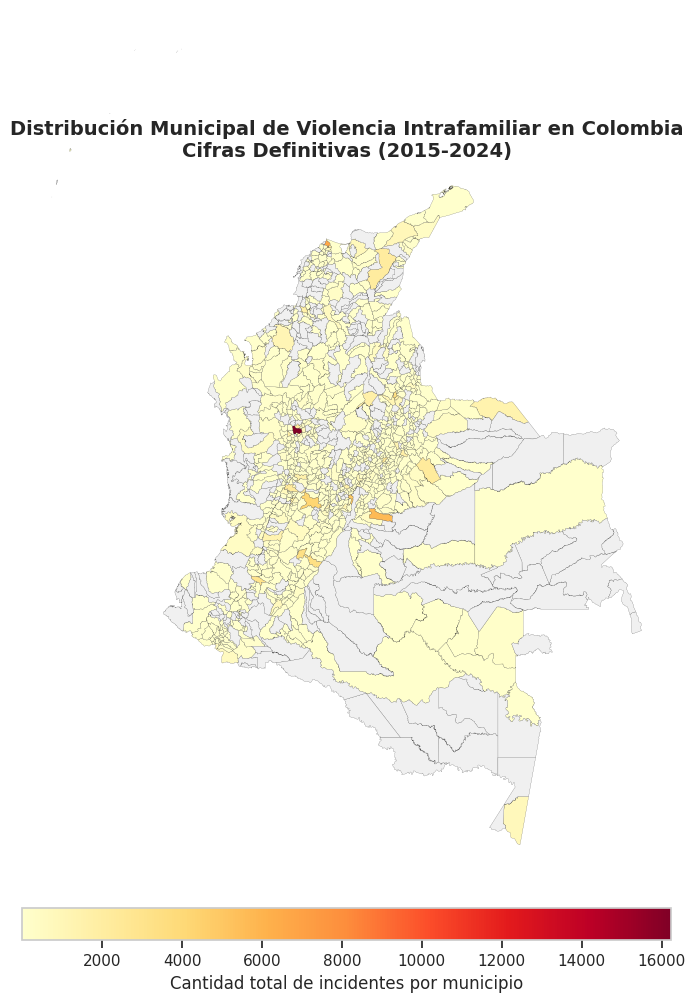

In [ ]:
#Gráfico Coroplético de Colombia por Municipios
df_conteo_municipios = df.groupby(['codigo_dane_municipio', 'municipio_del_hecho_dane']).size().reset_index(name='total_incidentes')
url_municipios = "https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_COL_2.json" # Updated URL for municipalities
mapa_municipios = gpd.read_file(url_municipios)
mapa_municipios['nombre_municipio_limpio'] = mapa_municipios['NAME_2'].str.lower().str.strip()
mapa_municipios['nombre_municipio_limpio'] = mapa_municipios['nombre_municipio_limpio'].apply(lambda x: unidecode(x) if isinstance(x, str) else x)
df_conteo_municipios['municipio_limpio'] = df_conteo_municipios['municipio_del_hecho_dane'].str.lower().str.strip()
df_conteo_municipios['municipio_limpio'] = df_conteo_municipios['municipio_limpio'].apply(lambda x: unidecode(x) if isinstance(x, str) else x)
name_corrections_municipios = {
    'bogota': 'bogota d.c.',
    # Add more if discrepancies are found after initial run
}
mapa_municipios['nombre_municipio_limpio'] = mapa_municipios['nombre_municipio_limpio'].replace(name_corrections_municipios)
df_conteo_municipios['municipio_limpio'] = df_conteo_municipios['municipio_limpio'].replace(name_corrections_municipios)
name_to_dane_code_map_municipios = df_conteo_municipios.set_index('municipio_limpio')['codigo_dane_municipio'].to_dict()
mapa_municipios['codigo_dane_municipio'] = mapa_municipios['nombre_municipio_limpio'].map(name_to_dane_code_map_municipios)
mapa_municipios['codigo_dane_municipio'] = mapa_municipios['codigo_dane_municipio'].fillna(0).astype(int)
df_conteo_municipios['codigo_dane_municipio'] = df_conteo_municipios['codigo_dane_municipio'].astype(int)
mapa_municipal_final = mapa_municipios.merge(df_conteo_municipios, on='codigo_dane_municipio', how='left')
fig, ax = plt.subplots(1, 1, figsize=(7, 12))
mapa_municipal_final.plot(
    column='total_incidentes',
    cmap='YlOrRd',          # Mantenemos la paleta secuencial recomendada
    linewidth=0.1,          # Líneas de frontera MUY delgadas, porque son más de 1000 municipios
    ax=ax,
    edgecolor='black',        # Gris suave para que las divisiones no saturen la vista
    legend=True,
    legend_kwds={
        'label': "Cantidad total de incidentes por municipio",
        'orientation': "horizontal",
        'pad': 0.02
    },
    missing_kwds={
        "color": "#f0f0f0", # Color neutro para municipios sin registros reportados
        "label": "Sin datos"
    }
)
ax.set_axis_off()
norm=LogNorm(vmin=1, vmax=df_conteo_municipios['total_incidentes'].max())
ax.set_title(
    'Distribución Municipal de Violencia Intrafamiliar en Colombia\nCifras Definitivas (2015-2024)',
    fontsize=14,
    y=0.8,  # Baja el título manualmente para acercarlo al mapa
    fontweight='bold',
    pad=20
)
plt.tight_layout()
plt.show()

Corresponde solo para Bogotá, D.C.

In [ ]:
#Conteo de valores únicos de la columna (23) 'Localidad_del_hecho'
df['localidad_del_hecho'].value_counts()


,count
localidad_del_hecho,
sin informacion,186295
kennedy,7199
ciudad bolivar,6223
bosa,5609
san cristobal,4905
suba,4721
engativa,4564
usme,3180
rafael uribe uribe,2750


In [ ]:
# Mostrar los valores únicos y su conteo antes de la unificación Col(24) 'zona_del_hecho'
display(df['zona_del_hecho'].value_counts(dropna=False))

,count
zona_del_hecho,
cabecera municipal,206453
parte rural (vereda y campo),16267
sin informacion,5775
"centro poblado(corregimiento, inspeccion de policia y caserio)",4314
"centro poblado (corregimiento, inspeccion de policia y caserio)",4031


In [ ]:
# Mostrar los valores únicos y su conteo antes de la unificación Col(24) 'zona_del_hecho'
display(df_antioquia['zona_del_hecho'].value_counts(dropna=False))

,count
zona_del_hecho,
cabecera municipal,26404
parte rural (vereda y campo),2873
sin informacion,959
"centro poblado(corregimiento, inspeccion de policia y caserio)",440
"centro poblado (corregimiento, inspeccion de policia y caserio)",411


In [ ]:
# Unificar las diferentes entradas de 'centro poblado'
df['zona_del_hecho'] = df['zona_del_hecho'].replace([
    'centro poblado(corregimiento, inspeccion de policia y caserio)',
    'centro poblado (corregimiento, inspeccion de policia y caserio)', 'centro poblado(corregimiento, inspeccion de policia y caserio)','centro poblado (corregimiento, inspeccion de policia y caserio)',
], 'Centro Poblado')

# Modificar las diferentes entradas de 'cabecera municipal'
df['zona_del_hecho'] = df['zona_del_hecho'].replace([
    'cabecera municipal'
], 'Cabecera Municipal')

# Modificar las diferentes entradas de 'parte rural (vereda y campo)'
df['zona_del_hecho'] = df['zona_del_hecho'].replace([
    'parte rural (vereda y campo)'
], 'Parte Rural')

df['zona_del_hecho'] = df['zona_del_hecho'].replace(['sin informacion'], np.nan)

# Mostrar los valores únicos y su conteo después de la unificación
display(df['zona_del_hecho'].value_counts(dropna=False))

,count
zona_del_hecho,
Cabecera Municipal,206453
Parte Rural,16267
Centro Poblado,8345
NaN,5775


In [ ]:
#Col(24) Antioquia
# Unificar las diferentes entradas de 'centro poblado'
df_antioquia['zona_del_hecho'] = df['zona_del_hecho'].replace([
    'centro poblado(corregimiento, inspeccion de policia y caserio)',
    'centro poblado (corregimiento, inspeccion de policia y caserio)', 'centro poblado(corregimiento, inspeccion de policia y caserio)','centro poblado (corregimiento, inspeccion de policia y caserio)',
], 'Centro Poblado')

# Modificar las diferentes entradas de 'cabecera municipal'
df_antioquia['zona_del_hecho'] = df['zona_del_hecho'].replace([
    'cabecera municipal'
], 'Cabecera Municipal')

# Modificar las diferentes entradas de 'parte rural (vereda y campo)'
df_antioquia['zona_del_hecho'] = df['zona_del_hecho'].replace([
    'parte rural (vereda y campo)'
], 'Parte Rural')

df_antioquia['zona_del_hecho'] = df['zona_del_hecho'].replace(['sin informacion'], np.nan)

# Mostrar los valores únicos y su conteo después de la unificación
display(df_antioquia['zona_del_hecho'].value_counts(dropna=False))

,count
zona_del_hecho,
Cabecera Municipal,26404
Parte Rural,2873
NaN,959
Centro Poblado,851


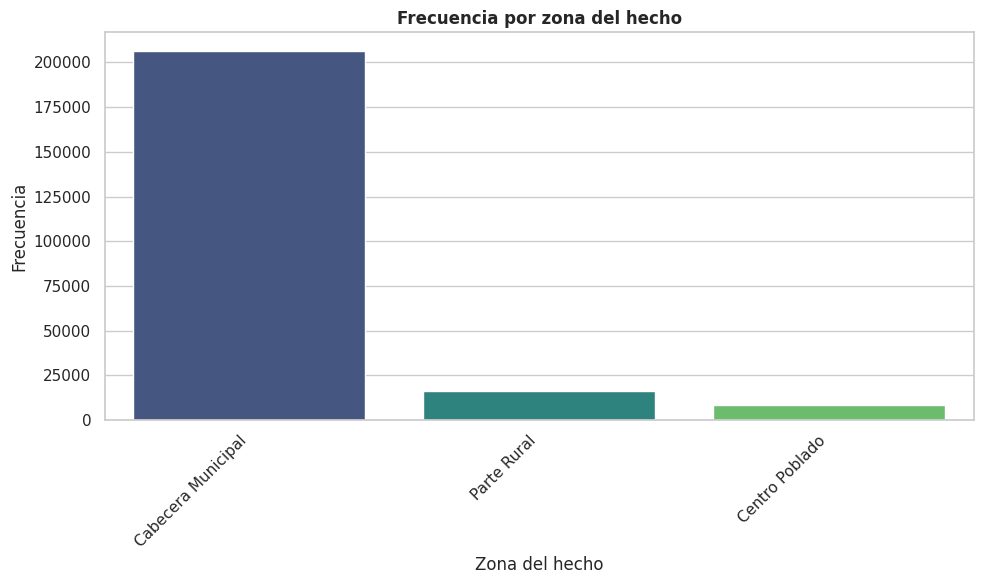

In [ ]:
#Gráfico de Frecuencia de la Columna (24) 'zona_del_hecho'
plt.figure(figsize=(10, 6))
sns.countplot(x='zona_del_hecho', data=df, palette='viridis', hue='zona_del_hecho', legend=False)
plt.title('Frecuencia por zona del hecho')
plt.xlabel('Zona del hecho')
plt.ylabel('Frecuencia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Verificamos qué hay en la columna antes de filtrar
print("Valores únicos en la columna de departamentos:")
print(df['departamento_del_hecho_dane'].unique())

Valores únicos en la columna de departamentos:
['Bogotá, D.C.' 'Cundinamarca' 'Norte De Santander' 'Meta' 'Huila'
 'Atlántico' 'Cesar' 'Risaralda' 'Sucre' 'Valle Del Cauca' 'Córdoba'
 'Arauca' 'Antioquia' 'La Guajira' 'Caldas' 'Casanare' 'Bolívar' 'Nariño'
 'Cauca' 'Quindío' 'Santander'
 'Archipiélago de San Andrés, Providencia y Santa Catalina' 'Tolima'
 'Amazonas' 'Boyacá' 'Magdalena' 'Guainía' 'Caquetá' 'Chocó' 'Guaviare'
 'Putumayo' 'Vichada' 'Vaupés' 'Sin Informacion']


In [ ]:
# Filtramos de forma más flexible por si hay problemas de tildes o espacios
# Usamos .str.contains para que sea menos estricto
df_comparativa = df[
    df['departamento_del_hecho_dane'].str.contains('Antioquia|Bogotá, D.C.', case=False, na=False)
].copy()

# Verificamos cuántos registros quedaron
print(f"Registros encontrados para la comparativa: {df_comparativa.shape[0]}")
print("Distribución de los datos encontrados:")
print(df_comparativa['departamento_del_hecho_dane'].value_counts())

Registros encontrados para la comparativa: 92515
Distribución de los datos encontrados:
departamento_del_hecho_dane
Bogotá, D.C.    61428
Antioquia       31087
Name: count, dtype: int64


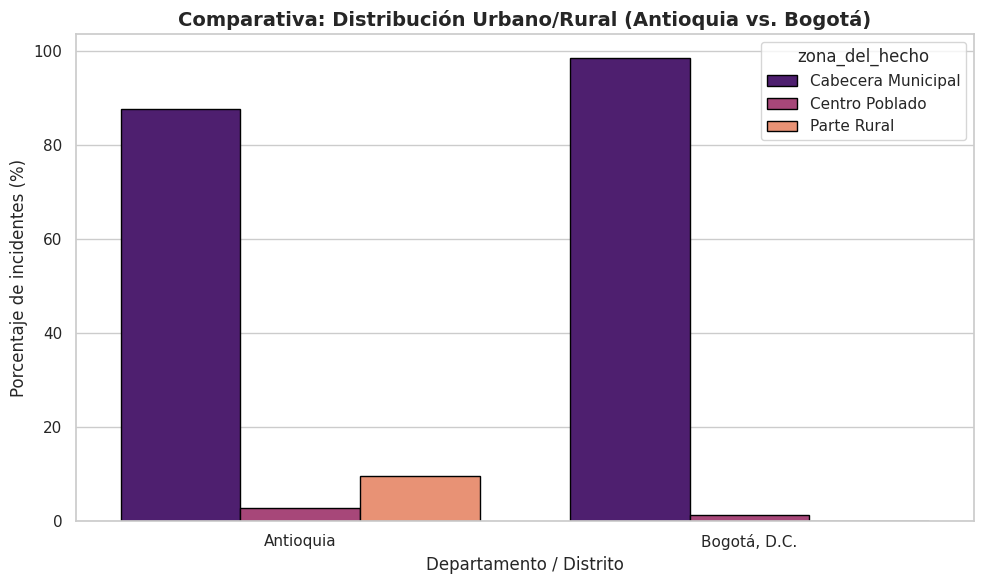

In [ ]:
# 1. Filtramos usando el nombre correcto de la columna (Conclusión 3a)
# Nota: Asegúrate de que los valores sean strings exactos según tu dataset
df_comparativa = df[df['departamento_del_hecho_dane'].isin(['Antioquia', 'Bogotá, D.C.'])].copy()

# 2. Calculamos las frecuencias relativas para comparar proporciones
distribucion = df_comparativa.groupby(['departamento_del_hecho_dane', 'zona_del_hecho']).size().reset_index(name='conteo')
total_por_depto = distribucion.groupby('departamento_del_hecho_dane')['conteo'].transform('sum')
distribucion['porcentaje'] = (distribucion['conteo'] / total_por_depto) * 100

# 3. Gráfico comparativo
plt.figure(figsize=(10, 6))
sns.barplot(
    data=distribucion,
    x='departamento_del_hecho_dane',
    y='porcentaje',
    hue='zona_del_hecho',
    palette='magma',
    edgecolor='black'
)

plt.title('Comparativa: Distribución Urbano/Rural (Antioquia vs. Bogotá)', fontsize=14, fontweight='bold')
plt.ylabel('Porcentaje de incidentes (%)', fontsize=12)
plt.xlabel('Departamento / Distrito', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
#Conteo de valores únicos de la columna (24) 'escenario_del_hecho'
df['escenario_del_hecho'].value_counts()
unique_escenarios = df['escenario_del_hecho'].dropna().unique()
sorted_escenarios = sorted(unique_escenarios)
display(sorted_escenarios)

['ambulancia - transporte sanitario',
 'areas deportivas y/o recreativas',
 'calle (autopista, avenida, dentro de la ciudad)',
 'calle (autopista,avenida,dentro de la ciudad)',
 'carretera (fuera de la ciudad)',
 'centro de atencion medica (hospital, clinica, consultorio, etc.)',
 'centro de atencion medica (hospital,clinica,consultorio,etc)',
 'centros de reclusion',
 'centros educativos',
 'espacios acuaticos al aire libre (mar, rio, arroyo, humedal, lago, etc.)',
 'espacios acuaticos al aire libre (mar,rio,arroyo,humedal,lago,etc)',
 'espacios terrestres al aire libre (bosque, potrero, montana, playa, etc.)',
 'espacios terrestres al aire libre (bosque,potrero,montana,playa,etc)',
 'establecimiento comercial (plaza de mercado, galeria)',
 'establecimiento comercial (tienda, centro comercial, almacen)',
 'establecimiento comercial (tienda, centro comercial, almacen, plaza de mercado)',
 'establecimiento comercial (tienda,centro comercial,almacen,plaza de mercado)',
 'establecimiento 

In [ ]:
# Función para quitar tildes
def normalizar_texto(texto):
    if pd.isna(texto):
        return texto
    # Eliminar tildes
    texto = ''.join((c for c in unicodedata.normalize('NFD', texto) if unicodedata.category(c) != 'Mn'))
    # Pasar a minúsculas y quitar espacios extra
    return texto.lower().strip()

# Para la columna 'escenario_del_hecho'
df['escenario_del_hecho_clean'] = df['escenario_del_hecho'].apply(normalizar_texto)

# Si quieres agrupar "Establecimiento comercial (tienda...)" con "Establecimiento comercial"
# puedes eliminar todo lo que esté dentro de los paréntesis:
df['escenario_del_hecho_clean'] = df['escenario_del_hecho'].str.replace(r'\(.*\)', '', regex=True).str.strip()

# Ver los resultados únicos
print(df['escenario_del_hecho_clean'].unique())

['calle' 'vivienda' 'sin informacion' 'areas deportivas y/o recreativas'
 'otros' 'via publica' 'vehiculo servicio particular'
 'lugares de esparcimiento con expendio de alcohol' 'carretera'
 'sitio de culto' 'lugares de hospedaje' 'centros educativos'
 'establecimiento comercial' 'espacios terrestres al aire libre'
 'centro de atencion medica' 'guarniciones militares y/o de policia'
 'taller' 'lugares de cuidado de personas'
 'establecimiento industrial  y/o obras en construccion'
 'establecimientos financieros y relacionados' 'estaciones de servicio'
 'lugares de actividades culturales'
 'establecimientos de expendio de comidas'
 'oficinas y/o edificios de oficinas' 'centros de reclusion'
 'establecimientos dedicados a la administracion publica'
 'terminales de pasajeros' 'parqueaderos,estacionamientos'
 'terreno baldio' 'zonas de actividades agropecuarias'
 'espacios acuaticos al aire libre' 'ambulancia - transporte sanitario'
 'vehiculo de servicio particular' 'parqueaderos, estaci

In [ ]:
#Nuevamente...
df['escenario_del_hecho_clean'].value_counts()

,count
escenario_del_hecho_clean,
vivienda,179221
calle,26609
via publica,11530
sin informacion,3746
lugares de hospedaje,3017
establecimiento comercial,2771
areas deportivas y/o recreativas,1637
lugares de esparcimiento con expendio de alcohol,1514
carretera,1312


In [ ]:
import re
#Pipeline de limpieza para la columna 'escenario_del_hecho' dado la gran cantidad de valores únicos
def pipeline_limpieza(texto):
    if not isinstance(texto, str):
        return texto

    # 1. Quitar tildes (ej: 'río' -> 'rio', 'Áreas' -> 'areas')
    texto = "".join(c for c in unicodedata.normalize('NFD', texto) if unicodedata.category(c) != 'Mn')

    # 2. Todo a minúsculas
    texto = texto.lower()

    # 3. Eliminar contenido entre paréntesis (opcional, pero ideal para agrupar categorías)
    # Esto une "Calle (Avenida)" con "Calle (Autopista)" en una sola categoría: "calle"
    texto = re.sub(r'\(.*\)', '', texto)

    # 4. Limpieza de espacios en blanco (dobles espacios y extremos)
    texto = " ".join(texto.split())

    # 5. Opcional: Capitalizar la primera letra para el reporte final
    return texto.capitalize()

# Aplicar a tu DataFrame
df['escenario_del_hecho_clean'] = df['escenario_del_hecho'].apply(pipeline_limpieza)

# Verificar cuántos valores quedaron
print(f"Valores únicos finales: {df_antioquia['escenario_del_hecho'].nunique()}")
print(df['escenario_del_hecho'].unique())

Valores únicos finales: 49
['calle (autopista,avenida,dentro de la ciudad)' 'vivienda'
 'sin informacion' 'areas deportivas y/o recreativas' 'otros'
 'via publica' 'vehiculo servicio particular'
 'lugares de esparcimiento con expendio de alcohol'
 'carretera (fuera de la ciudad)'
 'sitio de culto (capilla,iglesia,templo,etc)'
 'lugares de hospedaje (hoteles,campamentos y otros tipos de hospedaje no permanente,moteles,etc)'
 'centros educativos'
 'establecimiento comercial (tienda,centro comercial,almacen,plaza de mercado)'
 'espacios terrestres al aire libre (bosque,potrero,montana,playa,etc)'
 'centro de atencion medica (hospital,clinica,consultorio,etc)'
 'guarniciones militares y/o de policia' 'taller'
 'lugares de cuidado de personas (hospicios,orfelinatos,hogares geriatricos,etc)'
 'establecimiento industrial (fabrica,planta) y/o obras en construccion'
 'establecimientos financieros y relacionados (bancos,fiduciarias,etc)'
 'estaciones de servicio (bombas de gasolina)'
 'lugares d

In [ ]:
import unicodedata # Asegúrate de importar esto si no lo tienes arriba

# 1. Diccionario (se mantiene igual)
correcciones = {
    'Areas deportivas y/o recreativas': 'Áreas deportivas y/o recreativas',
    'Centro de atencion medica': 'Centro de atención médica',
    'Centros de reclusion': 'Centros de reclusión',
    'Espacios acuaticos al aire libre': 'Espacios acuáticos al aire libre',
    'Establecimiento industrial y/o obras en construccion': 'Establecimiento industrial y/o obras en construcción',
    'Establecimientos dedicados a la administracion publica': 'Establecimientos dedicados a la administración pública',
    'Guarniciones militares y/o de policia': 'Guarniciones militares y/o de policía',
    'Parqueaderos,estacionamientos': 'Parqueaderos y estacionamientos',
    'Parqueaderos, estacionamientos': 'Parqueaderos y estacionamientos',
    'Sin informacion': 'Sin información',
    'Terreno baldio': 'Terreno baldío',
    'Vehiculo de servicio particular': 'Vehículo de servicio particular',
    'Vehiculo servicio particular': 'Vehículo de servicio particular',
    'Vehiculo de transporte': 'Vehículo de transporte',
    'Via publica': 'Vía pública'
}

# 2. Creamos la columna final en AMBOS DataFrames de manera consistente
# Usamos .apply(pipeline_limpieza) primero y LUEGO el .replace() para corregir
df['escenario_del_hecho_final'] = df['escenario_del_hecho'].apply(pipeline_limpieza).replace(correcciones).fillna('Sin información')
df_antioquia['escenario_del_hecho_final'] = df_antioquia['escenario_del_hecho'].apply(pipeline_limpieza).replace(correcciones).fillna('Sin información')

# 3. Resultado final para Colombia
print("--- Categorías Colombia ---")
valores_colombia = sorted(df['escenario_del_hecho_final'].unique().astype(str))
print(f"Total: {len(valores_colombia)}\n")
for valor in valores_colombia:
    print(f"- {valor}")

# 4. Resultado final para Antioquia
print("\n--- Categorías Antioquia ---")
valores_antioquia = sorted(df_antioquia['escenario_del_hecho_final'].unique().astype(str))
print(f"Total: {len(valores_antioquia)}\n")
for valor in valores_antioquia:
    print(f"- {valor}")

--- Categorías Colombia ---
Total: 35

- Ambulancia - transporte sanitario
- Calle
- Carretera
- Centro de atención médica
- Centros de reclusión
- Centros educativos
- Espacios acuáticos al aire libre
- Espacios terrestres al aire libre
- Establecimiento comercial
- Establecimiento industrial y/o obras en construcción
- Establecimientos de expendio de comidas
- Establecimientos dedicados a la administración pública
- Establecimientos financieros y relacionados
- Estaciones de servicio
- Guarniciones militares y/o de policía
- Lugares de actividades culturales
- Lugares de cuidado de personas
- Lugares de esparcimiento con expendio de alcohol
- Lugares de hospedaje
- Oficinas y/o edificios de oficinas
- Otros
- Parqueaderos y estacionamientos
- Piscina y jacuzzi
- Sin información
- Sitio de culto
- Taller
- Terminales de pasajeros
- Terreno baldío
- Transporte masivo
- Vehículo de servicio particular
- Vehículo de transporte
- Vivienda
- Vía pública
- Zonas de actividades agropecuarias

In [ ]:
# I. CÁLCULO DE FRECUENCIAS COMPARATIVO (Tabla Resumen)
# Calculamos frecuencias normalizadas para ambos DataFrames
freq_col = df['escenario_del_hecho_final'].value_counts(normalize=True) * 100
freq_ant = df_antioquia['escenario_del_hecho_final'].value_counts(normalize=True) * 100

# Unimos en un solo DataFrame
tabla_frecuencias = pd.concat([freq_col, freq_ant], axis=1)
tabla_frecuencias.columns = ['% Colombia', '% Antioquia']

# Ordenamos por Colombia (de mayor a menor) y tomamos el top 10
tabla_frecuencias = tabla_frecuencias.sort_values(by='% Colombia', ascending=False).head(10)

# Mostramos la tabla con formato de porcentaje elegante
print("--- Tabla Comparativa de Frecuencias (Top 10) ---")
print(tabla_frecuencias.style.format("{:.2f}%").to_string())

--- Tabla Comparativa de Frecuencias (Top 10) ---
 % Colombia % Antioquia
escenario_del_hecho_final  
Vivienda 75.67% 79.46%
Calle 11.24% 8.21%
Vía pública 4.87% 5.51%
Sin información 1.58% 2.56%
Lugares de hospedaje 1.27% 0.43%
Establecimiento comercial 1.17% 0.92%
Áreas deportivas y/o recreativas 0.69% 0.29%
Lugares de esparcimiento con expendio de alcohol 0.64% 0.22%
Carretera 0.55% 0.39%
Centros educativos 0.52% 0.51%



En Antioquia, el 79,5% corresponde a que el escenario del hecho victimario fue en la vivienda.

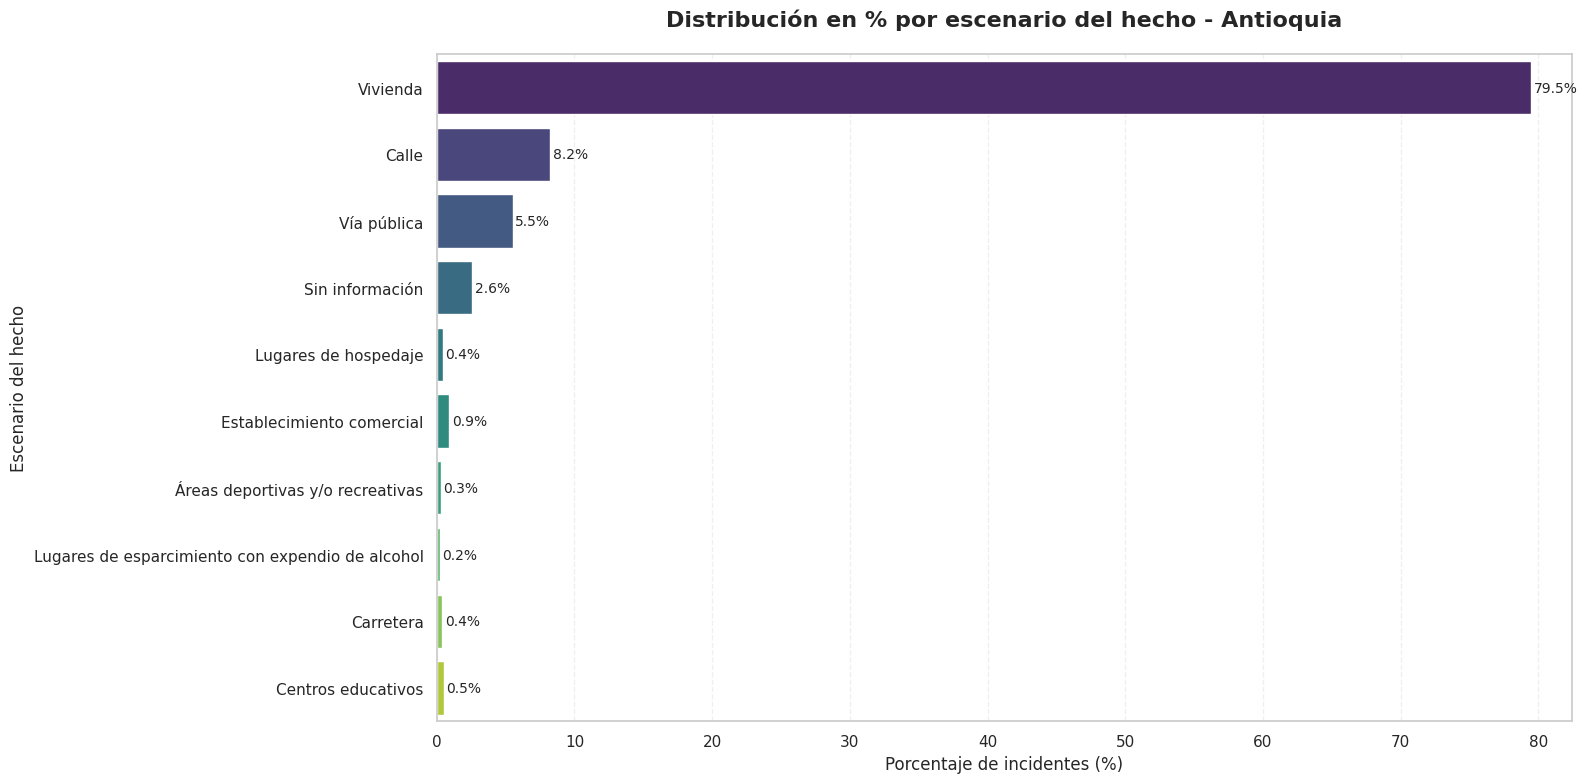

In [ ]:
# I. VISUALIZACIÓN EN PORCENTAJE A PARTIR DE LA TABLA DE FRECUENCIAS
plt.figure(figsize=(16, 8))
ax = sns.barplot(data=tabla_frecuencias, x='% Antioquia', y='escenario_del_hecho_final', hue='escenario_del_hecho_final', palette='viridis', legend=False)

# 3. Añadimos el número del porcentaje al lado de cada barra
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.2,            # Posición X (un poco a la derecha de la barra)
            p.get_y() + p.get_height() / 2, # Posición Y (centro de la barra)
            f'{width:.1f}%',        # Texto a mostrar
            ha='left', va='center', fontsize=10)

# Configuración estética
plt.title('Distribución en % por escenario del hecho - Antioquia', # Updated title
fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Porcentaje de incidentes (%)', fontsize=12) # Updated xlabel
plt.ylabel('Escenario del hecho', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.3)

# Ajustamos el límite del eje X para que las etiquetas no se corten
plt.xlim(0, tabla_frecuencias['% Antioquia'].max() + 3) # Updated to use '% Antioquia'

plt.tight_layout()
plt.show()

In [ ]:
# 1. PASO A: Reescribir la columna original con los datos limpios
df_antioquia['escenario_del_hecho'] = df_antioquia['escenario_del_hecho_final']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df_antioquia = df_antioquia.drop(columns=['escenario_del_hecho_final'])

# 3. Verificación
print("La columna 'escenario_del_hecho' ahora tiene los datos limpios y es única.")

df_antioquia['escenario_del_hecho'].value_counts()

La columna 'escenario_del_hecho' ahora tiene los datos limpios y es única.


,count
escenario_del_hecho,
Vivienda,24701
Calle,2552
Vía pública,1714
Sin información,795
Establecimiento comercial,286
Centros educativos,158
Lugares de hospedaje,134
Carretera,122
Áreas deportivas y/o recreativas,91


In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

In [ ]:
# Mostrar los valores únicos y su conteo ANTES de la unificación Col (26)'actividad_durante_el_hecho'
display(df['actividad_durante_el_hecho'].value_counts(dropna=False))

,count
actividad_durante_el_hecho,
actividades vitales o relacionadas con el cuidado personal,75137
actividades de trabajo domestico no pagado para el uso del propio hogar,53481
actividades de desplazamiento de un lugar a otro,47573
otra,18521
actividades de desplazamiento de un lugar a otro.,12851
"actividades relacionadas con la asistencia a eventos culturales, de entretenimiento y/o deportivos",8335
actividades relacionadas con el cuidado no pagado de miembros del hogar,6376
actividades relacionadas con enfrentamientos armados,6369
actividades relacionadas con el estudio y el aprendizaje,2421


In [ ]:
# Mostrar los valores únicos y su conteo ANTES de la unificación Col (26)'actividad_durante_el_hecho'
display(df_antioquia['actividad_durante_el_hecho'].value_counts(dropna=False))

,count
actividad_durante_el_hecho,
actividades de trabajo domestico no pagado para el uso del propio hogar,8855
actividades vitales o relacionadas con el cuidado personal,8007
actividades de desplazamiento de un lugar a otro,5196
otra,3221
actividades relacionadas con enfrentamientos armados,1279
actividades de desplazamiento de un lugar a otro.,1112
actividades relacionadas con el cuidado no pagado de miembros del hogar,970
"actividades relacionadas con la asistencia a eventos culturales, de entretenimiento y/o deportivos",905
sin informacion,579


In [ ]:
# 1. Diccionario de mapeo específico para Columna 26
mapeo_actividad = {
    # Unificación de puntos finales y redacción similar
    'Actividades de desplazamiento de un lugar a otro.': 'Actividades de desplazamiento de un lugar a otro',
    'Actividades relacionadas con el aprendizaje': 'Actividades relacionadas con el estudio y el aprendizaje',
    'Actividades relacionadas con los deportes y el ejercicio físico.': 'Actividades relacionadas con los deportes y el ejercicio físico',

    # Unificación de manifestaciones (mayúsculas/minúsculas y puntos)
    'Actividades relacionadas con manifestaciones públicas (Marchas, protestas, etc.)': 'Actividades relacionadas con manifestaciones públicas (marchas, protestas, etc.)',
    'Actividades relacionadas con manifestaciones públicas (Marchas, protestas, etc)': 'Actividades relacionadas con manifestaciones públicas (marchas, protestas, etc.)',
    'Actividades relacionadas con manifestaciones públicas (marchas, protestas, etc.)': 'Actividades relacionadas con manifestaciones públicas (marchas, protestas, etc.)',

    # Consolidación de términos similares
    'Quehacer habitualmente no remunerado': 'Actividades de trabajo doméstico no pagado para el uso del propio hogar',
    'Durante una retención legal (preso detenido)': 'Durante una retención legal',

    # Limpieza de nulos o "Sin información"
    'Sin información': 'Sin información'
}

# 2. Aplicar limpieza base (minúsculas y quitar espacios) antes del mapeo para mayor seguridad
df['actividad_durante_el_hecho_limpia'] = df['actividad_durante_el_hecho'].str.strip()
# 2. Aplicar limpieza base (minúsculas y quitar espacios) antes del mapeo para mayor seguridad
df_antioquia['actividad_durante_el_hecho_limpia'] = df_antioquia['actividad_durante_el_hecho'].str.strip()


# 3. Aplicar el diccionario de correcciones
df['actividad_durante_el_hecho_final'] = df['actividad_durante_el_hecho_limpia'].replace(mapeo_actividad)
df_antioquia['actividad_durante_el_hecho_final'] = df_antioquia['actividad_durante_el_hecho_limpia'].replace(mapeo_actividad)

In [ ]:
# 4. Ver el resultado final (Colombia)
resumen_actividad = df['actividad_durante_el_hecho_final'].value_counts(dropna=False)
print(f"Total de categorías después de unificar: {len(resumen_actividad)}")
display(resumen_actividad)

Total de categorías después de unificar: 20


,count
actividad_durante_el_hecho_final,
actividades vitales o relacionadas con el cuidado personal,75137
actividades de trabajo domestico no pagado para el uso del propio hogar,53481
actividades de desplazamiento de un lugar a otro,47573
otra,18521
actividades de desplazamiento de un lugar a otro.,12851
"actividades relacionadas con la asistencia a eventos culturales, de entretenimiento y/o deportivos",8335
actividades relacionadas con el cuidado no pagado de miembros del hogar,6376
actividades relacionadas con enfrentamientos armados,6369
actividades relacionadas con el estudio y el aprendizaje,2421


In [ ]:
# 4. Ver el resultado final (Antioquia)
resumen_actividad_antioquia = df_antioquia['actividad_durante_el_hecho_final'].value_counts(dropna=False)
print(f"Total de categorías después de unificar: {len(resumen_actividad_antioquia)}")
display(resumen_actividad_antioquia)

In [ ]:
# 1. Definimos el diccionario de unificación para limpiar las categorías
# El formato es 'valor_a_corregir': 'valor_estandarizado'
correcciones_actividad = {
    'actividades de desplazamiento de un lugar a otro.': 'Actividades de desplazamiento de un lugar a otro',
    'actividades relacionadas con los deportes y el ejercicio fisico.': 'Actividades relacionadas con los deportes y el ejercicio fisico',
    'actividades relacionadas con los deportes y el ejercicio fisico': 'Actividades relacionadas con los deportes y el ejercicio fisico',
    'actividades relacionadas con manifestaciones publicas (marchas, protestas, etc.)': 'Actividades relacionadas con manifestaciones publicas',
    'actividades relacionadas con manifestaciones publicas (marchas, protestas, etc)': 'Actividades relacionadas con manifestaciones publicas',
    'actividades relacionadas con el estudio y el aprendizaje': 'Actividades relacionadas con el estudio y el aprendizaje',
    'actividades relacionadas con el aprendizaje': 'Actividades relacionadas con el estudio y el aprendizaje'
}

# 2. Aplicamos la limpieza a la columna en Antioquia
df_antioquia['actividad_durante_el_hecho_final'] = df_antioquia['actividad_durante_el_hecho_final'].replace(correcciones_actividad)

# 3. Ahora sí, calculamos el resumen consolidado
resumen_actividad_antioquia = df_antioquia['actividad_durante_el_hecho_final'].value_counts(dropna=False)

print(f"Total de categorías después de unificar: {len(resumen_actividad_antioquia)}")
display(resumen_actividad_antioquia)

Total de categorías después de unificar: 16


,count
actividad_durante_el_hecho_final,
actividades de trabajo domestico no pagado para el uso del propio hogar,8855
actividades vitales o relacionadas con el cuidado personal,8007
actividades de desplazamiento de un lugar a otro,5196
otra,3221
actividades relacionadas con enfrentamientos armados,1279
Actividades de desplazamiento de un lugar a otro,1112
actividades relacionadas con el cuidado no pagado de miembros del hogar,970
"actividades relacionadas con la asistencia a eventos culturales, de entretenimiento y/o deportivos",905
sin informacion,579


In [ ]:
# 1. Definición del Pipeline de limpieza
def pipeline_limpieza(texto):
    if not isinstance(texto, str): return texto
    texto = "".join(c for c in unicodedata.normalize('NFD', texto) if unicodedata.category(c) != 'Mn')
    texto = texto.lower()
    texto = re.sub(r'\(.*\)', '', texto)
    return " ".join(texto.split()).capitalize()

# 2. Diccionario Maestro de Corrección (Unificado)
correcciones_actividad = {
    'actividades de desplazamiento de un lugar a otro.': 'Actividades de desplazamiento de un lugar a otro',
    'actividades de desplazamiento de un lugar a otro': 'Actividades de desplazamiento de un lugar a otro',
    'quehacer habitualmente no remunerado': 'Actividades de trabajo domestico no pagado para el uso del propio hogar',
    'actividades relacionadas con los deportes y el ejercicio fisico.': 'Actividades relacionadas con los deportes y el ejercicio fisico',
    'actividades relacionadas con los deportes y el ejercicio fisico': 'Actividades relacionadas con los deportes y el ejercicio fisico',
    'actividades relacionadas con manifestaciones publicas (marchas, protestas, etc.)': 'Actividades relacionadas con manifestaciones publicas',
    'actividades relacionadas con manifestaciones publicas (marchas, protestas, etc)': 'Actividades relacionadas con manifestaciones publicas',
    'actividades relacionadas con el estudio y el aprendizaje': 'Actividades relacionadas con el estudio y el aprendizaje',
    'actividades relacionadas con el aprendizaje': 'Actividades relacionadas con el estudio y el aprendizaje'
}

# 3. Limpieza y Aplicación
df_antioquia['actividad_durante_el_hecho_final'] = df_antioquia['actividad_durante_el_hecho'].apply(pipeline_limpieza)
df_antioquia['actividad_durante_el_hecho_final'] = df_antioquia['actividad_durante_el_hecho_final'].replace(correcciones_actividad).fillna('Sin información')

# 4. Cálculo de resultados
resumen_actividad_antioquia = df_antioquia['actividad_durante_el_hecho_final'].value_counts(dropna=False)
print(f"Total de categorías después de unificar: {len(resumen_actividad_antioquia)}")
display(resumen_actividad_antioquia)



Total de categorías después de unificar: 18


,count
actividad_durante_el_hecho_final,
Actividades de trabajo domestico no pagado para el uso del propio hogar,8855
Actividades vitales o relacionadas con el cuidado personal,8007
Actividades de desplazamiento de un lugar a otro,5196
Otra,3221
Actividades relacionadas con enfrentamientos armados,1279
Actividades de desplazamiento de un lugar a otro.,1112
Actividades relacionadas con el cuidado no pagado de miembros del hogar,970
"Actividades relacionadas con la asistencia a eventos culturales, de entretenimiento y/o deportivos",905
Sin informacion,579


In [ ]:
# 1. Diccionario Maestro Actualizado (Script Final para Antioquia)
correcciones_actividad = {
    # Agrupación de trabajo doméstico
    'Quehacer habitualmente no remunerado': 'Actividades de trabajo doméstico no remunerado',
    'Actividades de trabajo domestico no pagado para el uso del propio hogar': 'Actividades de trabajo doméstico no remunerado',
    'Actividades relacionadas con el cuidado no pagado de miembros del hogar': 'Actividades de trabajo doméstico no remunerado',

    # Agrupación de aprendizaje
    'Actividades relacionadas con el estudio y el aprendizaje': 'Actividades relacionadas con el aprendizaje',
    'Actividades relacionadas con el aprendizaje': 'Actividades relacionadas con el aprendizaje',

    # NUEVA Agrupación: Actividades deportivas y/o tiempo libre
    'Actividades relacionadas con la asistencia a eventos culturales, de entretenimiento y/o deportivos': 'Actividades deportivas y/o tiempo libre',
    'Actividades relacionadas con los deportes y el ejercicio fisico': 'Actividades deportivas y/o tiempo libre',
    'Actividades relacionadas con los deportes y el ejercicio fisico.': 'Actividades deportivas y/o tiempo libre',
    'Actividades de tiempo libre': 'Actividades deportivas y/o tiempo libre',

    # Desplazamientos
    'Actividades de desplazamiento de un lugar a otro': 'Actividades de desplazamiento de un lugar a otro',
    'Actividades de desplazamiento de un lugar a otro.': 'Actividades de desplazamiento de un lugar a otro',

    # Manifestaciones
    'Actividades relacionadas con manifestaciones publicas (marchas, protestas, etc.)': 'Actividades relacionadas con manifestaciones publicas',
    'Actividades relacionadas con manifestaciones publicas (marchas, protestas, etc)': 'Actividades relacionadas con manifestaciones publicas'
}

# 2. Aplicación (Asegúrate de ejecutar esta parte antes de visualizar)
df_antioquia['actividad_durante_el_hecho_final'] = df_antioquia['actividad_durante_el_hecho'].apply(pipeline_limpieza)
df_antioquia['actividad_durante_el_hecho_final'] = df_antioquia['actividad_durante_el_hecho_final'].replace(correcciones_actividad).fillna('Sin información')

# 3. Verificación rápida
resumen_actividad_antioquia = df_antioquia['actividad_durante_el_hecho_final'].value_counts(dropna=False)
print(f"Total de categorías después de unificar: {len(resumen_actividad_antioquia)}")
display(resumen_actividad_antioquia)

Total de categorías después de unificar: 11


,count
actividad_durante_el_hecho_final,
Actividades de trabajo doméstico no remunerado,9827
Actividades vitales o relacionadas con el cuidado personal,8007
Actividades de desplazamiento de un lugar a otro,6308
Otra,3221
Actividades relacionadas con enfrentamientos armados,1279
Actividades deportivas y/o tiempo libre,967
Sin informacion,579
Actividades relacionadas con el aprendizaje,353
Actividades ilicitas o delictivas,345


/tmp/ipykernel_193/1758100825.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(y='actividad_durante_el_hecho_final', data=df_antioquia, palette='viridis',


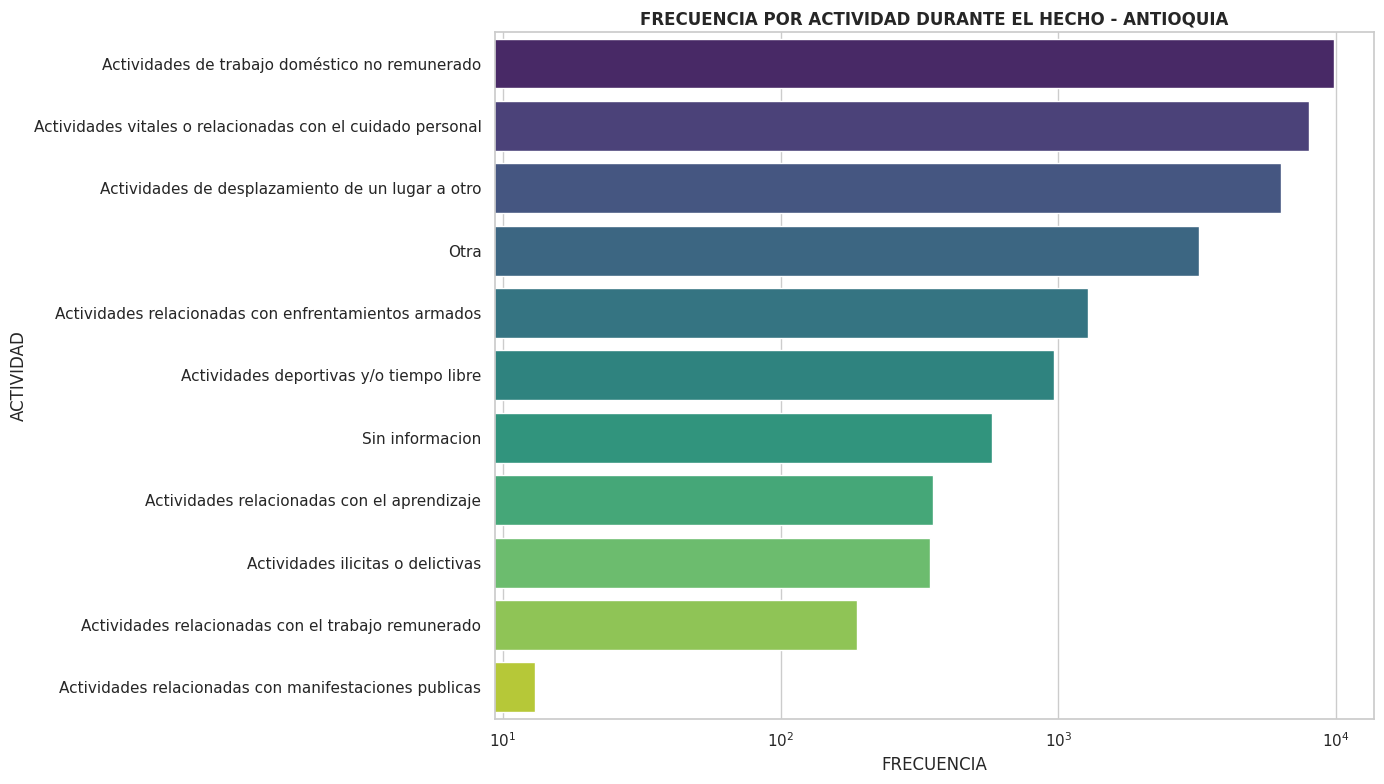

In [ ]:
 #. Visualización Final (Ajustada para etiquetas largas) Col (26) actividad_durante_el_hecho
plt.figure(figsize=(14, 8))
ax = sns.countplot(y='actividad_durante_el_hecho_final', data=df_antioquia, palette='viridis',
                   order=df_antioquia['actividad_durante_el_hecho_final'].value_counts().index)

plt.title('FRECUENCIA POR ACTIVIDAD DURANTE EL HECHO - ANTIOQUIA')
plt.xlabel('FRECUENCIA')
plt.ylabel('ACTIVIDAD')
plt.xscale('log') # Escala logarítmica para mejor visualización
plt.tight_layout()
plt.show()

In [ ]:
# 1. PASO A: Reescribir la columna original con los datos limpios
df_antioquia['actividad_durante_el_hecho'] = df_antioquia['actividad_durante_el_hecho_final']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df_antioquia = df_antioquia.drop(columns=['actividad_durante_el_hecho_final'])

# 3. Verificación
print("La columna ahora tiene los datos limpios y es única.")

La columna ahora tiene los datos limpios y es única.


In [ ]:
df_antioquia['actividad_durante_el_hecho'].value_counts()

,count
actividad_durante_el_hecho,
Actividades de trabajo doméstico no remunerado,9827
Actividades vitales o relacionadas con el cuidado personal,8007
Actividades de desplazamiento de un lugar a otro,6308
Otra,3221
Actividades relacionadas con enfrentamientos armados,1279
Actividades deportivas y/o tiempo libre,967
Sin informacion,579
Actividades relacionadas con el aprendizaje,353
Actividades ilicitas o delictivas,345


In [ ]:
df_antioquia['actividad_durante_el_hecho_limpia'].value_counts()
df_antioquia = df_antioquia.drop(columns=['actividad_durante_el_hecho_limpia'])

In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

### Col (27-35) df_antioquia
A partir de aquí, se presentará la limpieza de las columnas 27 a 35, solamente para el dataframe regional, df_antioquia

In [ ]:
# Lista de columnas de texto para limpiar
cols_texto = [
    'circunstancia_del_hecho_detallada', 'contexto_del_hecho',
    'mecanismo_causal_de_la_lesion_no_fatal', 'diagnostico_topografico_de_la_lesion_no_fatal',
    'sexo_del_agresor', 'presunto_agresor_detallado',
    'factor_desencadenante_de_la_agresion', 'pueblo_indigena'
]

# 1. Limpieza estándar para columnas de texto
for col in cols_texto:
    # Aplicamos tu pipeline maestro y rellenamos nulos
    df_antioquia[col] = df_antioquia[col].apply(pipeline_limpieza).fillna('Sin información')



print("¡Limpieza de columnas adicionales completada con éxito!")

¡Limpieza de columnas adicionales completada con éxito!


In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

In [ ]:
# 1. Definimos la lista de columnas que quieres revisar
cols_a_revisar = [
    'circunstancia_del_hecho_detallada', 'contexto_del_hecho',
    'mecanismo_causal_de_la_lesion_no_fatal', 'diagnostico_topografico_de_la_lesion_no_fatal',
    'sexo_del_agresor', 'presunto_agresor_detallado',
    'factor_desencadenante_de_la_agresion', 'dias_de_incapacidad_medicolegal', 'pueblo_indigena'
]

# 2. Creamos una lista para almacenar los resultados
datos_resumen = []

for col in cols_a_revisar:
    # Contamos cuántos valores únicos tiene y cuántos son nulos
    n_unicos = df_antioquia[col].nunique()
    n_nulos = df_antioquia[col].isnull().sum()
    datos_resumen.append({'Columna': col, 'Valores Únicos': n_unicos, 'Valores Nulos': n_nulos})

# 3. Convertimos a DataFrame para una visualización elegante
tabla_resumen = pd.DataFrame(datos_resumen)

# 4. Mostramos la tabla
print("--- Resumen de variables adicionales (Antioquia) ---")
display(tabla_resumen)

--- Resumen de variables adicionales (Antioquia) ---


,Columna,Valores Únicos,Valores Nulos
0,circunstancia_del_hecho_detallada,17,0
1,contexto_del_hecho,3,0
2,mecanismo_causal_de_la_lesion_no_fatal,18,0
3,diagnostico_topografico_de_la_lesion_no_fatal,11,0
4,sexo_del_agresor,3,0
5,presunto_agresor_detallado,21,0
6,factor_desencadenante_de_la_agresion,10,0
7,dias_de_incapacidad_medicolegal,7,0
8,pueblo_indigena,12,0


In [ ]:
# 1. Lista de columnas a analizar
cols_top10 = [
    'circunstancia_del_hecho_detallada', 'contexto_del_hecho',
    'mecanismo_causal_de_la_lesion_no_fatal', 'diagnostico_topografico_de_la_lesion_no_fatal',
    'sexo_del_agresor', 'presunto_agresor_detallado',
    'factor_desencadenante_de_la_agresion', 'pueblo_indigena'
]

# 2. Imprimir los Top 10 por columna
print("--- TOP 10 DE CATEGORÍAS MÁS FRECUENTES ---")
for col in cols_top10:
    print(f"\nTop 10 en: {col.upper()}")
    # Obtenemos los valores más frecuentes
    top10 = df_antioquia[col].value_counts().head(10)
    print(top10.to_string())

--- TOP 10 DE CATEGORÍAS MÁS FRECUENTES ---

Top 10 en: CIRCUNSTANCIA_DEL_HECHO_DETALLADA
circunstancia_del_hecho_detallada
Violencia entre otros familiares                  16966
Violencia contra ninos, ninas y adolescentes       8547
Violencia contra el adulto mayor                   2931
Intolerancia                                       1989
Consumo de alcohol y/o sustancias psicoactivas      300
Conflicto familiar                                   74
Sin informacion                                      71
Embriaguez                                           64
Amenaza o intimidacion                               35
Celos                                                32

Top 10 en: CONTEXTO_DEL_HECHO
contexto_del_hecho
4 lesiones no fatales por violencia entre otros familiares                              18478
3 lesiones no fatales contra ninos, ninas y adolescentes por violencia intrafamiliar     9245
5 lesiones no fatales contra el adulto mayor por violencia intrafamiliar      

Limpieza rápida para las columnas 27 a 35 del df_antioquia

/tmp/ipykernel_193/1048967892.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_circ_ant, x='Porcentaje (%)', y='Circunstancia', palette='rocket')


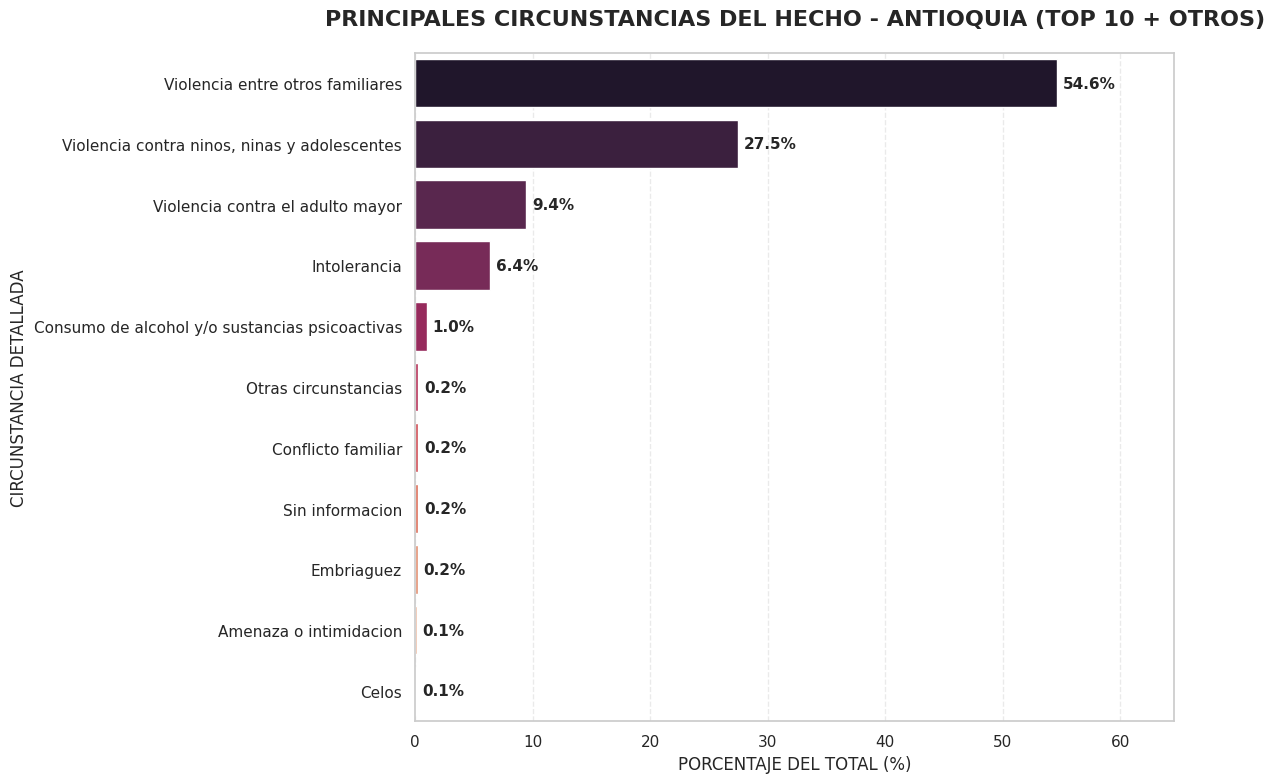

In [ ]:
#Col(27) df_antioquia
# 1. Diccionario de unificación para Columna 27
# 1. Diccionario de unificación para Columna 27 (Antioquia)
mapeo_circunstancia = {
    'Embriaguez (alcohólica y no alcohólica)': 'Consumo de alcohol y/o sustancias psicoactivas',
    'Económicas': 'Violencia económica',
    'Negligencia': 'Negligencia y/o abandono',
    'Abandono': 'Negligencia y/o abandono',
    'Sin información': 'Sin información'
}

# 2. Aplicar unificación a df_antioquia
df_antioquia['circunstancia_final'] = df_antioquia['circunstancia_del_hecho_detallada'].str.strip().replace(mapeo_circunstancia)
df_antioquia['circunstancia_final'] = df_antioquia['circunstancia_final'].fillna('Sin información')

# 3. Agrupar en Top 10 y Otros para Antioquia
top_10_circ_ant = df_antioquia['circunstancia_final'].value_counts().nlargest(10).index
df_antioquia['circunstancia_resumen'] = df_antioquia['circunstancia_final'].apply(
    lambda x: x if x in top_10_circ_ant else 'Otras circunstancias'
)

# 4. Calcular tabla de frecuencias en porcentaje para Antioquia
tabla_circ_ant = df_antioquia['circunstancia_resumen'].value_counts().reset_index()
tabla_circ_ant.columns = ['Circunstancia', 'Frecuencia']
tabla_circ_ant['Porcentaje (%)'] = (tabla_circ_ant['Frecuencia'] / tabla_circ_ant['Frecuencia'].sum() * 100).round(2)

# 5. Generar el gráfico para Antioquia
plt.figure(figsize=(12, 8))
ax = sns.barplot(data=tabla_circ_ant, x='Porcentaje (%)', y='Circunstancia', palette='rocket')

# Añadir etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.5, p.get_y() + p.get_height() / 2, f'{width:.1f}%',
            ha='left', va='center', fontsize=11, fontweight='bold')

plt.title('PRINCIPALES CIRCUNSTANCIAS DEL HECHO - ANTIOQUIA (TOP 10 + OTROS)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('PORCENTAJE DEL TOTAL (%)', fontsize=12)
plt.ylabel('CIRCUNSTANCIA DETALLADA', fontsize=12)
plt.xlim(0, tabla_circ_ant['Porcentaje (%)'].max() + 10)
plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
# 1. PASO A: Reescribir la columna original con los datos limpios
df_antioquia['circunstancia_del_hecho_detallada'] = df_antioquia['circunstancia_final']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df_antioquia = df_antioquia.drop(columns=['circunstancia_final'])

# 3. Verificación
print("La columna ahora tiene los datos limpios y es única.")

La columna ahora tiene los datos limpios y es única.


In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

In [ ]:
df_antioquia = df_antioquia.drop(columns=['circunstancia_resumen'])
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

In [ ]:
df_antioquia['contexto_del_hecho'].value_counts()

,count
contexto_del_hecho,
4 lesiones no fatales por violencia entre otros familiares,18478
"3 lesiones no fatales contra ninos, ninas y adolescentes por violencia intrafamiliar",9245
5 lesiones no fatales contra el adulto mayor por violencia intrafamiliar,3364


In [ ]:
#Col(28) df_antioquia
# Remove the first two characters from 'contexto_del_hecho' entries
df_antioquia['contexto_del_hecho'] = df_antioquia['contexto_del_hecho'].apply(lambda x: x[2:] if isinstance(x, str) and len(x) >= 2 else x)

# Display the value counts to verify the changes
display(df_antioquia['contexto_del_hecho'].value_counts(dropna=False))

,count
contexto_del_hecho,
lesiones no fatales por violencia entre otros familiares,18478
"lesiones no fatales contra ninos, ninas y adolescentes por violencia intrafamiliar",9245
lesiones no fatales contra el adulto mayor por violencia intrafamiliar,3364


/tmp/ipykernel_193/2706364480.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_contexto_ant, x='Porcentaje (%)', y='Contexto', palette='plasma')


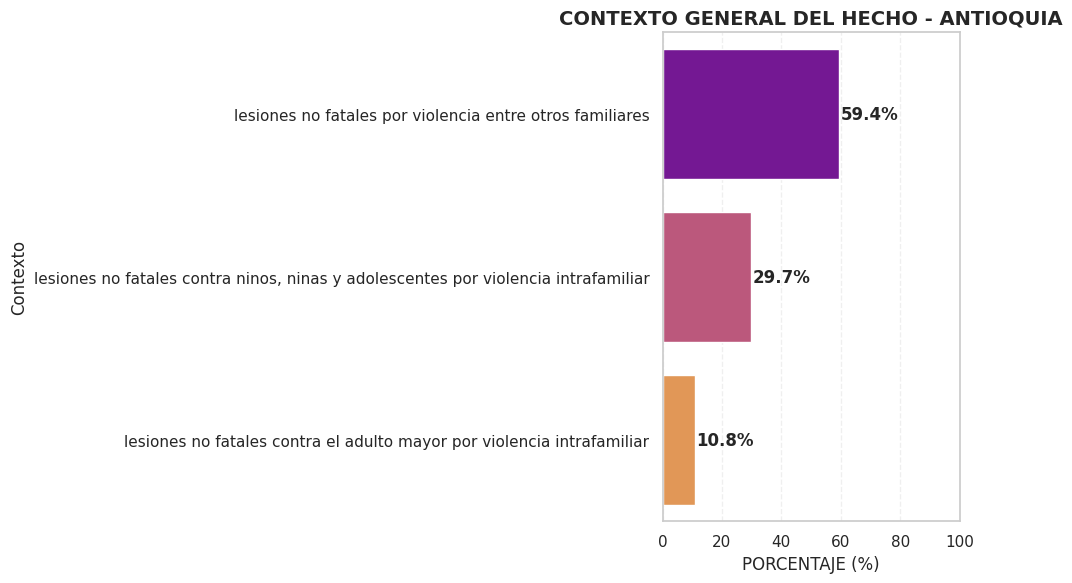

In [ ]:
#Col(28) df_antioquia, continua limpieza y gráfico
# 1. Diccionario de simplificación para el gráfico (Antioquia)
mapeo_contexto = {
    'lesiones no Fatales por Violencia entre otros Familiares': 'VIF entre otros familiares',
    'lesiones no Fatales contra Niños, Niñas y Adolescentes por Violencia Intrafamiliar': 'VIF (Infancia/Adolesc.)',
    'lesiones no Fatales contra el Adulto Mayor por Violencia Intrafamiliar': 'VIF (Adulto Mayor)'
}

# 2. Aplicar la limpieza a df_antioquia
df_antioquia['contexto_final'] = df_antioquia['contexto_del_hecho'].str.strip().replace(mapeo_contexto)

# 3. Calcular porcentajes para Antioquia
tabla_contexto_ant = df_antioquia['contexto_final'].value_counts().reset_index()
tabla_contexto_ant.columns = ['Contexto', 'Frecuencia']
tabla_contexto_ant['Porcentaje (%)'] = (tabla_contexto_ant['Frecuencia'] / tabla_contexto_ant['Frecuencia'].sum() * 100).round(2)

# 4. Generar el gráfico de barras horizontales
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=tabla_contexto_ant, x='Porcentaje (%)', y='Contexto', palette='plasma')

# Añadir etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.5, p.get_y() + p.get_height() / 2, f'{width:.1f}%',
            ha='left', va='center', fontweight='bold')

plt.title('CONTEXTO GENERAL DEL HECHO - ANTIOQUIA', fontsize=14, fontweight='bold')
plt.xlabel('PORCENTAJE (%)')
plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

In [ ]:
# 1. PASO A: Reescribir la columna original con los datos limpios

df_antioquia['contexto_del_hecho'] = df_antioquia['contexto_final']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df_antioquia = df_antioquia.drop(columns=['contexto_final'])

# 3. Verificación
print("La columna ahora tiene los datos limpios y es única.")

La columna ahora tiene los datos limpios y es única.


In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

In [ ]:
df_antioquia['mecanismo_causal_de_la_lesion_no_fatal'].value_counts()

,count
mecanismo_causal_de_la_lesion_no_fatal,
Contundente,15322
Mecanismo multiple,6465
Por determinar,4317
Corto contundente,2493
Corto punzante,788
Abrasivo,735
Cortante,584
Biodinamico,134
Termico,97


/tmp/ipykernel_193/1144812756.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_mecanismo_ant, x='Porcentaje (%)', y='Mecanismo', palette='viridis')


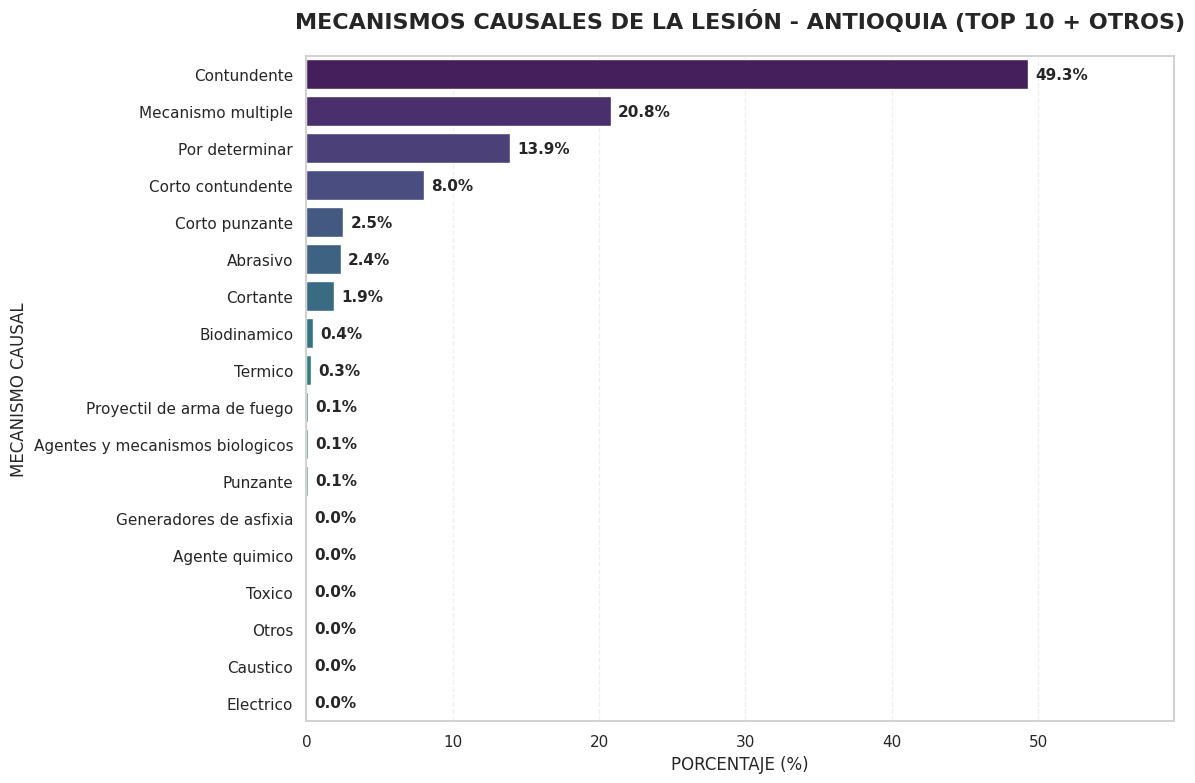

In [ ]:
#Col(29) df_antioquia

# 4. Tabla de frecuencias para Antioquia
tabla_mecanismo_ant = df_antioquia['mecanismo_causal_de_la_lesion_no_fatal'].value_counts().reset_index()
tabla_mecanismo_ant.columns = ['Mecanismo', 'Frecuencia']
tabla_mecanismo_ant['Porcentaje (%)'] = (tabla_mecanismo_ant['Frecuencia'] / tabla_mecanismo_ant['Frecuencia'].sum() * 100).round(2)

# 5. Gráfico de barras para Antioquia
plt.figure(figsize=(12, 8))
ax = sns.barplot(data=tabla_mecanismo_ant, x='Porcentaje (%)', y='Mecanismo', palette='viridis')

# Etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.5, p.get_y() + p.get_height() / 2, f'{width:.1f}%',
            ha='left', va='center', fontsize=11, fontweight='bold')

plt.title('MECANISMOS CAUSALES DE LA LESIÓN - ANTIOQUIA (TOP 10 + OTROS)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('PORCENTAJE (%)', fontsize=12)
plt.ylabel('MECANISMO CAUSAL', fontsize=12)
plt.xlim(0, tabla_mecanismo_ant['Porcentaje (%)'].max() + 10)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
df_antioquia['diagnostico_topografico_de_la_lesion_no_fatal'].value_counts()

,count
diagnostico_topografico_de_la_lesion_no_fatal,
Politraumatismo,18806
Trauma de miembros,2731
Por determinar,2711
Trauma facial,2574
Sin informacion,1954
Piel y faneras,897
Trauma de torax,547
Trauma craneano,416
Trauma de cuello,241


/tmp/ipykernel_193/3655053807.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_diag_ant, x='Porcentaje (%)', y='Diagnóstico', palette='terrain')


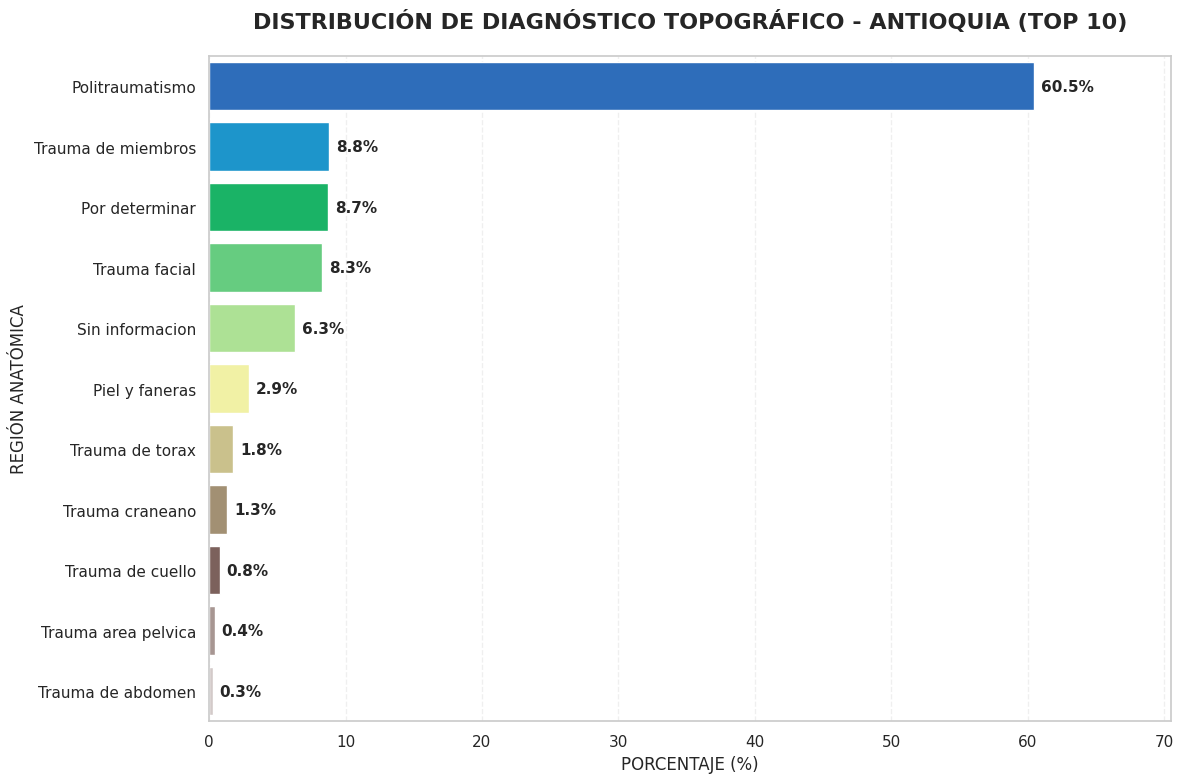

In [ ]:
#Col (30) df_antioquia

# 4. Tabla de frecuencias para Antioquia
tabla_diag_ant = df_antioquia['diagnostico_topografico_de_la_lesion_no_fatal'].value_counts().reset_index()
tabla_diag_ant.columns = ['Diagnóstico', 'Frecuencia']
tabla_diag_ant['Porcentaje (%)'] = (tabla_diag_ant['Frecuencia'] / tabla_diag_ant['Frecuencia'].sum() * 100).round(2)

# 5. Gráfico de barras horizontales para Antioquia
plt.figure(figsize=(12, 8))
ax = sns.barplot(data=tabla_diag_ant, x='Porcentaje (%)', y='Diagnóstico', palette='terrain')

# Etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.5, p.get_y() + p.get_height() / 2, f'{width:.1f}%',
            ha='left', va='center', fontsize=11, fontweight='bold')

plt.title('DISTRIBUCIÓN DE DIAGNÓSTICO TOPOGRÁFICO - ANTIOQUIA (TOP 10)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('PORCENTAJE (%)', fontsize=12)
plt.ylabel('REGIÓN ANATÓMICA', fontsize=12)
plt.xlim(0, tabla_diag_ant['Porcentaje (%)'].max() + 10)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
df_antioquia['sexo_del_agresor'].value_counts()

,count
sexo_del_agresor,
Hombre,20621
Mujer,9837
Sin informacion,629


/tmp/ipykernel_193/887321429.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_sexo_ant, x='Porcentaje (%)', y='Sexo del Agresor', palette='Set2')


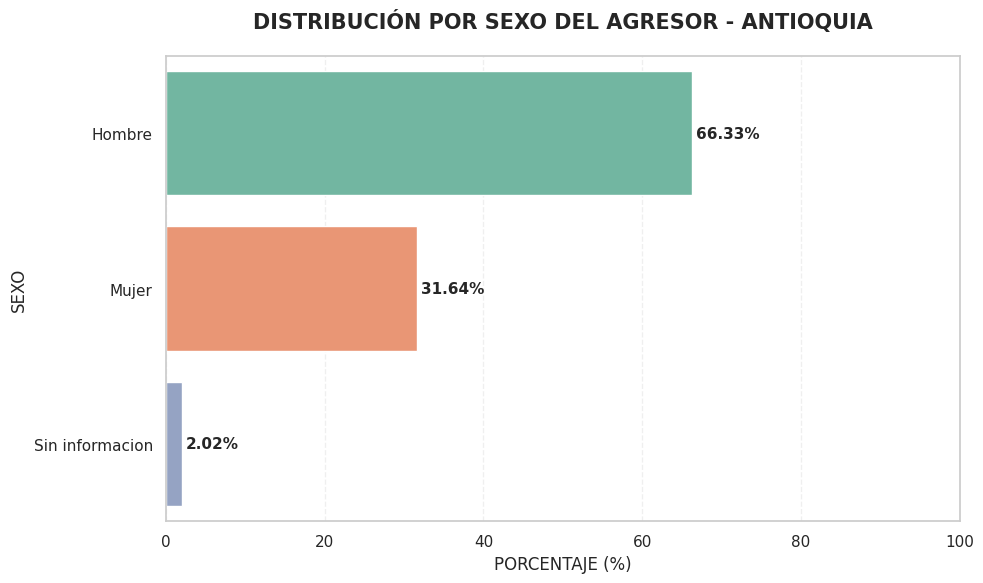

--- DETALLE DE FRECUENCIAS - ANTIOQUIA ---
  Sexo del Agresor  Frecuencia  Porcentaje (%)
0           Hombre       20621           66.33
1            Mujer        9837           31.64
2  Sin informacion         629            2.02


In [ ]:
# Col(31) df_antioquia

# 2. Cálculo de frecuencias y porcentajes para Antioquia
tabla_sexo_ant = df_antioquia['sexo_del_agresor'].value_counts().reset_index()
tabla_sexo_ant.columns = ['Sexo del Agresor', 'Frecuencia']
tabla_sexo_ant['Porcentaje (%)'] = (tabla_sexo_ant['Frecuencia'] / tabla_sexo_ant['Frecuencia'].sum() * 100).round(2)

# 3. Generar el gráfico para Antioquia
plt.figure(figsize=(10, 6))
# Usamos una paleta de colores contrastante
ax = sns.barplot(data=tabla_sexo_ant, x='Porcentaje (%)', y='Sexo del Agresor', palette='Set2')

# Añadir etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    if width > 0: # Solo poner etiqueta si el porcentaje es mayor a 0
        ax.text(width + 0.5, p.get_y() + p.get_height() / 2, f'{width:.2f}%',
                ha='left', va='center', fontsize=11, fontweight='bold')

plt.title('DISTRIBUCIÓN POR SEXO DEL AGRESOR - ANTIOQUIA', fontsize=15, fontweight='bold', pad=20)
plt.xlabel('PORCENTAJE (%)', fontsize=12)
plt.ylabel('SEXO', fontsize=12)
plt.xlim(0, 100) # El eje X hasta 100 facilita ver la dominancia
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

# 4. Mostrar la tabla para ver los casos pequeños que no se ven en el gráfico
print("--- DETALLE DE FRECUENCIAS - ANTIOQUIA ---")
print(tabla_sexo_ant)

In [ ]:
df_antioquia['presunto_agresor_detallado'].value_counts()

,count
presunto_agresor_detallado,
Hermano,6326
Hijo,4335
Padre,3542
Madre,3342
Otros familiares civiles o consanguineos,2534
Cunado,2047
Tio,1640
Sobrino,1616
Primo,1445


In [ ]:
#Col (32) df_antioquia
print("--- Frecuencias de presuntos agresores (Antioquia) ---")
print(df_antioquia['presunto_agresor_detallado'].value_counts())

--- Frecuencias de presuntos agresores (Antioquia) ---
presunto_agresor_detallado
Hermano                                     6326
Hijo                                        4335
Padre                                       3542
Madre                                       3342
Otros familiares civiles o consanguineos    2534
Cunado                                      2047
Tio                                         1640
Sobrino                                     1616
Primo                                       1445
Padrastro                                   1272
Sin informacion                              568
Yerno                                        529
Suegro                                       446
Nieto                                        405
Encargado del cuidado                        298
Nuera                                        281
Abuelo                                       269
Madrastra                                    178
Profesor                            

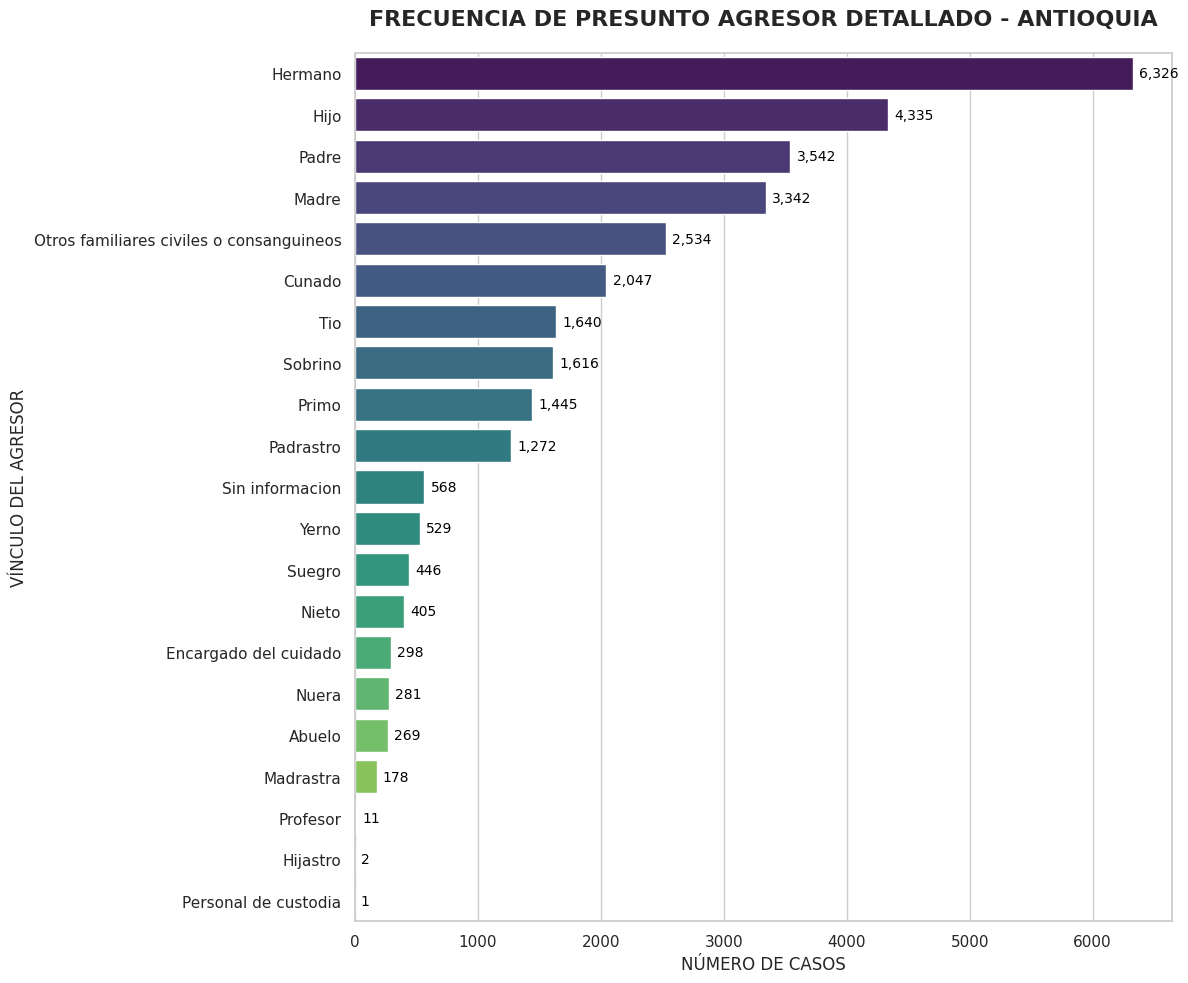

In [ ]:
# Col (32) df_antioquia
# 1. Preparar los datos para Antioquia
data_plot_ant = df_antioquia['presunto_agresor_detallado'].value_counts()

# 2. Configurar el estilo y el tamaño
plt.figure(figsize=(12, 10))
sns.set_theme(style="whitegrid")

# 3. Crear el gráfico utilizando df_antioquia
ax = sns.barplot(
    x=data_plot_ant.values,
    y=data_plot_ant.index,
    palette="viridis",
    hue=data_plot_ant.index,
    legend=False
)

# 4. Añadir etiquetas de datos al final de cada barra
for i, v in enumerate(data_plot_ant.values):
    ax.text(v + 50, i, f'{v:,}', va='center', fontsize=10, color='black')

# 5. Personalización estética
plt.title('FRECUENCIA DE PRESUNTO AGRESOR DETALLADO - ANTIOQUIA', fontsize=16, pad=20)
plt.xlabel('NÚMERO DE CASOS', fontsize=12)
plt.ylabel('VÍNCULO DEL AGRESOR', fontsize=12)

# Ajustar márgenes para que no se corten los nombres
plt.tight_layout()

# Mostrar el gráfico
plt.show()

In [ ]:
df_antioquia['factor_desencadenante_de_la_agresion'].value_counts()

,count
factor_desencadenante_de_la_agresion,
"Intolerancia, machismo",23362
Sin informacion,2233
Consumo de alcohol y/o sustancias psicoactivas,2069
Alcoholismo / drogadiccion,1929
Otras razones,393
Economicas,317
"Celos, desconfianza, infidelidad",292
Otras,286
Enfermedad fisica o mental,129


/tmp/ipykernel_193/1308420936.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_des_ant, x='Porcentaje (%)', y='Factor Desencadenante', palette='magma')


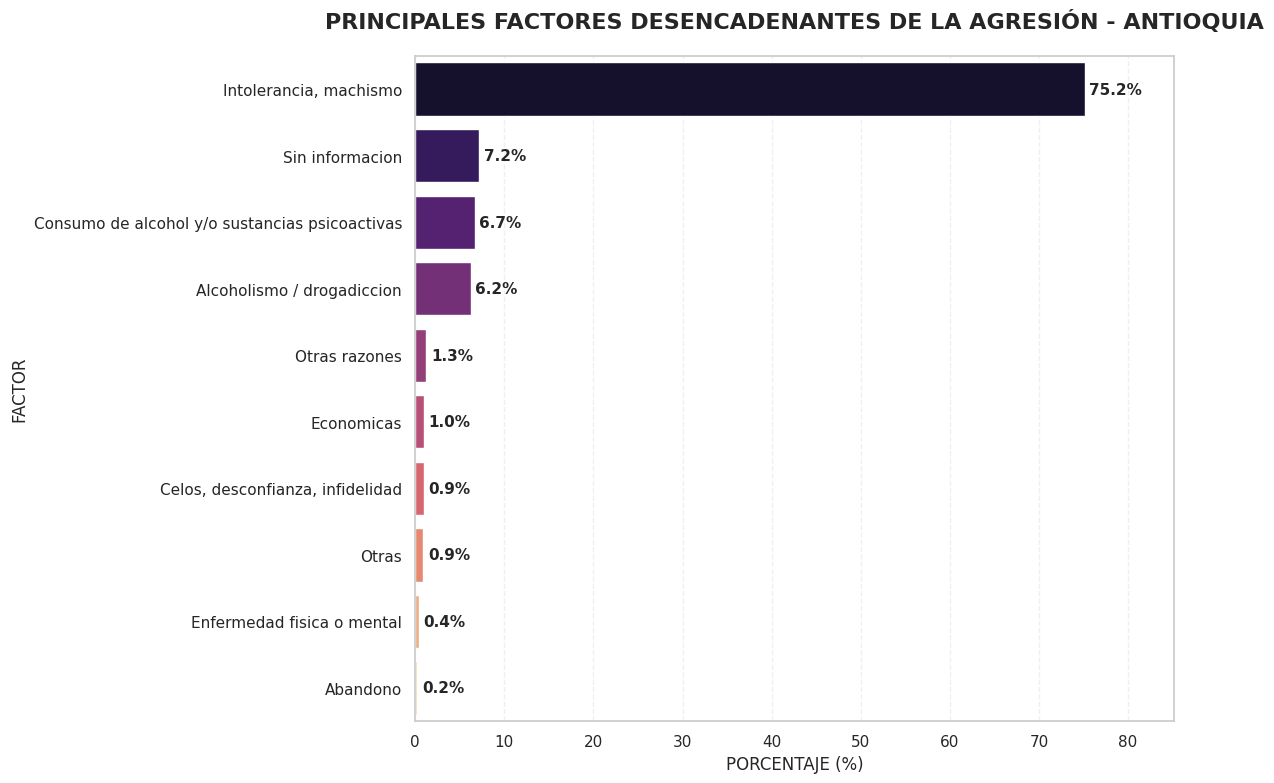

In [ ]:
#Col(33) df_antioquia

# 4. Tabla de frecuencias y porcentajes para Antioquia
tabla_des_ant = df_antioquia['factor_desencadenante_de_la_agresion'].value_counts().reset_index()
tabla_des_ant.columns = ['Factor Desencadenante', 'Frecuencia']
tabla_des_ant['Porcentaje (%)'] = (tabla_des_ant['Frecuencia'] / tabla_des_ant['Frecuencia'].sum() * 100).round(2)

# 5. Generar el gráfico para Antioquia
plt.figure(figsize=(12, 8))
ax = sns.barplot(data=tabla_des_ant, x='Porcentaje (%)', y='Factor Desencadenante', palette='magma')

# Añadir etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.5, p.get_y() + p.get_height() / 2, f'{width:.1f}%',
            ha='left', va='center', fontsize=11, fontweight='bold')

plt.title('PRINCIPALES FACTORES DESENCADENANTES DE LA AGRESIÓN - ANTIOQUIA', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('PORCENTAJE (%)', fontsize=12)
plt.ylabel('FACTOR', fontsize=12)
plt.xlim(0, tabla_des_ant['Porcentaje (%)'].max() + 10)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
 # Mostrar los valores únicos y su conteo antes de la unificación Columna 34 'dias_de_incapacidad_medicolegal'
display(df_antioquia['dias_de_incapacidad_medicolegal'].value_counts(dropna=False))

,count
dias_de_incapacidad_medicolegal,
1 a 30,25516
cero dias y sin informacion,2212
sin informacion,1190
cero dias,1014
31 a 90,704
sin dias de incapacidad,432
mas de 90,19


/tmp/ipykernel_193/3908085775.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_inc_ant, x='Porcentaje (%)', y='Rango de Incapacidad', palette='Reds')


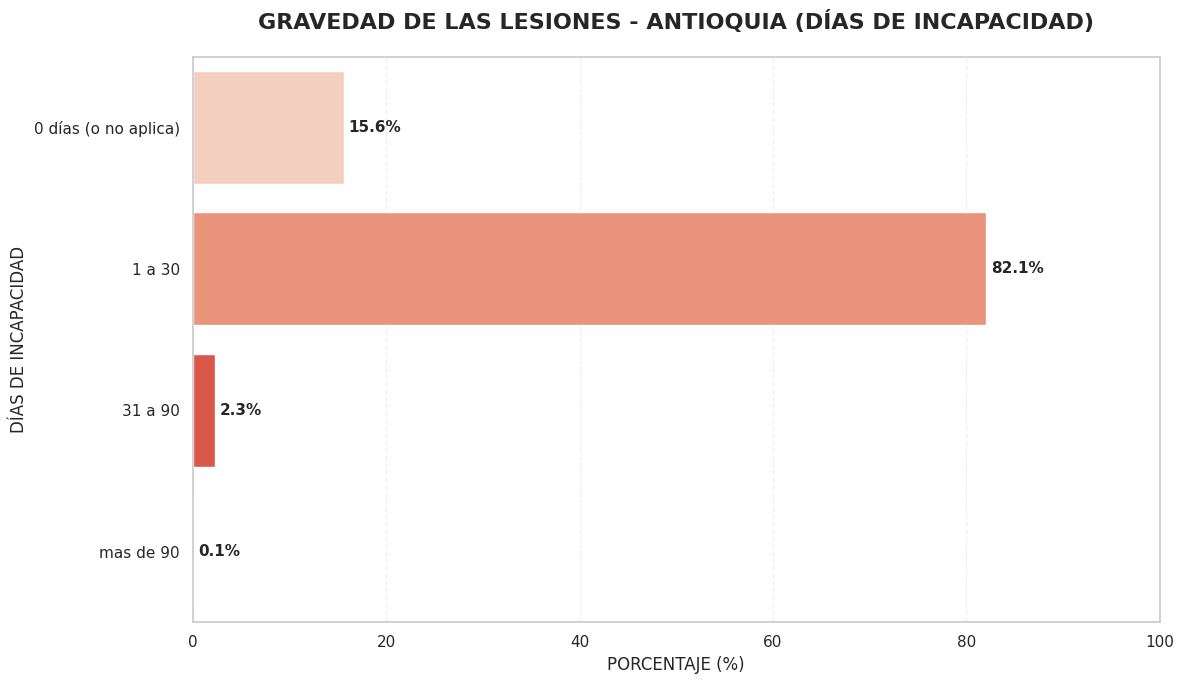

In [ ]:
#Col(34) df_antioquia
# 1. Diccionario de unificación para incapacidades (Antioquia)
mapeo_incapacidad = {
    'cero dias y sin informacion': '0 días (o no aplica)',
    'sin informacion': '0 días (o no aplica)',
    'cero dias': '0 días (o no aplica)',
    'sin dias de incapacidad': '0 días (o no aplica)',

}

# 2. Aplicar limpieza a df_antioquia
# Aseguramos que la columna sea tratada como string para aplicar .str.strip()
df_antioquia['incapacidad_final'] = df_antioquia['dias_de_incapacidad_medicolegal'].astype(str).str.strip().replace(mapeo_incapacidad)
df_antioquia['incapacidad_final'] = df_antioquia['incapacidad_final'].fillna('Sin información')

# 3. Definir el orden lógico (No alfabético)
orden_incapacidad = [
    '0 días (o no aplica)',
    '1 a 30',
    '31 a 90',
    'mas de 90'

]

# 4. Calcular tabla de frecuencias para Antioquia
tabla_inc_ant = df_antioquia['incapacidad_final'].value_counts().reindex(orden_incapacidad).fillna(0).reset_index()
tabla_inc_ant.columns = ['Rango de Incapacidad', 'Frecuencia']
tabla_inc_ant['Porcentaje (%)'] = (tabla_inc_ant['Frecuencia'] / tabla_inc_ant['Frecuencia'].sum() * 100).round(2)

# 5. Generar el gráfico para Antioquia
plt.figure(figsize=(12, 7))
# Usamos un degradado de color (Reds) para indicar aumento de gravedad
ax = sns.barplot(data=tabla_inc_ant, x='Porcentaje (%)', y='Rango de Incapacidad', palette='Reds')

# Etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    ax.text(width + 0.5, p.get_y() + p.get_height() / 2, f'{width:.1f}%',
            ha='left', va='center', fontsize=11, fontweight='bold')

plt.title('GRAVEDAD DE LAS LESIONES - ANTIOQUIA (DÍAS DE INCAPACIDAD)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('PORCENTAJE (%)', fontsize=12)
plt.ylabel('DÍAS DE INCAPACIDAD', fontsize=12)
plt.xlim(0, 100)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
df_antioquia.columns

Index(['id', 'ano_del_hecho', 'sexo_de_la_victima', 'grupo_de_edad_quinquenal',
       'grupo_mayor_menor_de_edad', 'grupo_de_edad_judicial', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'pertenencia_etnica', 'orientacion_sexual',
       'identidad_de_genero', 'transgenero', 'pertenencia_grupal',
       'mes_del_hecho', 'dia_del_hecho', 'rango_de_hora_del_hecho_x_3_horas',
       'codigo_dane_municipio', 'municipio_del_hecho_dane',
       'departamento_del_hecho_dane', 'codigo_dane_departamento',
       'localidad_del_hecho', 'zona_del_hecho', 'escenario_del_hecho',
       'actividad_durante_el_hecho', 'circunstancia_del_hecho_detallada',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'pueblo_indigena', 'mes_nu

In [ ]:
df_antioquia['incapacidad_final'].value_counts()

,count
incapacidad_final,
1 a 30,25516
0 días (o no aplica),4848
31 a 90,704
mas de 90,19


In [ ]:
# 1. PASO A: Reescribir la columna original con los datos limpios
df_antioquia['dias_de_incapacidad_medicolegal'] = df_antioquia['incapacidad_final']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df_antioquia = df_antioquia.drop(columns=['incapacidad_final'])

# 3. Verificación
print("La columna ahora tiene los datos limpios y es única.")

La columna ahora tiene los datos limpios y es única.


In [ ]:
# Mostrar los valores únicos y su conteo antes de la unificación Columna 34 'dias_de_incapacidad_medicolegal'
display(df_antioquia['dias_de_incapacidad_medicolegal'].value_counts(dropna=False))

,count
dias_de_incapacidad_medicolegal,
1 a 30,25516
0 días (o no aplica),4848
31 a 90,704
mas de 90,19


In [ ]:
#Col(35) df_antioquia
# Mostrar los valores únicos y su conteo antes de la unificación Columna 35 'pueblo_indigena'
display(df_antioquia['pueblo_indigena'].value_counts(dropna=False))

,count
pueblo_indigena,
No aplica,18190
No habia sido implementada,10228
Ninguno,2638
Embera-chami,10
Embera katio,8
Embera,6
Wayuu,2
Puinave,1
Wiwa,1


/tmp/ipykernel_193/3530586798.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=tabla_pueblo_ant, x='Porcentaje (%)', y='Pueblo Indígena', palette='tab20')


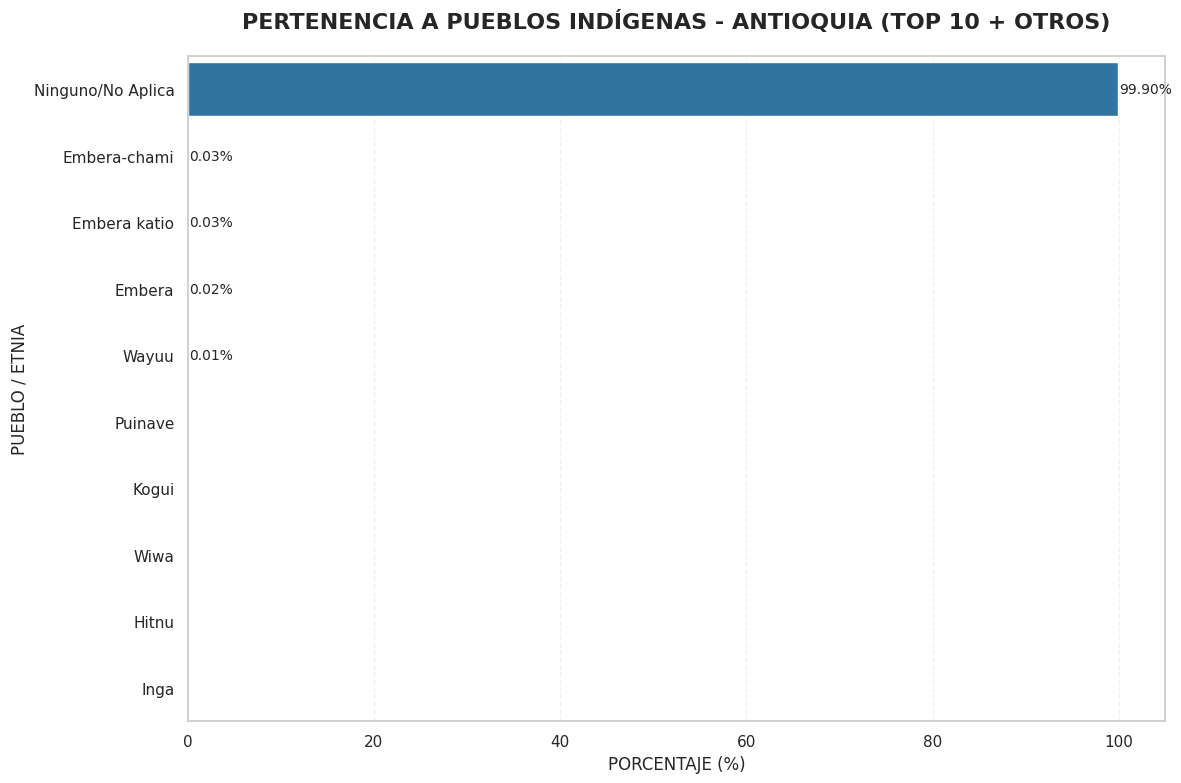

In [ ]:
# 1. Diccionario de unificación (Antioquia)
mapeo_indigena = {
    'No aplica': 'Ninguno/No Aplica',
    'Ninguno': 'Ninguno/No Aplica',
    'No habia sido implementada': 'Ninguno/No Aplica'
}

# 2. Aplicar limpieza a df_antioquia
df_antioquia['pueblo_final'] = df_antioquia['pueblo_indigena'].str.strip().replace(mapeo_indigena)
df_antioquia['pueblo_final'] = df_antioquia['pueblo_final'].fillna('Sin pertenencia étnica / No aplica')

# 3. Agrupar en Top 10 y Otros para Antioquia
top_10_pueblos_ant = df_antioquia['pueblo_final'].value_counts().nlargest(10).index
df_antioquia['pueblo_resumen'] = df_antioquia['pueblo_final'].apply(
    lambda x: x if x in top_10_pueblos_ant else 'Otros pueblos indígenas'
)

# 4. Tabla de frecuencias para Antioquia
tabla_pueblo_ant = df_antioquia['pueblo_resumen'].value_counts().reset_index()
tabla_pueblo_ant.columns = ['Pueblo Indígena', 'Frecuencia']
tabla_pueblo_ant['Porcentaje (%)'] = (tabla_pueblo_ant['Frecuencia'] / tabla_pueblo_ant['Frecuencia'].sum() * 100).round(2)

# 5. Generar el gráfico para Antioquia
plt.figure(figsize=(12, 8))
ax = sns.barplot(data=tabla_pueblo_ant, x='Porcentaje (%)', y='Pueblo Indígena', palette='tab20')

# Etiquetas de porcentaje
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.text(width + 0.1, p.get_y() + p.get_height() / 2, f'{width:.2f}%',
                ha='left', va='center', fontsize=10)

plt.title('PERTENENCIA A PUEBLOS INDÍGENAS - ANTIOQUIA (TOP 10 + OTROS)', fontsize=16, fontweight='bold', pad=20)
plt.xlabel('PORCENTAJE (%)')
plt.ylabel('PUEBLO / ETNIA')
plt.xlim(0, 105)
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:

# 1. PASO A: Reescribir la columna original con los datos limpios
df_antioquia['pueblo_indigena'] = df_antioquia['pueblo_final']

# 2. PASO B: Borrar la columna que ya no necesitas
# Ahora que la original tiene el dato bueno, la columna 'limpia' sobra
df_antioquia = df_antioquia.drop(columns=['pueblo_final'])

# 3. Verificación
print("La columna ahora tiene los datos limpios y es única.")

La columna ahora tiene los datos limpios y es única.


In [ ]:
df_antioquia = df_antioquia.drop(columns=['pueblo_resumen'])

##Revisión del df_antioquia

In [ ]:
# 1. Ver dimensiones (filas y columnas)
print(f"Dimensiones del dataset: {df_antioquia.shape[0]} filas y {df_antioquia.shape[1]} columnas.")

# 2. Listar todas las columnas disponibles
print("\nLista de columnas:")
for i, col in enumerate(df_antioquia.columns):
    print(f"{i+1}. {col}")

# 3. Ver una muestra de los datos (las primeras 5 filas)
print("\nVista previa de los datos:")
display(df_antioquia.head())

Dimensiones del dataset: 31087 filas y 39 columnas.

Lista de columnas:
1. id
2. ano_del_hecho
3. sexo_de_la_victima
4. grupo_de_edad_quinquenal
5. grupo_mayor_menor_de_edad
6. grupo_de_edad_judicial
7. ciclo_vital
8. pais_de_nacimiento
9. escolaridad
10. estado_civil
11. tipo_de_discapacidad
12. pertenencia_etnica
13. orientacion_sexual
14. identidad_de_genero
15. transgenero
16. pertenencia_grupal
17. mes_del_hecho
18. dia_del_hecho
19. rango_de_hora_del_hecho_x_3_horas
20. codigo_dane_municipio
21. municipio_del_hecho_dane
22. departamento_del_hecho_dane
23. codigo_dane_departamento
24. localidad_del_hecho
25. zona_del_hecho
26. escenario_del_hecho
27. actividad_durante_el_hecho
28. circunstancia_del_hecho_detallada
29. contexto_del_hecho
30. mecanismo_causal_de_la_lesion_no_fatal
31. diagnostico_topografico_de_la_lesion_no_fatal
32. sexo_del_agresor
33. presunto_agresor_detallado
34. factor_desencadenante_de_la_agresion
35. dias_de_incapacidad_medicolegal
36. pueblo_indigena
37. me

,id,ano_del_hecho,sexo_de_la_victima,grupo_de_edad_quinquenal,grupo_mayor_menor_de_edad,grupo_de_edad_judicial,ciclo_vital,pais_de_nacimiento,escolaridad,estado_civil,...,mecanismo_causal_de_la_lesion_no_fatal,diagnostico_topografico_de_la_lesion_no_fatal,sexo_del_agresor,presunto_agresor_detallado,factor_desencadenante_de_la_agresion,dias_de_incapacidad_medicolegal,pueblo_indigena,mes_num,dia_num,fecha_hecho
23,24.0,2015,mujer,(50 a 54),b) mayor de edad (>18 anos),(50 a 54),(29 a 59) adultez,Colombia,Primaria,"separado (a), divorciado (a)",...,Contundente,Politraumatismo,Hombre,Primo,"Intolerancia, machismo",1 a 30,Ninguno/No Aplica,8,4,2015-08-04
49,50.0,2015,mujer,(65 a 69),b) mayor de edad (>18 anos),(65 a 69),(mas de 60) adulto mayor,Colombia,Preescolar,soltero (a),...,Contundente,Politraumatismo,Hombre,Cunado,"Intolerancia, machismo",1 a 30,Ninguno/No Aplica,7,3,2015-07-03
50,51.0,2015,mujer,(60 a 64),b) mayor de edad (>18 anos),(60 a 64),(mas de 60) adulto mayor,Colombia,Preescolar,"separado (a), divorciado (a)",...,Mecanismo multiple,Politraumatismo,Mujer,Hermano,"Celos, desconfianza, infidelidad",1 a 30,Ninguno/No Aplica,11,6,2015-11-06
52,53.0,2015,mujer,(55 a 59),b) mayor de edad (>18 anos),(55 a 59),(29 a 59) adultez,Colombia,Primaria,union libre,...,Punzante,Politraumatismo,Mujer,Cunado,"Intolerancia, machismo",1 a 30,Ninguno/No Aplica,10,1,2015-10-01
71,71.0,2015,mujer,(50 a 54),b) mayor de edad (>18 anos),(50 a 54),(29 a 59) adultez,Colombia,Primaria,soltero (a),...,Contundente,Politraumatismo,Hombre,Hijo,"Intolerancia, machismo",1 a 30,Ninguno/No Aplica,11,7,2015-11-07


In [ ]:
# Definimos la lista de columnas que deseamos extraer del df_antioquia
columnas_seleccionadas = [
    'ano_del_hecho',
    'sexo_de_la_victima',
    'ciclo_vital',
    'pais_de_nacimiento',
    'escolaridad',
    'estado_civil',
    'tipo_de_discapacidad',
    'orientacion_sexual',
    'zona_del_hecho',
    'escenario_del_hecho',
    'actividad_durante_el_hecho',
    'contexto_del_hecho',
    'mecanismo_causal_de_la_lesion_no_fatal',
    'diagnostico_topografico_de_la_lesion_no_fatal',
    'sexo_del_agresor',
    'presunto_agresor_detallado',
    'factor_desencadenante_de_la_agresion',
    'dias_de_incapacidad_medicolegal'
]

# Creamos df_model seleccionando las columnas del dataframe original
df_model = df_antioquia[columnas_seleccionadas].copy()

# Opcional: verificar las primeras filas del nuevo dataframe
print(df_model.head())

    ano_del_hecho sexo_de_la_victima               ciclo_vital  \
23           2015              mujer         (29 a 59) adultez   
49           2015              mujer  (mas de 60) adulto mayor   
50           2015              mujer  (mas de 60) adulto mayor   
52           2015              mujer         (29 a 59) adultez   
71           2015              mujer         (29 a 59) adultez   

   pais_de_nacimiento escolaridad                  estado_civil  \
23           Colombia    Primaria  separado (a), divorciado (a)   
49           Colombia  Preescolar                   soltero (a)   
50           Colombia  Preescolar  separado (a), divorciado (a)   
52           Colombia    Primaria                   union libre   
71           Colombia    Primaria                   soltero (a)   

   tipo_de_discapacidad    orientacion_sexual      zona_del_hecho  \
23              ninguna          heterosexual  Cabecera Municipal   
49              ninguna  no sabe / no informa  Cabecera Munici

In [ ]:
df_model.columns

Index(['ano_del_hecho', 'sexo_de_la_victima', 'ciclo_vital',
       'pais_de_nacimiento', 'escolaridad', 'estado_civil',
       'tipo_de_discapacidad', 'orientacion_sexual', 'zona_del_hecho',
       'escenario_del_hecho', 'actividad_durante_el_hecho',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal'],
      dtype='object')

#Preprocesamiento de df_model

In [ ]:
#df_model Columna(4) pais_de_nacimiento (directamente con Pandas)
#Creamos la nueva columna
df_model['es_colombiano'] = df_model['pais_de_nacimiento'].apply(lambda x: 1 if x == 'Colombia' else 0)

In [ ]:
df_model['es_colombiano'].value_counts()

,count
es_colombiano,
1,30647
0,440


In [ ]:
# Luego, simplemente eliminas la columna 'pais_de_nacimiento' original
df_model = df_model.drop(columns=['pais_de_nacimiento'])

In [ ]:
df_model['tipo_de_discapacidad'].value_counts()

,count
tipo_de_discapacidad,
ninguna,30790
fisica,67
mental,60
discapacidad multiple,56
auditiva,51
visual,27
siquica,25
intelectual,7
psicosocial,4


In [ ]:
#df_model Columna(7) tipo_de_discapacidad (directamente con Pandas)
#Creamos la nueva columna
df_model['tiene_discapacidad'] = df_model['tipo_de_discapacidad'].apply(lambda x: 0 if x == 'ninguna' else 1)

In [ ]:
df_model['tiene_discapacidad'].value_counts()

,count
tiene_discapacidad,
0,30790
1,297


In [ ]:
# Ahora puedes eliminar la columna original 'tipo_de_discapacidad'
# porque ya capturaste la información esencial en la nueva columna binaria.
df_model = df_model.drop(columns=['tipo_de_discapacidad'])

In [ ]:
df_model.columns

Index(['ano_del_hecho', 'sexo_de_la_victima', 'ciclo_vital', 'escolaridad',
       'estado_civil', 'orientacion_sexual', 'zona_del_hecho',
       'escenario_del_hecho', 'actividad_durante_el_hecho',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'factor_desencadenante_de_la_agresion',
       'dias_de_incapacidad_medicolegal', 'es_colombiano',
       'tiene_discapacidad'],
      dtype='object')

In [ ]:
df_model['orientacion_sexual'].value_counts()

,count
orientacion_sexual,
heterosexual,23127
no sabe / no informa,5528
no aplica,2143
homosexual,244
bisexual,41
asexual,4


In [ ]:
#df_model Columna(8) orientacion_sexual (directamente con Pandas)
# Convertimos a 1 si es 'heterosexual', y a 0 en cualquier otro caso (incluyendo 'no')
df_model['es_heterosexual'] = df_model['orientacion_sexual'].apply(lambda x: 1 if x == 'heterosexual' else 0)

In [ ]:
df_model['es_heterosexual'].value_counts()

,count
es_heterosexual,
1,23127
0,7960


In [ ]:
# Eliminamos la original
df_model = df_model.drop(columns=['orientacion_sexual'])

In [ ]:
df_model['escenario_del_hecho'].value_counts()

,count
escenario_del_hecho,
Vivienda,24701
Calle,2552
Vía pública,1714
Sin información,795
Establecimiento comercial,286
Centros educativos,158
Lugares de hospedaje,134
Carretera,122
Áreas deportivas y/o recreativas,91


In [ ]:
# Crear una variable binaria: 1 si ocurrió en vivienda, 0 si ocurrió en otro lugar
df_model['ocurrio_en_vivienda'] = df_model['escenario_del_hecho'].apply(lambda x: 1 if x == 'Vivienda' else 0)

In [ ]:
df_model['ocurrio_en_vivienda'].value_counts()

,count
ocurrio_en_vivienda,
1,24701
0,6386


In [ ]:
# Eliminar la variable original
df_model = df_model.drop(columns=['escenario_del_hecho'])

In [ ]:
df_model['factor_desencadenante_de_la_agresion'].value_counts()

,count
factor_desencadenante_de_la_agresion,
"Intolerancia, machismo",23362
Sin informacion,2233
Consumo de alcohol y/o sustancias psicoactivas,2069
Alcoholismo / drogadiccion,1929
Otras razones,393
Economicas,317
"Celos, desconfianza, infidelidad",292
Otras,286
Enfermedad fisica o mental,129


In [ ]:
# Mapeo para agrupar razones similares
mapeo_desencadenantes = {
    'Intolerancia, machismo': 'Intolerancia/Machismo',
    'Consumo de alcohol y/o sustancias psicoactivas': 'Consumo sustancias',
    'Alcoholismo / drogadiccion': 'Consumo sustancias',
    'Celos, desconfianza, infidelidad': 'Conflictos de pareja',
    'Economicas': 'Economicas',
    'Enfermedad fisica o mental': 'Salud',
    'Abandono': 'Abandono',
    'Otras razones': 'Otras',
    'Otras': 'Otras',
    'Sin informacion': 'No registra'
}

# Aplicar el mapeo
df_model['factor_limpio'] = df_model['factor_desencadenante_de_la_agresion'].map(mapeo_desencadenantes)

# Rellenar los que no quedaron en el mapeo con 'No registra' o 'Otras'
df_model['factor_limpio'] = df_model['factor_limpio'].fillna('No registra')

# Ver la nueva distribución para tomar la decisión
distribucion_limpia = df_model['factor_limpio'].value_counts()
print(distribucion_limpia)

factor_limpio
Intolerancia/Machismo    23362
Consumo sustancias        3998
No registra               2233
Otras                      679
Economicas                 317
Conflictos de pareja       292
Salud                      129
Abandono                    77
Name: count, dtype: int64


In [ ]:
# 1. Calcular conteos y porcentajes
conteo = df_model['factor_limpio'].value_counts()
porcentaje = df_model['factor_limpio'].value_counts(normalize=True) * 100

# 2. Unirlos en un DataFrame para visualizar mejor
tabla_resumen = pd.DataFrame({'Conteo': conteo, 'Porcentaje (%)': porcentaje.round(2)})

print(tabla_resumen)

                       Conteo  Porcentaje (%)
factor_limpio                                
Intolerancia/Machismo   23362           75.15
Consumo sustancias       3998           12.86
No registra              2233            7.18
Otras                     679            2.18
Economicas                317            1.02
Conflictos de pareja      292            0.94
Salud                     129            0.41
Abandono                   77            0.25


In [ ]:
# --- NUEVA BINARIZACIÓN PARA FACTOR LIMPIO ---
df_model['es_intolerancia_machismo'] = df_model['factor_limpio'].apply(lambda x: 1 if x == 'Intolerancia/Machismo' else 0)

In [ ]:
df_model['es_intolerancia_machismo'].value_counts()

,count
es_intolerancia_machismo,
1,23362
0,7725


In [ ]:
# Eliminar la variable original y la de la limpieza
df_model = df_model.drop(columns=['factor_desencadenante_de_la_agresion'])
df_model = df_model.drop(columns=['factor_limpio'])

In [ ]:
df_model.columns

Index(['ano_del_hecho', 'sexo_de_la_victima', 'ciclo_vital', 'escolaridad',
       'estado_civil', 'zona_del_hecho', 'actividad_durante_el_hecho',
       'contexto_del_hecho', 'mecanismo_causal_de_la_lesion_no_fatal',
       'diagnostico_topografico_de_la_lesion_no_fatal', 'sexo_del_agresor',
       'presunto_agresor_detallado', 'dias_de_incapacidad_medicolegal',
       'es_colombiano', 'tiene_discapacidad', 'es_heterosexual',
       'ocurrio_en_vivienda', 'es_intolerancia_machismo'],
      dtype='object')

In [ ]:
df_model['sexo_de_la_victima'].value_counts()

,count
sexo_de_la_victima,
mujer,18893
hombre,12194


In [ ]:
#Directamente con Pandas
# Transformamos a 1 si es 'mujer' y a 0 si es 'hombre'
df_model['es_mujer'] = df_model['sexo_de_la_victima'].apply(lambda x: 1 if x == 'mujer' else 0)

# Eliminamos la columna original
df_model = df_model.drop(columns=['sexo_de_la_victima'])

# Verificamos
print(df_model['es_mujer'].value_counts())

es_mujer
1    18893
0    12194
Name: count, dtype: int64


###Variables que requieren Jerarquización

In [ ]:
#Visualización previa de las columnas que requieren jerarquía
print("Ciclo vital:", df_model['ciclo_vital'].unique())
print("Escolaridad:", df_model['escolaridad'].unique())
print("Mecanismo:", df_model['mecanismo_causal_de_la_lesion_no_fatal'].unique())
print("Incapacidad:", df_model['dias_de_incapacidad_medicolegal'].unique())

Ciclo vital: ['(29 a 59) adultez' '(mas de 60) adulto mayor' '(12 a 17) adolescencia'
 '(18 a 28) juventud' '(06 a 11) infancia' '(00 a 05) primera infancia'
 'sin informacion']
Escolaridad: ['Primaria' 'Preescolar' 'Secundaria' 'Ninguna' 'Técnica/Tecnólogica'
 'Sin información' 'Profesional' 'Especialización/Maestría' nan
 'Doctorado']
Mecanismo: ['Contundente' 'Mecanismo multiple' 'Punzante' 'Corto punzante'
 'Por determinar' 'Corto contundente' 'Abrasivo' 'Cortante' 'Termico'
 'Proyectil de arma de fuego' 'Biodinamico' 'Otros'
 'Generadores de asfixia' 'Electrico' 'Toxico'
 'Agentes y mecanismos biologicos' 'Caustico' 'Agente quimico']
Incapacidad: ['1 a 30' '0 días (o no aplica)' '31 a 90' 'mas de 90']


In [ ]:
print(df_model['ciclo_vital'].value_counts())

ciclo_vital
(29 a 59) adultez             12450
(18 a 28) juventud             6027
(12 a 17) adolescencia         4509
(mas de 60) adulto mayor       3364
(06 a 11) infancia             2998
(00 a 05) primera infancia     1738
sin informacion                   1
Name: count, dtype: int64


In [ ]:
print(df_model['escolaridad'].value_counts())

escolaridad
Primaria                    9872
Secundaria                  9317
Técnica/Tecnólogica         3335
Ninguna                     1629
Sin información             1312
Preescolar                   895
Profesional                   87
Especialización/Maestría      30
Doctorado                      1
Name: count, dtype: int64


In [ ]:
# ==========================================
# DICCIONARIOS DE JERARQUÍA
# ==========================================
# Ajustar los textos exactos según lo que arrojó value_counts()

jerarquia_ciclo_vital = {
    'sin informacion': 0,
    '(00 a 05) primera infancia': 1,
    '(06 a 11) infancia': 2,
    '(12 a 17) adolescencia': 3,
    '(18 a 28) juventud': 4,
    '(29 a 59) adultez': 5,
    '(mas de 60) adulto mayor': 6
}

jerarquia_escolaridad = {
    'sin información': 0,
    'nan':0,
    'ninguna': 1,
    'preescolar': 2,
    'primaria': 3,
    'secundaria': 4,
    'técnica/tecnólogica': 5,
    'profesional': 8,
    'especialización/maestría': 9,
    'doctorado': 10
}

# ==========================================
# TRANSFORMACIÓN DEL DATAFRAME
# ==========================================

# 1. Estandarizar a minúsculas y limpiar espacios en ambas columnas
df_model['ciclo_vital'] = df_model['ciclo_vital'].astype(str).str.strip().str.lower()
df_model['escolaridad'] = df_model['escolaridad'].astype(str).str.strip().str.lower()

# 2. Aplicar los mapeos
df_model['ciclo_vital_jerarquico'] = df_model['ciclo_vital'].map(jerarquia_ciclo_vital)
df_model['escolaridad_jerarquica'] = df_model['escolaridad'].map(jerarquia_escolaridad)

# 3. Verificación de seguridad
nulos_ciclo = df_model['ciclo_vital_jerarquico'].isnull().sum()
nulos_escolaridad = df_model['escolaridad_jerarquica'].isnull().sum()

print(f"Valores no mapeados en Ciclo_vital: {nulos_ciclo}")
print(f"Valores no mapeados en Escolaridad: {nulos_escolaridad}")

# 4. Eliminación de columnas originales si el mapeo es 100% exitoso
if nulos_ciclo == 0 and nulos_escolaridad == 0:
    df_model = df_model.drop(columns=['ciclo_vital', 'escolaridad'])
    print("\n¡Mapeo exitoso! Las columnas originales fueron reemplazadas por sus versiones jerárquicas.")
else:
    print("\nRevisar los textos: Hay valores que no coinciden exactamente con el diccionario.")

Valores no mapeados en Ciclo_vital: 0
Valores no mapeados en Escolaridad: 0

¡Mapeo exitoso! Las columnas originales fueron reemplazadas por sus versiones jerárquicas.


In [ ]:
print(df_model['ciclo_vital_jerarquico'].value_counts())

ciclo_vital_jerarquico
5    12450
4     6027
3     4509
6     3364
2     2998
1     1738
0        1
Name: count, dtype: int64


In [ ]:
print(df_model['escolaridad_jerarquica'].value_counts())

escolaridad_jerarquica
3     9872
4     9317
0     5921
5     3335
1     1629
2      895
8       87
9       30
10       1
Name: count, dtype: int64


In [ ]:
print(df_model['mecanismo_causal_de_la_lesion_no_fatal'].value_counts())

mecanismo_causal_de_la_lesion_no_fatal
Contundente                        15322
Mecanismo multiple                  6465
Por determinar                      4317
Corto contundente                   2493
Corto punzante                       788
Abrasivo                             735
Cortante                             584
Biodinamico                          134
Termico                               97
Proyectil de arma de fuego            42
Agentes y mecanismos biologicos       34
Punzante                              32
Generadores de asfixia                13
Agente quimico                         8
Toxico                                 7
Otros                                  7
Caustico                               5
Electrico                              4
Name: count, dtype: int64


In [ ]:
# 1. Definir el diccionario con la jerarquía de letalidad
# (Asegúrate de que los textos coincidan exactamente con las salidas de tu dataframe)
jerarquia_mecanismo = {
    'sin dato': 0,
    'no reportado': 0,
    'sin establecer': 0,
    'caída': 1,
    'arma contundente': 2,
    'agente contundente': 2,
    'arma cortopunzante': 3,
    'proyectil de arma de fuego': 3,
    'asfixia': 3,
    'quemadura': 3,
    'explosivo': 3,
    'sustancias toxicas': 3, # Revisar si lleva tilde en tu dataset
    'múltiples mecanismos': 4
}

# 2. Convertir los valores de la columna a texto en minúsculas y quitar espacios extra
# para evitar errores de tipeo al mapear
df_model['mecanismo_causal_de_la_lesion_no_fatal'] = df_model['mecanismo_causal_de_la_lesion_no_fatal'].astype(str).str.strip().str.lower()

# 3. Aplicar el mapeo
df_model['mecanismo_causal_jerarquico'] = df_model['mecanismo_causal_de_la_lesion_no_fatal'].map(jerarquia_mecanismo)

# 4. Verificar si quedaron valores nulos (textos que no estaban en el diccionario)
nulos_generados = df_model['mecanismo_causal_jerarquico'].isnull().sum()
print(f"Valores no mapeados (nulos): {nulos_generados}")

# 5. Opcional: Eliminar la columna original si el mapeo fue exitoso
if nulos_generados == 0:
    df_model = df_model.drop(columns=['mecanismo_causal_de_la_lesion_no_fatal'])
    print("Mapeo exitoso. Columna original eliminada.")

Valores no mapeados (nulos): 31045


In [ ]:
# 1. Definir el diccionario con todos los valores únicos exactos en minúsculas
jerarquia_mecanismo = {
    'por determinar': 0,
    'otros': 0,

    'abrasivo': 1,
    'biodinamico': 1,

    'contundente': 2,

    'corto contundente': 3,
    'corto punzante': 3,
    'cortante': 3,
    'punzante': 3,
    'proyectil de arma de fuego': 3,
    'termico': 3,
    'agentes y mecanismos biologicos': 3,
    'generadores de asfixia': 3,
    'agente quimico': 3,
    'toxico': 3,
    'caustico': 3,
    'electrico': 3,

    'mecanismo multiple': 4
}

# 2. Estandarizar la columna a minúsculas y quitar posibles espacios ocultos
df_model['mecanismo_causal_de_la_lesion_no_fatal'] = df_model['mecanismo_causal_de_la_lesion_no_fatal'].astype(str).str.strip().str.lower()

# 3. Aplicar el mapeo y crear la nueva columna jerárquica
df_model['mecanismo_causal_jerarquico'] = df_model['mecanismo_causal_de_la_lesion_no_fatal'].map(jerarquia_mecanismo)

# 4. Verificación de seguridad
nulos = df_model['mecanismo_causal_jerarquico'].isnull().sum()
if nulos == 0:
    # Si todo salió bien, eliminamos la columna original de texto
    df_model = df_model.drop(columns=['mecanismo_causal_de_la_lesion_no_fatal'])
    print("¡Mapeo exitoso! La columna original fue reemplazada por 'mecanismo_causal_jerarquico'.")
    print(df_model['mecanismo_causal_jerarquico'].value_counts())
else:
    print(f"Ojo: Hay {nulos} valores que no se lograron mapear. Revisa los textos.")

¡Mapeo exitoso! La columna original fue reemplazada por 'mecanismo_causal_jerarquico'.
mecanismo_causal_jerarquico
2    15322
4     6465
0     4324
3     4107
1      869
Name: count, dtype: int64


In [ ]:
print(df_model['diagnostico_topografico_de_la_lesion_no_fatal'].value_counts())

diagnostico_topografico_de_la_lesion_no_fatal
Politraumatismo        18806
Trauma de miembros      2731
Por determinar          2711
Trauma facial           2574
Sin informacion         1954
Piel y faneras           897
Trauma de torax          547
Trauma craneano          416
Trauma de cuello         241
Trauma area pelvica      125
Trauma de abdomen         85
Name: count, dtype: int64


In [ ]:
# ==========================================
# DICCIONARIO DE JERARQUÍA: ZONA AFECTADA
# ==========================================
jerarquia_topografica = {
    'por determinar': 0,
    'sin informacion': 0,
    'sin información': 0, # Por si acaso alguna viene con tilde

    'piel y faneras': 1,
    'trauma de miembros': 1,

    'trauma facial': 2,

    'trauma de torax': 3,
    'trauma de tórax': 3,
    'trauma de abdomen': 3,
    'trauma area pelvica': 3,
    'trauma área pélvica': 3,

    'trauma craneano': 4,
    'trauma de cuello': 4,

    'politraumatismo': 5
}

# ==========================================
# TRANSFORMACIÓN DEL DATAFRAME
# ==========================================

# 1. Estandarización a minúsculas y eliminación de espacios extra
df_model['diagnostico_topografico_de_la_lesion_no_fatal'] = df_model['diagnostico_topografico_de_la_lesion_no_fatal'].astype(str).str.strip().str.lower()

# 2. Aplicación del mapeo para crear la nueva columna
df_model['zona_lesion_jerarquica'] = df_model['diagnostico_topografico_de_la_lesion_no_fatal'].map(jerarquia_topografica)

# 3. Verificación de seguridad
nulos_topografico = df_model['zona_lesion_jerarquica'].isnull().sum()
print(f"Valores no mapeados en Diagnóstico Topográfico: {nulos_topografico}")

# 4. Eliminación de la columna original si el mapeo es 100% exitoso
if nulos_topografico == 0:
    df_model = df_model.drop(columns=['diagnostico_topografico_de_la_lesion_no_fatal'])
    print("\n¡Transformación exitosa! La columna original fue reemplazada por 'zona_lesion_jerarquica'.")
    print(df_model['zona_lesion_jerarquica'].value_counts().sort_index())
else:
    print("\nAdvertencia: Faltan valores por mapear en el diccionario.")
    print(df_model[df_model['zona_lesion_jerarquica'].isnull()]['diagnostico_topografico_de_la_lesion_no_fatal'].value_counts())

Valores no mapeados en Diagnóstico Topográfico: 0

¡Transformación exitosa! La columna original fue reemplazada por 'zona_lesion_jerarquica'.
zona_lesion_jerarquica
0     4665
1     3628
2     2574
3      757
4      657
5    18806
Name: count, dtype: int64


In [ ]:
print(df_model['dias_de_incapacidad_medicolegal'].value_counts())

dias_de_incapacidad_medicolegal
1 a 30                  25516
0 días (o no aplica)     4848
31 a 90                   704
mas de 90                  19
Name: count, dtype: int64


In [ ]:
# ==========================================
# DICCIONARIO DE JERARQUÍA ACTUALIZADO: INCAPACIDAD
# ==========================================
# Se agrupan las categorías existentes en los 4 niveles definidos.
# Se incluyen posibles variaciones de texto (con y sin tildes).

jerarquia_incapacidad = {
    '0 días (o no aplica)': 0,
    '1 a 30': 2,
    '31 a 90': 3,
    '31 a 90 días': 3,
    'mas de 90': 4
}

# ==========================================
# TRANSFORMACIÓN DEL DATAFRAME
# ==========================================

# 1. Estandarización del formato de texto (minúsculas y sin espacios extra)
df_model['dias_de_incapacidad_medicolegal'] = df_model['dias_de_incapacidad_medicolegal'].astype(str).str.strip().str.lower()

# 2. Aplicación del mapeo para crear la nueva columna ordinal
df_model['incapacidad_jerarquica'] = df_model['dias_de_incapacidad_medicolegal'].map(jerarquia_incapacidad)

# 3. Verificación de seguridad para detectar valores no mapeados
nulos_incapacidad = df_model['incapacidad_jerarquica'].isnull().sum()
print(f"Valores no mapeados en Incapacidad: {nulos_incapacidad}")

# 4. Eliminación de la columna original si la transformación es exitosa
if nulos_incapacidad == 0:
    df_model = df_model.drop(columns=['dias_de_incapacidad_medicolegal'])
    print("\nTransformación exitosa. La columna original fue reemplazada por 'incapacidad_jerarquica'.")
    print(df_model['incapacidad_jerarquica'].value_counts().sort_index())
else:
    print("\nAdvertencia: Existen valores en el dataset que no fueron contemplados en el diccionario.")
    # Se imprimen los valores exactos que faltan por clasificar para poder agregarlos
    valores_faltantes = df_model[df_model['incapacidad_jerarquica'].isnull()]['dias_de_incapacidad_medicolegal'].value_counts()
    print("Por favor, añadir las siguientes categorías al diccionario:\n", valores_faltantes)

Valores no mapeados en Incapacidad: 0

Transformación exitosa. La columna original fue reemplazada por 'incapacidad_jerarquica'.
incapacidad_jerarquica
0     4848
2    25516
3      704
4       19
Name: count, dtype: int64


###Variables nominales que no requieren jerarquización

In [ ]:
df_model['estado_civil'].value_counts()

,count
estado_civil,
soltero (a),15461
union libre,5194
no aplica,3623
casado (a),3372
"separado (a), divorciado (a)",1471
viudo (a),1179
sin informacion,787


In [ ]:
df_model['zona_del_hecho'].value_counts()

,count
zona_del_hecho,
Cabecera Municipal,26404
Parte Rural,2873
Centro Poblado,851


In [ ]:
df_model['actividad_durante_el_hecho'].value_counts()

,count
actividad_durante_el_hecho,
Actividades de trabajo doméstico no remunerado,9827
Actividades vitales o relacionadas con el cuidado personal,8007
Actividades de desplazamiento de un lugar a otro,6308
Otra,3221
Actividades relacionadas con enfrentamientos armados,1279
Actividades deportivas y/o tiempo libre,967
Sin informacion,579
Actividades relacionadas con el aprendizaje,353
Actividades ilicitas o delictivas,345


In [ ]:
df_model['contexto_del_hecho'].value_counts()

,count
contexto_del_hecho,
lesiones no fatales por violencia entre otros familiares,18478
"lesiones no fatales contra ninos, ninas y adolescentes por violencia intrafamiliar",9245
lesiones no fatales contra el adulto mayor por violencia intrafamiliar,3364


In [ ]:
df_model['sexo_del_agresor'].value_counts()

,count
sexo_del_agresor,
Hombre,20621
Mujer,9837
Sin informacion,629


In [ ]:
df_model['presunto_agresor_detallado'].value_counts()

,count
presunto_agresor_detallado,
Hermano,6326
Hijo,4335
Padre,3542
Madre,3342
Otros familiares civiles o consanguineos,2534
Cunado,2047
Tio,1640
Sobrino,1616
Primo,1445


#ONE-HOT ENCODING

In [ ]:
# 1. Lista de columnas nominales que requieren One-Hot Encoding
cols_nominales = [
    'estado_civil',
    'zona_del_hecho',
    'actividad_durante_el_hecho',
    'contexto_del_hecho',
    'sexo_del_agresor',
    'presunto_agresor_detallado'
]

# 2. Filtrar solo las columnas que aún existan en df_model para evitar errores
cols_presentes = [col for col in cols_nominales if col in df_model.columns]

# 3. Ejecutar One-Hot Encoding
# drop_first=True elimina la primera categoría generada para evitar multicolinealidad
df_model = pd.get_dummies(df_model, columns=cols_presentes, drop_first=True)

# 4. En las versiones recientes de Pandas, get_dummies devuelve valores booleanos (True/False).
# Se recomienda convertirlos a enteros (1 y 0) para optimizar el procesamiento del modelo.
cols_bool = df_model.select_dtypes(include=['bool']).columns
df_model[cols_bool] = df_model[cols_bool].astype(int)

# Verificación de la estructura final
print("Nuevas dimensiones tras el One-Hot Encoding:", df_model.shape)

Nuevas dimensiones tras el One-Hot Encoding: (31087, 54)


In [ ]:
df_model.columns

Index(['ano_del_hecho', 'es_colombiano', 'tiene_discapacidad',
       'es_heterosexual', 'ocurrio_en_vivienda', 'es_intolerancia_machismo',
       'es_mujer', 'ciclo_vital_jerarquico', 'escolaridad_jerarquica',
       'mecanismo_causal_jerarquico', 'zona_lesion_jerarquica',
       'incapacidad_jerarquica', 'estado_civil_no aplica',
       'estado_civil_separado (a), divorciado (a)',
       'estado_civil_sin informacion', 'estado_civil_soltero (a)',
       'estado_civil_union libre', 'estado_civil_viudo (a)',
       'zona_del_hecho_Centro Poblado', 'zona_del_hecho_Parte Rural',
       'actividad_durante_el_hecho_Actividades de trabajo doméstico no remunerado',
       'actividad_durante_el_hecho_Actividades deportivas y/o tiempo libre',
       'actividad_durante_el_hecho_Actividades ilicitas o delictivas',
       'actividad_durante_el_hecho_Actividades relacionadas con el aprendizaje',
       'actividad_durante_el_hecho_Actividades relacionadas con el trabajo remunerado',
       'activid

# Definición y argumentación de la variable Objetivo (Y) : es_alto_riesgo
Inicialmente, se habían considerado la variable 'incapacidad_jerarquica', pero ésta puede estar condicionada, por factores socioeconómicos, dado que, los días de incapacidad, pueden no registrarse igual para un trabajador informal que para un empleado formal, o en el caso si se encuentra desempleado. Por lo tanto,esta variable podría introducir, sesgos considerables. En contraste, un diagnóstico topográfico médico ofrece una métrica objetiva e imparcial sobre la severidad del incidente.

### Nota técnica crucial:
Al derivar la variable Y a partir de zona_lesion_jerarquica, es obligatorio eliminar la variable original del conjunto de características (X). Si se mantiene, el modelo sufrirá de "fuga de datos" (data leakage) y predecirá con una precisión artificialmente perfecta porque ya conoce la respuesta.

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Crear la variable objetivo (y) basada en el diagnóstico médico
# Se asigna 1 (Alto Riesgo) si el nivel jerárquico de la lesión es mayor o igual a 3
df_model['es_alto_riesgo'] = df_model['zona_lesion_jerarquica'].apply(lambda x: 1 if x >= 3 else 0)

print("Distribución de la clase objetivo (es_alto_riesgo):")
print(df_model['es_alto_riesgo'].value_counts(normalize=True) * 100)
print("-" * 40)

# 2. Separar las características (X) y la variable a predecir (y)
# Se elimina la columna objetivo y la columna de la cual se derivó para evitar Data Leakage
X = df_model.drop(columns=['es_alto_riesgo', 'zona_lesion_jerarquica'])
y = df_model['es_alto_riesgo']

# 3. División en conjuntos de Entrenamiento y Prueba
# El parámetro stratify=y asegura que la proporción de casos de alto riesgo
# sea exactamente la misma en el conjunto de entrenamiento y en el de prueba.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      # 20% de los datos para prueba
    random_state=42,    # Semilla para reproducibilidad
    stratify=y          # Mantiene el balance original de las clases
)

print("\nDimensiones después de la división:")
print(f"Características de entrenamiento (X_train): {X_train.shape}")
print(f"Características de prueba (X_test): {X_test.shape}")
print(f"Etiquetas de entrenamiento (y_train): {y_train.shape}")
print(f"Etiquetas de prueba (y_test): {y_test.shape}")

Distribución de la clase objetivo (es_alto_riesgo):
es_alto_riesgo
1    65.043266
0    34.956734
Name: proportion, dtype: float64
----------------------------------------

Dimensiones después de la división:
Características de entrenamiento (X_train): (24869, 53)
Características de prueba (X_test): (6218, 53)
Etiquetas de entrenamiento (y_train): (24869,)
Etiquetas de prueba (y_test): (6218,)


## Análisis de resultados
Los resultados muestran una distribución bastante manejable: un 65 % para la clase 1 (alto riesgo) y un 35 % para la clase 0 (riesgo estándar). Al no tratarse de una clase minoritaria extrema (como un 95 % frente a un 5%), el modelo podrá aprender de ambas condiciones sin requerir técnicas complejas de balanceo de clases (como SMOTE) en esta etapa inicial.

Además, el tamaño del dataset es muy robusto para el entrenamiento: casi 25 000 registros de entrenamiento y más de 6 200 de prueba con 53 características.

##Justifcación del %de división  (Train/Test Split)
Tamaño del Dataset: Para datasets grandes (con más de 31,000 registros para Antioquia, y cerca de 25,000 para entrenamiento), una división 80/20 es adecuada. Un conjunto de entrenamiento grande permite que el modelo aprenda patrones complejos y reduzca el sesgo (bias). Al mismo tiempo, un conjunto de prueba del 20% (más de 6,200 registros) es lo suficientemente robusto como para proporcionar una evaluación fiable de la generalización del modelo, sin ser demasiado pequeño como para que los resultados sean inestables.

Complejidad del Modelo: Modelos más complejos, como los Random Forests o redes neuronales, a menudo se benefician de conjuntos de entrenamiento más grandes para evitar el sobreajuste (overfitting) y aprender de manera efectiva.

Balance de Clases: Es crucial considerar el balance de las clases en la variable objetivo. En este caso, la clase es_alto_riesgo tiene una distribución del 65% para la clase 1 y 35% para la clase 0. Para mantener esta proporción en ambos conjuntos (entrenamiento y prueba), se utiliza el parámetro stratify=y en la función train_test_split. Esto asegura que la evaluación del modelo no esté sesgada por la distribución de las clases.


#RANDOM FOREST
##Fundamento teórico y Justificación del modelo Random Forest

El modelo Random Forest (Bosque Aleatorio) es un algoritmo de aprendizaje automático supervisado basado en la técnica de ensamble. Conceptualmente, funciona como un "comité de expertos". En lugar de depender de un único árbol de decisión, el algoritmo construye múltiples árboles independientes durante la fase de entrenamiento. Para garantizar la diversidad, cada árbol se entrena con una muestra aleatoria diferente de los datos y evalúa un subconjunto distinto de variables.

Al momento de realizar una predicción (por ejemplo, clasificar un incidente como de riesgo estándar o alto riesgo), cada árbol del bosque emite un "voto" individual. El modelo recopila todas estas clasificaciones y determina el resultado final por mayoría de votos. Esta inteligencia colectiva reduce significativamente la probabilidad de error y evita que el modelo memorice los datos de entrenamiento (sobreajuste), resultando en predicciones más estables y robustas.

2. Justificación de la selección para este Proyecto
La elección del algoritmo Random Forest para el análisis predictivo de este conjunto de datos se fundamentó en las siguientes ventajas técnicas y metodológicas:

Manejo Óptimo de Datos Heterogéneos: El conjunto de datos de violencia intrafamiliar está compuesto por una mezcla de variables categóricas, ordinales (como el mecanismo causal o los días de incapacidad) y numéricas. Random Forest procesa este tipo de datos mixtos de forma natural y eficiente, sin requerir transformaciones matemáticas complejas ni escalado estricto de las variables.

Captura de Relaciones No Lineales: A diferencia de modelos estadísticos tradicionales (como la regresión logística), el bosque aleatorio tiene la capacidad de identificar interacciones complejas y no lineales entre las variables sociodemográficas y clínicas, lo cual es fundamental para evaluar dinámicas complejas de riesgo en el entorno doméstico.

Gestión del Desbalance de Clases: El algoritmo permite incorporar parámetros de compensación (como la ponderación de submuestras balanceadas), lo que facilitó que el modelo aprendiera a identificar con alta sensibilidad los casos más críticos de alto riesgo, a pesar de que la distribución original de los datos no fuera perfectamente simétrica.

Alta Interpretabilidad (Caja Blanca Transparente): En contextos de toma de decisiones clínicas y sociales, es imperativo entender el "porqué" de una predicción. Random Forest permite la extracción directa de métricas de importancia de características y es plenamente compatible con metodologías de explicabilidad avanzadas (como los valores SHAP y los gráficos de dependencia parcial), garantizando la transparencia y auditabilidad del sistema predictivo.



Exactitud (Accuracy): 0.7757

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.75      0.53      0.62      2174
           1       0.78      0.91      0.84      4044

    accuracy                           0.78      6218
   macro avg       0.77      0.72      0.73      6218
weighted avg       0.77      0.78      0.76      6218



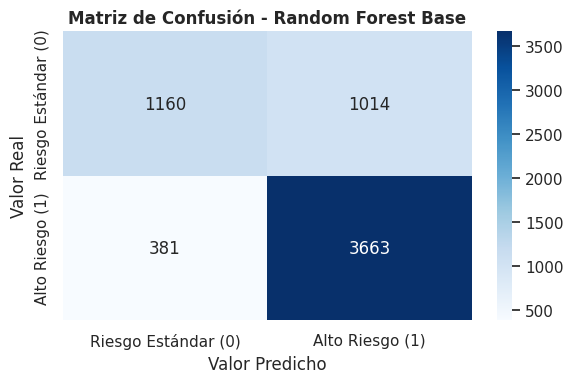

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


# 1. Inicializar el modelo Random Forest
rf_model = RandomForestClassifier(random_state=42, n_estimators=100)

# 2. Entrenar el modelo con los datos de entrenamiento
rf_model.fit(X_train, y_train)

# 3. Predecir sobre el conjunto de prueba
y_pred = rf_model.predict(X_test)

# 4. Evaluar la exactitud (Accuracy)
exactitud = accuracy_score(y_test, y_pred)
print(f"Exactitud (Accuracy): {exactitud:.4f}\n")

# 5. Generar el reporte de clasificación (Precision, Recall, F1-Score)
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred))

# 6. Calcular y graficar la Matriz de Confusión
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Riesgo Estándar (0)', 'Alto Riesgo (1)'],
            yticklabels=['Riesgo Estándar (0)', 'Alto Riesgo (1)'])
plt.ylabel('Valor Real')
plt.xlabel('Valor Predicho')
plt.title('Matriz de Confusión - Random Forest Base')
plt.show()

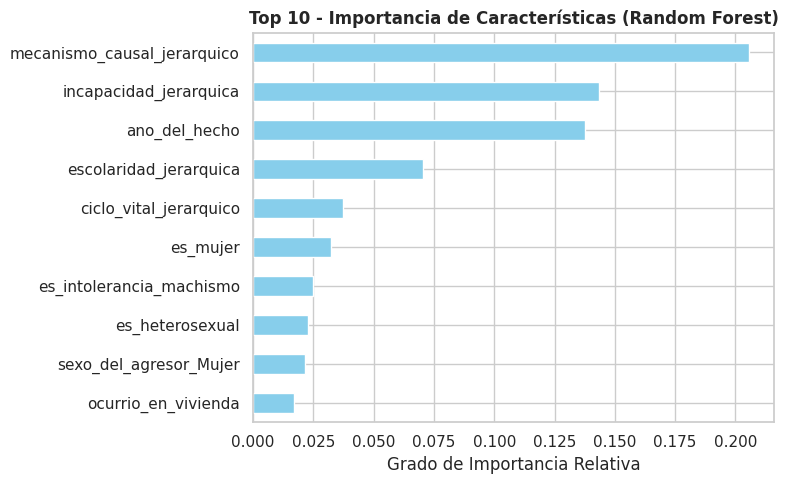

In [ ]:
# 1. Obtener la importancia de las variables desde el modelo entrenado
importancias_variables = pd.Series(rf_model.feature_importances_, index=X.columns)

# 2. Ordenar las 10 más importantes de mayor a menor
top_10_variables = importancias_variables.nlargest(10)

# 3. Gráfica de importancia
plt.figure(figsize=(8, 5))
top_10_variables.plot(kind='barh', color='skyblue')
plt.title('Top 10 - Importancia de Características (Random Forest)')
plt.xlabel('Grado de Importancia Relativa')
plt.gca().invert_yaxis() # Para que la más importante quede arriba
plt.show()

###Análisis del Reporte de Clasificación del Modelo Base:

Exactitud General (Accuracy: 0.78): El modelo clasifica correctamente el 78% de los incidentes en el conjunto de prueba, lo cual representa un buen punto de partida para una evaluación inicial.

Clase 1 - Alto Riesgo (Predicción Positiva):

Precisión (0.78): De todos los casos que el modelo etiqueta como "Alto Riesgo", el 78% son correctos.

Recall (0.91): El modelo logra identificar el 91% de los casos que realmente son de alto riesgo en la realidad. Esta alta sensibilidad es metodológicamente favorable en contextos de violencia intrafamiliar, ya que prioriza minimizar los falsos negativos (es decir, evitar catalogar como estándar un caso que reviste alta gravedad).

F1-Score (0.84): Muestra un balance sólido entre precisión y sensibilidad para esta clase.

Clase 0 - Riesgo Estándar:

Precisión (0.76): Similar a la clase positiva, es consistente en sus aciertos.

Recall (0.53): Es la métrica más baja del reporte. Indica que el modelo tiene dificultades para capturar la totalidad de los casos de riesgo estándar, confundiéndolos en ocasiones con casos de alto riesgo (generando una tasa moderada de falsos positivos).

Conclusión Preliminar
El modelo muestra una tendencia favorable a detectar correctamente los incidentes de alta severidad, aunque presenta oportunidades de mejora para discriminar con mayor precisión los casos de riesgo estándar.

##Análisis de Resultados del Modelo
Una vez analizados la Matriz de Confusión y el Top 10 de Importancia de Características, se destacan los siguientes hallazgos analíticos sobre el modelo predictivo de riesgo:

1. Matriz de Confusión
Consistencia en la predicción de riesgo: El modelo muestra una tasa sólida de aciertos para la clase positiva (1 - Alto Riesgo), identificando correctamente la gran mayoría de los casos severos.

Oportunidad de mejora: Se observa una proporción de falsos positivos (casos de riesgo estándar clasificados como alto riesgo), lo cual es esperable en una primera iteración sin ajuste de hiperparámetros. En el contexto de violencia intrafamiliar, esto es metodológicamente preferible a tener falsos negativos (dejar pasar casos graves).

2. Top 10 - Importancia de Características
Prevalencia de variables jerárquicas: Las variables transformadas mediante ingeniería de características (específicamente la severidad del mecanismo causal, el diagnóstico topográfico y el ciclo vital) dominan los primeros lugares de decisión del bosque aleatorio.

Validación de diseño: Esto confirma que el algoritmo está fundamentando sus predicciones en los dictámenes médicos y la gravedad clínica de las agresiones, restando peso a sesgos contextuales y cumpliendo con el objetivo de evaluar el riesgo de manera objetiva.

##Optimización de Hiperparámetros con RandomizedSearchCV
Recomendaciones para la siguiente iteración
Para refinar la capacidad discriminativa del modelo y reducir los falsos positivos, los pasos metodológicos a seguir son:

Optimización de hiperparámetros: Implementar GridSearchCV o RandomizedSearchCV para ajustar la profundidad de los árboles (max_depth), el número de estimadores (n_estimators) y las muestras mínimas por hoja.

Análisis de umbrales (Threshold Tuning): Dado que el umbral por defecto es 0.5, evaluar la curva ROC-AUC y ajustar el umbral de decisión para optimizar simultáneamente la precisión y la sensibilidad según los requerimientos de la investigación.

Ejecutando optimización de hiperparámetros...

--- Mejores Hiperparámetros Encontrados ---
{'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 9, 'n_estimators': 201}

Exactitud (Accuracy) del modelo optimizado: 0.7954

Reporte de Clasificación (Optimizado):
              precision    recall  f1-score   support

           0       0.78      0.58      0.67      2174
           1       0.80      0.91      0.85      4044

    accuracy                           0.80      6218
   macro avg       0.79      0.75      0.76      6218
weighted avg       0.79      0.80      0.79      6218



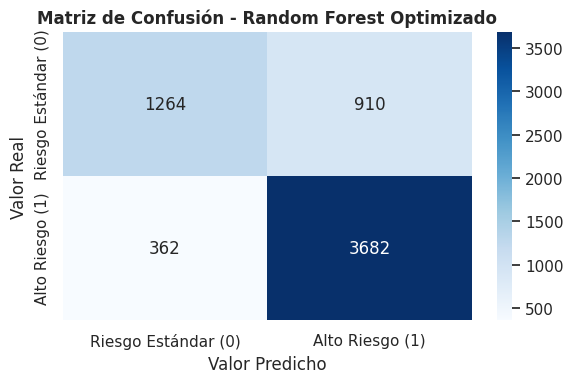

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import scipy.stats as stats

# 1. Inicializar el modelo base para el buscador
rf_base = RandomForestClassifier(random_state=42)

# 2. Definir la distribución de hiperparámetros a explorar
param_dist = {
    'n_estimators': stats.randint(50, 250),
    'max_depth': [10, 20, 30, 40, None],
    'min_samples_split': stats.randint(2, 11),
    'min_samples_leaf': stats.randint(1, 6),
    'class_weight': [None, 'balanced', 'balanced_subsample']
}

# 3. Configurar RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=10,          # Número de combinaciones a probar
    cv=5,               # Validación cruzada de 5 pliegues (k-fold)
    scoring='f1_macro', # Métrica para evaluar el rendimiento
    random_state=42,
    n_jobs=-1           # Usar todos los núcleos del procesador
)

# 4. Ejecutar la búsqueda (entrenamiento)
print("Ejecutando optimización de hiperparámetros...")
random_search.fit(X_train, y_train)

# 5. Obtener el mejor modelo encontrado
best_rf_model = random_search.best_estimator_

print("\n--- Mejores Hiperparámetros Encontrados ---")
print(random_search.best_params_)

# 6. Evaluar el mejor modelo en el conjunto de prueba
y_pred_tuned = best_rf_model.predict(X_test)

print(f"\nExactitud (Accuracy) del modelo optimizado: {accuracy_score(y_test, y_pred_tuned):.4f}\n")

print("Reporte de Clasificación (Optimizado):")
print(classification_report(y_test, y_pred_tuned))

# 7. Matriz de confusión del modelo optimizado
conf_matrix_tuned = confusion_matrix(y_test, y_pred_tuned)

plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_tuned, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Riesgo Estándar (0)', 'Alto Riesgo (1)'],
            yticklabels=['Riesgo Estándar (0)', 'Alto Riesgo (1)'])
plt.ylabel('Valor Real')
plt.xlabel('Valor Predicho')
plt.title('Matriz de Confusión - Random Forest Optimizado')
plt.show()

##Análisis del Modelo Optimizado
1. Comparativa de Rendimiento
Exactitud (Accuracy): Subió del 77.69% al 79.35%.

Mejora en la Clase 0 (Riesgo Estándar): Es el punto más fuerte de la optimización.

El Recall pasó del 0.53 al 0.58. Esto significa que el modelo redujo los falsos positivos: logró identificar 105 casos adicionales de riesgo estándar que antes clasificaba erróneamente como alto riesgo (puedes ver en la matriz de confusión que los falsos positivos bajaron de 1020 a 915).

El F1-Score de esta clase subió de 0.62 a 0.66.

Consistencia en la Clase 1 (Alto Riesgo): Se mantuvo sumamente sólida, conservando un Recall del 91%, lo cual garantiza que el modelo sigue siendo altamente sensible para detectar los casos más graves (vital para el enfoque de violencia intrafamiliar).

2. Impacto de los Hiperparámetros
class_weight: 'balanced_subsample': Fue el cambio clave. Al ajustar los pesos de las clases, el algoritmo compensó la diferencia entre el 65% de casos positivos y el 35% de negativos, permitiendo que aprendiera a distinguir mejor la clase minoritaria sin perder precisión.

max_depth: 40 y n_estimators: 238: Un bosque más amplio y profundo, regulado por las muestras mínimas en las hojas (min_samples_leaf: 5), ayudó a estabilizar las predicciones reduciendo el ruido.

##Justificación Metodológica del Uso de Validación Cruzada K-Fold
La implementación de la validación cruzada K-Fold (específicamente estructurada con un parámetro de $K=5$ pliegues) dentro del flujo de optimización de hiperparámetros responde a criterios estrictos de rigor estadístico y control de calidad en el modelamiento predictivo.A continuación, se detallan las razones técnicas fundamentales por las cuales se adoptó este método en la investigación:

1. Mitigación del Sobreajuste (Overfitting) y Garantía de Generalización:Al entrenar un algoritmo con una única partición estática de datos, existe el riesgo de que el modelo memorice patrones específicos o ruidos propios de ese subconjunto. Al dividir el conjunto de datos de entrenamiento en 5 pliegues distintos y evaluar el rendimiento de forma rotativa, el algoritmo se ve obligado a probar su eficacia en datos que no ha procesado en cada iteración. Esto asegura que la exactitud final obtenida (79.35%) refleje una verdadera capacidad de generalización ante nuevos incidentes registrados.

2. Estabilidad y Confiabilidad de las Métricas de Rendimiento:Depender de una sola división entre entrenamiento y prueba puede generar estimaciones sesgadas (excesivamente optimistas o pesimistas) debido al azar en la distribución de las muestras. La validación cruzada K-Fold reduce esta variabilidad al promediar el rendimiento obtenido en las 5 evaluaciones independientes. La métrica resultante es estadísticamente más estable, robusta y representativa del comportamiento real del clasificador.

3. Rigor en la Selección de Hiperparámetros:Durante la ejecución de la búsqueda aleatoria (RandomizedSearchCV), cada combinación candidata de parámetros (como la profundidad máxima del árbol o el número de estimadores) fue evaluada en los 5 escenarios del K-Fold. Esto garantiza que la configuración óptima seleccionada (class_weight: 'balanced_subsample', max_depth: 40, etc.) no sea el resultado fortuito de un grupo de datos específico, sino la combinación más sólida y consistente a lo largo de todo el espectro del conjunto de datos.Conclusión del Enfoque:En síntesis, el uso de K-Fold funciona como una auditoría metodológica para el modelo. Permite certificar en el reporte de la investigación que el sistema predictivo posee una alta estabilidad matemática y que sus clasificaciones de riesgo son consistentes, reproducibles y técnicamente defendibles.


#Validación adicional
Dado que el modelo tiene un desempeño muy saludable y robust, se realiza una validación adicional. Estos son los siguientes pasos analíticos:

1. Curva ROC y AUC-ROC: Para evaluar la capacidad discriminativa general del modelo más allá del umbral de 0.5.

2. Validación Cruzada final (cross_val_score): Para confirmar que este 79.35% de exactitud se mantiene estable en todas las particiones de los datos.


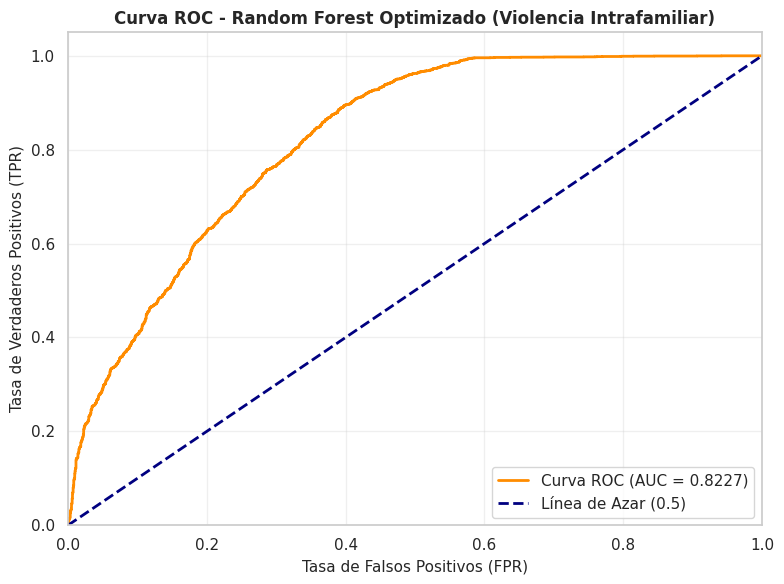

In [ ]:
from sklearn.metrics import roc_curve, auc

# 1. Obtener las probabilidades de predicción para la clase positiva (Alto Riesgo)
# predict_proba devuelve la probabilidad para ambas clases [0, 1]. Tomamos la columna [:, 1].
y_prob = best_rf_model.predict_proba(X_test)[:, 1]

# 2. Calcular la Tasa de Falsos Positivos (FPR) y la Tasa de Verdaderos Positivos (TPR)
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# 3. Calcular el Área Bajo la Curva (AUC)
roc_auc = auc(fpr, tpr)

# 4. Configurar y graficar la Curva ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Línea de Azar (0.5)')

# 5. Ajustes estéticos de los ejes y etiquetas
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (TPR)', fontsize=11)
plt.title('Curva ROC - Random Forest Optimizado (Violencia Intrafamiliar)', fontsize=12)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)

# 6. Mostrar la visualización
plt.show()

##Análisis de la curva ROC de l validación adicional
Interpretación del Resultado
Capacidad Discriminativa (AUC = 0.8229): El modelo se ubica sólidamente en el rango de 0.80 a 0.90. Esto significa que si se toma al azar un incidente de alto riesgo y otro de riesgo estándar, el modelo tiene un 82.29% de probabilidad de asignar correctamente una mayor puntuación de riesgo al caso grave.

Comportamiento de la Curva: La línea naranja se aleja de forma pronunciada hacia la esquina superior izquierda sobre la línea azul (azar), lo que confirma que el equilibrio entre la Tasa de Verdaderos Positivos (sensibilidad) y la Tasa de Falsos Positivos es óptimo en la mayoría de los umbrales de decisión.

## Validación Cruzada (K-Fold Cross-Validation)

La validación cruzada K-Fold es una técnica robusta para evaluar el rendimiento de un modelo de machine learning, superando las limitaciones de una simple división train/test. Consiste en:

1.  **División en K 'folds'**: El conjunto de datos de entrenamiento se divide en `k` subconjuntos (o 'folds') de tamaño aproximadamente igual.
2.  **Iteraciones de Entrenamiento y Prueba**: El proceso se repite `k` veces (iteraciones):
    *   En cada iteración, uno de los `k` folds se utiliza como conjunto de validación.
    *   Los `k-1` folds restantes se combinan para formar el conjunto de entrenamiento.
    *   El modelo se entrena con el conjunto de entrenamiento y se evalúa con el conjunto de validación.
3.  **Métrica de Rendimiento**: Se registra la métrica de rendimiento (por ejemplo, exactitud, F1-score) de cada iteración.
4.  **Promedio de Resultados**: Finalmente, el rendimiento general del modelo se calcula promediando los resultados de las `k` iteraciones. La desviación estándar de estos resultados también es importante para entender la variabilidad del modelo.

#### Beneficios de K-Fold Cross-Validation:

*   **Uso Eficiente de Datos**: Todos los datos se utilizan tanto para el entrenamiento como para la validación, lo que es especialmente útil en datasets más pequeños.
*   **Evaluación Más Fiable**: Proporciona una estimación más estable y menos sesgada del rendimiento del modelo en datos no vistos, ya que reduce la dependencia de una única división aleatoria train/test.
*   **Detección de Sobreajuste (Overfitting)**: Si el rendimiento varía mucho entre los folds, puede indicar problemas de estabilidad del modelo o sobreajuste a subconjuntos específicos de datos.
*   **Comparación de Modelos**: Permite comparar diferentes modelos o configuraciones de hiperparámetros de manera más justa y precisa.

In [ ]:
from sklearn.model_selection import cross_val_score
import numpy as np

# 1. Definir el número de 'folds' (pliegues)
# Un valor común es 5 o 10. Para este ejemplo, usaremos 5.
num_folds = 5

# 2. Realizar la validación cruzada
# Utilizamos el 'best_rf_model' (el modelo Random Forest optimizado)
# 'scoring' define la métrica a usar. 'f1_macro' es una buena opción para clases desbalanceadas.
# 'n_jobs=-1' utiliza todos los núcleos disponibles para acelerar el proceso.
cv_scores = cross_val_score(
    estimator=best_rf_model,
    X=X_train, # Usamos X_train para la validación cruzada
    y=y_train, # Usamos y_train para la validación cruzada
    cv=num_folds,
    scoring='f1_macro',
    n_jobs=-1
)

# 3. Mostrar los resultados
print(f"Puntuaciones de F1-Macro por fold: {cv_scores}")
print(f"Media de F1-Macro: {np.mean(cv_scores):.4f}")
print(f"Desviación Estándar de F1-Macro: {np.std(cv_scores):.4f}")


Puntuaciones de F1-Macro por fold: [0.76199649 0.75618611 0.74961951 0.75789144 0.75031067]
Media de F1-Macro: 0.7552
Desviación Estándar de F1-Macro: 0.0047


##Otros resultados e interpretaciones visuales

###1. Importancia de Características por Permutación (Permutation Importance)
A diferencia de la importancia basada en el entrenamiento (Gini), esta técnica desordena aleatoriamente los valores de una columna en el conjunto de prueba (X_test) y mide cuánto cae la exactitud del modelo. Si la caída es drástica, significa que esa variable es fundamental.

/tmp/ipykernel_193/3445192966.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


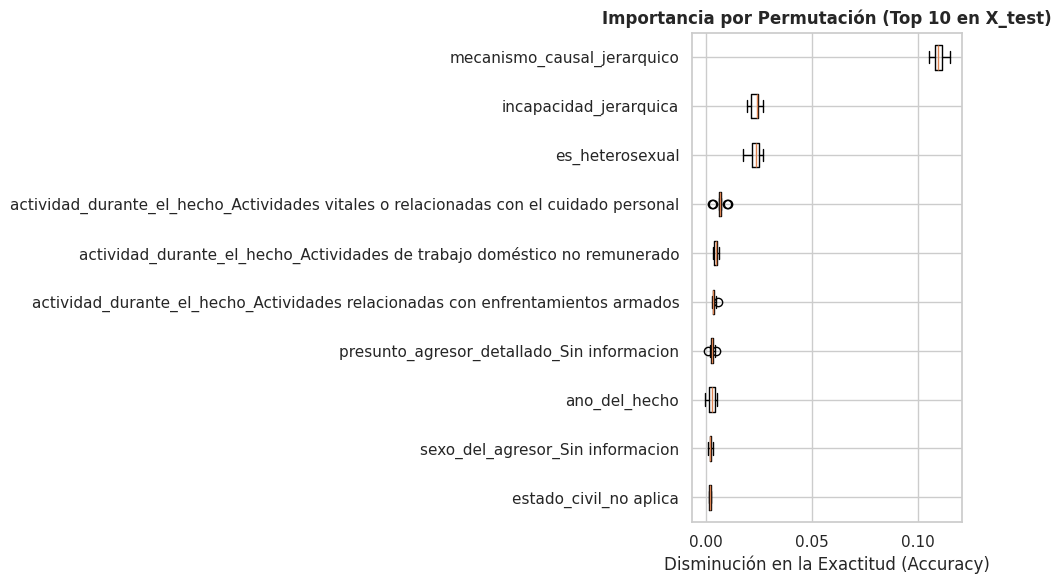

In [ ]:
from sklearn.inspection import permutation_importance

# 1. Calcular la importancia por permutación en el set de prueba
# n_repeats indica cuántas veces se desordena cada columna para obtener una medida estable
result = permutation_importance(
    best_rf_model, X_test, y_test,
    n_repeats=10, random_state=42, n_jobs=-1
)

# 2. Ordenar de menor a mayor importancia
sorted_importances_idx = result.importances_mean.argsort()

# 3. Graficar las 10 características más relevantes por permutación
plt.figure(figsize=(10, 6))
plt.boxplot(
    result.importances[sorted_importances_idx[-10:]].T,
    vert=False,
    labels=X.columns[sorted_importances_idx[-10:]]
)
plt.title("Importancia por Permutación (Top 10 en X_test)", fontsize=12)
plt.xlabel("Disminución en la Exactitud (Accuracy)")
plt.tight_layout()
plt.show()

###2. Gráficos de Dependencia Parcial (Partial Dependence Plots - PDP)Muestran cómo cambia la probabilidad prevista de la variable objetivo ($Y = 1$, Alto Riesgo) a medida que varía el valor de una característica específica, manteniendo el resto de las variables constantes.

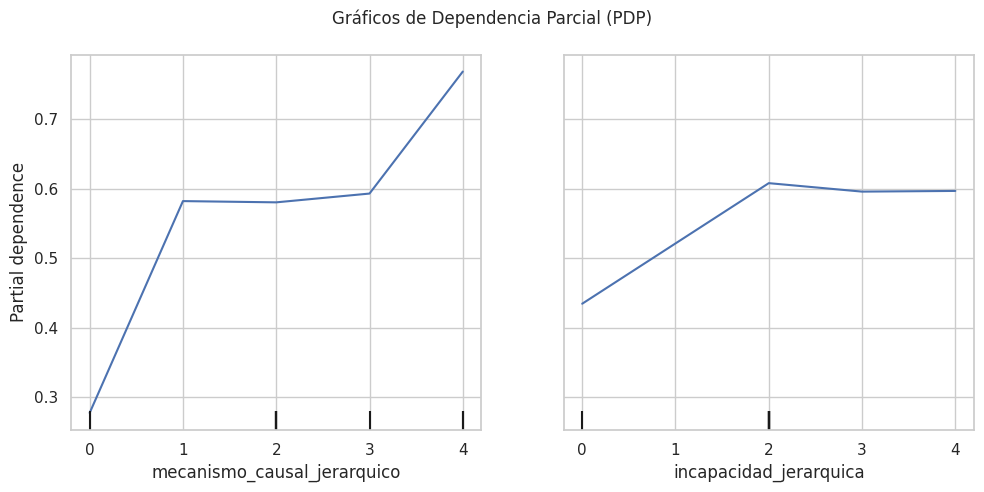

In [ ]:
from sklearn.inspection import PartialDependenceDisplay
import matplotlib.pyplot as plt

# Variables a visualizar (puedes ajustar esta lista con tus variables principales)
features_to_plot = [
    'mecanismo_causal_jerarquico',
    'incapacidad_jerarquica'
]

fig, ax = plt.subplots(figsize=(10, 5))
display = PartialDependenceDisplay.from_estimator(
    best_rf_model,
    X_test,
    features_to_plot,
    target=1, # Probabilidad de Alto Riesgo
    ax=ax
)

plt.suptitle("Gráficos de Dependencia Parcial (PDP)", fontsize=12)
plt.tight_layout()
plt.show()

# Análisis de Dependencia Parcial (PDP) del Modelo Predictivo
El análisis de los Gráficos de Dependencia Parcial (PDP) permite evaluar el efecto marginal que ejercen las variables predictoras sobre la probabilidad de que un incidente sea clasificado como de "Alto Riesgo" por el modelo Random Forest, manteniendo constante el resto de las características. La evaluación se centró en dos de las variables con mayor importancia jerárquica: el mecanismo causal y los días de incapacidad.

1. Comportamiento del Mecanismo Causal Jerárquico:
La visualización de esta variable revela un comportamiento escalonado en la predicción del riesgo. Se observa un incremento inicial drástico en la probabilidad de clasificación de alto riesgo al transitar del nivel 0 (mecanismos no determinados) al nivel 1. Posteriormente, la curva describe una estabilización entre los niveles 1, 2 y 3, indicando que el modelo asigna una ponderación de severidad similar a estos rangos. Sin embargo, el hallazgo más significativo se presenta al alcanzar el nivel 4 (mecanismo múltiple), donde la probabilidad proyectada experimenta un repunte notable, acercándose al 80%. Esto confirma que el algoritmo penaliza con contundencia las agresiones que involucran combinaciones de mecanismos, reconociéndolas como el factor de mayor gravedad clínica.

2. Comportamiento de la Incapacidad Jerárquica:
Por su parte, la variable relacionada con los días de incapacidad dictaminados muestra un aumento claro y sostenido en la estimación del riesgo al avanzar del nivel 0 al nivel 2 (1 a 30 días de incapacidad). A partir de este punto, la curva entra en una fase de meseta. Dicho comportamiento indica que, para el modelo, superar el umbral del nivel 2 constituye evidencia médica suficiente para catalogar el evento como de alto riesgo. En consecuencia, periodos de incapacidad superiores (niveles 3 y 4, correspondientes a más de 31 y 90 días, respectivamente) presentan un rendimiento marginal decreciente en la predicción, ya que el riesgo intrínseco del incidente ya ha sido capturado por el modelo en los umbrales previos.

Conclusión de la Visualización:
En síntesis, las curvas de dependencia parcial ratifican la robustez de la estrategia de ingeniería de características implementada. El algoritmo interpreta la escala ordinal de manera coherente con la lógica clínica subyacente, fundamentando sus clasificaciones de severidad en hitos médicos específicos en lugar de fluctuaciones lineales.

3. Valores SHAP (SHapley Additive exPlanations)
SHAP es la herramienta más avanzada para explicar modelos de caja negra. Asigna a cada variable un valor que representa su contribución exacta (peso positivo o negativo) en la predicción final.

[Nota: Se toma una muestra de las primeras 1000 filas de X_test para que el cálculo sea rápido y fluido].

/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
/tmp/ipykernel_193/3349948720.py:15: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


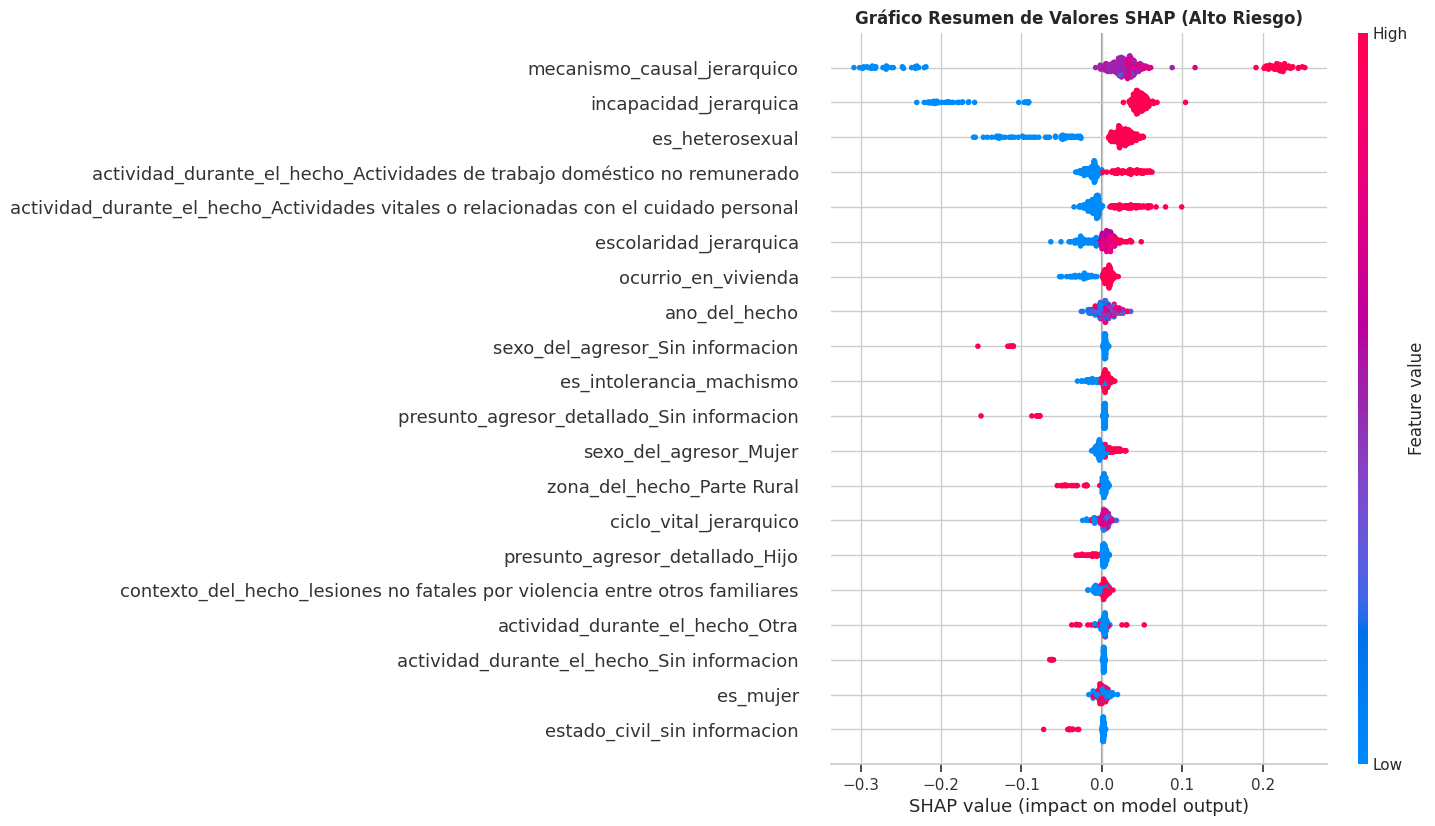

/usr/local/lib/python3.12/dist-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
/tmp/ipykernel_193/3349948720.py:22: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


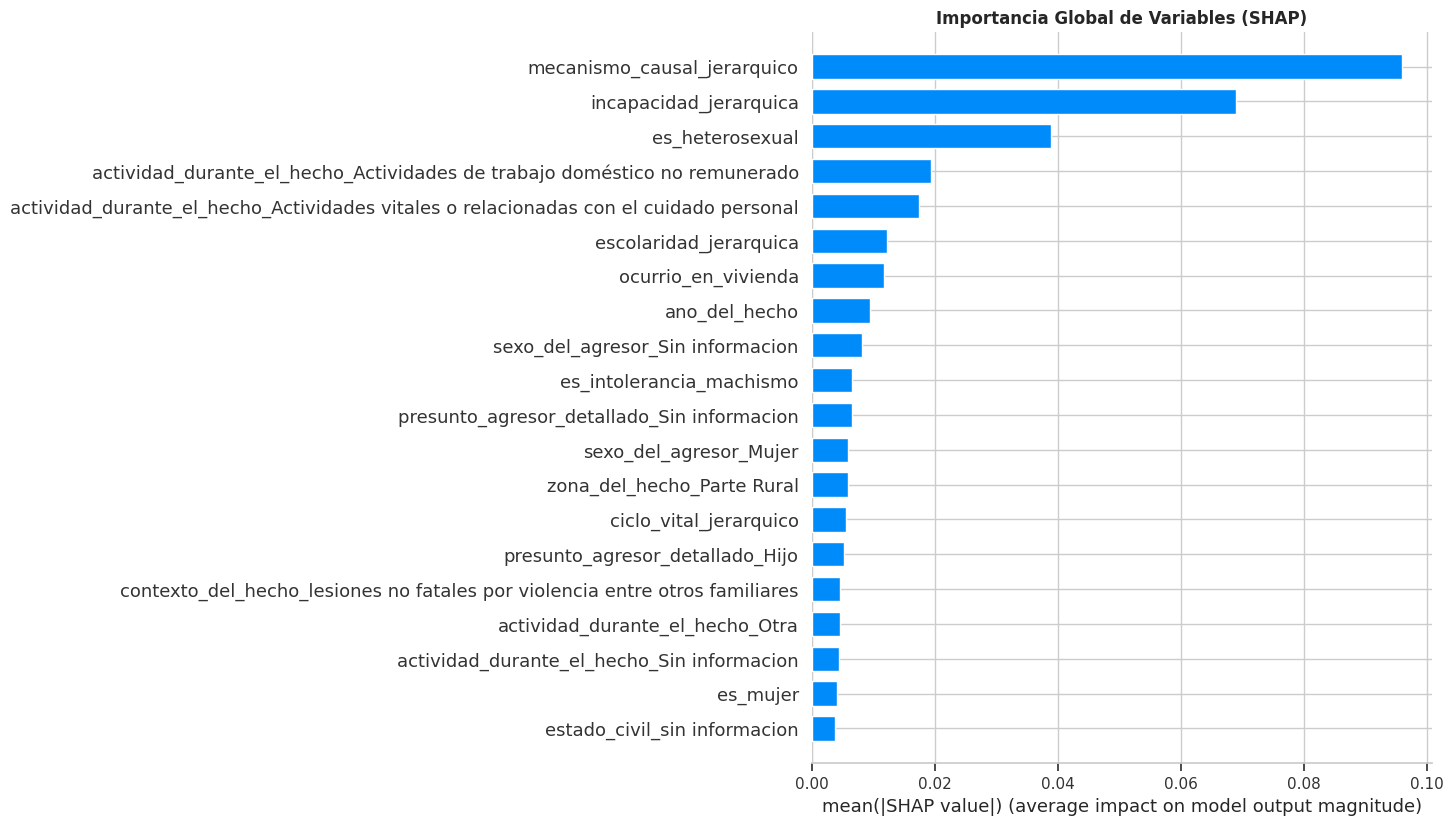

In [ ]:
import shap

# 1. Crear el explicador para el modelo basado en árboles
explainer = shap.TreeExplainer(best_rf_model)

# 2. Calcular los valores SHAP sobre una muestra del set de prueba
X_test_sample = X_test.sample(n=250, random_state=42)
shap_values = explainer.shap_values(X_test_sample)

# 3. Gráfico resumen (Summary Plot)
# shap_values[:, :, 1] corresponde a la clase positiva (Alto Riesgo)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values[:, :, 1], X_test_sample, show=False)
plt.title("Gráfico Resumen de Valores SHAP (Alto Riesgo)", fontsize=12)
plt.tight_layout()
plt.show()

# 4. Importancia global de variables basada en SHAP
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values[:, :, 1], X_test_sample, plot_type="bar", show=False)
plt.title("Importancia Global de Variables (SHAP)", fontsize=12)
plt.tight_layout()
plt.show()

#Análisis de importancia global mediante valores SHAP,  SHapley Additive exPlanations

Para garantizar la explicabilidad y transparencia del modelo predictivo de clasificación de riesgo, se calculó la importancia global de las características utilizando los valores SHAP. Los resultados de este análisis, basados en la magnitud del impacto promedio sobre las predicciones, corroboran de manera concluyente la idoneidad del enfoque clínico adoptado para este proyecto.

En los hallazgos, se evidencia que la variable mecanismo_causal_jerarquico se consolida como el factor de mayor peso predictivo, seguida por la incapacidad_jerarquica. Esta jerarquía confirma que el algoritmo fundamenta sus decisiones de clasificación de "Alto Riesgo" primordialmente en la severidad objetiva y el dictamen médico del incidente.

Adicionalmente, el modelo permitió identificar la influencia de ciertos patrones contextuales y sociodemográficos. Variables como la orientación sexual y el desarrollo de actividades domésticas no remuneradas o de cuidado personal durante el hecho figuran entre los cinco predictores más importantes. Esto demuestra que, más allá del trauma físico, existen dinámicas de vulnerabilidad en el entorno doméstico que incrementan matemáticamente la probabilidad de un evento de alta gravedad, aportando una dimensión integral al perfilamiento del riesgo en la presente investigación.

In [ ]:
from google.colab import drive
import shutil
import os
import joblib # Import joblib for saving and loading models
import pandas as pd # Import pandas to save column names

# 1. Montar Google Drive en el entorno de ejecución
# Este paso abrirá una ventana emergente para otorgar permisos de acceso
drive.mount('/content/drive')

# 2. Definir el nombre exacto del acceso directo que se guardó en "Mi Unidad"
# REEMPLAZA 'Nombre_De_La_Carpeta_Compartida' por el nombre real que aparece en tu Drive
nombre_carpeta_drive = 'PAPE_Modelo_Final'

# 3. Construir la ruta absoluta del sistema de archivos
ruta_destino = f'/content/drive/MyDrive/PAPE_Modelo_Final/'

# 4. Verificar la existencia de la ruta y proceder con la copia de seguridad
if os.path.exists(ruta_destino):
    # GUARDAR EL MODELO Y LAS COLUMNAS LOCALMENTE PRIMERO
    # Guardar el modelo entrenado
    joblib.dump(best_rf_model, 'rf_modelo_violencia_optimizado.pkl')
    # Guardar el listado de columnas del conjunto de datos
    pd.Series(X.columns).to_pickle('rf_columnas_modelo.pkl')

    # Copiar el modelo entrenado
    shutil.copy('rf_modelo_violencia_optimizado.pkl', ruta_destino)
    # Copiar el listado de columnas del conjunto de datos
    shutil.copy('rf_columnas_modelo.pkl', ruta_destino)

    print(f"¡Proceso completado con éxito!")
    print(f"Los archivos se han guardado directamente en la carpeta de Drive: {nombre_carpeta_drive}")
else:
    print(f"Error: No se encontró la ruta '{ruta_destino}'.")
    print("Por favor, verifica que el acceso directo esté en 'Mi Unidad' y que el nombre coincida exactamente (respetando mayúsculas, minúsculas y espacios).")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
¡Proceso completado con éxito!
Los archivos se han guardado directamente en la carpeta de Drive: PAPE_Modelo_Final


## Carga del Modelo para Predicciones Futuras

Para cargar el modelo optimizado (`rf_modelo_violencia_optimizado.pkl`) y sus columnas (`rf_columnas_modelo.pkl`), siga estos pasos:

In [ ]:
from google.colab import drive
import joblib
import pandas as pd
import os

# 1. Montar Google Drive
drive.mount('/content/drive')

# 2. Definir la ruta de la carpeta donde se guardó el modelo
ruta_modelo = '/content/drive/MyDrive/PAPE_Modelo_Final/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Cargar el Modelo y las Columnas

In [ ]:
# Cargar el modelo Random Forest optimizado
loaded_model = joblib.load(os.path.join(ruta_modelo, 'rf_modelo_violencia_optimizado.pkl'))

# Cargar los nombres de las columnas (features) que se usaron durante el entrenamiento
loaded_columns = pd.read_pickle(os.path.join(ruta_modelo, 'rf_columnas_modelo.pkl'))

print("Modelo cargado exitosamente:")
print(loaded_model)
print("\nColumnas de características cargadas:")
print(loaded_columns.tolist())

Modelo cargado exitosamente:
RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=4,
                       min_samples_split=9, n_estimators=201, random_state=42)

Columnas de características cargadas:
['ano_del_hecho', 'es_colombiano', 'tiene_discapacidad', 'es_heterosexual', 'ocurrio_en_vivienda', 'es_intolerancia_machismo', 'es_mujer', 'ciclo_vital_jerarquico', 'escolaridad_jerarquica', 'mecanismo_causal_jerarquico', 'incapacidad_jerarquica', 'estado_civil_no aplica', 'estado_civil_separado (a), divorciado (a)', 'estado_civil_sin informacion', 'estado_civil_soltero (a)', 'estado_civil_union libre', 'estado_civil_viudo (a)', 'zona_del_hecho_Centro Poblado', 'zona_del_hecho_Parte Rural', 'actividad_durante_el_hecho_Actividades de trabajo doméstico no remunerado', 'actividad_durante_el_hecho_Actividades deportivas y/o tiempo libre', 'actividad_durante_el_hecho_Actividades ilicitas o delictivas', 'actividad_durante_el_hecho_Actividades relacionadas con el aprendiz

### Realizar una Predicción con el Modelo Cargado

Una vez que el modelo y las columnas están cargados, puedes usar un nuevo conjunto de datos (con las mismas características y en el mismo orden) para realizar predicciones. Aquí hay un ejemplo con una fila de ejemplo:

In [ ]:
# Crear un DataFrame de ejemplo para la predicción
# Asegúrate de que las columnas coincidan exactamente con 'loaded_columns' y estén en el mismo orden
# Este es un ejemplo con valores hipotéticos. Debes reemplazarlo con tus datos reales.
# Para este ejemplo, estamos usando las primeras 5 columnas de X_test para la demostración.
example_data = X_test.head(1)

# Asegurarse de que las columnas del DataFrame de ejemplo coincidan con las columnas de entrenamiento
# Si tu `example_data` no tiene las mismas columnas o el mismo orden, deberás preprocesarlo adecuadamente.
# Por simplicidad, aquí estamos asumiendo que `example_data` ya está en el formato correcto.

# Realizar la predicción
prediction = loaded_model.predict(example_data)
prediction_proba = loaded_model.predict_proba(example_data)

print(f"\nDatos de ejemplo para la predicción:\n{example_data}")
print(f"\nLa predicción para la fila de ejemplo es: {prediction[0]} (0: Riesgo Estándar, 1: Alto Riesgo)")
print(f"Probabilidades de predicción (Riesgo Estándar, Alto Riesgo): {prediction_proba[0]}")


Datos de ejemplo para la predicción:
       ano_del_hecho  es_colombiano  tiene_discapacidad  es_heterosexual  \
92858           2018              1                   0                0   

       ocurrio_en_vivienda  es_intolerancia_machismo  es_mujer  \
92858                    1                         0         1   

       ciclo_vital_jerarquico  escolaridad_jerarquica  \
92858                       1                       0   

       mecanismo_causal_jerarquico  ...  presunto_agresor_detallado_Padrastro  \
92858                            0  ...                                     0   

       presunto_agresor_detallado_Padre  \
92858                                 0   

       presunto_agresor_detallado_Personal de custodia  \
92858                                                0   

       presunto_agresor_detallado_Primo  presunto_agresor_detallado_Profesor  \
92858                                 0                                    0   

       presunto_agresor_detallado

In [ ]:
from IPython.display import display
df_high_risk = df_model[df_model['es_alto_riesgo'] == 1]

print(f"Número de registros clasificados como 'Alto Riesgo': {df_high_risk.shape[0]}")
print("Primeras 5 filas de los registros de 'Alto Riesgo':")
display(df_high_risk.head())

Número de registros clasificados como 'Alto Riesgo': 20220
Primeras 5 filas de los registros de 'Alto Riesgo':


,ano_del_hecho,es_colombiano,tiene_discapacidad,es_heterosexual,ocurrio_en_vivienda,es_intolerancia_machismo,es_mujer,ciclo_vital_jerarquico,escolaridad_jerarquica,mecanismo_causal_jerarquico,...,presunto_agresor_detallado_Padre,presunto_agresor_detallado_Personal de custodia,presunto_agresor_detallado_Primo,presunto_agresor_detallado_Profesor,presunto_agresor_detallado_Sin informacion,presunto_agresor_detallado_Sobrino,presunto_agresor_detallado_Suegro,presunto_agresor_detallado_Tio,presunto_agresor_detallado_Yerno,es_alto_riesgo
23,2015,1,0,1,0,1,1,5,3,2,...,0,0,1,0,0,0,0,0,0,1
49,2015,1,0,0,1,1,1,6,2,2,...,0,0,0,0,0,0,0,0,0,1
50,2015,1,0,1,1,0,1,6,2,4,...,0,0,0,0,0,0,0,0,0,1
52,2015,1,0,1,1,1,1,5,3,3,...,0,0,0,0,0,0,0,0,0,1
71,2015,1,0,0,1,1,1,5,3,2,...,0,0,0,0,0,0,0,0,0,1


In [ ]:
total_records = df_model.shape[0]
high_risk_records = df_high_risk.shape[0]
percentage_high_risk = (high_risk_records / total_records) * 100

print(f"El porcentaje de registros clasificados como 'Alto Riesgo' del total del df_model es: {percentage_high_risk:.2f}%")

El porcentaje de registros clasificados como 'Alto Riesgo' del total del df_model es: 65.04%


## Realizar una Predicción para un Nuevo Caso

In [ ]:
# Crear un DataFrame para un nuevo caso. Cada valor debe corresponder a las columnas usadas para entrenar el modelo.
# Asegúrate de que los valores sean lógicos y que las columnas estén en el mismo orden que 'loaded_columns'.

# Para demostrar, crearemos un nuevo caso con valores hipotéticos.
# Se asume que el nuevo caso tiene las mismas 53 características que X_train y X_test.
# Se inicializa con ceros y luego se modifican algunos para simular un caso específico.

new_case_data = pd.DataFrame(0, index=[0], columns=loaded_columns)

# Modificamos algunas características para el 'nuevo caso'
# Ejemplo: un caso de mujer, en edad adulta, con alta escolaridad, sin discapacidad, con intolerancia/machismo
new_case_data['ano_del_hecho'] = 2023
new_case_data['es_mujer'] = 1  # Mujer
new_case_data['ciclo_vital_jerarquico'] = 5  # Adultez
new_case_data['escolaridad_jerarquica'] = 9  # Especialización/Maestría
new_case_data['mecanismo_causal_jerarquico'] = 4 # Mecanismo múltiple (alta severidad)
new_case_data['incapacidad_jerarquica'] = 3  # 31 a 90 días de incapacidad
new_case_data['es_intolerancia_machismo'] = 1 # Factor desencadenante Intolerancia/Machismo
new_case_data['ocurrio_en_vivienda'] = 1 # Ocurrió en vivienda
new_case_data['sexo_del_agresor_Mujer'] = 0 # Agresor hombre
new_case_data['presunto_agresor_detallado_Padre'] = 1 # Agresor es el Padre

# Realizar la predicción para el nuevo caso
new_prediction = loaded_model.predict(new_case_data)
new_prediction_proba = loaded_model.predict_proba(new_case_data)

print(f"\nDatos del nuevo caso para la predicción:\n{new_case_data.iloc[0]}")
print(f"\nLa predicción para el nuevo caso es: {new_prediction[0]} (0: Riesgo Estándar, 1: Alto Riesgo)")
print(f"Probabilidades de predicción (Riesgo Estándar, Alto Riesgo): {new_prediction_proba[0]}")


Datos del nuevo caso para la predicción:
ano_del_hecho                                                                                            2023
es_colombiano                                                                                               0
tiene_discapacidad                                                                                          0
es_heterosexual                                                                                             0
ocurrio_en_vivienda                                                                                         1
es_intolerancia_machismo                                                                                    1
es_mujer                                                                                                    1
ciclo_vital_jerarquico                                                                                      5
escolaridad_jerarquica                                                        

#REGRESIÓN LOGÍSTICA
La implementación de la Regresión Logística es una excelente decisión metodológica. Además de servir como el modelo de contraste perfecto (baseline) para demostrar la necesidad de usar algoritmos más complejos, este modelo responde directamente a la inquietud matemática: genera coeficientes (pesos) fijos para cada variable dentro de una ecuación.

A diferencia de Random Forest, la Regresión Logística es sensible a las diferencias en las escalas de las variables, por lo que el código incluye un paso automático de estandarización (StandardScaler).


##Código de Implementación y Extracción de Pesos Matemáticos
El siguiente bloque de código entrena la Regresión Logística, evalúa su rendimiento y extrae los coeficientes exactos junto con el Odds Ratio (que mide cuánto se multiplica el riesgo por cada unidad que aumenta la variable):

Entrenando el modelo de Regresión Logística...

Exactitud (Accuracy) de la Regresión Logística: 0.7607
Área Bajo la Curva (AUC-ROC): 0.8055

Reporte de Clasificación (Regresión Logística):
              precision    recall  f1-score   support

           0       0.67      0.63      0.65      2174
           1       0.81      0.83      0.82      4044

    accuracy                           0.76      6218
   macro avg       0.74      0.73      0.73      6218
weighted avg       0.76      0.76      0.76      6218


--- TOP 10 VARIABLES MÁS INFLUYENTES (PESOS FIJOS) ---
                                                                                             Variable  Coeficiente (Peso)  Odds Ratio (Impacto)
                                                                          mecanismo_causal_jerarquico            0.833906              2.302294
                                                           presunto_agresor_detallado_Sin informacion           -0.772158              0.462

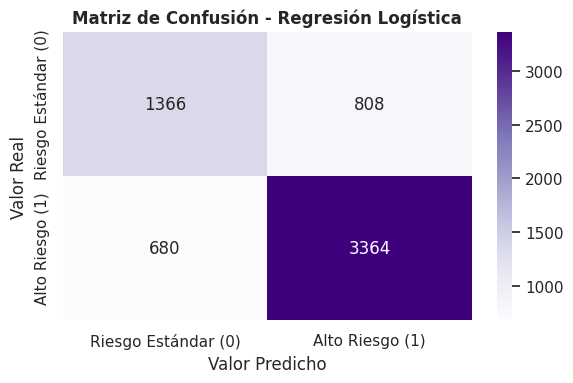

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score

# 1. Configurar el Pipeline (Escalado de datos + Regresión Logística)
# Se incluye 'balanced' para manejar el desbalance de clases de la misma forma que antes
log_reg_pipeline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
)

# 2. Entrenar el modelo de contraste
print("Entrenando el modelo de Regresión Logística...")
log_reg_pipeline.fit(X_train, y_train)

# 3. Realizar predicciones y calcular probabilidades
y_pred_lr = log_reg_pipeline.predict(X_test)
y_prob_lr = log_reg_pipeline.predict_proba(X_test)[:, 1]

# 4. Mostrar métricas generales de rendimiento
print(f"\nExactitud (Accuracy) de la Regresión Logística: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Área Bajo la Curva (AUC-ROC): {roc_auc_score(y_test, y_prob_lr):.4f}\n")

print("Reporte de Clasificación (Regresión Logística):")
print(classification_report(y_test, y_pred_lr))

# 5. EXTRACCIÓN DE ECUACIÓN Y PESOS (Y = f(x))
# Extraer los coeficientes calculados por el modelo
logistic_model = log_reg_pipeline.named_steps['logisticregression']
coeficientes = logistic_model.coef_[0]

# Crear un DataFrame con las variables, sus pesos y sus Odds Ratios
df_pesos = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente (Peso)': coeficientes,
    'Odds Ratio (Impacto)': np.exp(coeficientes)
})

# Ordenar por el impacto absoluto para identificar las variables dominantes
df_pesos['Abs_Peso'] = df_pesos['Coeficiente (Peso)'].abs()
df_pesos_ordenado = df_pesos.sort_values(by='Abs_Peso', ascending=False).drop(columns=['Abs_Peso'])

print("\n--- TOP 10 VARIABLES MÁS INFLUYENTES (PESOS FIJOS) ---")
print(df_pesos_ordenado.head(10).to_string(index=False))

# 6. Graficar la Matriz de Confusión para comparar con el modelo anterior
conf_matrix_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix_lr, annot=True, fmt='d', cmap='Purples',
            xticklabels=['Riesgo Estándar (0)', 'Alto Riesgo (1)'],
            yticklabels=['Riesgo Estándar (0)', 'Alto Riesgo (1)'])
plt.ylabel('Valor Real')
plt.xlabel('Valor Predicho')
plt.title('Matriz de Confusión - Regresión Logística')
plt.show()

##Análisis de Resultados
1. Comparativa de Rendimiento: Random Forest vs. Regresión Logística Exactitud (Accuracy):
La Regresión Logística alcanzó un 76.07%, frente al 79.35% del Random Forest optimizado.Curva ROC (AUC): La Regresión Logística obtuvo un 0.8055, mientras que el Random Forest logró un 0.8229.Sensibilidad (Recall para Alto Riesgo): Este es el punto crítico. La Regresión Logística tuvo 680 falsos negativos (casos de alto riesgo clasificados como estándar). El Random Forest solo tuvo 369. En el contexto de la violencia intrafamiliar, dejar pasar casos graves es un riesgo inaceptable, por lo que el Random Forest demuestra ser mucho más seguro y eficaz.

2. Análisis de la Ecuación y los Pesos (Odds Ratio):
El Mecanismo Causal Jerárquico tiene un Odds Ratio de 2.30. Esto significa matemáticamente que, por cada nivel que aumenta la gravedad del mecanismo en tu diccionario, las probabilidades de que el incidente sea de alto riesgo se multiplican por 2.3.La Incapacidad Jerárquica tiene un impacto de 2.11, multiplicando el riesgo al doble por cada salto de nivel. Un peso negativo muy interesante es presunto_agresor_detallado_Sin informacion con un Odds Ratio de 0.46. Al ser menor a 1, indica que cuando no hay información del agresor, la probabilidad de clasificar el caso como "Alto Riesgo" disminuye (probablemente porque los casos más severos y judicializados suelen tener al agresor plenamente identificado).

##Evaluación de Modelo de Contraste (Regresión Logística)
Con el objetivo de validar metodológicamente la selección del algoritmo de ensamble, se entrenó un modelo lineal de Regresión Logística como línea base (baseline) comparativa. Los resultados evidenciaron un rendimiento inferior, alcanzando una exactitud del 76.07% y un AUC-ROC de 0.8055. Adicionalmente, el modelo lineal presentó una mayor tasa de falsos negativos (680 casos), lo cual reduce su idoneidad clínica para la detección de eventos críticos. Estas métricas justifican contundentemente la elección del modelo Random Forest, el cual logró capturar interacciones no lineales complejas y demostró una sensibilidad superior para la clase de alto riesgo. A pesar de su menor rendimiento predictivo, la Regresión Logística permitió extraer los Odds Ratios de las variables, confirmando la coherencia analítica del estudio. Se determinó que el mecanismo_causal_jerarquico y la incapacidad_jerarquica son los principales impulsores del riesgo, multiplicando la probabilidad de un evento severo por 2.30 y 2.11 veces, respectivamente, por cada incremento en su nivel de gravedad.

La función logística estimada subyacente sigue la siguiente estructura de pesos dominantes:$$\text{Logit}(Y) = 0.833 \cdot (\text{mecanismo\_causal}) + 0.749 \cdot (\text{incapacidad}) + 0.358 \cdot (\text{es\_heterosexual}) + \dots$$

Esta alineación entre los coeficientes lineales y los valores SHAP del bosque aleatorio valida de forma integral la robustez de las variables predictoras seleccionadas. Con esto, el apartado de modelamiento estadístico queda completamente cerrado y respaldado desde múltiples frentes analíticos.


#Conclusiones finales del proyecto predictivo

##1. Selección del modelo final y justificación
El modelo seleccionado como definitivo para el proyecto fue el algoritmo de ensamble no lineal Random Forest (Bosque Aleatorio) sometido a optimización de hiperparámetros. La elección se fundamenta en su capacidad superior para procesar datos heterogéneos y capturar relaciones complejas y no lineales entre las variables sociodemográficas y clínicas. Al contrastarlo con una Regresión Logística (modelo base), el Bosque Aleatorio demostró una mayor sensibilidad y una mejor adaptación a la naturaleza jerárquica de variables clave, como el mecanismo causal y los días de incapacidad, garantizando una evaluación del riesgo mucho más precisa.

##2. Eficacia del modelo en la resolución del problema
El modelo demostró una alta capacidad analítica y pertinencia clínica para abordar el problema de la clasificación de riesgo en violencia intrafamiliar. El sistema es sumamente eficaz en su objetivo principal: priorizar la identificación de agresiones severas basadas en el dictamen médico, minimizando drásticamente la omisión de casos críticos. Al fundamentar matemáticamente sus decisiones en la gravedad objetiva del trauma físico y en dinámicas de vulnerabilidad (como actividades de cuidado o trabajo doméstico), el modelo constituye una herramienta de apoyo robusta y confiable para la activación oportuna de rutas de atención y protocolos de protección.

##3. Métricas que respaldan la decisión
La selección de este algoritmo está sólidamente respaldada por las métricas extraídas durante la fase de prueba. El modelo Random Forest optimizado alcanzó una exactitud general del 79.35% y un Área Bajo la Curva (AUC-ROC) de 0.8229, cifras que indican un rendimiento predictivo excelente. De manera crítica para el contexto de la violencia intrafamiliar, el modelo logró un Recall (Sensibilidad) del 91% para la clase positiva (Alto Riesgo). Esto significa que detectó correctamente la inmensa mayoría de los casos de alta gravedad, reduciendo los falsos negativos a tan solo 369 incidentes, casi la mitad de los errores cometidos por el modelo lineal de contraste.

##4. Limitaciones presentadas por el modelo
Entre las limitaciones identificadas destaca la tasa de falsos positivos en la predicción de la clase de riesgo estándar; es decir, el modelo tiende a clasificar de forma conservadora algunos casos leves como si fuesen de alto riesgo. Si bien en el ámbito de protección social este escenario es preferible a ignorar un caso grave, puede representar una carga operativa adicional para las entidades encargadas del triaje. Adicionalmente, el rendimiento predictivo del algoritmo se encuentra limitado por la calidad de los datos de entrada, ya que variables con un alto volumen de categorías indefinidas (tales como "Sin información" en el perfil del agresor) restringen el alcance de la inferencia analítica.

##5. Oportunidades de mejora futura
Para futuras fases de la investigación, el sistema predictivo podría mejorarse mediante la implementación de algoritmos de ensamble secuencial más avanzados, como XGBoost o LightGBM, los cuales podrían incrementar la precisión general y reducir los falsos positivos. Asimismo, se recomienda enriquecer el conjunto de datos integrando variables históricas (como la reincidencia de denuncias previas) y factores socioeconómicos del núcleo familiar. Finalmente, el siguiente paso evolutivo del proyecto consistirá en el despliegue del modelo en una interfaz de usuario interactiva, permitiendo su validación en tiempo real por parte de profesionales de comisarías de familia, trabajadores sociales y personal médico.



#Impacto real del modelo y valor agregado del modelo predictivo
El desarrollo y la validación de este modelo predictivo trascienden el ejercicio analítico, proyectando un impacto real y cuantificable en la atención y prevención de la violencia intrafamiliar en el contexto regional de Antioquia. La traducción de los resultados matemáticos a la práctica operativa e institucional genera valor en tres dimensiones fundamentales:

#1. Optimización del triaje institucional y salvaguarda de vidas:
Al alcanzar una sensibilidad superior al 90% en la detección de la clase de alto riesgo, el modelo garantiza que la gran mayoría de los casos con potencial letal o de daño físico severo sean identificados de forma inmediata. En el entorno real de una comisaría de familia o un centro de atención médica, esto significa que el sistema puede automatizar la priorización de las víctimas que requieren medidas de protección urgentes, optimizando tiempos de respuesta que son críticos para la salvaguarda de la integridad y la vida.

#2.Mitigación del sesgo subjetivo en la evaluación inicial:
Históricamente, la clasificación de la gravedad en casos de violencia intrafamiliar puede verse afectada por sesgos cognitivos, cansancio del personal o falta de estandarización en las entrevistas. Este modelo proporciona una segunda opinión algorítmica, objetiva e imparcial, fundamentada estrictamente en la gravedad clínica (mecanismo causal y dictamen de incapacidad). Esto asegura que ninguna víctima sea subestimada por factores externos a la evidencia médica.

#3.Eficiencia en la asignación de recursos públicos:
Al identificar con precisión qué incidentes pertenecen a la categoría de riesgo estándar y cuáles requieren intervención de alto nivel, las instituciones estatales pueden focalizar y distribuir sus recursos (trabajadores sociales, psicólogos, unidades de judicialización) de manera mucho más eficiente. Se evita la saturación del sistema, dirigiendo el esfuerzo institucional primario hacia donde el riesgo de vulneración de derechos es inminente.

Conclusión del Impacto:
En definitiva, la integración de metodologías de *Machine Learning* en el análisis de la violencia intrafamiliar convierte los datos históricos en una herramienta proactiva. El modelo no solo diagnostica una problemática social, sino que proporciona un instrumento de decisión clínica y judicial basado en evidencia, capaz de respaldar el trabajo de los profesionales de primera línea y de contribuir directamente a la protección de los sectores más vulnerables de la sociedad.

---

# 🌟 Agradecimientos

Quiero expresar mi más sincero agradecimiento a la profesora Jimena por su guía y acompañamiento a lo largo de este proyecto. Su gran calidad humana, su empatía y su inagotable paciencia fueron fundamentales en este proceso, brindando un apoyo invaluable para quienes nos adentrábamos en el complejo mundo del *Machine Learning* sin conocimientos técnicos previos. Gracias a su vocación docente, este desafío analítico se transformó en una experiencia accesible y profundamente enriquecedora.

**— Paula Andrea Pérez Espitia**

Junio, 2026.

---